<a href="https://colab.research.google.com/github/sethkipsangmutuba/Computer-Graphics-Animation/blob/main/A2_COMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mathematical Foundations for Computer Graphics

##Seth Kipsang

Computer graphics uses mathematical principles to represent, manipulate and analyse geometric objects accurately. These foundations support modelling, transformations, interpolation, rasterisation and rendering. Essential concepts include geometric representations, mathematical notation and barycentric coordinates.

For a triangle with vertices $A$, $B$ and $C$, a point $P$ is expressed as:

$$
P=\lambda_1A+\lambda_2B+\lambda_3C
$$

Subject to:

$$
\lambda_1+\lambda_2+\lambda_3=1
$$

Here, $\lambda_1$, $\lambda_2$ and $\lambda_3$ are barycentric weights representing the relative contributions of the three vertices. The equation means that point $P$ is formed by combining vertices $A$, $B$ and $C$ according to their respective weights.

These coordinates support interpolation of colours, textures and geometric attributes across triangular surfaces.

The mathematical foundation prioritises geometric interpretation, analytical reasoning and computational accuracy, preparing for advanced linear algebra and transformation matrices.

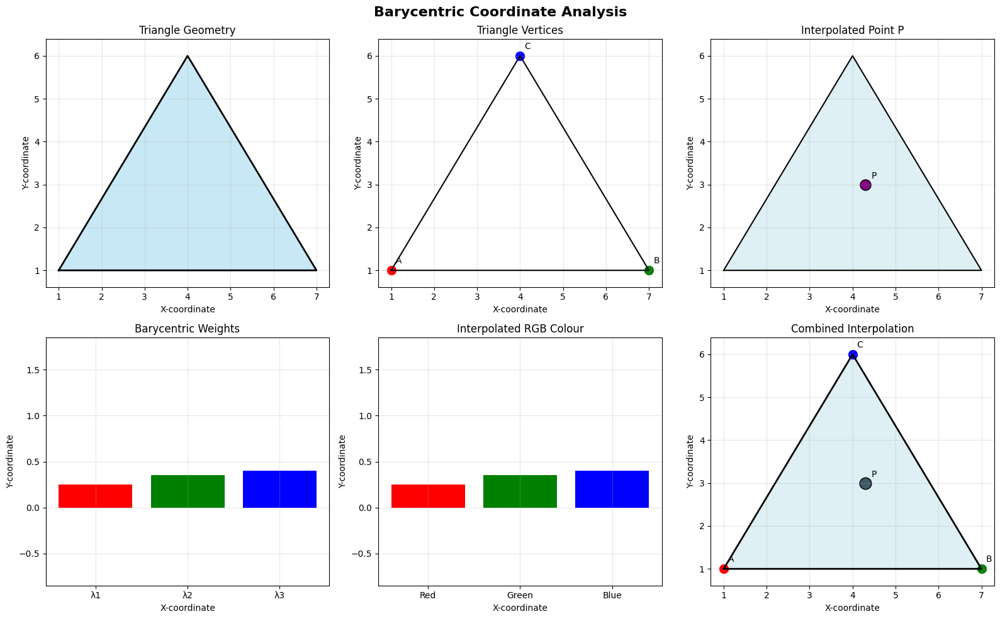

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Triangle vertices
A = np.array([1.0, 1.0])
B = np.array([7.0, 1.0])
C = np.array([4.0, 6.0])

triangle = np.array([A, B, C, A])

# 2. Barycentric coordinates
lambda1 = 0.25
lambda2 = 0.35
lambda3 = 0.40

assert np.isclose(lambda1 + lambda2 + lambda3, 1.0)

# 3. Interpolated point
P = lambda1 * A + lambda2 * B + lambda3 * C

# 4. Vertex colours
colour_A = np.array([1.0, 0.0, 0.0])
colour_B = np.array([0.0, 1.0, 0.0])
colour_C = np.array([0.0, 0.0, 1.0])

# 5. Interpolated RGB colour
colour_P = (
    lambda1 * colour_A +
    lambda2 * colour_B +
    lambda3 * colour_C
)

# 6. Create six subplots: three per row
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Subplot 1: Triangle geometry
axes[0].fill(
    [A[0], B[0], C[0]],
    [A[1], B[1], C[1]],
    color="skyblue",
    alpha=0.45
)
axes[0].plot(triangle[:, 0], triangle[:, 1], "k-", linewidth=2)
axes[0].set_title("Triangle Geometry")

# Subplot 2: Triangle vertices
for vertex, label, color in [
    (A, "A", "red"),
    (B, "B", "green"),
    (C, "C", "blue")
]:
    axes[1].scatter(*vertex, color=color, s=100)
    axes[1].annotate(label, vertex, xytext=(5, 8),
                     textcoords="offset points")

axes[1].plot(triangle[:, 0], triangle[:, 1], "k-")
axes[1].set_title("Triangle Vertices")

# Subplot 3: Interpolated point
axes[2].fill(
    [A[0], B[0], C[0]],
    [A[1], B[1], C[1]],
    color="lightblue",
    alpha=0.4
)
axes[2].plot(triangle[:, 0], triangle[:, 1], "k-")
axes[2].scatter(*P, color="purple", edgecolors="black", s=150)
axes[2].annotate("P", P, xytext=(7, 7),
                 textcoords="offset points")
axes[2].set_title("Interpolated Point P")

# Subplot 4: Barycentric weights
axes[3].bar(
    ["λ1", "λ2", "λ3"],
    [lambda1, lambda2, lambda3],
    color=["red", "green", "blue"]
)
axes[3].set_ylim(0, 1)
axes[3].set_title("Barycentric Weights")

# Subplot 5: Interpolated RGB colour
axes[4].bar(
    ["Red", "Green", "Blue"],
    colour_P,
    color=["red", "green", "blue"]
)
axes[4].set_ylim(0, 1)
axes[4].set_title("Interpolated RGB Colour")

# Subplot 6: Combined geometry and interpolation
axes[5].fill(
    [A[0], B[0], C[0]],
    [A[1], B[1], C[1]],
    color="lightblue",
    alpha=0.4
)
axes[5].plot(triangle[:, 0], triangle[:, 1], "k-", linewidth=2)

for vertex, label, color in [
    (A, "A", "red"),
    (B, "B", "green"),
    (C, "C", "blue")
]:
    axes[5].scatter(*vertex, color=color, s=100)
    axes[5].annotate(label, vertex, xytext=(5, 8),
                     textcoords="offset points")

axes[5].scatter(*P, color=colour_P, edgecolors="black", s=180)
axes[5].annotate("P", P, xytext=(7, 7),
                 textcoords="offset points")
axes[5].set_title("Combined Interpolation")

# 7. Format all subplots
for ax in axes:
    ax.set_xlabel("X-coordinate")
    ax.set_ylabel("Y-coordinate")
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal", adjustable="datalim")

fig.suptitle(
    "Barycentric Coordinate Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


## 2.1 Sets and Mappings

Sets and mappings are fundamental mathematical structures in quantitative computer graphics. They provide a formal framework for representing geometric objects, defining coordinate spaces and describing relationships between computational data. A **set** is a well-defined collection of distinct mathematical elements, while a **mapping** or function establishes a rule associating elements of one set with elements of another.

The membership relationship is expressed as:

$$
a \in A
$$

indicating that element $a$ belongs to set $A$. Given two sets $A$ and $B$, their Cartesian product is defined as:

$$
A \times B = \{(a,b):a\in A,\ b\in B\}
$$

This operation generates ordered pairs and provides the mathematical basis for constructing multidimensional coordinate spaces. For example, $\mathbb{R}^2$ represents two-dimensional Cartesian space, whereas $\mathbb{R}^3$ represents three-dimensional space.

Important mathematical sets include:

- $\mathbb{R}$: Set of real numbers.
- $\mathbb{R}^{+}$: Set of nonnegative real numbers.
- $\mathbb{Z}$: Set of integers.
- $\mathbb{R}^{n}$: $n$-dimensional real coordinate space.
- $S^2$: Unit sphere in three-dimensional space, defined by:

$$
x^2+y^2+z^2=1
$$

A function is represented by:

$$
f:A\rightarrow B
$$

Here, $A$ is the domain, $B$ is the target set, and $f(a)$ denotes the output associated with input $a$. The range comprises all actual outputs within $B$.

Functions exhibit three important properties. An **injective function** maps distinct inputs to distinct outputs. A **surjective function** reaches every element of its target set. A **bijective function** satisfies both conditions and therefore possesses an inverse, denoted by $f^{-1}$.

**Application in Computer Graphics:** Sets and mappings describe geometric coordinates, object transformations, surface representations and spatial-to-image relationships. They establish the mathematical foundation for modelling, projection, rendering and computational geometry.

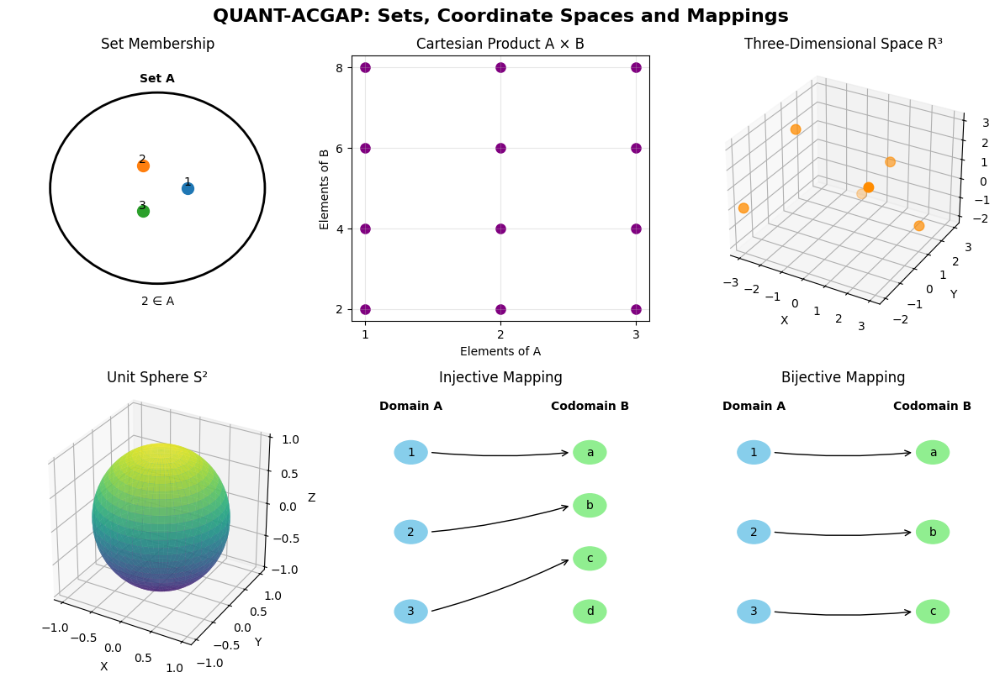

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from mpl_toolkits.mplot3d import Axes3D

# 1. Define mathematical sets
A = {1, 2, 3}
B = {2, 4, 6, 8}
Z = np.arange(-5, 6)
R = np.linspace(-5, 5, 200)

# 2. Cartesian product A × B
cartesian_product = np.array([(a, b) for a in A for b in B])

# 3. Three-dimensional coordinate space R³
x3 = np.array([1, 2, 3, -1, -2, -3])
y3 = np.array([2, -1, 1, 3, 0, -2])
z3 = np.array([1, 2, -1, -2, 3, 0])

# 4. Unit sphere S²
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 60)

X = np.outer(np.cos(u), np.sin(v))
Y = np.outer(np.sin(u), np.sin(v))
Z_sphere = np.outer(np.ones_like(u), np.cos(v))

# 5. Create mapping visualisation function
def draw_mapping(ax, domain, codomain, mapping, title):
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 5)
    ax.axis("off")

    ax.text(0.8, 4.6, "Domain A", ha="center", fontweight="bold")
    ax.text(3.2, 4.6, "Codomain B", ha="center", fontweight="bold")

    domain_positions = np.linspace(3.8, 0.8, len(domain))
    codomain_positions = np.linspace(3.8, 0.8, len(codomain))

    domain_coordinates = {}
    codomain_coordinates = {}

    for value, y in zip(domain, domain_positions):
        domain_coordinates[value] = y
        ax.add_patch(Circle((0.8, y), 0.22, color="skyblue"))
        ax.text(0.8, y, str(value), ha="center", va="center")

    for value, y in zip(codomain, codomain_positions):
        codomain_coordinates[value] = y
        ax.add_patch(Circle((3.2, y), 0.22, color="lightgreen"))
        ax.text(3.2, y, str(value), ha="center", va="center")

    for source, target in mapping.items():
        arrow = FancyArrowPatch(
            (1.05, domain_coordinates[source]),
            (2.95, codomain_coordinates[target]),
            arrowstyle="->",
            mutation_scale=12,
            color="black",
            connectionstyle="arc3,rad=0.05"
        )
        ax.add_patch(arrow)

    ax.set_title(title)


# 6. Create six visualisation panels
fig = plt.figure(figsize=(12, 8))
axes = [
    fig.add_subplot(2, 3, 1),
    fig.add_subplot(2, 3, 2),
    fig.add_subplot(2, 3, 3, projection="3d"),
    fig.add_subplot(2, 3, 4, projection="3d"),
    fig.add_subplot(2, 3, 5),
    fig.add_subplot(2, 3, 6)
]

# Subplot 1: Set membership
axes[0].set_xlim(0, 5)
axes[0].set_ylim(0, 5)
axes[0].add_patch(Circle((2.5, 2.5), 1.8,
                         fill=False, linewidth=2))
axes[0].text(2.5, 4.5, "Set A", ha="center", fontweight="bold")

for i, value in enumerate(A):
    axes[0].scatter(2.5 + 0.5 * np.cos(i * 2 * np.pi / 3),
                    2.5 + 0.5 * np.sin(i * 2 * np.pi / 3),
                    s=100)
    axes[0].text(2.5 + 0.5 * np.cos(i * 2 * np.pi / 3),
                 2.5 + 0.5 * np.sin(i * 2 * np.pi / 3),
                 str(value), ha="center", va="bottom")

axes[0].text(2.5, 0.3, "2 ∈ A", ha="center")
axes[0].set_title("Set Membership")
axes[0].axis("off")

# Subplot 2: Cartesian product A × B
axes[1].scatter(cartesian_product[:, 0],
                cartesian_product[:, 1],
                color="purple", s=65)
axes[1].set_xlabel("Elements of A")
axes[1].set_ylabel("Elements of B")
axes[1].set_xticks(sorted(A))
axes[1].set_yticks(sorted(B))
axes[1].grid(True, alpha=0.3)
axes[1].set_title("Cartesian Product A × B")

# Subplot 3: Three-dimensional coordinate space R³
axes[2].scatter(x3, y3, z3, s=70, color="darkorange")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
axes[2].set_zlabel("Z")
axes[2].set_title("Three-Dimensional Space R³")

# Subplot 4: Unit sphere S²
axes[3].plot_surface(
    X, Y, Z_sphere,
    cmap="viridis",
    alpha=0.75,
    edgecolor="none"
)
axes[3].set_xlabel("X")
axes[3].set_ylabel("Y")
axes[3].set_zlabel("Z")
axes[3].set_box_aspect((1, 1, 1))
axes[3].set_title("Unit Sphere S²")

# Subplot 5: Injective mapping
draw_mapping(
    axes[4],
    [1, 2, 3],
    ["a", "b", "c", "d"],
    {1: "a", 2: "b", 3: "c"},
    "Injective Mapping"
)

# Subplot 6: Bijective mapping
draw_mapping(
    axes[5],
    [1, 2, 3],
    ["a", "b", "c"],
    {1: "a", 2: "b", 3: "c"},
    "Bijective Mapping"
)

# 7. Overall formatting
fig.suptitle(
    "QUANT-ACGAP: Sets, Coordinate Spaces and Mappings",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

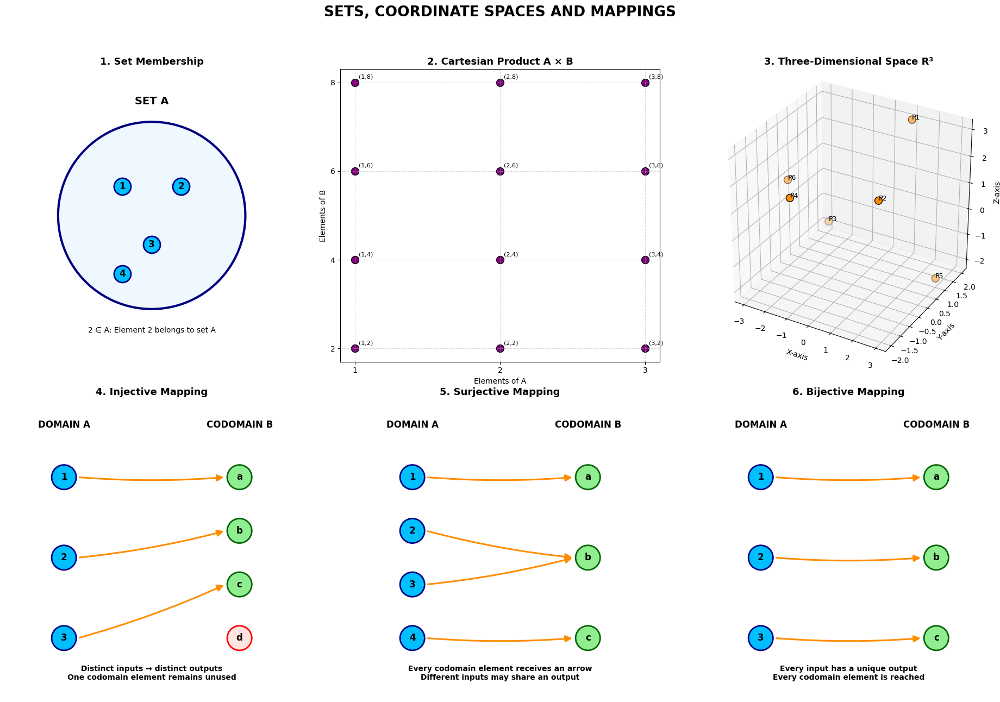

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

# ============================================================
# 1. SETS AND CARTESIAN PRODUCT
# ============================================================

A = {1, 2, 3}
B = {2, 4, 6, 8}

cartesian_product = np.array([
    (a, b) for a in sorted(A) for b in sorted(B)
])

# ============================================================
# 2. THREE-DIMENSIONAL COORDINATE SPACE R³
# ============================================================

points = np.array([
    [1, 2, 3],
    [2, -1, 2],
    [-2, 1, -1],
    [-1, -2, 2],
    [3, 1, -2],
    [-3, 0, 1]
])

# ============================================================
# 3. UNIT SPHERE S²
# ============================================================

u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 60)

X = np.outer(np.cos(u), np.sin(v))
Y = np.outer(np.sin(u), np.sin(v))
Z = np.outer(np.ones_like(u), np.cos(v))

# ============================================================
# 4. MAPPING DIAGRAM FUNCTION
# ============================================================

def draw_mapping(ax, domain, codomain, mapping, title, subtitle):

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.set_aspect("equal")
    ax.axis("off")

    # Column headings
    ax.text(2, 9.2, "DOMAIN A", ha="center",
            fontsize=12, fontweight="bold")

    ax.text(8, 9.2, "CODOMAIN B", ha="center",
            fontsize=12, fontweight="bold")

    # Element positions
    domain_y = np.linspace(7.5, 2.0, len(domain))
    codomain_y = np.linspace(7.5, 2.0, len(codomain))

    source_positions = dict(zip(domain, domain_y))
    target_positions = dict(zip(codomain, codomain_y))

    # Draw domain elements
    for value, y in source_positions.items():
        ax.add_patch(Circle(
            (2, y), 0.42,
            facecolor="deepskyblue",
            edgecolor="navy",
            linewidth=2,
            zorder=3
        ))

        ax.text(2, y, str(value),
                ha="center", va="center",
                fontsize=12, fontweight="bold")

    # Draw codomain elements
    used_targets = set(mapping.values())

    for value, y in target_positions.items():

        color = "lightgreen" if value in used_targets else "mistyrose"
        edge = "darkgreen" if value in used_targets else "red"

        ax.add_patch(Circle(
            (8, y), 0.42,
            facecolor=color,
            edgecolor=edge,
            linewidth=2,
            zorder=3
        ))

        ax.text(8, y, str(value),
                ha="center", va="center",
                fontsize=12, fontweight="bold")

    # Draw mapping arrows
    for source, target in mapping.items():

        y1 = source_positions[source]
        y2 = target_positions[target]

        ax.add_patch(FancyArrowPatch(
            (2.48, y1),
            (7.52, y2),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2.2,
            color="darkorange",
            connectionstyle="arc3,rad=0.04",
            zorder=2
        ))

    # Explanation
    ax.text(5, 0.8, subtitle,
            ha="center", va="center",
            fontsize=10, fontweight="bold",
            wrap=True)

    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)


# ============================================================
# 5. CREATE SIX VISUALISATIONS
# ============================================================

fig = plt.figure(figsize=(19, 13))

# ------------------------------------------------------------
# Panel 1: Set membership
# ------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

ax1.set_xlim(0, 10)
ax1.set_ylim(0, 10)
ax1.set_aspect("equal")
ax1.axis("off")

ax1.add_patch(Circle(
    (5, 5), 3.2,
    facecolor="aliceblue",
    edgecolor="navy",
    linewidth=3
))

ax1.text(5, 8.8, "SET A",
         ha="center", fontsize=14, fontweight="bold")

positions = [(4, 6), (6, 6), (5, 4), (4, 3)]

for value, (x, y) in zip([1, 2, 3, 4], positions):
    ax1.scatter(x, y, s=500, color="deepskyblue",
                edgecolors="navy", linewidths=2, zorder=3)
    ax1.text(x, y, str(value),
             ha="center", va="center",
             fontsize=12, fontweight="bold")

ax1.text(5, 1, "2 ∈ A: Element 2 belongs to set A",
         ha="center", fontsize=10)

ax1.set_title("1. Set Membership",
              fontsize=13, fontweight="bold")

# ------------------------------------------------------------
# Panel 2: Cartesian product A × B
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

ax2.scatter(
    cartesian_product[:, 0],
    cartesian_product[:, 1],
    s=100,
    color="purple",
    edgecolors="black"
)

for a, b in cartesian_product:
    ax2.annotate(
        f"({a},{b})",
        (a, b),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax2.set_xlabel("Elements of A")
ax2.set_ylabel("Elements of B")
ax2.set_xticks(sorted(A))
ax2.set_yticks(sorted(B))
ax2.grid(True, linestyle="--", alpha=0.5)

ax2.set_title("2. Cartesian Product A × B",
              fontsize=13, fontweight="bold")

# ------------------------------------------------------------
# Panel 3: Three-dimensional coordinate space R³
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3, projection="3d")

ax3.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    s=100,
    color="darkorange",
    edgecolors="black"
)

for i, point in enumerate(points):
    ax3.text(
        point[0], point[1], point[2],
        f"P{i+1}",
        fontsize=9
    )

ax3.set_xlabel("X-axis")
ax3.set_ylabel("Y-axis")
ax3.set_zlabel("Z-axis")
ax3.set_title("3. Three-Dimensional Space R³",
              fontsize=13, fontweight="bold")

ax3.set_box_aspect((1, 1, 1))

# ------------------------------------------------------------
# Panel 4: Injective mapping
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

draw_mapping(
    ax4,
    domain=[1, 2, 3],
    codomain=["a", "b", "c", "d"],
    mapping={
        1: "a",
        2: "b",
        3: "c"
    },
    title="4. Injective Mapping",
    subtitle="Distinct inputs → distinct outputs\nOne codomain element remains unused"
)

# ------------------------------------------------------------
# Panel 5: Surjective mapping
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

draw_mapping(
    ax5,
    domain=[1, 2, 3, 4],
    codomain=["a", "b", "c"],
    mapping={
        1: "a",
        2: "b",
        3: "b",
        4: "c"
    },
    title="5. Surjective Mapping",
    subtitle="Every codomain element receives an arrow\nDifferent inputs may share an output"
)

# ------------------------------------------------------------
# Panel 6: Bijective mapping
# ------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6)

draw_mapping(
    ax6,
    domain=[1, 2, 3],
    codomain=["a", "b", "c"],
    mapping={
        1: "a",
        2: "b",
        3: "c"
    },
    title="6. Bijective Mapping",
    subtitle="Every input has a unique output\nEvery codomain element is reached"
)

# ============================================================
# 6. FINAL PRESENTATION
# ============================================================

fig.suptitle(
    "SETS, COORDINATE SPACES AND MAPPINGS",
    fontsize=19,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 2.1.1 Inverse Mappings

An inverse mapping reverses the relationship established by a mathematical function. Given $f:A\rightarrow B$, its inverse is $f^{-1}:B\rightarrow A$, satisfying:

$$
f^{-1}(b)=a\iff f(a)=b
$$

An inverse exists precisely when $f$ is **bijective**, meaning it is both injective (one-to-one) and surjective (onto). The inverse identities are:

$$
f^{-1}(f(x))=x,\qquad f(f^{-1}(y))=y
$$

**Example 1: Bijective Function**

Consider $f:\mathbb{R}\rightarrow\mathbb{R}$, where:

$$
f(x)=x^3
$$

Let $y=x^3$. Solving for $x$ gives $x=\sqrt[3]{y}$. Therefore:

$$
f^{-1}(x)=\sqrt[3]{x}
$$

**Example 2: Restricted Domain**

Consider $f(x)=x^2$, with domain and codomain $\mathbb{R}$. Since $f(2)=f(-2)=4$, it is not injective. Negative outputs are also unattainable, making it non-surjective. Restricting both sets to $[0,\infty)$ produces:

$$
f^{-1}(x)=\sqrt{x}
$$

**Graphics Applications:** Inverse mappings support reversing transformations, coordinate conversion, screen-to-world reconstruction, animation and accurate geometric modelling.

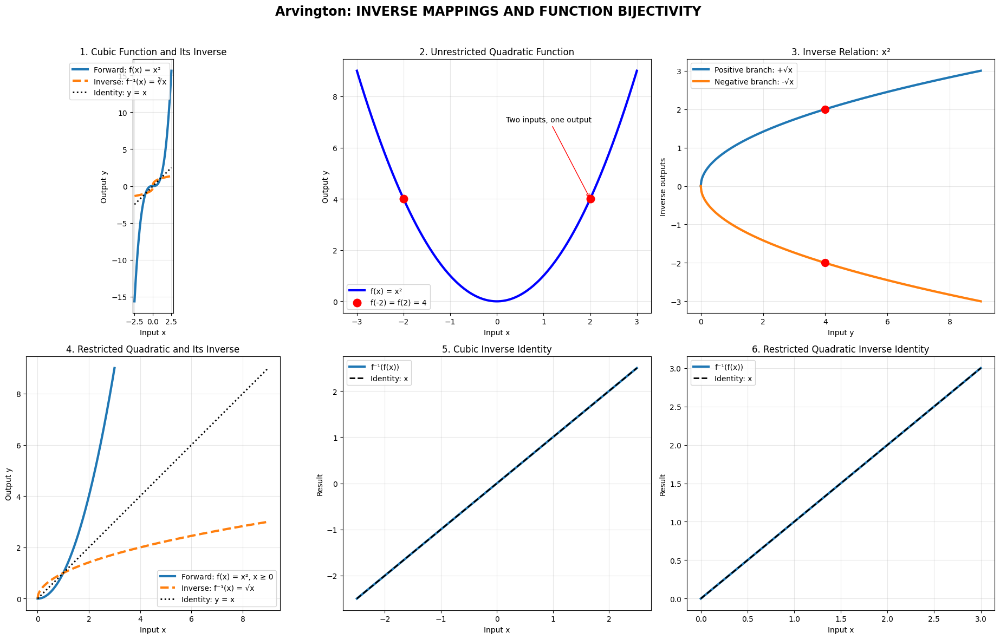

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. DEFINE FUNCTIONS AND THEIR INVERSES
# ============================================================

# Bijective cubic function
def f_cubic(x):
    return x**3

def inverse_cubic(y):
    return np.cbrt(y)

# Quadratic function
def f_square(x):
    return x**2

# Inverse branches of unrestricted quadratic function
def inverse_square_positive(y):
    return np.sqrt(y)

def inverse_square_negative(y):
    return -np.sqrt(y)

# Restricted quadratic function: x >= 0
def inverse_square_restricted(y):
    return np.sqrt(y)


# ============================================================
# 2. GENERATE NUMERICAL DOMAINS
# ============================================================

x_cubic = np.linspace(-2.5, 2.5, 500)
y_cubic = np.linspace(-2.5, 2.5, 500)

x_square = np.linspace(-3, 3, 500)
x_restricted = np.linspace(0, 3, 500)

y_positive = np.linspace(0, 9, 500)


# ============================================================
# 3. CREATE SIX VISUALISATION PANELS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))
axes = axes.flatten()

# ============================================================
# PANEL 1: BIJECTIVE CUBIC FUNCTION AND ITS INVERSE
# ============================================================

axes[0].plot(
    x_cubic,
    f_cubic(x_cubic),
    linewidth=3,
    label="Forward: f(x) = x³"
)

axes[0].plot(
    y_cubic,
    inverse_cubic(y_cubic),
    "--",
    linewidth=3,
    label="Inverse: f⁻¹(x) = ∛x"
)

axes[0].plot(
    x_cubic,
    x_cubic,
    ":",
    color="black",
    linewidth=2,
    label="Identity: y = x"
)

axes[0].set_title("1. Cubic Function and Its Inverse")
axes[0].set_xlabel("Input x")
axes[0].set_ylabel("Output y")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect("equal", adjustable="box")


# ============================================================
# PANEL 2: UNRESTRICTED QUADRATIC FUNCTION
# ============================================================

axes[1].plot(
    x_square,
    f_square(x_square),
    linewidth=3,
    color="blue",
    label="f(x) = x²"
)

axes[1].scatter(
    [-2, 2],
    [4, 4],
    color="red",
    s=110,
    zorder=5,
    label="f(-2) = f(2) = 4"
)

axes[1].annotate(
    "Two inputs, one output",
    xy=(2, 4),
    xytext=(0.2, 7),
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=10
)

axes[1].set_title("2. Unrestricted Quadratic Function")
axes[1].set_xlabel("Input x")
axes[1].set_ylabel("Output y")
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# ============================================================
# PANEL 3: INVERSE RELATION OF UNRESTRICTED x²
# ============================================================

axes[2].plot(
    y_positive,
    inverse_square_positive(y_positive),
    linewidth=3,
    label="Positive branch: +√x"
)

axes[2].plot(
    y_positive,
    inverse_square_negative(y_positive),
    linewidth=3,
    label="Negative branch: -√x"
)

axes[2].scatter(
    [4, 4],
    [2, -2],
    color="red",
    s=100,
    zorder=5
)

axes[2].set_title("3. Inverse Relation: x²")
axes[2].set_xlabel("Input y")
axes[2].set_ylabel("Inverse outputs")
axes[2].legend()
axes[2].grid(True, alpha=0.3)


# ============================================================
# PANEL 4: RESTRICTED QUADRATIC FUNCTION AND ITS INVERSE
# ============================================================

axes[3].plot(
    x_restricted,
    f_square(x_restricted),
    linewidth=3,
    label="Forward: f(x) = x², x ≥ 0"
)

axes[3].plot(
    y_positive,
    inverse_square_restricted(y_positive),
    "--",
    linewidth=3,
    label="Inverse: f⁻¹(x) = √x"
)

axes[3].plot(
    [0, 9],
    [0, 9],
    ":",
    color="black",
    linewidth=2,
    label="Identity: y = x"
)

axes[3].set_title("4. Restricted Quadratic and Its Inverse")
axes[3].set_xlabel("Input x")
axes[3].set_ylabel("Output y")
axes[3].legend()
axes[3].grid(True, alpha=0.3)
axes[3].set_aspect("equal", adjustable="box")


# ============================================================
# PANEL 5: CUBIC FUNCTION COMPOSITION IDENTITIES
# ============================================================

composition_cubic_1 = inverse_cubic(f_cubic(x_cubic))
composition_cubic_2 = f_cubic(inverse_cubic(y_cubic))

axes[4].plot(
    x_cubic,
    composition_cubic_1,
    linewidth=3,
    label="f⁻¹(f(x))"
)

axes[4].plot(
    x_cubic,
    x_cubic,
    "--",
    color="black",
    linewidth=2,
    label="Identity: x"
)

axes[4].set_title("5. Cubic Inverse Identity")
axes[4].set_xlabel("Input x")
axes[4].set_ylabel("Result")
axes[4].legend()
axes[4].grid(True, alpha=0.3)


# ============================================================
# PANEL 6: RESTRICTED QUADRATIC COMPOSITION IDENTITIES
# ============================================================

composition_square_1 = inverse_square_restricted(
    f_square(x_restricted)
)

composition_square_2 = f_square(
    inverse_square_restricted(y_positive)
)

axes[5].plot(
    x_restricted,
    composition_square_1,
    linewidth=3,
    label="f⁻¹(f(x))"
)

axes[5].plot(
    x_restricted,
    x_restricted,
    "--",
    color="black",
    linewidth=2,
    label="Identity: x"
)

axes[5].set_title("6. Restricted Quadratic Inverse Identity")
axes[5].set_xlabel("Input x")
axes[5].set_ylabel("Result")
axes[5].legend()
axes[5].grid(True, alpha=0.3)


# ============================================================
# 4. FINAL PRESENTATION
# ============================================================

fig.suptitle(
    "Arvington: INVERSE MAPPINGS AND FUNCTION BIJECTIVITY",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 2.1.2 Intervals

An interval is a subset of real numbers defined by lower and upper bounds. It specifies the permissible range of values within a mathematical or computational domain.

Three principal types are:

- **Open interval:** $(a,b)$, mathematically expressed as:

$$
(a,b)=\{x\in\mathbb{R}:a<x<b\}
$$

This means *x is greater than a and less than b*, excluding both endpoints.

- **Closed interval:** $[a,b]$, expressed as:

$$
[a,b]=\{x\in\mathbb{R}:a\leq x\leq b\}
$$

This means *x lies between a and b, including both endpoints*.

- **Half-open interval:** $[a,b)$ includes a but excludes b.

In three-dimensional graphics, the unit cube is represented by:

$$
[0,1]^3=[0,1]\times[0,1]\times[0,1]
$$

This represents three-dimensional coordinates bounded between zero and one.

Set operations include intersection (common elements), union (combined elements) and difference (remaining elements):

$$
[3,5)\cap[4,6]=[4,5)
$$

$$
[3,5)\cup[4,6]=[3,6]
$$

$$
[3,5)\setminus[4,6]=[3,4)
$$

**Graphics Applications:** Intervals establish coordinate boundaries, geometric regions, animation time ranges and numerical domains, supporting modelling, collision detection and computational geometry.

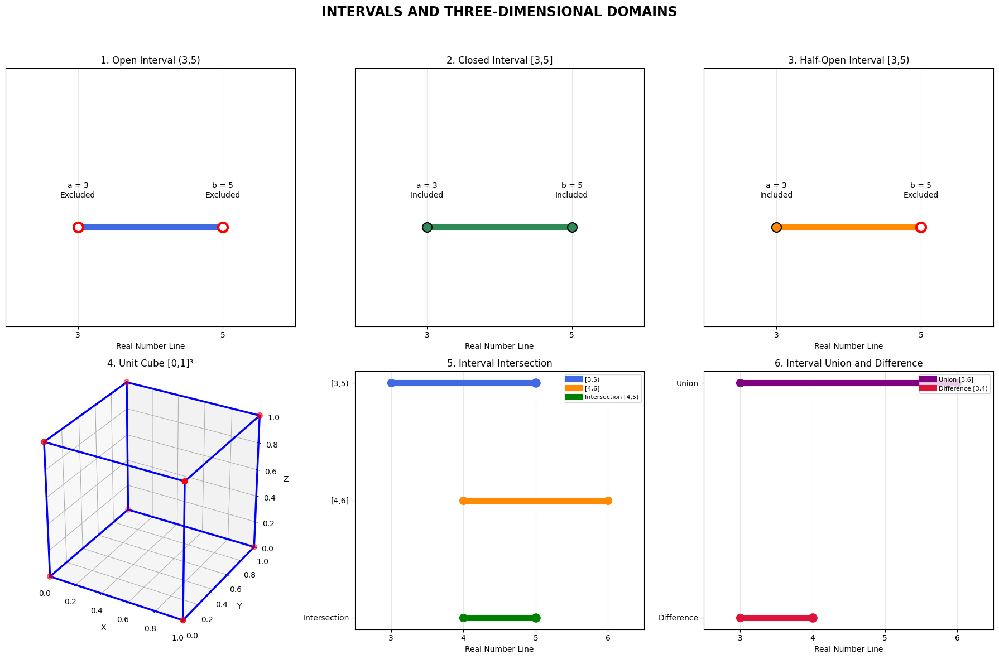

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# 1. DEFINE INTERVALS
# ============================================================

a, b = 3, 5
c, d = 4, 6

x = np.linspace(0, 8, 1000)

open_interval = (x > a) & (x < b)
closed_interval = (x >= a) & (x <= b)
half_open_interval = (x >= a) & (x < b)

# Set operations
intersection = (x >= 4) & (x < 5)
union = (x >= 3) & (x <= 6)
difference = (x >= 3) & (x < 4)

# ============================================================
# 2. CREATE SIX SUBPLOTS
# ============================================================

fig = plt.figure(figsize=(18, 12))

# ============================================================
# PANEL 1: OPEN INTERVAL (a,b)
# ============================================================

ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(x[open_interval], np.zeros(np.sum(open_interval)),
         linewidth=8, color="royalblue")

ax1.scatter([3, 5], [0, 0], s=150,
            facecolors="white", edgecolors="red",
            linewidths=3, zorder=5)

ax1.text(3, 0.15, "a = 3\nExcluded", ha="center")
ax1.text(5, 0.15, "b = 5\nExcluded", ha="center")

ax1.set_xlim(2, 6)
ax1.set_ylim(-0.5, 0.8)
ax1.set_yticks([])
ax1.set_xticks([3, 5])
ax1.set_title("1. Open Interval (3,5)")
ax1.set_xlabel("Real Number Line")
ax1.grid(axis="x", alpha=0.3)

# ============================================================
# PANEL 2: CLOSED INTERVAL [a,b]
# ============================================================

ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(x[closed_interval], np.zeros(np.sum(closed_interval)),
         linewidth=8, color="seagreen")

ax2.scatter([3, 5], [0, 0], s=150,
            color="seagreen", edgecolors="black",
            linewidths=1.5, zorder=5)

ax2.text(3, 0.15, "a = 3\nIncluded", ha="center")
ax2.text(5, 0.15, "b = 5\nIncluded", ha="center")

ax2.set_xlim(2, 6)
ax2.set_ylim(-0.5, 0.8)
ax2.set_yticks([])
ax2.set_xticks([3, 5])
ax2.set_title("2. Closed Interval [3,5]")
ax2.set_xlabel("Real Number Line")
ax2.grid(axis="x", alpha=0.3)

# ============================================================
# PANEL 3: HALF-OPEN INTERVAL [a,b)
# ============================================================

ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(x[half_open_interval],
         np.zeros(np.sum(half_open_interval)),
         linewidth=8, color="darkorange")

ax3.scatter([3], [0], s=150, color="darkorange",
            edgecolors="black", linewidths=1.5, zorder=5)

ax3.scatter([5], [0], s=150, facecolors="white",
            edgecolors="red", linewidths=3, zorder=5)

ax3.text(3, 0.15, "a = 3\nIncluded", ha="center")
ax3.text(5, 0.15, "b = 5\nExcluded", ha="center")

ax3.set_xlim(2, 6)
ax3.set_ylim(-0.5, 0.8)
ax3.set_yticks([])
ax3.set_xticks([3, 5])
ax3.set_title("3. Half-Open Interval [3,5)")
ax3.set_xlabel("Real Number Line")
ax3.grid(axis="x", alpha=0.3)

# ============================================================
# PANEL 4: THREE-DIMENSIONAL UNIT CUBE [0,1]³
# ============================================================

ax4 = fig.add_subplot(2, 3, 4, projection="3d")

vertices = np.array([
    [0, 0, 0], [1, 0, 0],
    [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1],
    [1, 1, 1], [0, 1, 1]
])

edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7)
]

for i, j in edges:
    ax4.plot(
        vertices[[i, j], 0],
        vertices[[i, j], 1],
        vertices[[i, j], 2],
        color="blue",
        linewidth=2.5
    )

ax4.scatter(
    vertices[:, 0],
    vertices[:, 1],
    vertices[:, 2],
    color="red",
    s=50
)

ax4.set_xlim(0, 1)
ax4.set_ylim(0, 1)
ax4.set_zlim(0, 1)
ax4.set_xlabel("X")
ax4.set_ylabel("Y")
ax4.set_zlabel("Z")
ax4.set_box_aspect((1, 1, 1))
ax4.set_title("4. Unit Cube [0,1]³")

# ============================================================
# PANEL 5: INTERSECTION AND UNION
# ============================================================

ax5 = fig.add_subplot(2, 3, 5)

ax5.plot([3, 5], [2, 2], linewidth=8,
         color="royalblue", label="[3,5)")

ax5.scatter([3], [2], s=100, color="royalblue")
ax5.scatter([5], [2], s=100, facecolors="white",
            edgecolors="royalblue", linewidths=2)

ax5.plot([4, 6], [1, 1], linewidth=8,
         color="darkorange", label="[4,6]")

ax5.scatter([4, 6], [1, 1], s=100, color="darkorange")

ax5.plot([4, 5], [0, 0], linewidth=8,
         color="green", label="Intersection [4,5)")

ax5.scatter([4], [0], s=100, color="green")
ax5.scatter([5], [0], s=100, facecolors="white",
            edgecolors="green", linewidths=2)

ax5.set_yticks([0, 1, 2])
ax5.set_yticklabels(["Intersection", "[4,6]", "[3,5)"])
ax5.set_xlim(2.5, 6.5)
ax5.set_xticks(range(3, 7))
ax5.set_title("5. Interval Intersection")
ax5.set_xlabel("Real Number Line")
ax5.grid(axis="x", alpha=0.3)
ax5.legend(loc="upper right", fontsize=8)

# ============================================================
# PANEL 6: UNION AND DIFFERENCE
# ============================================================

ax6 = fig.add_subplot(2, 3, 6)

# Union: [3,6]
ax6.plot([3, 6], [2, 2], linewidth=8,
         color="purple", label="Union [3,6]")

ax6.scatter([3, 6], [2, 2], s=100, color="purple")

# Difference: [3,4)
ax6.plot([3, 4], [1, 1], linewidth=8,
         color="crimson", label="Difference [3,4)")

ax6.scatter([3], [1], s=100, color="crimson")
ax6.scatter([4], [1], s=100, facecolors="white",
            edgecolors="crimson", linewidths=2)

ax6.set_yticks([1, 2])
ax6.set_yticklabels(["Difference", "Union"])
ax6.set_xlim(2.5, 6.5)
ax6.set_xticks(range(3, 7))
ax6.set_title("6. Interval Union and Difference")
ax6.set_xlabel("Real Number Line")
ax6.grid(axis="x", alpha=0.3)
ax6.legend(loc="upper right", fontsize=8)

# ============================================================
# 3. FINAL PRESENTATION
# ============================================================

fig.suptitle(
    "INTERVALS AND THREE-DIMENSIONAL DOMAINS",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 2.1.3 Logarithms

A logarithm is the inverse operation of exponentiation. It determines the power to which a positive base $a$ must be raised to produce a number $x$. Mathematically:

$$
y=\log_a x\iff a^y=x
$$

This is expressed as *y equals the logarithm of x to base a, meaning a raised to power y equals x*, where $a>0$, $a\neq1$ and $x>0$.

Fundamental logarithmic laws include:

**Product rule:**

$$
\log_a(xy)=\log_a x+\log_a y
$$

**Quotient rule:**

$$
\log_a\left(\frac{x}{y}\right)=\log_a x-\log_a y
$$

**Change-of-base rule:**

$$
\log_a x=\frac{\log_b x}{\log_b a}
$$

The natural logarithm uses Euler's constant:

$$
\ln x=\log_e x,\qquad e\approx2.71828
$$

Its important calculus relationships are:

$$
\frac{d}{dx}\ln x=\frac{1}{x},
\qquad
\frac{d}{dx}e^x=e^x
$$

Logarithms are also commonly expressed using base 2, $\log_2 x$, and base 10, $\log_{10}x$.

**Graphics Applications:** Logarithms support exponential modelling, algorithmic complexity analysis, numerical scaling, image intensity processing and computational optimisation. Their properties simplify mathematical expressions and help analyse rapidly changing quantities in graphics systems.

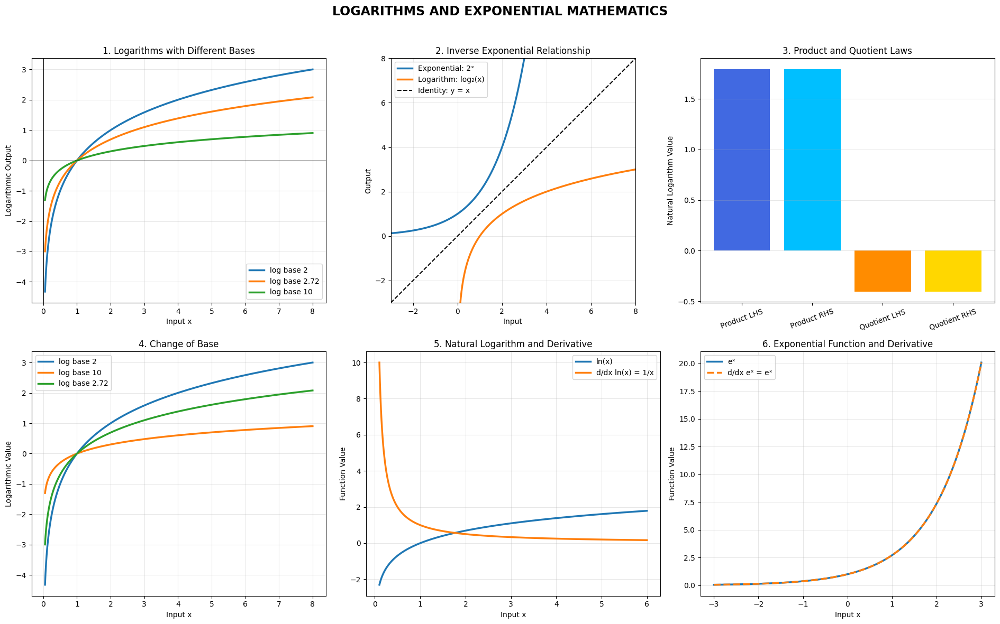

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. DEFINE LOGARITHMIC AND EXPONENTIAL FUNCTIONS
# ============================================================

x = np.linspace(0.05, 8, 500)
y = np.linspace(-3, 3, 500)

bases = [2, np.e, 10]

def logarithm(x, base):
    return np.log(x) / np.log(base)

def exponential(x, base):
    return base ** x


# ============================================================
# 2. LOGARITHMIC LAW EXAMPLES
# ============================================================

a, b = 2.0, 3.0
product = a * b
quotient = a / b

# ============================================================
# 3. NATURAL LOGARITHM AND DERIVATIVES
# ============================================================

x_positive = np.linspace(0.1, 6, 500)

ln_x = np.log(x_positive)
derivative_ln = 1 / x_positive

exp_x = np.exp(y)
derivative_exp = np.exp(y)


# ============================================================
# 4. CREATE SIX SUBPLOTS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))
axes = axes.flatten()

# ------------------------------------------------------------
# PANEL 1: LOGARITHMIC FUNCTIONS WITH DIFFERENT BASES
# ------------------------------------------------------------

for base in bases:
    axes[0].plot(
        x,
        logarithm(x, base),
        linewidth=2.5,
        label=f"log base {base:.3g}"
    )

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("1. Logarithms with Different Bases")
axes[0].set_xlabel("Input x")
axes[0].set_ylabel("Logarithmic Output")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 2: EXPONENTIAL AND LOGARITHMIC INVERSE RELATIONSHIP
# ------------------------------------------------------------

base = 2

axes[1].plot(
    y,
    exponential(y, base),
    linewidth=2.5,
    label="Exponential: 2ˣ"
)

axes[1].plot(
    x,
    logarithm(x, base),
    linewidth=2.5,
    label="Logarithm: log₂(x)"
)

axes[1].plot(
    [-3, 8],
    [-3, 8],
    "--",
    color="black",
    label="Identity: y = x"
)

axes[1].set_xlim(-3, 8)
axes[1].set_ylim(-3, 8)
axes[1].set_aspect("equal", adjustable="box")
axes[1].set_title("2. Inverse Exponential Relationship")
axes[1].set_xlabel("Input")
axes[1].set_ylabel("Output")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 3: PRODUCT AND QUOTIENT LAWS
# ------------------------------------------------------------

product_lhs = np.log(a * b)
product_rhs = np.log(a) + np.log(b)

quotient_lhs = np.log(a / b)
quotient_rhs = np.log(a) - np.log(b)

labels = [
    "Product LHS",
    "Product RHS",
    "Quotient LHS",
    "Quotient RHS"
]

values = [
    product_lhs,
    product_rhs,
    quotient_lhs,
    quotient_rhs
]

axes[2].bar(
    labels,
    values,
    color=["royalblue", "deepskyblue", "darkorange", "gold"]
)

axes[2].set_title("3. Product and Quotient Laws")
axes[2].set_ylabel("Natural Logarithm Value")
axes[2].tick_params(axis="x", rotation=20)
axes[2].grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# PANEL 4: CHANGE OF BASE
# ------------------------------------------------------------

bases_to_compare = [2, 10, np.e]
change_base_values = [
    logarithm(x, base) for base in bases_to_compare
]

for base, values in zip(bases_to_compare, change_base_values):
    axes[3].plot(
        x,
        values,
        linewidth=2.5,
        label=f"log base {base:.3g}"
    )

axes[3].set_title("4. Change of Base")
axes[3].set_xlabel("Input x")
axes[3].set_ylabel("Logarithmic Value")
axes[3].legend()
axes[3].grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 5: NATURAL LOGARITHM AND ITS DERIVATIVE
# ------------------------------------------------------------

axes[4].plot(
    x_positive,
    ln_x,
    linewidth=2.5,
    label="ln(x)"
)

axes[4].plot(
    x_positive,
    derivative_ln,
    linewidth=2.5,
    label="d/dx ln(x) = 1/x"
)

axes[4].set_title("5. Natural Logarithm and Derivative")
axes[4].set_xlabel("Input x")
axes[4].set_ylabel("Function Value")
axes[4].legend()
axes[4].grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 6: EXPONENTIAL FUNCTION AND ITS DERIVATIVE
# ------------------------------------------------------------

axes[5].plot(
    y,
    exp_x,
    linewidth=2.5,
    label="eˣ"
)

axes[5].plot(
    y,
    derivative_exp,
    "--",
    linewidth=2.5,
    label="d/dx eˣ = eˣ"
)

axes[5].set_title("6. Exponential Function and Derivative")
axes[5].set_xlabel("Input x")
axes[5].set_ylabel("Function Value")
axes[5].legend()
axes[5].grid(True, alpha=0.3)

# ============================================================
# 5. FINAL PRESENTATION
# ============================================================

fig.suptitle(
    "LOGARITHMS AND EXPONENTIAL MATHEMATICS",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 2.2 Solving Quadratic Equations

A quadratic equation is a second-degree polynomial expressed as:

$$
Ax^2+Bx+C=0,\qquad A\neq0
$$

Here, $A$, $B$ and $C$ are constants, while $x$ is the unknown variable. Graphically, it represents a parabola whose roots indicate intersections with the horizontal axis.

The quadratic formula is obtained by completing the square:

$$
x^2+\frac{B}{A}x+\frac{C}{A}=0
$$

$$
\left(x+\frac{B}{2A}\right)^2=\frac{B^2-4AC}{4A^2}
$$

Taking square roots gives:

$$
\boxed{x=\frac{-B\pm\sqrt{B^2-4AC}}{2A}}
$$

The discriminant is:

$$
D=B^2-4AC
$$

- $D>0$: Two distinct real roots.
- $D=0$: One repeated real root.
- $D<0$: Two complex conjugate roots.

**Worked Example:** Solve $2x^2+6x+4=0$.

$$
D=6^2-4(2)(4)=4
$$

$$
x=\frac{-6\pm\sqrt4}{4}
=\frac{-6\pm2}{4}
$$

Therefore, $x_1=-1$ and $x_2=-2$.

**Graphics Applications:** Quadratic equations support ray-sphere intersections, collision detection and curved-surface modelling. Their discriminant identifies whether a ray misses, touches or intersects a surface. Numerically stable algorithms minimise floating-point cancellation errors when calculating intersection points.

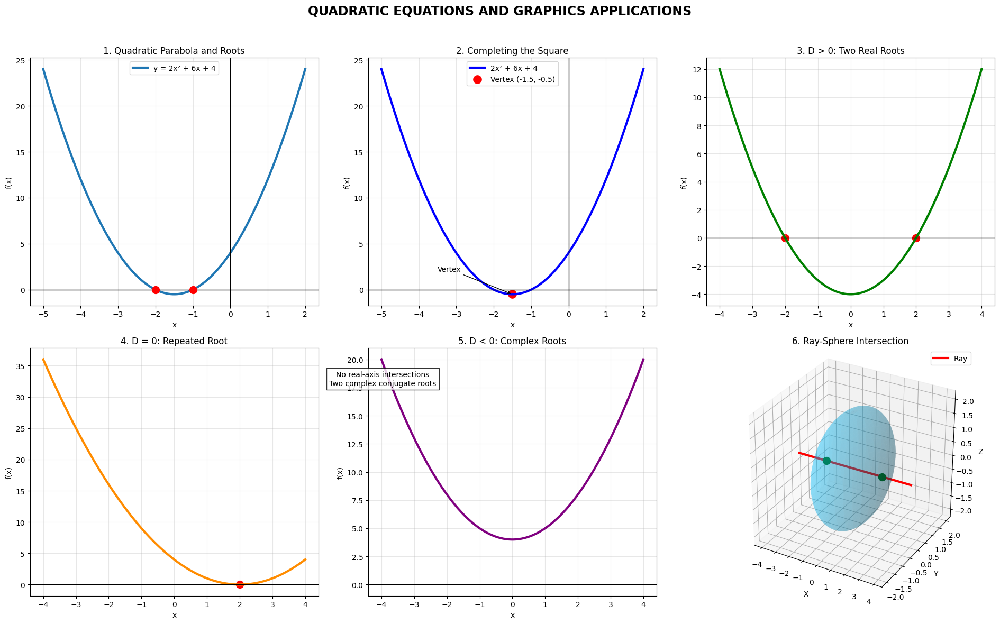

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. QUADRATIC EQUATION
# ============================================================

def discriminant(a, b, c):
    return b**2 - 4*a*c


def quadratic_roots(a, b, c):
    D = discriminant(a, b, c)

    if D > 0:
        return (
            (-b + np.sqrt(D)) / (2*a),
            (-b - np.sqrt(D)) / (2*a)
        )

    elif D == 0:
        return (-b / (2*a),)

    else:
        return (
            (-b + 1j*np.sqrt(-D)) / (2*a),
            (-b - 1j*np.sqrt(-D)) / (2*a)
        )


# ============================================================
# 2. WORKED EXAMPLE: 2x² + 6x + 4 = 0
# ============================================================

a, b, c = 2, 6, 4

D = discriminant(a, b, c)
roots = quadratic_roots(a, b, c)

x = np.linspace(-5, 2, 500)
y = a*x**2 + b*x + c

# ============================================================
# 3. THREE DISCRIMINANT CASES
# ============================================================

cases = [
    {"a": 1, "b": 0, "c": -4, "label": "Two distinct real roots"},
    {"a": 1, "b": -4, "c": 4, "label": "One repeated real root"},
    {"a": 1, "b": 0, "c": 4, "label": "Two complex roots"}
]

x_cases = np.linspace(-4, 4, 500)

# ============================================================
# 4. NUMERICALLY STABLE ROOT CALCULATION
# ============================================================

def stable_quadratic_roots(a, b, c):
    D = b**2 - 4*a*c

    if D < 0:
        return (
            (-b + 1j*np.sqrt(-D)) / (2*a),
            (-b - 1j*np.sqrt(-D)) / (2*a)
        )

    sqrt_D = np.sqrt(D)

    q = -0.5 * (b + np.copysign(sqrt_D, b))

    if q == 0:
        return (-b / (2*a), -b / (2*a))

    return q/a, c/q


# ============================================================
# 5. RAY-SPHERE INTERSECTION
# ============================================================

sphere_center = np.array([0.0, 0.0, 0.0])
sphere_radius = 2.0

ray_origin = np.array([-4.0, 0.0, 0.0])
ray_direction = np.array([1.0, 0.0, 0.0])

ray_direction = ray_direction / np.linalg.norm(ray_direction)

oc = ray_origin - sphere_center

qa = np.dot(ray_direction, ray_direction)
qb = 2 * np.dot(oc, ray_direction)
qc = np.dot(oc, oc) - sphere_radius**2

ray_D = qb**2 - 4*qa*qc

if ray_D >= 0:
    ray_roots = quadratic_roots(qa, qb, qc)
    ray_hits = sorted(
        t.real for t in ray_roots
        if abs(t.imag) < 1e-10 and t.real >= 0
    )
else:
    ray_hits = []

# ============================================================
# 6. CREATE SIX SUBPLOTS
# ============================================================

fig = plt.figure(figsize=(19, 12))

# ------------------------------------------------------------
# PANEL 1: PARABOLA AND ROOTS
# ------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(x, y, linewidth=3, label="y = 2x² + 6x + 4")
ax1.axhline(0, color="black", linewidth=1)
ax1.axvline(0, color="black", linewidth=1)

for root in roots:
    ax1.scatter(root.real, 0, color="red", s=100, zorder=5)

ax1.set_title("1. Quadratic Parabola and Roots")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 2: COMPLETING THE SQUARE
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(x, y, linewidth=3, color="blue",
         label="2x² + 6x + 4")

vertex_x = -b / (2*a)
vertex_y = a*vertex_x**2 + b*vertex_x + c

ax2.scatter(vertex_x, vertex_y, color="red",
            s=120, label="Vertex (-1.5, -0.5)")

ax2.axhline(0, color="black", linewidth=1)
ax2.axvline(0, color="black", linewidth=1)

ax2.annotate(
    "Vertex",
    xy=(vertex_x, vertex_y),
    xytext=(-3.5, 2),
    arrowprops=dict(arrowstyle="->")
)

ax2.set_title("2. Completing the Square")
ax2.set_xlabel("x")
ax2.set_ylabel("f(x)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 3: DISCRIMINANT > 0
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

case = cases[0]
y1 = case["a"]*x_cases**2 + case["b"]*x_cases + case["c"]

ax3.plot(x_cases, y1, linewidth=3, color="green")
ax3.axhline(0, color="black", linewidth=1)

r1 = quadratic_roots(case["a"], case["b"], case["c"])

for root in r1:
    ax3.scatter(root.real, 0, color="red", s=100)

ax3.set_title("3. D > 0: Two Real Roots")
ax3.set_xlabel("x")
ax3.set_ylabel("f(x)")
ax3.grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 4: DISCRIMINANT = 0
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

case = cases[1]
y2 = case["a"]*x_cases**2 + case["b"]*x_cases + case["c"]

ax4.plot(x_cases, y2, linewidth=3, color="darkorange")
ax4.axhline(0, color="black", linewidth=1)

r2 = quadratic_roots(case["a"], case["b"], case["c"])

for root in r2:
    ax4.scatter(root.real, 0, color="red", s=100)

ax4.set_title("4. D = 0: Repeated Root")
ax4.set_xlabel("x")
ax4.set_ylabel("f(x)")
ax4.grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 5: DISCRIMINANT < 0
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

case = cases[2]
y3 = case["a"]*x_cases**2 + case["b"]*x_cases + case["c"]

ax5.plot(x_cases, y3, linewidth=3, color="purple")
ax5.axhline(0, color="black", linewidth=1)

ax5.text(
    0.05, 0.85,
    "No real-axis intersections\nTwo complex conjugate roots",
    transform=ax5.transAxes,
    ha="center",
    bbox=dict(facecolor="white", alpha=0.8)
)

ax5.set_title("5. D < 0: Complex Roots")
ax5.set_xlabel("x")
ax5.set_ylabel("f(x)")
ax5.grid(True, alpha=0.3)

# ------------------------------------------------------------
# PANEL 6: RAY-SPHERE INTERSECTION
# ------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6, projection="3d")

u = np.linspace(0, 2*np.pi, 60)
v = np.linspace(0, np.pi, 40)

X = sphere_radius * np.outer(np.cos(u), np.sin(v))
Y = sphere_radius * np.outer(np.sin(u), np.sin(v))
Z = sphere_radius * np.outer(np.ones_like(u), np.cos(v))

ax6.plot_surface(X, Y, Z, alpha=0.25, color="deepskyblue")

t = np.linspace(0, 8, 100)
ray_points = ray_origin + np.outer(t, ray_direction)

ax6.plot(
    ray_points[:, 0],
    ray_points[:, 1],
    ray_points[:, 2],
    color="red",
    linewidth=3,
    label="Ray"
)

for hit in ray_hits:
    point = ray_origin + hit*ray_direction
    ax6.scatter(*point, color="darkgreen", s=100)

ax6.set_title("6. Ray-Sphere Intersection")
ax6.set_xlabel("X")
ax6.set_ylabel("Y")
ax6.set_zlabel("Z")
ax6.set_box_aspect((1, 1, 1))
ax6.legend()

# ============================================================
# 7. FINAL PRESENTATION
# ============================================================

fig.suptitle(
    "QUADRATIC EQUATIONS AND GRAPHICS APPLICATIONS",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 2.3 Trigonometry

Trigonometry studies mathematical relationships between angles, lengths and geometric directions. In computer graphics, it supports rotations, projections, camera positioning, geometric modelling and animation.

#### 2.3.1 Angles

An angle measures the rotational separation between two rays originating from a common point. Its standard unit is the radian, defined using the arc length on a unit circle. One complete revolution equals $2\pi$ radians or $360^\circ$.

The fundamental conversion equations are:

$$
180^\circ=\pi\text{ radians}
$$

$$
\theta_{\text{degrees}}=\theta_{\text{radians}}\frac{180}{\pi}
$$

$$
\theta_{\text{radians}}=\theta_{\text{degrees}}\frac{\pi}{180}
$$

These equations establish that 180 degrees correspond to pi radians. The first converts radians into degrees, while the second converts degrees into radians.

A signed angle commonly satisfies:

$$
-\pi\leq\theta\leq\pi
$$

This means theta lies between negative pi and positive pi radians, including both limits. Positive angles indicate counterclockwise rotation; negative angles indicate clockwise rotation.

**Worked Example:** Convert $60^\circ$ into radians.

$$
\theta=60\times\frac{\pi}{180}
=\frac{\pi}{3}
$$

Therefore, 60 degrees equals pi divided by three radians.

**Graphics Applications:** Angular measurement determines object orientation, rotational transformations, camera direction and animation motion. Radians simplify calculus because trigonometric derivatives and rotational equations naturally use radian measurements.

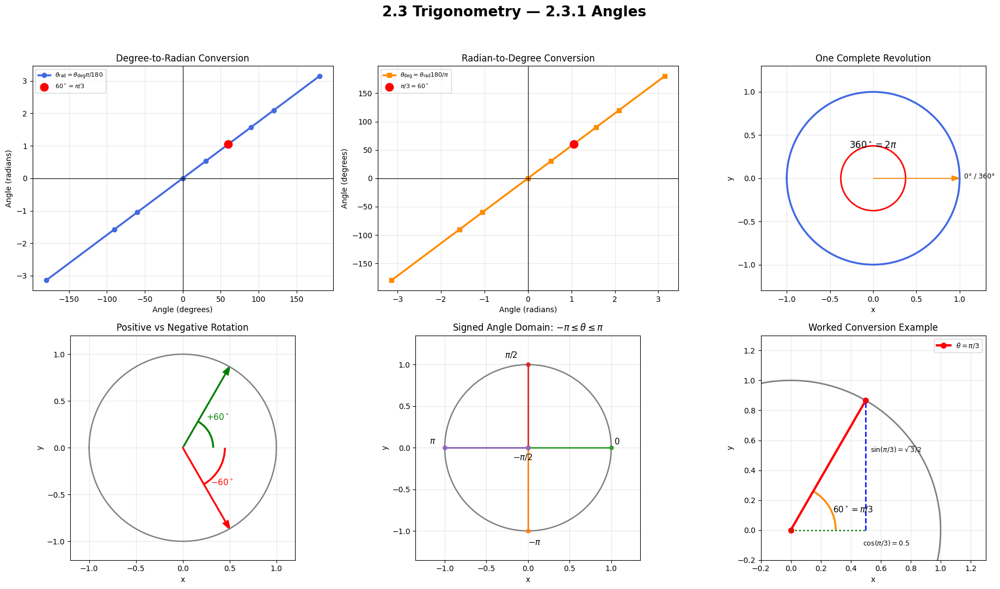

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

# ============================================================
# 2.3 TRIGONOMETRY — 2.3.1 ANGLES
# Synthetic mathematical data for reproducible visualisation
# ============================================================

# Fundamental constants
PI = np.pi

# Angle conversion functions
def radians_to_degrees(theta_rad):
    return np.degrees(theta_rad)

def degrees_to_radians(theta_deg):
    return np.radians(theta_deg)


# Worked example: 60 degrees to radians
theta_deg = 60
theta_rad = degrees_to_radians(theta_deg)

# Synthetic angles for conversion comparison
angles_deg = np.array([-180, -90, -60, 0, 30, 60, 90, 120, 180])
angles_rad = degrees_to_radians(angles_deg)

# Unit-circle coordinates
circle_angles = np.linspace(-PI, PI, 500)
circle_x = np.cos(circle_angles)
circle_y = np.sin(circle_angles)

fig = plt.figure(figsize=(19, 11))
fig.suptitle(
    "2.3 Trigonometry — 2.3.1 Angles",
    fontsize=19,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. Degree-to-radian conversion
# ------------------------------------------------------------
ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(
    angles_deg,
    angles_rad,
    color="royalblue",
    linewidth=2.5,
    marker="o",
    label=r"$\theta_{\mathrm{rad}}=\theta_{\mathrm{deg}}\pi/180$"
)

ax1.scatter(
    [60],
    [theta_rad],
    color="red",
    s=110,
    zorder=5,
    label=r"$60^\circ=\pi/3$"
)

ax1.set_title("Degree-to-Radian Conversion")
ax1.set_xlabel("Angle (degrees)")
ax1.set_ylabel("Angle (radians)")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.axvline(0, color="black", linewidth=0.8)
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

# ------------------------------------------------------------
# 2. Radian-to-degree conversion
# ------------------------------------------------------------
ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(
    angles_rad,
    angles_deg,
    color="darkorange",
    linewidth=2.5,
    marker="s",
    label=r"$\theta_{\mathrm{deg}}=\theta_{\mathrm{rad}}180/\pi$"
)

ax2.scatter(
    [PI / 3],
    [60],
    color="red",
    s=110,
    zorder=5,
    label=r"$\pi/3=60^\circ$"
)

ax2.set_title("Radian-to-Degree Conversion")
ax2.set_xlabel("Angle (radians)")
ax2.set_ylabel("Angle (degrees)")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)

# ------------------------------------------------------------
# 3. Complete revolution: 360 degrees = 2π radians
# ------------------------------------------------------------
ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(
    circle_x,
    circle_y,
    color="royalblue",
    linewidth=2.5
)

ax3.arrow(
    0, 0, 1.0, 0,
    head_width=0.06,
    head_length=0.09,
    color="darkorange",
    length_includes_head=True
)

ax3.add_patch(
    Arc(
        (0, 0),
        0.75,
        0.75,
        theta1=0,
        theta2=359,
        color="red",
        linewidth=2
    )
)

ax3.text(0, 0.35, r"$360^\circ=2\pi$", ha="center", fontsize=12)
ax3.text(1.05, 0, "0° / 360°", fontsize=9)
ax3.set_title("One Complete Revolution")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_aspect("equal")
ax3.set_xlim(-1.3, 1.3)
ax3.set_ylim(-1.3, 1.3)
ax3.grid(alpha=0.3)

# ------------------------------------------------------------
# 4. Positive and negative angles
# ------------------------------------------------------------
ax4 = fig.add_subplot(2, 3, 4)

ax4.plot(circle_x, circle_y, color="gray", linewidth=1.8)

# Positive 60-degree angle: counterclockwise
ax4.arrow(
    0, 0,
    np.cos(PI / 3),
    np.sin(PI / 3),
    head_width=0.055,
    color="green",
    linewidth=2,
    length_includes_head=True
)

# Negative 60-degree angle: clockwise
ax4.arrow(
    0, 0,
    np.cos(-PI / 3),
    np.sin(-PI / 3),
    head_width=0.055,
    color="red",
    linewidth=2,
    length_includes_head=True
)

ax4.add_patch(
    Arc(
        (0, 0), 0.65, 0.65,
        theta1=0, theta2=60,
        color="green", linewidth=2.5
    )
)

ax4.add_patch(
    Arc(
        (0, 0), 0.9, 0.9,
        theta1=-60, theta2=0,
        color="red", linewidth=2.5
    )
)

ax4.text(0.25, 0.30, r"$+60^\circ$", color="green", fontsize=11)
ax4.text(0.30, -0.40, r"$-60^\circ$", color="red", fontsize=11)

ax4.set_title("Positive vs Negative Rotation")
ax4.set_xlabel("x")
ax4.set_ylabel("y")
ax4.set_aspect("equal")
ax4.set_xlim(-1.2, 1.2)
ax4.set_ylim(-1.2, 1.2)
ax4.grid(alpha=0.3)

# ------------------------------------------------------------
# 5. Signed angle range: -π ≤ θ ≤ π
# ------------------------------------------------------------
ax5 = fig.add_subplot(2, 3, 5)

ax5.plot(circle_x, circle_y, color="gray", linewidth=1.8)

boundary_angles = [-PI, -PI / 2, 0, PI / 2, PI]

for angle in boundary_angles:
    x = np.cos(angle)
    y = np.sin(angle)

    ax5.plot(
        [0, x],
        [0, y],
        linewidth=2,
        marker="o",
        markersize=5
    )

labels = [
    (0, -1.17, r"$-\pi$"),
    (-0.18, -0.15, r"$-\pi/2$"),
    (1.04, 0.04, "0"),
    (-0.28, 1.08, r"$\pi/2$"),
    (-1.18, 0.05, r"$\pi$")
]

for x, y, label in labels:
    ax5.text(x, y, label, fontsize=11)

ax5.set_title(r"Signed Angle Domain: $-\pi\leq\theta\leq\pi$")
ax5.set_xlabel("x")
ax5.set_ylabel("y")
ax5.set_aspect("equal")
ax5.set_xlim(-1.35, 1.35)
ax5.set_ylim(-1.35, 1.35)
ax5.grid(alpha=0.3)

# ------------------------------------------------------------
# 6. Worked example: 60 degrees = π/3 radians
# ------------------------------------------------------------
ax6 = fig.add_subplot(2, 3, 6)

ax6.plot(circle_x, circle_y, color="gray", linewidth=2)

# Radius at 60 degrees
x60 = np.cos(theta_rad)
y60 = np.sin(theta_rad)

ax6.plot(
    [0, x60],
    [0, y60],
    color="red",
    linewidth=3,
    marker="o",
    markersize=7,
    label=r"$\theta=\pi/3$"
)

ax6.plot(
    [x60, x60],
    [0, y60],
    linestyle="--",
    color="blue",
    linewidth=1.8
)

ax6.plot(
    [0, x60],
    [0, 0],
    linestyle=":",
    color="green",
    linewidth=2
)

ax6.add_patch(
    Arc(
        (0, 0),
        0.6,
        0.6,
        theta1=0,
        theta2=60,
        color="darkorange",
        linewidth=2.5
    )
)

ax6.text(0.28, 0.12, r"$60^\circ=\pi/3$", fontsize=11)
ax6.text(0.48, -0.10, r"$\cos(\pi/3)=0.5$", fontsize=9)
ax6.text(0.53, 0.52, r"$\sin(\pi/3)=\sqrt{3}/2$", fontsize=9)

ax6.set_title("Worked Conversion Example")
ax6.set_xlabel("x")
ax6.set_ylabel("y")
ax6.set_aspect("equal")
ax6.set_xlim(-0.2, 1.3)
ax6.set_ylim(-0.2, 1.3)
ax6.grid(alpha=0.3)
ax6.legend(fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 2.3.2 Trigonometric Functions

Trigonometric functions express relationships between angles and side lengths in right-angled triangles. They support geometric modelling, rotations, projections and spatial positioning in computer graphics.

The **Pythagorean theorem** defines the relationship between the perpendicular sides and hypotenuse:

$$
a^2+o^2=h^2
$$

Here, $a$ represents the adjacent side, $o$ the opposite side and $h$ the hypotenuse. The equation states that the square of the adjacent side plus the square of the opposite side equals the square of the hypotenuse.

The six fundamental trigonometric ratios are:

$$
\sin\phi=\frac{o}{h},\quad
\cos\phi=\frac{a}{h},\quad
\tan\phi=\frac{o}{a}
$$

$$
\csc\phi=\frac{h}{o},\quad
\sec\phi=\frac{h}{a},\quad
\cot\phi=\frac{a}{o}
$$

These represent sine, cosine, tangent, cosecant, secant and cotangent respectively.

**Polar Coordinates**

A two-dimensional point is represented by radial distance $r$ and angle $\phi$:

$$
x=r\cos\phi,\qquad y=r\sin\phi
$$

Conversely:

$$
r=\sqrt{x^2+y^2},\qquad
\phi=\operatorname{atan2}(y,x)
$$

For point $(1,\sqrt3)$:

$$
r=\sqrt{1^2+(\sqrt3)^2}=2
$$

$$
\phi=\operatorname{atan2}(\sqrt3,1)=\frac{\pi}{3}
$$

Its polar coordinates are $(2,\pi/3)$.

**Inverse Trigonometric Functions**

- $\arcsin(x):[-1,1]\rightarrow[-\pi/2,\pi/2]$.
- $\arccos(x):[-1,1]\rightarrow[0,\pi]$.
- $\arctan(x):\mathbb R\rightarrow(-\pi/2,\pi/2)$.
- $\operatorname{atan2}(y,x):\mathbb R^2\rightarrow[-\pi,\pi]$, excluding the undefined origin.

Sine and cosine repeat every $2\pi$ radians, supporting periodic motion, coordinate conversion and rotational transformations.

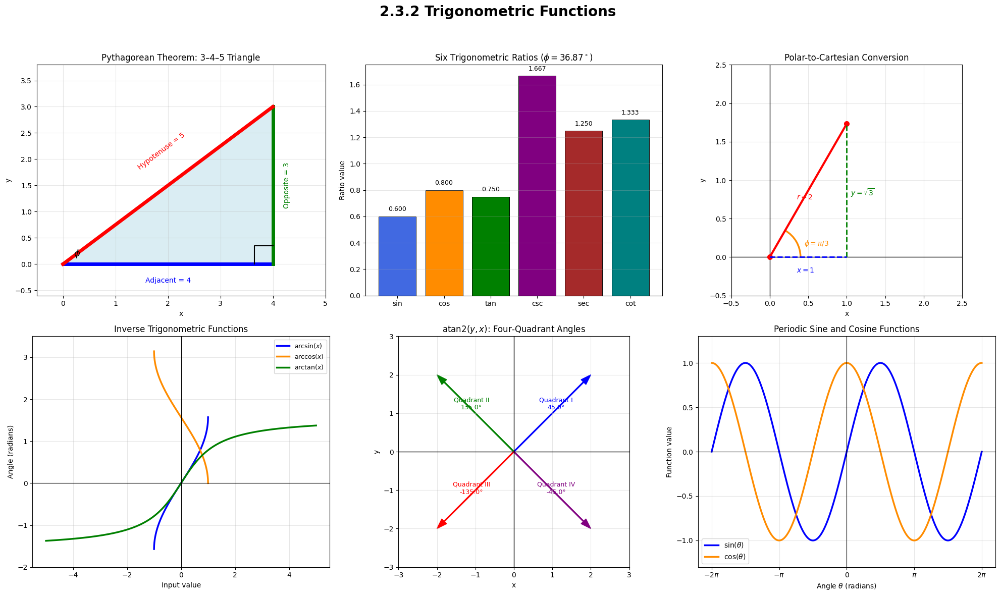

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

# ============================================================
# QUANT-ACGAP
# 2.3.2 TRIGONOMETRIC FUNCTIONS
#
# Synthetic mathematical dataset:
# - Right-triangle geometry
# - Six trigonometric ratios
# - Polar and Cartesian coordinate conversion
# - Inverse trigonometric functions
# - atan2 quadrant behaviour
# - Periodic sine and cosine functions
# ============================================================

PI = np.pi

# ------------------------------------------------------------
# Fundamental trigonometric functions
# ------------------------------------------------------------

def trig_ratios(theta):
    sin_value = np.sin(theta)
    cos_value = np.cos(theta)

    return {
        "sin": sin_value,
        "cos": cos_value,
        "tan": np.divide(
            sin_value, cos_value,
            out=np.full_like(np.asarray(sin_value, dtype=float), np.nan),
            where=np.abs(cos_value) > 1e-12
        ),
        "csc": np.divide(
            1.0, sin_value,
            out=np.full_like(np.asarray(sin_value, dtype=float), np.nan),
            where=np.abs(sin_value) > 1e-12
        ),
        "sec": np.divide(
            1.0, cos_value,
            out=np.full_like(np.asarray(cos_value, dtype=float), np.nan),
            where=np.abs(cos_value) > 1e-12
        ),
        "cot": np.divide(
            cos_value, sin_value,
            out=np.full_like(np.asarray(sin_value, dtype=float), np.nan),
            where=np.abs(sin_value) > 1e-12
        )
    }


# ------------------------------------------------------------
# 1. Pythagorean theorem and right-triangle geometry
# ------------------------------------------------------------

fig = plt.figure(figsize=(20, 12))
fig.suptitle(
    "2.3.2 Trigonometric Functions",
    fontsize=20,
    fontweight="bold"
)

ax1 = fig.add_subplot(2, 3, 1)

# Synthetic 3-4-5 right triangle
adjacent = 4
opposite = 3
hypotenuse = np.sqrt(adjacent**2 + opposite**2)

triangle_x = [0, adjacent, adjacent, 0]
triangle_y = [0, 0, opposite, 0]

ax1.plot(
    triangle_x,
    triangle_y,
    color="black",
    linewidth=2.5
)

ax1.fill(
    [0, adjacent, adjacent],
    [0, 0, opposite],
    color="lightblue",
    alpha=0.45
)

ax1.plot([0, adjacent], [0, 0], color="blue", linewidth=5)
ax1.plot([adjacent, adjacent], [0, opposite], color="green", linewidth=5)
ax1.plot([0, adjacent], [0, opposite], color="red", linewidth=5)

ax1.plot(
    [adjacent - 0.35, adjacent - 0.35, adjacent],
    [0, 0.35, 0.35],
    color="black",
    linewidth=1.5
)

ax1.text(2, -0.35, "Adjacent = 4", ha="center", color="blue")
ax1.text(4.2, 1.5, "Opposite = 3", color="green", rotation=90, va="center")
ax1.text(1.4, 1.8, "Hypotenuse = 5", color="red", rotation=36.87)

ax1.text(0.2, 0.15, r"$\phi$", fontsize=13)

ax1.set_title("Pythagorean Theorem: 3–4–5 Triangle")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_xlim(-0.5, 5)
ax1.set_ylim(-0.6, 3.8)
ax1.set_aspect("equal")
ax1.grid(alpha=0.3)

# ------------------------------------------------------------
# 2. Six fundamental trigonometric ratios
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

phi = np.radians(36.87)
ratios = trig_ratios(np.array(phi))

ratio_names = ["sin", "cos", "tan", "csc", "sec", "cot"]
ratio_values = [
    ratios["sin"],
    ratios["cos"],
    ratios["tan"],
    ratios["csc"],
    ratios["sec"],
    ratios["cot"]
]

bars = ax2.bar(
    ratio_names,
    ratio_values,
    color=[
        "royalblue",
        "darkorange",
        "green",
        "purple",
        "brown",
        "teal"
    ],
    edgecolor="black",
    linewidth=0.7
)

for bar, value in zip(bars, ratio_values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.04,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

ax2.set_title(r"Six Trigonometric Ratios ($\phi=36.87^\circ$)")
ax2.set_ylabel("Ratio value")
ax2.grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# 3. Polar and Cartesian coordinate conversion
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

# Worked example: (x, y) = (1, sqrt(3))
x_point = 1
y_point = np.sqrt(3)

r = np.sqrt(x_point**2 + y_point**2)
phi_point = np.arctan2(y_point, x_point)

ax3.axhline(0, color="black", linewidth=1)
ax3.axvline(0, color="black", linewidth=1)

ax3.plot(
    [0, x_point],
    [0, y_point],
    color="red",
    linewidth=3,
    marker="o",
    markersize=7
)

ax3.plot(
    [x_point, x_point],
    [0, y_point],
    linestyle="--",
    color="green",
    linewidth=2
)

ax3.plot(
    [0, x_point],
    [0, 0],
    linestyle="--",
    color="blue",
    linewidth=2
)

ax3.add_patch(
    Arc(
        (0, 0),
        0.8,
        0.8,
        theta1=0,
        theta2=60,
        color="darkorange",
        linewidth=2.5
    )
)

ax3.text(0.45, 0.15, r"$\phi=\pi/3$", color="darkorange")
ax3.text(1.05, 0.8, r"$y=\sqrt{3}$", color="green")
ax3.text(0.35, -0.2, "$x=1$", color="blue")
ax3.text(0.35, 0.75, "$r=2$", color="red")

ax3.set_title("Polar-to-Cartesian Conversion")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_xlim(-0.5, 2.5)
ax3.set_ylim(-0.5, 2.5)
ax3.set_aspect("equal")
ax3.grid(alpha=0.3)

# ------------------------------------------------------------
# 4. Inverse trigonometric functions
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

x = np.linspace(-1, 1, 500)

ax4.plot(
    x,
    np.arcsin(x),
    label=r"$\arcsin(x)$",
    color="blue",
    linewidth=2.5
)

ax4.plot(
    x,
    np.arccos(x),
    label=r"$\arccos(x)$",
    color="darkorange",
    linewidth=2.5
)

x_atan = np.linspace(-5, 5, 500)

ax4.plot(
    x_atan,
    np.arctan(x_atan),
    label=r"$\arctan(x)$",
    color="green",
    linewidth=2.5
)

ax4.axhline(0, color="black", linewidth=0.8)
ax4.axvline(0, color="black", linewidth=0.8)

ax4.set_title("Inverse Trigonometric Functions")
ax4.set_xlabel("Input value")
ax4.set_ylabel("Angle (radians)")
ax4.set_ylim(-2, 3.5)
ax4.legend(fontsize=9)
ax4.grid(alpha=0.3)

# ------------------------------------------------------------
# 5. atan2(y, x): quadrant determination
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

ax5.axhline(0, color="black", linewidth=1)
ax5.axvline(0, color="black", linewidth=1)

quadrant_points = [
    (2, 2, "Quadrant I"),
    (-2, 2, "Quadrant II"),
    (-2, -2, "Quadrant III"),
    (2, -2, "Quadrant IV")
]

quadrant_colors = ["blue", "green", "red", "purple"]

for (px, py, label), color in zip(quadrant_points, quadrant_colors):
    angle = np.arctan2(py, px)

    ax5.arrow(
        0, 0, px, py,
        color=color,
        width=0.025,
        head_width=0.18,
        length_includes_head=True
    )

    ax5.text(
        px * 0.55,
        py * 0.55,
        f"{label}\n{np.degrees(angle):.1f}°",
        color=color,
        fontsize=9,
        ha="center"
    )

ax5.set_title(r"$\mathrm{atan2}(y,x)$: Four-Quadrant Angles")
ax5.set_xlabel("x")
ax5.set_ylabel("y")
ax5.set_xlim(-3, 3)
ax5.set_ylim(-3, 3)
ax5.set_aspect("equal")
ax5.grid(alpha=0.3)

# ------------------------------------------------------------
# 6. Periodicity of sine and cosine
# ------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6)

theta = np.linspace(-2 * PI, 2 * PI, 1000)

ax6.plot(
    theta,
    np.sin(theta),
    color="blue",
    linewidth=2.5,
    label=r"$\sin(\theta)$"
)

ax6.plot(
    theta,
    np.cos(theta),
    color="darkorange",
    linewidth=2.5,
    label=r"$\cos(\theta)$"
)

ax6.axhline(0, color="black", linewidth=0.8)
ax6.axvline(0, color="black", linewidth=0.8)

ax6.set_xticks(
    [-2 * PI, -PI, 0, PI, 2 * PI],
    [r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"]
)

ax6.set_title("Periodic Sine and Cosine Functions")
ax6.set_xlabel(r"Angle $\theta$ (radians)")
ax6.set_ylabel("Function value")
ax6.set_ylim(-1.3, 1.3)
ax6.legend()
ax6.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 2.3.3 Useful Trigonometric Identities

Trigonometric identities are mathematical equalities valid for all permissible angle values. They simplify calculations involving rotations, coordinate transformations, geometric modelling and spatial positioning in computer graphics.

**1. Shifting Identities**

These describe angle symmetry and complementary relationships:

$$
\begin{aligned}
\sin(-A)&=-\sin A\\
\cos(-A)&=\cos A\\
\tan(-A)&=-\tan A\\
\sin\left(\frac{\pi}{2}-A\right)&=\cos A\\
\cos\left(\frac{\pi}{2}-A\right)&=\sin A\\
\tan\left(\frac{\pi}{2}-A\right)&=\cot A
\end{aligned}
$$

A negative angle reverses the signs of sine and tangent, while cosine remains unchanged.

**2. Pythagorean Identities**

Derived from the unit-circle equation:

$$
x^2+y^2=1
$$

$$
\sin^2 A+\cos^2 A=1
$$

$$
\sec^2 A-\tan^2 A=1,\quad
\csc^2 A-\cot^2 A=1
$$

**3. Addition and Double-Angle Identities**

$$
\sin(A\pm B)=\sin A\cos B\pm\cos A\sin B
$$

$$
\cos(A\pm B)=\cos A\cos B\mp\sin A\sin B
$$

$$
\sin 2A=2\sin A\cos A
$$

$$
\cos 2A=\cos^2 A-\sin^2 A
$$

**4. Half-Angle and Product Identities**

$$
\sin^2\frac A2=\frac{1-\cos A}{2},\quad
\cos^2\frac A2=\frac{1+\cos A}{2}
$$

Product identities convert trigonometric products into sums or differences.

**5. Triangle Laws**

$$
\frac a{\sin A}=\frac b{\sin B}=\frac c{\sin C}
$$

$$
c^2=a^2+b^2-2ab\cos C
$$

Heron's formula calculates triangle area:

$$
K=\sqrt{s(s-a)(s-b)(s-c)},\quad
s=\frac{a+b+c}{2}
$$

Here, $a,b,c$ are side lengths, $A,B,C$ their opposite angles, $K$ the area and $s$ the semiperimeter. These relationships support accurate geometric computation and graphics transformations.

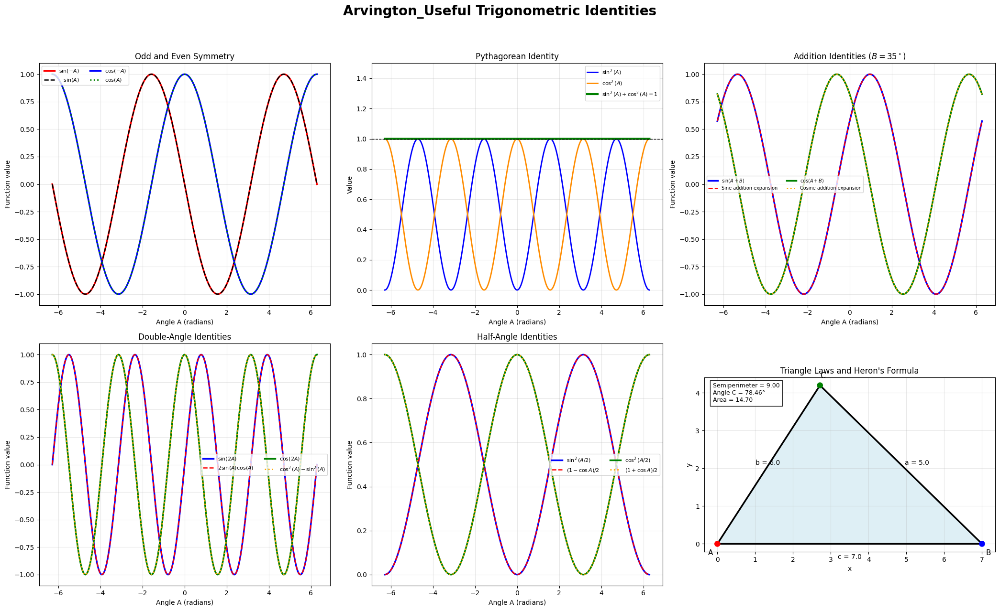

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# QUANT-ACGAP
# 2.3.3 USEFUL TRIGONOMETRIC IDENTITIES
#
# Synthetic mathematical datasets are used to demonstrate:
# 1. Shifting and symmetry identities
# 2. Pythagorean identities
# 3. Addition and subtraction identities
# 4. Double-angle identities
# 5. Half-angle and product-to-sum identities
# 6. Sine rule, cosine rule and Heron's formula
#
# Numerical verification is performed using NumPy.
# ============================================================

PI = np.pi
EPS = 1e-10

fig = plt.figure(figsize=(21, 13))
fig.suptitle(
    "Arvington_Useful Trigonometric Identities",
    fontsize=20,
    fontweight="bold"
)

# Synthetic angular dataset
A = np.linspace(-2 * PI, 2 * PI, 1200)
B = np.radians(35)

# ------------------------------------------------------------
# 1. SHIFTING AND SYMMETRY IDENTITIES
# ------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(
    A, np.sin(-A),
    color="red", linewidth=2.5,
    label=r"$\sin(-A)$"
)
ax1.plot(
    A, -np.sin(A),
    color="black", linestyle="--",
    linewidth=1.8, label=r"$-\sin(A)$"
)

ax1.plot(
    A, np.cos(-A),
    color="blue", linewidth=2.5,
    label=r"$\cos(-A)$"
)
ax1.plot(
    A, np.cos(A),
    color="green", linestyle=":",
    linewidth=2, label=r"$\cos(A)$"
)

ax1.set_title("Odd and Even Symmetry")
ax1.set_xlabel("Angle A (radians)")
ax1.set_ylabel("Function value")
ax1.legend(fontsize=8, ncol=2)
ax1.grid(alpha=0.3)

# ------------------------------------------------------------
# 2. PYTHAGOREAN IDENTITIES
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

sin_squared = np.sin(A)**2
cos_squared = np.cos(A)**2
pythagorean_sum = sin_squared + cos_squared

ax2.plot(
    A, sin_squared,
    color="blue", linewidth=2,
    label=r"$\sin^2(A)$"
)
ax2.plot(
    A, cos_squared,
    color="darkorange", linewidth=2,
    label=r"$\cos^2(A)$"
)
ax2.plot(
    A, pythagorean_sum,
    color="green", linewidth=3,
    label=r"$\sin^2(A)+\cos^2(A)=1$"
)

ax2.axhline(1, color="black", linestyle="--", linewidth=1)

ax2.set_title("Pythagorean Identity")
ax2.set_xlabel("Angle A (radians)")
ax2.set_ylabel("Value")
ax2.set_ylim(-0.1, 1.5)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# Secondary Pythagorean identities
# sec²(A) - tan²(A) = 1
# csc²(A) - cot²(A) = 1

valid_sec = np.abs(np.cos(A)) > 0.08
valid_csc = np.abs(np.sin(A)) > 0.08

sec_identity = (
    1 / np.cos(A[valid_sec])**2
    - np.tan(A[valid_sec])**2
)

csc_identity = (
    1 / np.sin(A[valid_csc])**2
    - (np.cos(A[valid_csc]) / np.sin(A[valid_csc]))**2
)

# ------------------------------------------------------------
# 3. ADDITION AND SUBTRACTION IDENTITIES
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

# Direct calculation
sin_add_direct = np.sin(A + B)
sin_add_identity = (
    np.sin(A) * np.cos(B)
    + np.cos(A) * np.sin(B)
)

cos_add_direct = np.cos(A + B)
cos_add_identity = (
    np.cos(A) * np.cos(B)
    - np.sin(A) * np.sin(B)
)

ax3.plot(
    A, sin_add_direct,
    color="blue", linewidth=2.5,
    label=r"$\sin(A+B)$"
)
ax3.plot(
    A, sin_add_identity,
    color="red", linestyle="--",
    linewidth=1.8,
    label="Sine addition expansion"
)

ax3.plot(
    A, cos_add_direct,
    color="green", linewidth=2.5,
    label=r"$\cos(A+B)$"
)
ax3.plot(
    A, cos_add_identity,
    color="orange", linestyle=":",
    linewidth=2,
    label="Cosine addition expansion"
)

ax3.set_title(r"Addition Identities ($B=35^\circ$)")
ax3.set_xlabel("Angle A (radians)")
ax3.set_ylabel("Function value")
ax3.legend(fontsize=7, ncol=2)
ax3.grid(alpha=0.3)

# ------------------------------------------------------------
# 4. DOUBLE-ANGLE IDENTITIES
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

sin_double_direct = np.sin(2 * A)
sin_double_identity = 2 * np.sin(A) * np.cos(A)

cos_double_direct = np.cos(2 * A)
cos_double_identity = np.cos(A)**2 - np.sin(A)**2

ax4.plot(
    A, sin_double_direct,
    color="blue", linewidth=2.5,
    label=r"$\sin(2A)$"
)
ax4.plot(
    A, sin_double_identity,
    color="red", linestyle="--",
    linewidth=1.8,
    label=r"$2\sin(A)\cos(A)$"
)

ax4.plot(
    A, cos_double_direct,
    color="green", linewidth=2.5,
    label=r"$\cos(2A)$"
)
ax4.plot(
    A, cos_double_identity,
    color="orange", linestyle=":",
    linewidth=2,
    label=r"$\cos^2(A)-\sin^2(A)$"
)

ax4.set_title("Double-Angle Identities")
ax4.set_xlabel("Angle A (radians)")
ax4.set_ylabel("Function value")
ax4.legend(fontsize=8, ncol=2)
ax4.grid(alpha=0.3)

# ------------------------------------------------------------
# 5. HALF-ANGLE AND PRODUCT-TO-SUM IDENTITIES
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

# Correct half-angle identities:
# sin²(A/2) = (1 - cos A)/2
# cos²(A/2) = (1 + cos A)/2

sin_half_direct = np.sin(A / 2)**2
sin_half_identity = (1 - np.cos(A)) / 2

cos_half_direct = np.cos(A / 2)**2
cos_half_identity = (1 + np.cos(A)) / 2

ax5.plot(
    A, sin_half_direct,
    color="blue", linewidth=2.5,
    label=r"$\sin^2(A/2)$"
)
ax5.plot(
    A, sin_half_identity,
    color="red", linestyle="--",
    linewidth=1.8,
    label=r"$(1-\cos A)/2$"
)

ax5.plot(
    A, cos_half_direct,
    color="green", linewidth=2.5,
    label=r"$\cos^2(A/2)$"
)
ax5.plot(
    A, cos_half_identity,
    color="orange", linestyle=":",
    linewidth=2,
    label=r"$(1+\cos A)/2$"
)

ax5.set_title("Half-Angle Identities")
ax5.set_xlabel("Angle A (radians)")
ax5.set_ylabel("Function value")
ax5.legend(fontsize=8, ncol=2)
ax5.grid(alpha=0.3)

# ------------------------------------------------------------
# 6. TRIANGLE LAWS AND HERON'S FORMULA
# ------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6)

# Synthetic triangle with side lengths:
# a = 5, b = 6, c = 7

a = 5.0
b = 6.0
c = 7.0

# Semiperimeter
s = (a + b + c) / 2

# Heron's formula
area_heron = np.sqrt(
    s * (s - a) * (s - b) * (s - c)
)

# Cosine rule for angle C
cos_C = (a**2 + b**2 - c**2) / (2 * a * b)
C = np.arccos(cos_C)

# Construct triangle in Cartesian coordinates
# Side c lies on the horizontal axis.
x_C = (a**2 + c**2 - b**2) / (2 * c)
y_C = np.sqrt(a**2 - x_C**2)

triangle_x = [0, c, x_C, 0]
triangle_y = [0, 0, y_C, 0]

ax6.fill(
    triangle_x,
    triangle_y,
    color="lightblue",
    alpha=0.4
)

ax6.plot(
    triangle_x,
    triangle_y,
    color="black",
    linewidth=2.5
)

ax6.scatter(
    [0, c, x_C],
    [0, 0, y_C],
    color=["red", "blue", "green"],
    s=65,
    zorder=4
)

ax6.text(-0.25, -0.3, "A", fontsize=11)
ax6.text(c + 0.1, -0.3, "B", fontsize=11)
ax6.text(x_C, y_C + 0.2, "C", fontsize=11)

ax6.text(c / 2, -0.4, f"c = {c}", ha="center")
ax6.text(x_C / 2 - 0.35, y_C / 2, f"b = {b}", rotation=0)
ax6.text((x_C + c) / 2 + 0.1, y_C / 2, f"a = {a}")

ax6.set_title("Triangle Laws and Heron's Formula")
ax6.set_xlabel("x")
ax6.set_ylabel("y")
ax6.set_aspect("equal")
ax6.grid(alpha=0.3)

ax6.text(
    0.03, 0.97,
    f"Semiperimeter = {s:.2f}\n"
    f"Angle C = {np.degrees(C):.2f}°\n"
    f"Area = {area_heron:.2f}",
    transform=ax6.transAxes,
    verticalalignment="top",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.85)
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ------------------------------------------------------------
# NUMERICAL IDENTITY VERIFICATION
# No console output: results are retained as variables.
# ------------------------------------------------------------

# 1. Shifting identities
shift_sine_error = np.max(np.abs(np.sin(-A) + np.sin(A)))
shift_cosine_error = np.max(np.abs(np.cos(-A) - np.cos(A)))
shift_tangent_error = np.max(
    np.abs(np.tan(-A[np.abs(np.cos(A)) > EPS])
           + np.tan(A[np.abs(np.cos(A)) > EPS]))
)

# 2. Pythagorean identities
pythagorean_error = np.max(
    np.abs(np.sin(A)**2 + np.cos(A)**2 - 1)
)

sec_identity_error = np.max(np.abs(sec_identity - 1))
csc_identity_error = np.max(np.abs(csc_identity - 1))

# 3. Addition identities
addition_sine_error = np.max(
    np.abs(sin_add_direct - sin_add_identity)
)
addition_cosine_error = np.max(
    np.abs(cos_add_direct - cos_add_identity)
)

# 4. Double-angle identities
double_sine_error = np.max(
    np.abs(sin_double_direct - sin_double_identity)
)
double_cosine_error = np.max(
    np.abs(cos_double_direct - cos_double_identity)
)

# 5. Half-angle identities
half_sine_error = np.max(
    np.abs(sin_half_direct - sin_half_identity)
)
half_cosine_error = np.max(
    np.abs(cos_half_direct - cos_half_identity)
)

# 6. Triangle area comparison
area_base_height = 0.5 * c * y_C
heron_area_error = abs(area_heron - area_base_height)

# Error values are available for inspection:
identity_errors = {
    "sine_shift": shift_sine_error,
    "cosine_shift": shift_cosine_error,
    "tangent_shift": shift_tangent_error,
    "pythagorean": pythagorean_error,
    "secant_pythagorean": sec_identity_error,
    "cosecant_pythagorean": csc_identity_error,
    "addition_sine": addition_sine_error,
    "addition_cosine": addition_cosine_error,
    "double_angle_sine": double_sine_error,
    "double_angle_cosine": double_cosine_error,
    "half_angle_sine": half_sine_error,
    "half_angle_cosine": half_cosine_error,
    "heron_area": heron_area_error
}

### 2.4 Vectors

A **vector** is a mathematical quantity possessing magnitude (length) and direction, geometrically represented by an arrow. Two vectors are equal when their magnitudes and directions are identical, regardless of their positions. A vector is denoted by $\mathbf{a}$, while its magnitude is represented by $\|\mathbf{a}\|$. A unit vector has magnitude one; the zero vector has magnitude zero and no defined direction.

In three-dimensional Cartesian space:

$$
\mathbf{a}=(a_x,a_y,a_z)
$$

This represents a vector with components $a_x$, $a_y$ and $a_z$ along the three coordinate axes. Its magnitude is:

$$
\|\mathbf{a}\|=\sqrt{a_x^2+a_y^2+a_z^2}
$$

The magnitude equals the square root of the sum of the squared components.

Vectors represent displacement, direction, velocity and force. In computer graphics, they support object movement, orientation, lighting calculations and geometric transformations.

**Vectors and Positions**

A displacement vector describes the change between two spatial positions, $P$ and $Q$:

$$
\mathbf{v}=Q-P
$$

This means the displacement equals the final position minus the initial position. A position identifies a location relative to an origin, whereas a vector specifies magnitude and direction.

Vector addition combines compatible displacements:

$$
\mathbf{a}+\mathbf{b}
=(a_x+b_x,a_y+b_y,a_z+b_z)
$$

Each corresponding component is added independently. However, adding two positions generally lacks direct geometric meaning. Distinguishing positions from displacement vectors is essential for mathematically consistent spatial modelling, animation and coordinate transformations.

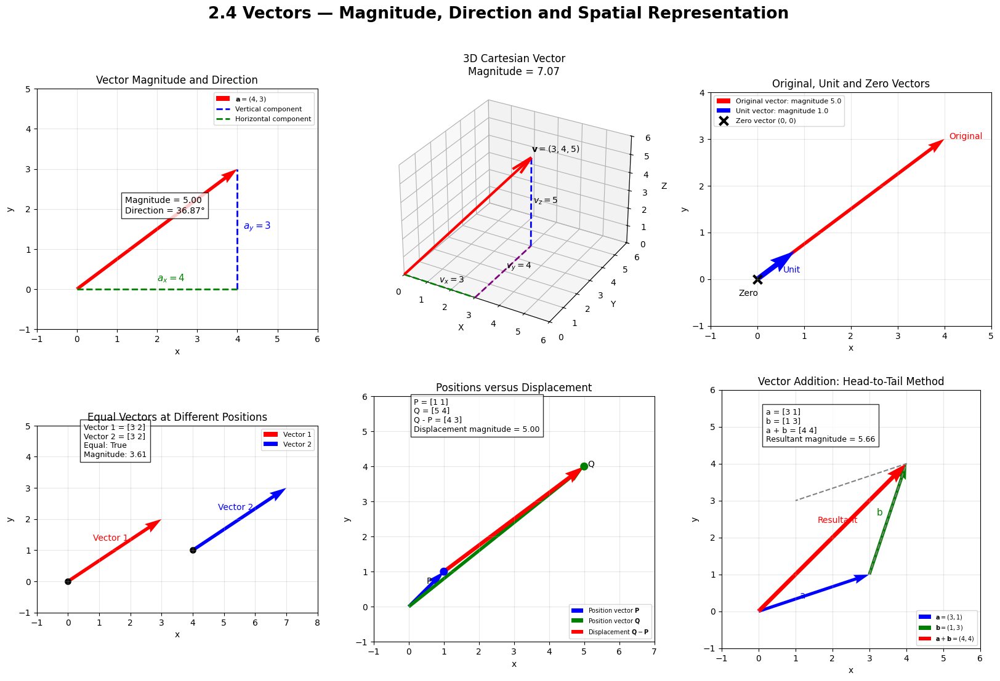

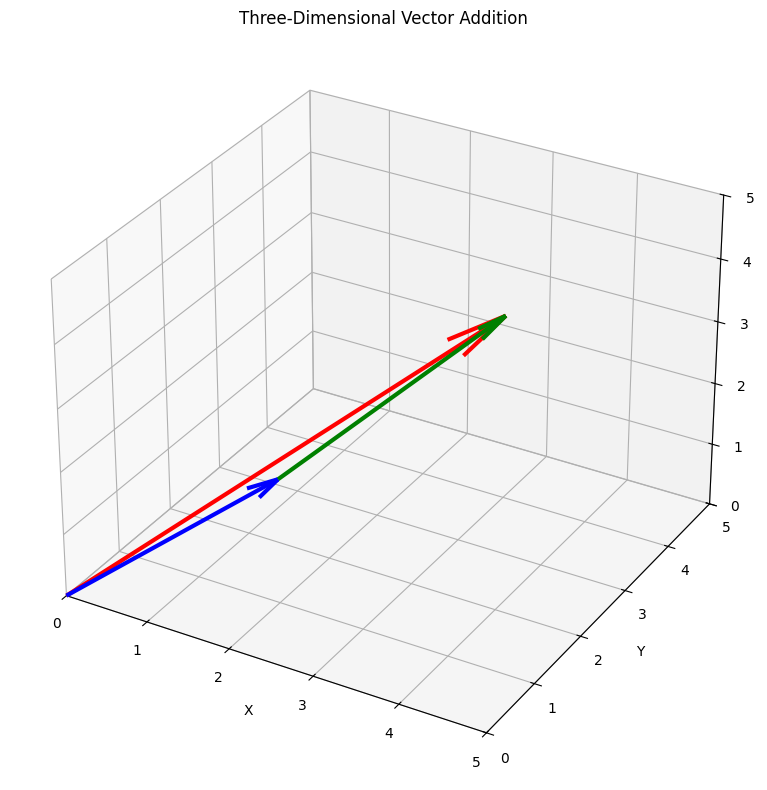

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# QUANT-ACGAP
# 2.4 VECTORS
#
# Synthetic 2D and 3D vector datasets demonstrate:
# 1. Vector magnitude and direction
# 2. Three-dimensional Cartesian components
# 3. Unit vectors and zero vectors
# 4. Vector equality independent of position
# 5. Position vectors versus displacement vectors
# 6. Vector addition using the parallelogram and
#    head-to-tail methods
#
# All experiments use mathematically generated data.
# ============================================================

EPS = 1e-12

def vector_magnitude(v):
    return np.linalg.norm(v)

def unit_vector(v):
    magnitude = vector_magnitude(v)

    if magnitude < EPS:
        raise ValueError("The zero vector has no defined unit direction.")

    return v / magnitude

def displacement(P, Q):
    return Q - P

def vector_add(a, b):
    return a + b


# ============================================================
# 1. VECTOR MAGNITUDE AND DIRECTION
# ============================================================

fig = plt.figure(figsize=(20, 12))
fig.suptitle(
    "2.4 Vectors — Magnitude, Direction and Spatial Representation",
    fontsize=19,
    fontweight="bold"
)

ax1 = fig.add_subplot(2, 3, 1)

# Synthetic 2D vector
a = np.array([4, 3])
origin = np.array([0, 0])

magnitude_a = vector_magnitude(a)
direction_a = np.degrees(np.arctan2(a[1], a[0]))

ax1.quiver(
    0, 0, a[0], a[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.012,
    label=r"$\mathbf{a}=(4,3)$"
)

ax1.plot(
    [a[0], a[0]],
    [0, a[1]],
    linestyle="--",
    color="blue",
    linewidth=2,
    label="Vertical component"
)

ax1.plot(
    [0, a[0]],
    [0, 0],
    linestyle="--",
    color="green",
    linewidth=2,
    label="Horizontal component"
)

ax1.text(2, 0.2, "$a_x=4$", color="green", fontsize=11)
ax1.text(4.15, 1.5, "$a_y=3$", color="blue", fontsize=11)

ax1.text(
    1.2, 1.9,
    f"Magnitude = {magnitude_a:.2f}\n"
    f"Direction = {direction_a:.2f}°",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax1.set_title("Vector Magnitude and Direction")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_xlim(-1, 6)
ax1.set_ylim(-1, 5)
ax1.set_aspect("equal")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)


# ============================================================
# 2. THREE-DIMENSIONAL CARTESIAN VECTOR
# ============================================================

ax2 = fig.add_subplot(2, 3, 2, projection="3d")

# Synthetic 3D vector
v3 = np.array([3, 4, 5])
vx, vy, vz = v3

magnitude_v3 = vector_magnitude(v3)

ax2.quiver(
    0, 0, 0,
    vx, vy, vz,
    color="red",
    linewidth=3,
    arrow_length_ratio=0.12
)

# Component projections
ax2.plot([vx, vx], [vy, vy], [0, vz],
         color="blue", linestyle="--", linewidth=2)

ax2.plot([0, vx], [0, 0], [0, 0],
         color="green", linestyle="--", linewidth=2)

ax2.plot([vx, vx], [0, vy], [0, 0],
         color="purple", linestyle="--", linewidth=2)

ax2.text(vx, vy, vz + 0.3, r"$\mathbf{v}=(3,4,5)$")
ax2.text(1.5, 0, 0.2, "$v_x=3$")
ax2.text(3.1, 2, 0.2, "$v_y=4$")
ax2.text(3.1, 4, 2.5, "$v_z=5$")

ax2.set_title(
    f"3D Cartesian Vector\nMagnitude = {magnitude_v3:.2f}"
)
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.set_xlim(0, 6)
ax2.set_ylim(0, 6)
ax2.set_zlim(0, 6)


# ============================================================
# 3. UNIT VECTOR AND ZERO VECTOR
# ============================================================

ax3 = fig.add_subplot(2, 3, 3)

# Original vector and normalised unit vector
original = np.array([4, 3])
normalised = unit_vector(original)

ax3.quiver(
    0, 0, original[0], original[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.012,
    label=f"Original vector: magnitude {vector_magnitude(original):.1f}"
)

ax3.quiver(
    0, 0, normalised[0], normalised[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    width=0.018,
    label=f"Unit vector: magnitude {vector_magnitude(normalised):.1f}"
)

# Zero vector is represented at the origin
ax3.scatter(
    [0], [0],
    color="black",
    s=100,
    marker="x",
    linewidth=3,
    label="Zero vector (0, 0)"
)

ax3.text(4.1, 3, "Original", color="red")
ax3.text(0.55, 0.15, "Unit", color="blue")
ax3.text(-0.4, -0.35, "Zero", color="black")

ax3.set_title("Original, Unit and Zero Vectors")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_xlim(-1, 5)
ax3.set_ylim(-1, 4)
ax3.set_aspect("equal")
ax3.grid(alpha=0.3)
ax3.legend(fontsize=8, loc="upper left")


# ============================================================
# 4. VECTOR EQUALITY INDEPENDENT OF POSITION
# ============================================================

ax4 = fig.add_subplot(2, 3, 4)

# Two equal vectors at different locations
vector_1 = np.array([3, 2])
vector_2 = np.array([3, 2])

start_1 = np.array([0, 0])
start_2 = np.array([4, 1])

end_1 = start_1 + vector_1
end_2 = start_2 + vector_2

ax4.quiver(
    *start_1,
    *vector_1,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.012,
    label="Vector 1"
)

ax4.quiver(
    *start_2,
    *vector_2,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    width=0.012,
    label="Vector 2"
)

ax4.scatter(
    [start_1[0], start_2[0]],
    [start_1[1], start_2[1]],
    color="black",
    s=45
)

ax4.text(0.8, 1.3, "Vector 1", color="red")
ax4.text(4.8, 2.3, "Vector 2", color="blue")

ax4.text(
    0.5, 4.0,
    f"Vector 1 = {vector_1}\n"
    f"Vector 2 = {vector_2}\n"
    f"Equal: {np.array_equal(vector_1, vector_2)}\n"
    f"Magnitude: {vector_magnitude(vector_1):.2f}",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax4.set_title("Equal Vectors at Different Positions")
ax4.set_xlabel("x")
ax4.set_ylabel("y")
ax4.set_xlim(-1, 8)
ax4.set_ylim(-1, 5)
ax4.set_aspect("equal")
ax4.grid(alpha=0.3)
ax4.legend(fontsize=8)


# ============================================================
# 5. POSITION VECTORS AND DISPLACEMENT VECTORS
# ============================================================

ax5 = fig.add_subplot(2, 3, 5)

# Two spatial positions
P = np.array([1, 1])
Q = np.array([5, 4])

# Position vectors measured from origin
position_P = P
position_Q = Q

# Displacement from P to Q
PQ = displacement(P, Q)

ax5.quiver(
    0, 0,
    position_P[0], position_P[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    width=0.012,
    label=r"Position vector $\mathbf{P}$"
)

ax5.quiver(
    0, 0,
    position_Q[0], position_Q[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="green",
    width=0.012,
    label=r"Position vector $\mathbf{Q}$"
)

ax5.quiver(
    P[0], P[1],
    PQ[0], PQ[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.014,
    label=r"Displacement $\mathbf{Q}-\mathbf{P}$"
)

ax5.scatter(
    [P[0], Q[0]],
    [P[1], Q[1]],
    color=["blue", "green"],
    s=70,
    zorder=5
)

ax5.text(P[0] - 0.5, P[1] - 0.35, "P")
ax5.text(Q[0] + 0.1, Q[1], "Q")

ax5.text(
    0.15, 5.0,
    f"P = {P}\n"
    f"Q = {Q}\n"
    f"Q - P = {PQ}\n"
    f"Displacement magnitude = {vector_magnitude(PQ):.2f}",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax5.set_title("Positions versus Displacement")
ax5.set_xlabel("x")
ax5.set_ylabel("y")
ax5.set_xlim(-1, 7)
ax5.set_ylim(-1, 6)
ax5.set_aspect("equal")
ax5.grid(alpha=0.3)
ax5.legend(fontsize=7, loc="lower right")


# ============================================================
# 6. VECTOR ADDITION
# ============================================================

ax6 = fig.add_subplot(2, 3, 6)

# Synthetic vectors
a = np.array([3, 1])
b = np.array([1, 3])

resultant = vector_add(a, b)

# Origin to vector a
ax6.quiver(
    0, 0, a[0], a[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    width=0.012,
    label=r"$\mathbf{a}=(3,1)$"
)

# Vector b translated to the endpoint of a
ax6.quiver(
    a[0], a[1], b[0], b[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="green",
    width=0.012,
    label=r"$\mathbf{b}=(1,3)$"
)

# Resultant vector
ax6.quiver(
    0, 0, resultant[0], resultant[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.016,
    label=r"$\mathbf{a}+\mathbf{b}=(4,4)$"
)

# Parallelogram construction
ax6.plot(
    [a[0], resultant[0], b[0]],
    [a[1], resultant[1], b[1]],
    linestyle="--",
    color="gray",
    linewidth=1.5
)

ax6.text(1.1, 0.35, "a", color="blue", fontsize=11)
ax6.text(3.2, 2.6, "b", color="green", fontsize=11)
ax6.text(1.6, 2.4, "Resultant", color="red", fontsize=10)

ax6.text(
    0.2, 4.6,
    f"a = {a}\n"
    f"b = {b}\n"
    f"a + b = {resultant}\n"
    f"Resultant magnitude = {vector_magnitude(resultant):.2f}",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax6.set_title("Vector Addition: Head-to-Tail Method")
ax6.set_xlabel("x")
ax6.set_ylabel("y")
ax6.set_xlim(-1, 6)
ax6.set_ylim(-1, 6)
ax6.set_aspect("equal")
ax6.grid(alpha=0.3)
ax6.legend(fontsize=7, loc="lower right")


# ============================================================
# 3D VECTOR ADDITION
# ============================================================

fig3d = plt.figure(figsize=(10, 8))
ax7 = fig3d.add_subplot(111, projection="3d")

a3 = np.array([2, 1, 2])
b3 = np.array([1, 3, 1])
sum3 = a3 + b3

ax7.quiver(
    0, 0, 0,
    *a3,
    color="blue",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax7.quiver(
    *a3,
    *b3,
    color="green",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax7.quiver(
    0, 0, 0,
    *sum3,
    color="red",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax7.set_title("Three-Dimensional Vector Addition")
ax7.set_xlabel("X")
ax7.set_ylabel("Y")
ax7.set_zlabel("Z")
ax7.set_xlim(0, 5)
ax7.set_ylim(0, 5)
ax7.set_zlim(0, 5)

plt.tight_layout()
plt.show()


# ============================================================
# NUMERICAL VERIFICATION
# Results are retained as variables without console output.
# ============================================================

# Magnitude verification
magnitude_2d = vector_magnitude(a)
magnitude_3d = vector_magnitude(v3)

# Unit vector verification
unit_magnitude = vector_magnitude(normalised)

# Equality verification
equal_vector_magnitudes = np.isclose(
    vector_magnitude(vector_1),
    vector_magnitude(vector_2)
)

equal_vector_components = np.array_equal(
    vector_1,
    vector_2
)

# Displacement verification
displacement_check = np.allclose(
    P + PQ,
    Q
)

# Addition verification
addition_check = np.allclose(
    a + b,
    resultant
)

# 3D addition verification
addition_3d_check = np.allclose(
    a3 + b3,
    sum3
)

vector_results = {
    "2D_magnitude": magnitude_2d,
    "3D_magnitude": magnitude_3d,
    "unit_vector_magnitude": unit_magnitude,
    "equal_vector_components": equal_vector_components,
    "equal_vector_magnitudes": equal_vector_magnitudes,
    "displacement_valid": displacement_check,
    "2D_addition_valid": addition_check,
    "3D_addition_valid": addition_3d_check
}

### 2.4.1 Vector Operations

Vector operations provide the mathematical foundation for manipulating geometric quantities, spatial positions and object movement in computer graphics.

**1. Vector Addition**

Two vectors are combined using the parallelogram rule or head-to-tail method. Their resultant represents the combined displacement.

For vectors $\mathbf{a}$ and $\mathbf{b}$:

$$
\mathbf{a}+\mathbf{b}=\mathbf{b}+\mathbf{a}
$$

This expresses the commutative property: reversing the addition order produces the same result.

In Cartesian coordinates:

$$
\mathbf{a}+\mathbf{b}
=(a_x+b_x,a_y+b_y,a_z+b_z)
$$

Corresponding components are added independently.

**2. Vector Negation and Subtraction**

The negative vector, $-\mathbf{a}$, retains the magnitude of $\mathbf{a}$ but reverses its direction. Subtraction is defined as adding the negative vector:

$$
\mathbf{b}-\mathbf{a}=\mathbf{b}+(-\mathbf{a})
$$

Consequently:

$$
\mathbf{a}+(\mathbf{b}-\mathbf{a})=\mathbf{b}
$$

This identity demonstrates displacement recovery.

**3. Scalar Multiplication**

Multiplication by a real scalar $k$ scales every vector component:

$$
k\mathbf{a}=(ka_x,ka_y,ka_z)
$$

A positive scalar preserves direction, a negative scalar reverses it, and zero produces the zero vector.

**4. Vector Products**

The dot product measures directional alignment, while the cross product generates a perpendicular vector. Determinants support three-dimensional geometric calculations.

These operations underpin spatial positioning, lighting, geometric transformations, animation and surface modelling.

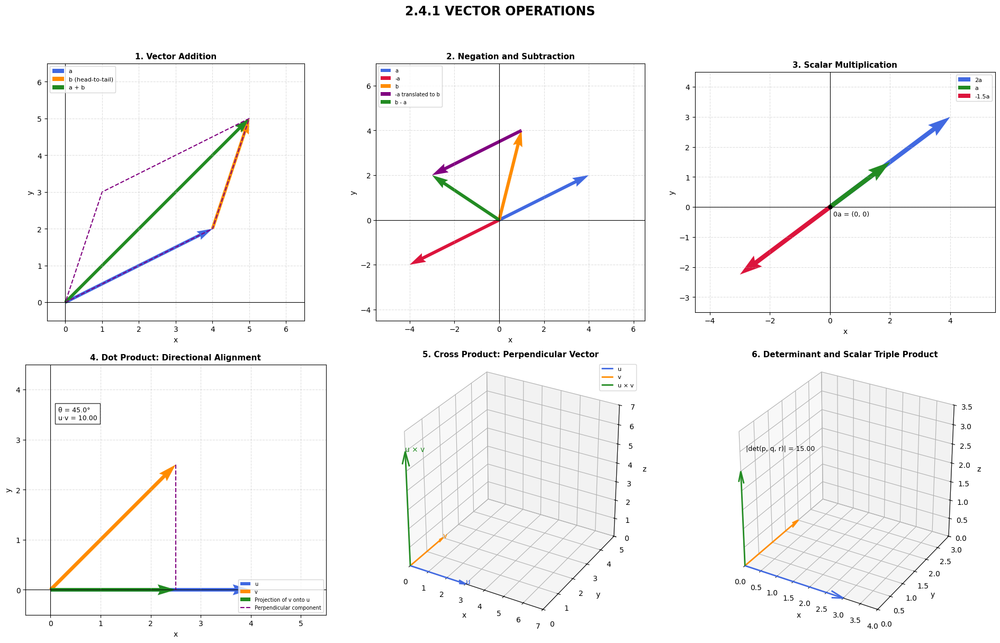

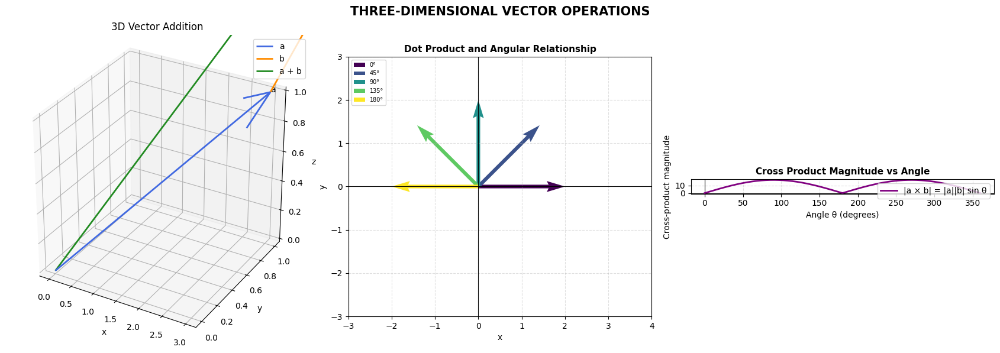

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ============================================================
# 2.4.1 VECTOR OPERATIONS
# Vector addition, negation, subtraction, scalar multiplication,
# dot product, cross product and determinant calculations.
# ============================================================

# ------------------------- Utilities -------------------------

def magnitude(v):
    return np.linalg.norm(v)


def unit_vector(v):
    length = magnitude(v)
    if np.isclose(length, 0.0):
        raise ValueError("The zero vector has no defined direction.")
    return v / length


def vector_add(a, b):
    return a + b


def vector_subtract(a, b):
    return b - a


def scalar_multiply(k, v):
    return k * v


def dot_product(a, b):
    return np.dot(a, b)


def cross_product(a, b):
    return np.cross(a, b)


def vector_angle(a, b):
    denominator = magnitude(a) * magnitude(b)
    if np.isclose(denominator, 0.0):
        raise ValueError("The angle involving a zero vector is undefined.")
    cosine = np.clip(dot_product(a, b) / denominator, -1.0, 1.0)
    return np.arccos(cosine)


def draw_vector_2d(ax, vector, origin=(0, 0), color="blue",
                   label=None, width=0.012, scale=1):
    origin = np.asarray(origin, dtype=float)
    vector = np.asarray(vector, dtype=float)

    ax.quiver(
        origin[0], origin[1],
        vector[0], vector[1],
        angles="xy",
        scale_units="xy",
        scale=scale,
        color=color,
        width=width,
        label=label
    )


def configure_2d_axes(ax, title):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_aspect("equal", adjustable="box")


# ---------------------- Vector definitions -------------------

a = np.array([4.0, 2.0, 1.0])
b = np.array([1.0, 3.0, 2.0])

# Addition
result_ab = vector_add(a, b)
result_ba = vector_add(b, a)

# Negation and subtraction
negative_a = -a
difference_ba = vector_subtract(a, b)

# Scalar multiplication
positive_scaled = scalar_multiply(2, a)
negative_scaled = scalar_multiply(-1.5, a)
zero_scaled = scalar_multiply(0, a)

# Dot and cross products
dot_value = dot_product(a, b)
cross_value = cross_product(a, b)

# Determinant representation of the cross product
cross_determinant = np.linalg.det(
    np.array([
        [1, 0, 0],
        [a[0], a[1], a[2]],
        [b[0], b[1], b[2]]
    ])
)

# Determinant of three vectors
c = np.array([2.0, 1.0, 4.0])
scalar_triple_product = np.linalg.det(
    np.column_stack((a, b, c))
)

# ============================================================
# FIGURE 1: SIX VECTOR OPERATIONS
# ============================================================

fig = plt.figure(figsize=(19, 12))
fig.suptitle(
    "2.4.1 VECTOR OPERATIONS",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

# ------------------------------------------------------------
# 1. VECTOR ADDITION: HEAD-TO-TAIL AND PARALLELOGRAM
# ------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)
configure_2d_axes(ax1, "1. Vector Addition")

a2 = np.array([4, 2])
b2 = np.array([1, 3])
r2 = a2 + b2

draw_vector_2d(ax1, a2, color="royalblue", label="a")
draw_vector_2d(ax1, b2, origin=a2, color="darkorange",
               label="b (head-to-tail)")
draw_vector_2d(ax1, r2, color="forestgreen", label="a + b")

# Parallelogram construction
parallelogram = np.array([
    [0, 0],
    a2,
    r2,
    b2
])

ax1.add_patch(
    Polygon(
        parallelogram,
        closed=True,
        fill=False,
        edgecolor="purple",
        linestyle="--",
        linewidth=1.5
    )
)

ax1.set_xlim(-0.5, 6.5)
ax1.set_ylim(-0.5, 6.5)
ax1.legend(fontsize=8, loc="upper left")

# ------------------------------------------------------------
# 2. VECTOR NEGATION AND SUBTRACTION
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)
configure_2d_axes(ax2, "2. Negation and Subtraction")

a2 = np.array([4, 2])
b2 = np.array([1, 4])

negative_a2 = -a2
difference = b2 - a2

draw_vector_2d(ax2, a2, color="royalblue", label="a")
draw_vector_2d(ax2, negative_a2, color="crimson", label="-a")
draw_vector_2d(ax2, b2, color="darkorange", label="b")

# Subtraction: b - a = b + (-a)
draw_vector_2d(
    ax2,
    negative_a2,
    origin=b2,
    color="purple",
    label="-a translated to b"
)

draw_vector_2d(
    ax2,
    difference,
    color="forestgreen",
    label="b - a"
)

ax2.set_xlim(-5.5, 6.5)
ax2.set_ylim(-4.5, 7.0)
ax2.legend(fontsize=7, loc="upper left")

# ------------------------------------------------------------
# 3. SCALAR MULTIPLICATION
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)
configure_2d_axes(ax3, "3. Scalar Multiplication")

base = np.array([2.0, 1.5])

scalars = [
    (2, "2a", "royalblue"),
    (1, "a", "forestgreen"),
    (-1.5, "-1.5a", "crimson")
]

for k, label, color in scalars:
    draw_vector_2d(
        ax3,
        k * base,
        color=color,
        label=label,
        width=0.015
    )

ax3.scatter(0, 0, color="black", s=25, zorder=5)
ax3.text(0.1, -0.3, "0a = (0, 0)", fontsize=9)

ax3.set_xlim(-4.5, 5.5)
ax3.set_ylim(-3.5, 4.5)
ax3.legend(fontsize=8)

# ------------------------------------------------------------
# 4. DOT PRODUCT AND DIRECTIONAL ALIGNMENT
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)
configure_2d_axes(ax4, "4. Dot Product: Directional Alignment")

u = np.array([4.0, 0.0])
v = np.array([2.5, 2.5])

draw_vector_2d(ax4, u, color="royalblue", label="u")
draw_vector_2d(ax4, v, color="darkorange", label="v")

# Projection of v onto u
projection = (np.dot(v, u) / np.dot(u, u)) * u

draw_vector_2d(
    ax4,
    projection,
    color="forestgreen",
    label="Projection of v onto u"
)

ax4.plot(
    [v[0], projection[0]],
    [v[1], projection[1]],
    linestyle="--",
    color="purple",
    label="Perpendicular component"
)

angle = vector_angle(u, v)
ax4.text(
    0.15, 3.4,
    f"θ = {np.degrees(angle):.1f}°\nu·v = {np.dot(u, v):.2f}",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax4.set_xlim(-0.5, 5.5)
ax4.set_ylim(-0.5, 4.5)
ax4.legend(fontsize=7, loc="lower right")

# ------------------------------------------------------------
# 5. CROSS PRODUCT: PERPENDICULAR VECTOR
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5, projection="3d")
ax5.set_title(
    "5. Cross Product: Perpendicular Vector",
    fontsize=11,
    fontweight="bold"
)

u3 = np.array([3.0, 0.0, 0.0])
v3 = np.array([0.0, 2.0, 0.0])
w3 = np.cross(u3, v3)

ax5.quiver(0, 0, 0, *u3, color="royalblue",
           linewidth=2, arrow_length_ratio=0.12, label="u")
ax5.quiver(0, 0, 0, *v3, color="darkorange",
           linewidth=2, arrow_length_ratio=0.12, label="v")
ax5.quiver(0, 0, 0, *w3, color="forestgreen",
           linewidth=2, arrow_length_ratio=0.12, label="u × v")

ax5.text(*u3, "u", color="royalblue")
ax5.text(*v3, "v", color="darkorange")
ax5.text(*w3, "u × v", color="forestgreen")

ax5.set_xlabel("x")
ax5.set_ylabel("y")
ax5.set_zlabel("z")
ax5.set_xlim(0, 7)
ax5.set_ylim(0, 5)
ax5.set_zlim(0, 7)
ax5.set_box_aspect((1, 1, 1))
ax5.legend(fontsize=8)

# ------------------------------------------------------------
# 6. DETERMINANTS AND THREE-DIMENSIONAL VOLUME
# ------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6, projection="3d")
ax6.set_title(
    "6. Determinant and Scalar Triple Product",
    fontsize=11,
    fontweight="bold"
)

p = np.array([3.0, 0.0, 0.0])
q = np.array([0.0, 2.0, 0.0])
r = np.array([0.0, 0.0, 2.5])

vertices = np.array([
    [0, 0, 0],
    p,
    q,
    r
])

ax6.quiver(0, 0, 0, *p, color="royalblue",
           linewidth=2, arrow_length_ratio=0.12)
ax6.quiver(0, 0, 0, *q, color="darkorange",
           linewidth=2, arrow_length_ratio=0.12)
ax6.quiver(0, 0, 0, *r, color="forestgreen",
           linewidth=2, arrow_length_ratio=0.12)

# Parallelepiped volume represented by absolute determinant
volume = abs(np.linalg.det(np.column_stack((p, q, r))))

ax6.text(
    0.1, 0.1, 3.0,
    f"|det(p, q, r)| = {volume:.2f}",
    fontsize=9
)

ax6.set_xlabel("x")
ax6.set_ylabel("y")
ax6.set_zlabel("z")
ax6.set_xlim(0, 4)
ax6.set_ylim(0, 3)
ax6.set_zlim(0, 3.5)
ax6.set_box_aspect((1, 1, 1))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ============================================================
# FIGURE 2: THREE-DIMENSIONAL VECTOR OPERATIONS
# ============================================================

fig2 = plt.figure(figsize=(17, 6))
fig2.suptitle(
    "THREE-DIMENSIONAL VECTOR OPERATIONS",
    fontsize=15,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. THREE-DIMENSIONAL VECTOR ADDITION
# ------------------------------------------------------------

ax7 = fig2.add_subplot(1, 3, 1, projection="3d")
ax7.set_title("3D Vector Addition")

a3 = np.array([3.0, 1.0, 1.0])
b3 = np.array([1.0, 3.0, 2.0])
r3 = a3 + b3

ax7.quiver(0, 0, 0, *a3, color="royalblue",
           linewidth=2, arrow_length_ratio=0.12)
ax7.quiver(*a3, *b3, color="darkorange",
           linewidth=2, arrow_length_ratio=0.12)
ax7.quiver(0, 0, 0, *r3, color="forestgreen",
           linewidth=2, arrow_length_ratio=0.12)

ax7.text(*a3, "a")
ax7.text(*(a3 + b3), "a + b")

ax7.set_xlabel("x")
ax7.set_ylabel("y")
ax7.set_zlabel("z")
ax7.legend(["a", "b", "a + b"])
ax7.set_box_aspect((1, 1, 1))

# ------------------------------------------------------------
# 2. DOT PRODUCT ANGLE COMPARISON
# ------------------------------------------------------------

ax8 = fig2.add_subplot(1, 3, 2)
configure_2d_axes(ax8, "Dot Product and Angular Relationship")

angles = [0, 45, 90, 135, 180]
dot_values = []

reference = np.array([3.0, 0.0])

for degrees in angles:
    radians = np.radians(degrees)
    second = 2 * np.array([np.cos(radians), np.sin(radians)])

    dot_values.append(np.dot(reference, second))

    draw_vector_2d(
        ax8,
        second,
        color=plt.cm.viridis(degrees / 180),
        label=f"{degrees}°"
    )

ax8.set_xlim(-3, 4)
ax8.set_ylim(-3, 3)
ax8.legend(fontsize=7, loc="upper left")

# ------------------------------------------------------------
# 3. CROSS PRODUCT MAGNITUDE AND ORIENTATION
# ------------------------------------------------------------

ax9 = fig2.add_subplot(1, 3, 3)
configure_2d_axes(ax9, "Cross Product Magnitude vs Angle")

theta = np.linspace(0, 2 * np.pi, 500)
cross_magnitude = magnitude(a) * magnitude(b) * np.abs(np.sin(theta))

ax9.plot(
    np.degrees(theta),
    cross_magnitude,
    color="purple",
    linewidth=2,
    label="|a × b| = |a||b| sin θ"
)

ax9.set_xlabel("Angle θ (degrees)")
ax9.set_ylabel("Cross-product magnitude")
ax9.legend()

plt.tight_layout()
plt.show()

# ============================================================
# NUMERICAL RESULTS: AVAILABLE FOR FURTHER COMPUTATION
# No console output is generated.
# ============================================================

vector_results = {
    "vector_a": a,
    "vector_b": b,
    "a_plus_b": result_ab,
    "b_plus_a": result_ba,
    "negative_a": negative_a,
    "b_minus_a": difference_ba,
    "recovered_b": a + difference_ba,
    "positive_scalar_multiple": positive_scaled,
    "negative_scalar_multiple": negative_scaled,
    "zero_scalar_multiple": zero_scaled,
    "magnitude_a": magnitude(a),
    "magnitude_b": magnitude(b),
    "dot_product": dot_value,
    "cross_product": cross_value,
    "cross_product_magnitude": magnitude(cross_value),
    "cross_product_determinant_check": cross_determinant,
    "scalar_triple_product": scalar_triple_product,
    "parallelepiped_volume": abs(scalar_triple_product),
    "addition_commutative": np.allclose(result_ab, result_ba),
    "subtraction_recovery": np.allclose(a + difference_ba, b),
    "cross_product_perpendicular_to_a": np.isclose(
        np.dot(a, cross_value), 0.0
    ),
    "cross_product_perpendicular_to_b": np.isclose(
        np.dot(b, cross_value), 0.0
    )
}

### 2.4.2 Cartesian Coordinates of a Vector

A vector in two-dimensional space is expressed as a linear combination of two nonzero, nonparallel basis vectors. These vectors are linearly independent because neither can be represented as a scalar multiple of the other.

For basis vectors $\mathbf{a}$ and $\mathbf{b}$, any vector $\mathbf{c}$ has a unique representation:

$$
\mathbf{c}=\alpha\mathbf{a}+\beta\mathbf{b}
$$

Here, $\alpha$ and $\beta$ are scalar coefficients determining the vector's components along each basis direction.

An **orthonormal basis** consists of perpendicular unit vectors. In Cartesian coordinates, the standard basis vectors are $\mathbf{x}$ and $\mathbf{y}$:

$$
\mathbf{v}=x\mathbf{x}+y\mathbf{y}
$$

The vector is represented by the ordered pair $(x,y)$ or column matrix:

$$
\mathbf{v}=
\begin{bmatrix}
x\\
y
\end{bmatrix}
$$

Its magnitude is calculated using the Pythagorean theorem:

$$
\|\mathbf{v}\|=\sqrt{x^2+y^2}
$$

This means the length equals the square root of the sum of the squared horizontal and vertical components.

**Worked Example:** For $\mathbf{v}=(3,4)$:

$$
\|\mathbf{v}\|=\sqrt{9+16}=5
$$

In three dimensions, an additional perpendicular unit basis vector $\mathbf{z}$ gives:

$$
\mathbf{v}=(x,y,z)
$$

Cartesian coordinates simplify vector arithmetic, distance calculations, geometric transformations and spatial modelling in computer graphics.

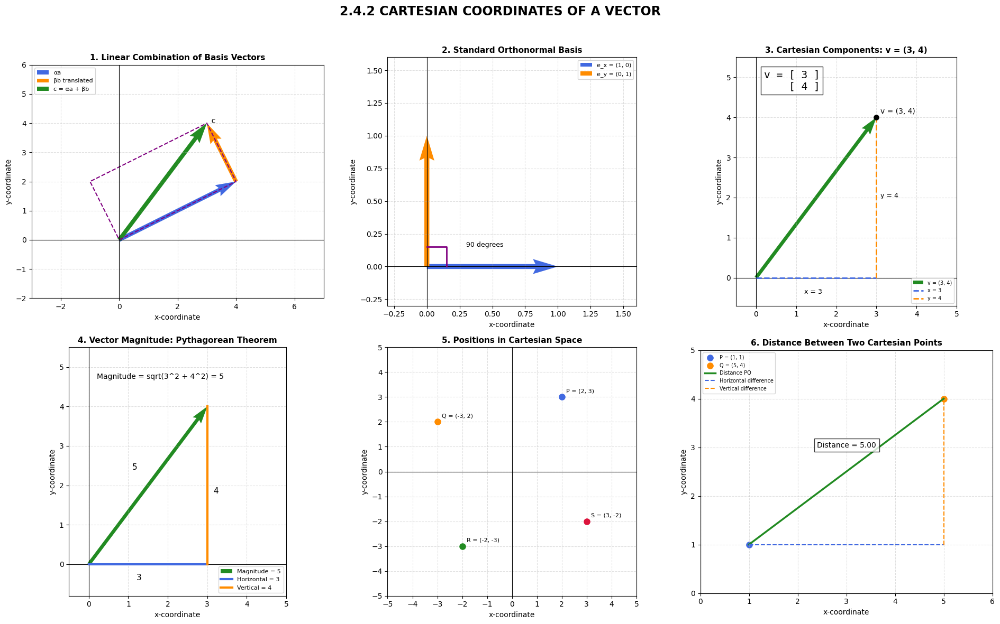

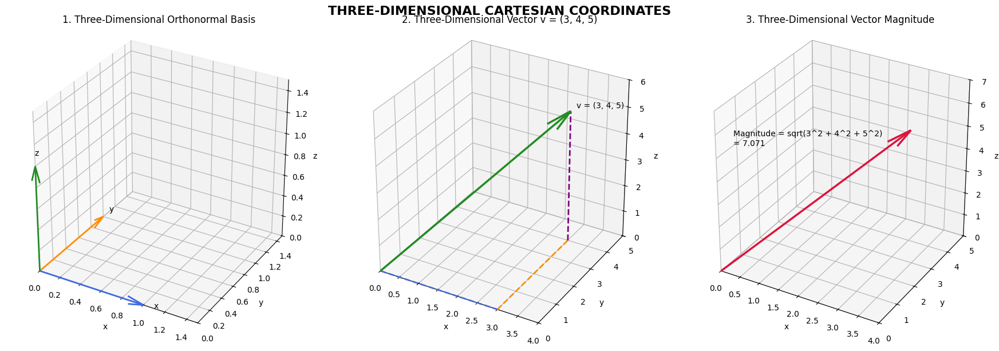

,Quantity,Value
0,Basis determinant,5.0000
1,Linear combination x,3.0000
2,Linear combination y,4.0000
3,Vector x-component,3.0000
4,Vector y-component,4.0000
5,2D vector magnitude,5.0000
6,Distance PQ,5.0000
7,3D vector x-component,3.0000
8,3D vector y-component,4.0000
9,3D vector z-component,5.0000


,Vector v
x-component,3.0
y-component,4.0


,Verification,Result
0,Basis vectors are linearly independent,True
1,Standard basis is orthonormal,True
2,"Magnitude of (3, 4) equals 5",True
3,3D magnitude is correct,True


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import pandas as pd

# ============================================================
# 2.4.2 CARTESIAN COORDINATES OF A VECTOR
# ============================================================

# ------------------------- FUNCTIONS -------------------------

def vector_magnitude(v):
    return np.linalg.norm(v)


def linear_combination(alpha, beta, a, b):
    return alpha * a + beta * b


def cartesian_distance(p, q):
    return np.linalg.norm(np.asarray(q) - np.asarray(p))


def configure_2d(ax, title):
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_aspect("equal", adjustable="box")


def draw_vector(ax, vector, origin=(0, 0), color="blue",
                label=None, width=0.014):
    ax.quiver(
        origin[0], origin[1],
        vector[0], vector[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=width,
        label=label
    )


# ============================================================
# VECTOR DEFINITIONS
# ============================================================

# Standard two-dimensional orthonormal basis
e_x = np.array([1.0, 0.0])
e_y = np.array([0.0, 1.0])

# Independent basis vectors
basis_a = np.array([2.0, 1.0])
basis_b = np.array([-1.0, 2.0])

# Scalar coefficients
alpha = 2
beta = 1

# Cartesian vector
v = np.array([3.0, 4.0])

# Linear combination
alpha_a = alpha * basis_a
beta_b = beta * basis_b
c = linear_combination(alpha, beta, basis_a, basis_b)

# Vector magnitude
magnitude_2d = vector_magnitude(v)

# Column matrix representation
v_column = v.reshape(2, 1)

# Linear independence determinant
basis_determinant = np.linalg.det(
    np.column_stack((basis_a, basis_b))
)

# Distance between two points
P = np.array([1.0, 1.0])
Q = np.array([5.0, 4.0])

displacement = Q - P
distance = cartesian_distance(P, Q)

# Three-dimensional Cartesian vector
v3 = np.array([3.0, 4.0, 5.0])
magnitude_3d = vector_magnitude(v3)


# ============================================================
# FIGURE 1: TWO-DIMENSIONAL CARTESIAN COORDINATES
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

fig.suptitle(
    "2.4.2 CARTESIAN COORDINATES OF A VECTOR",
    fontsize=17,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. LINEAR COMBINATION OF INDEPENDENT BASIS VECTORS
# ------------------------------------------------------------

ax = axes[0, 0]
configure_2d(ax, "1. Linear Combination of Basis Vectors")

resultant = alpha_a + beta_b

draw_vector(
    ax, alpha_a,
    color="royalblue",
    label="αa"
)

draw_vector(
    ax, beta_b,
    origin=alpha_a,
    color="darkorange",
    label="βb translated"
)

draw_vector(
    ax, resultant,
    color="forestgreen",
    label="c = αa + βb"
)

parallelogram = np.array([
    [0, 0],
    alpha_a,
    resultant,
    beta_b
])

ax.add_patch(
    Polygon(
        parallelogram,
        closed=True,
        fill=False,
        edgecolor="purple",
        linestyle="--",
        linewidth=1.5
    )
)

ax.text(*resultant, "  c", fontsize=10)

ax.set_xlim(-3, 7)
ax.set_ylim(-2, 6)
ax.legend(fontsize=8, loc="upper left")


# ------------------------------------------------------------
# 2. STANDARD ORTHONORMAL CARTESIAN BASIS
# ------------------------------------------------------------

ax = axes[0, 1]
configure_2d(ax, "2. Standard Orthonormal Basis")

draw_vector(
    ax, e_x,
    color="royalblue",
    label="e_x = (1, 0)",
    width=0.02
)

draw_vector(
    ax, e_y,
    color="darkorange",
    label="e_y = (0, 1)",
    width=0.02
)

ax.plot(
    [0.15, 0.15, 0],
    [0, 0.15, 0.15],
    color="purple",
    linewidth=2
)

ax.text(0.3, 0.15, "90 degrees", fontsize=9)

ax.set_xlim(-0.3, 1.6)
ax.set_ylim(-0.3, 1.6)
ax.legend(fontsize=8)


# ------------------------------------------------------------
# 3. CARTESIAN COMPONENTS AND COLUMN MATRIX
# ------------------------------------------------------------

ax = axes[0, 2]
configure_2d(ax, "3. Cartesian Components: v = (3, 4)")

draw_vector(
    ax, v,
    color="forestgreen",
    label="v = (3, 4)",
    width=0.016
)

ax.plot(
    [0, 3], [0, 0],
    "--",
    color="royalblue",
    linewidth=2,
    label="x = 3"
)

ax.plot(
    [3, 3], [0, 4],
    "--",
    color="darkorange",
    linewidth=2,
    label="y = 4"
)

ax.scatter(3, 4, color="black", s=45, zorder=5)

ax.text(3.1, 4.1, "v = (3, 4)", fontsize=10)
ax.text(1.2, -0.4, "x = 3", fontsize=9)
ax.text(3.1, 2, "y = 4", fontsize=9)

# Plain-text column matrix: no LaTeX parsing required
ax.text(
    0.2, 4.7,
    "v = [ 3 ]\n    [ 4 ]",
    fontsize=14,
    family="monospace",
    bbox=dict(facecolor="white", alpha=0.8)
)

ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.7, 5.5)
ax.legend(fontsize=7, loc="lower right")


# ------------------------------------------------------------
# 4. VECTOR MAGNITUDE AND PYTHAGOREAN THEOREM
# ------------------------------------------------------------

ax = axes[1, 0]
configure_2d(ax, "4. Vector Magnitude: Pythagorean Theorem")

draw_vector(
    ax, v,
    color="forestgreen",
    label="Magnitude = 5",
    width=0.016
)

ax.plot(
    [0, 3], [0, 0],
    color="royalblue",
    linewidth=3,
    label="Horizontal = 3"
)

ax.plot(
    [3, 3], [0, 4],
    color="darkorange",
    linewidth=3,
    label="Vertical = 4"
)

ax.text(1.2, -0.4, "3", fontsize=11)
ax.text(3.15, 1.8, "4", fontsize=11)
ax.text(1.1, 2.4, "5", fontsize=11)

ax.text(
    0.2, 4.7,
    "Magnitude = sqrt(3^2 + 4^2) = 5",
    fontsize=10
)

ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.8, 5.5)
ax.legend(fontsize=8)


# ------------------------------------------------------------
# 5. TWO-DIMENSIONAL CARTESIAN SPACE
# ------------------------------------------------------------

ax = axes[1, 1]
configure_2d(ax, "5. Positions in Cartesian Space")

coordinates = [
    (2, 3, "P = (2, 3)", "royalblue"),
    (-3, 2, "Q = (-3, 2)", "darkorange"),
    (-2, -3, "R = (-2, -3)", "forestgreen"),
    (3, -2, "S = (3, -2)", "crimson")
]

for x, y, label, color in coordinates:
    ax.scatter(x, y, s=65, color=color, zorder=5)
    ax.annotate(
        label,
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_xticks(np.arange(-5, 6, 1))
ax.set_yticks(np.arange(-5, 6, 1))


# ------------------------------------------------------------
# 6. CARTESIAN DISTANCE BETWEEN TWO POINTS
# ------------------------------------------------------------

ax = axes[1, 2]
configure_2d(ax, "6. Distance Between Two Cartesian Points")

ax.scatter(*P, color="royalblue", s=65, label="P = (1, 1)")
ax.scatter(*Q, color="darkorange", s=65, label="Q = (5, 4)")

ax.plot(
    [P[0], Q[0]],
    [P[1], Q[1]],
    color="forestgreen",
    linewidth=2.5,
    label="Distance PQ"
)

ax.plot(
    [P[0], Q[0]],
    [P[1], P[1]],
    "--",
    color="royalblue",
    label="Horizontal difference"
)

ax.plot(
    [Q[0], Q[0]],
    [P[1], Q[1]],
    "--",
    color="darkorange",
    label="Vertical difference"
)

ax.text(
    2.4, 3.0,
    f"Distance = {distance:.2f}",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax.set_xlim(0, 6)
ax.set_ylim(0, 5)
ax.legend(fontsize=7, loc="upper left")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# FIGURE 2: THREE-DIMENSIONAL CARTESIAN COORDINATES
# ============================================================

fig2 = plt.figure(figsize=(18, 6))

fig2.suptitle(
    "THREE-DIMENSIONAL CARTESIAN COORDINATES",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# 1. THREE-DIMENSIONAL ORTHONORMAL BASIS
# ------------------------------------------------------------

ax1 = fig2.add_subplot(1, 3, 1, projection="3d")
ax1.set_title("1. Three-Dimensional Orthonormal Basis")

e_x3 = np.array([1, 0, 0])
e_y3 = np.array([0, 1, 0])
e_z3 = np.array([0, 0, 1])

ax1.quiver(
    0, 0, 0, *e_x3,
    color="royalblue",
    linewidth=2,
    arrow_length_ratio=0.15
)

ax1.quiver(
    0, 0, 0, *e_y3,
    color="darkorange",
    linewidth=2,
    arrow_length_ratio=0.15
)

ax1.quiver(
    0, 0, 0, *e_z3,
    color="forestgreen",
    linewidth=2,
    arrow_length_ratio=0.15
)

ax1.text(1.1, 0, 0, "x")
ax1.text(0, 1.1, 0, "y")
ax1.text(0, 0, 1.1, "z")

ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")

ax1.set_xlim(0, 1.5)
ax1.set_ylim(0, 1.5)
ax1.set_zlim(0, 1.5)
ax1.set_box_aspect((1, 1, 1))


# ------------------------------------------------------------
# 2. THREE-DIMENSIONAL VECTOR COMPONENTS
# ------------------------------------------------------------

ax2 = fig2.add_subplot(1, 3, 2, projection="3d")
ax2.set_title("2. Three-Dimensional Vector v = (3, 4, 5)")

ax2.quiver(
    0, 0, 0, *v3,
    color="forestgreen",
    linewidth=2.5,
    arrow_length_ratio=0.1
)

# Component projection guides
ax2.plot(
    [0, 3], [0, 0], [0, 0],
    "--", color="royalblue", linewidth=2
)

ax2.plot(
    [3, 3], [0, 4], [0, 0],
    "--", color="darkorange", linewidth=2
)

ax2.plot(
    [3, 3], [4, 4], [0, 5],
    "--", color="purple", linewidth=2
)

ax2.text(3.1, 4.1, 5.1, "v = (3, 4, 5)")

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")

ax2.set_xlim(0, 4)
ax2.set_ylim(0, 5)
ax2.set_zlim(0, 6)
ax2.set_box_aspect((1, 1, 1))


# ------------------------------------------------------------
# 3. THREE-DIMENSIONAL VECTOR MAGNITUDE
# ------------------------------------------------------------

ax3 = fig2.add_subplot(1, 3, 3, projection="3d")
ax3.set_title("3. Three-Dimensional Vector Magnitude")

ax3.quiver(
    0, 0, 0, *v3,
    color="crimson",
    linewidth=2.5,
    arrow_length_ratio=0.1
)

ax3.text(
    0.3, 0.3, 5.5,
    f"Magnitude = sqrt(3^2 + 4^2 + 5^2)\n= {magnitude_3d:.3f}",
    fontsize=10
)

ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_zlabel("z")

ax3.set_xlim(0, 4)
ax3.set_ylim(0, 5)
ax3.set_zlim(0, 7)
ax3.set_box_aspect((1, 1, 1))

plt.tight_layout()
plt.show()


# ============================================================
# NUMERICAL OUTPUT TABLE
# ============================================================

results = pd.DataFrame({
    "Quantity": [
        "Basis determinant",
        "Linear combination x",
        "Linear combination y",
        "Vector x-component",
        "Vector y-component",
        "2D vector magnitude",
        "Distance PQ",
        "3D vector x-component",
        "3D vector y-component",
        "3D vector z-component",
        "3D vector magnitude"
    ],
    "Value": [
        basis_determinant,
        c[0],
        c[1],
        v[0],
        v[1],
        magnitude_2d,
        distance,
        v3[0],
        v3[1],
        v3[2],
        magnitude_3d
    ]
})

display(results.style.format({"Value": "{:.4f}"}))


# ============================================================
# COLUMN MATRIX OUTPUT
# ============================================================

column_matrix_output = pd.DataFrame(
    v_column,
    index=["x-component", "y-component"],
    columns=["Vector v"]
)

display(column_matrix_output)


# ============================================================
# NUMERICAL VERIFICATION
# ============================================================

verification = pd.DataFrame({
    "Verification": [
        "Basis vectors are linearly independent",
        "Standard basis is orthonormal",
        "Magnitude of (3, 4) equals 5",
        "3D magnitude is correct"
    ],
    "Result": [
        not np.isclose(basis_determinant, 0),
        np.allclose(
            np.array([e_x, e_y]) @ np.array([e_x, e_y]).T,
            np.eye(2)
        ),
        np.isclose(magnitude_2d, 5),
        np.isclose(magnitude_3d, np.sqrt(50))
    ]
})

display(verification)


### 2.4.3 Dot Product

The **dot product**, also called the scalar product, is a vector operation producing a scalar that measures the relationship between two vectors' magnitudes and directional alignment.

For vectors $\mathbf{a}$ and $\mathbf{b}$, separated by angle $\phi$:

$$
\mathbf{a}\cdot\mathbf{b}
=\|\mathbf{a}\|\|\mathbf{b}\|\cos\phi
$$

This means their dot product equals the product of their magnitudes multiplied by the cosine of the angle between them. Rearranging determines the angle:

$$
\cos\phi=
\frac{\mathbf{a}\cdot\mathbf{b}}
{\|\mathbf{a}\|\|\mathbf{b}\|}
$$

**Geometric Interpretation**

- Positive dot product: the angle is acute, indicating similar directions.
- Zero dot product: the vectors are perpendicular.
- Negative dot product: the angle is obtuse, indicating opposing directional components.

The scalar projection of $\mathbf{a}$ onto $\mathbf{b}$ is:

$$
\operatorname{proj}_{\mathbf{b}}(\mathbf{a})
=\frac{\mathbf{a}\cdot\mathbf{b}}{\|\mathbf{b}\|}
$$

This measures the signed length of $\mathbf{a}$ along the direction of $\mathbf{b}$.

**Cartesian Representation**

For two-dimensional vectors:

$$
\mathbf{a}\cdot\mathbf{b}=a_xb_x+a_yb_y
$$

In three dimensions:

$$
\mathbf{a}\cdot\mathbf{b}
=a_xb_x+a_yb_y+a_zb_z
$$

**Worked Example:** Given $\mathbf{a}=(2,3)$ and $\mathbf{b}=(4,1)$:

$$
\mathbf{a}\cdot\mathbf{b}=8+3=11
$$

The dot product is commutative and distributive over addition. Its applications include lighting intensity, surface orientation, geometric projection and angle determination in computer graphics.

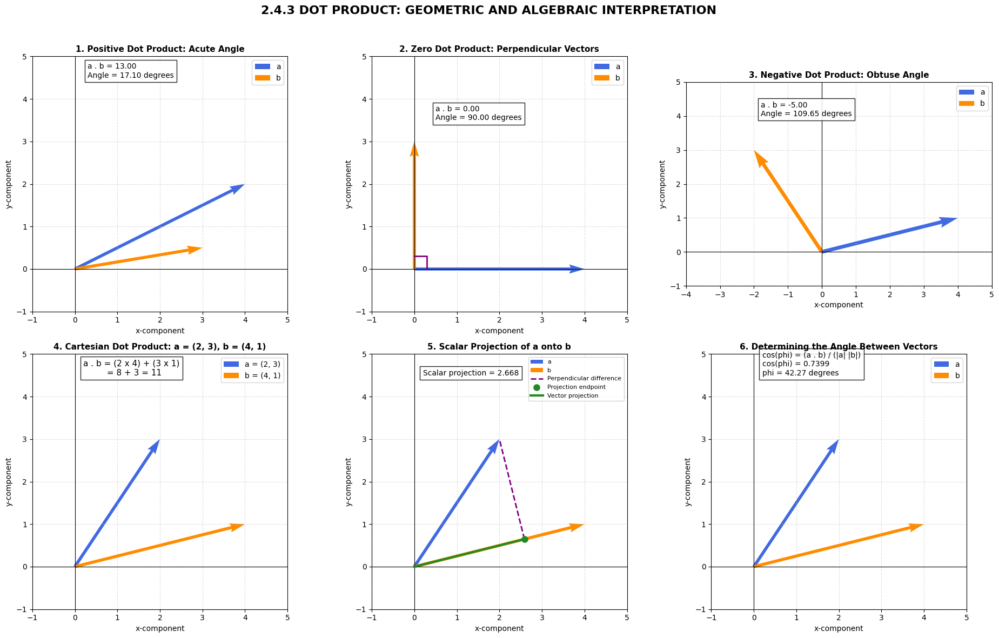

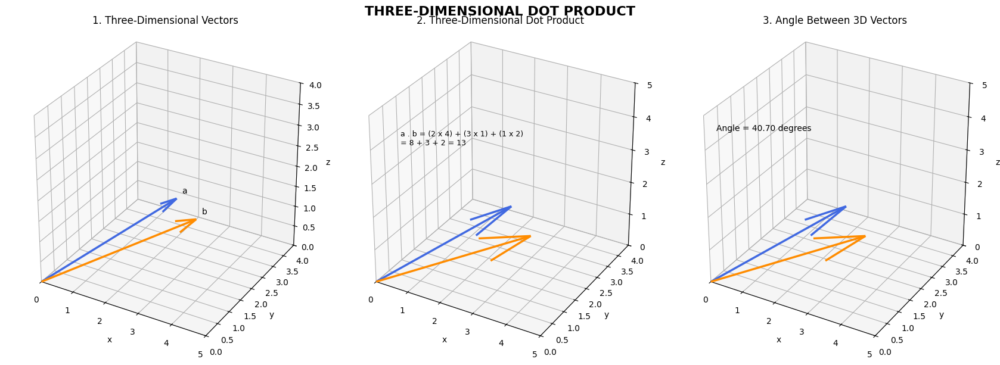

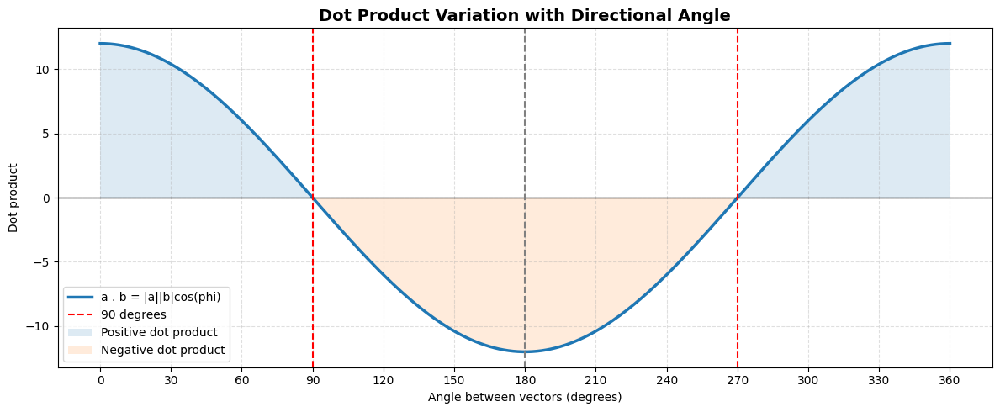

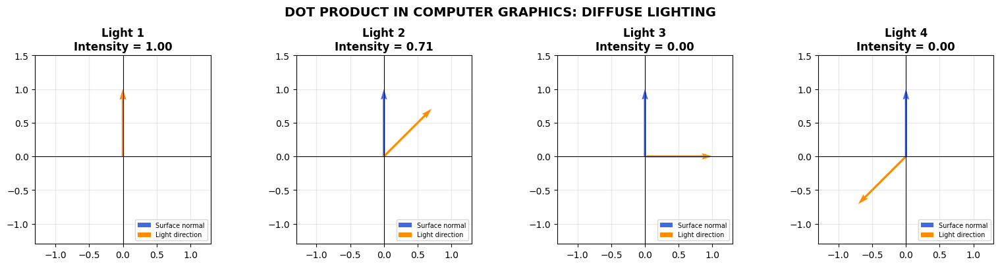

,Quantity,Value
0,Vector a,[2. 3.]
1,Vector b,[4. 1.]
2,Dot product,11.0
3,Magnitude of a,3.605551
4,Magnitude of b,4.123106
5,Cosine of angle,0.73994
6,Angle between vectors (degrees),42.273689
7,Scalar projection of a onto b,2.667892


,Case,Dot Product,Angle (degrees),Interpretation
0,Acute angle,13.000,17.10,Positive: similar directional components
1,Perpendicular vectors,0.000,90.00,Zero: perpendicular vectors
2,Obtuse angle,-5.000,109.65,Negative: opposing directional components


,Property,Left Side,Right Side,Verified
0,Commutative: a . b = b . a,11.0,11.0,True
1,Distributive: a . (w + z) = a . w + a . z,11.0,11.0,True
2,Scalar multiplication: (ka) . b = k(a . b),33.0,33.0,True


,Verification,Result
0,Cartesian dot product equals 11,True
1,Geometric dot product equals 11,True
2,Projection is parallel to b,True
3,3D dot product calculation is correct,True
4,All angle calculations are within 0 to 180 deg...,True


In [29]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.3 DOT PRODUCT (SCALAR PRODUCT)
# ============================================================

# ------------------------- FUNCTIONS -------------------------

def dot_product(a, b):
    return np.dot(a, b)


def vector_magnitude(v):
    return np.linalg.norm(v)


def angle_between_vectors(a, b):
    denominator = vector_magnitude(a) * vector_magnitude(b)

    if np.isclose(denominator, 0):
        return np.nan

    cosine = np.dot(a, b) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


def scalar_projection(a, b):
    magnitude_b = vector_magnitude(b)

    if np.isclose(magnitude_b, 0):
        return np.nan

    return np.dot(a, b) / magnitude_b


def vector_projection(a, b):
    denominator = np.dot(b, b)

    if np.isclose(denominator, 0):
        return np.zeros_like(a, dtype=float)

    return (np.dot(a, b) / denominator) * b


def draw_vector(ax, v, color, label, origin=(0, 0)):
    ax.quiver(
        origin[0], origin[1],
        v[0], v[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.012,
        label=label
    )


def configure_axes(ax, title):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("x-component")
    ax.set_ylabel("y-component")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_aspect("equal", adjustable="box")


# ============================================================
# WORKED EXAMPLE
# ============================================================

a = np.array([2.0, 3.0])
b = np.array([4.0, 1.0])

dot_ab = dot_product(a, b)
magnitude_a = vector_magnitude(a)
magnitude_b = vector_magnitude(b)

angle_ab = angle_between_vectors(a, b)

cosine_angle = dot_ab / (magnitude_a * magnitude_b)

projection_scalar = scalar_projection(a, b)
projection_vector = vector_projection(a, b)

# ============================================================
# FIGURE 1: GEOMETRIC INTERPRETATION OF DOT PRODUCT
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

fig.suptitle(
    "2.4.3 DOT PRODUCT: GEOMETRIC AND ALGEBRAIC INTERPRETATION",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. POSITIVE DOT PRODUCT: ACUTE ANGLE
# ------------------------------------------------------------

ax = axes[0, 0]
configure_axes(ax, "1. Positive Dot Product: Acute Angle")

a1 = np.array([4.0, 2.0])
b1 = np.array([3.0, 0.5])

d1 = dot_product(a1, b1)
theta1 = angle_between_vectors(a1, b1)

draw_vector(ax, a1, "royalblue", "a")
draw_vector(ax, b1, "darkorange", "b")

ax.text(
    0.3, 4.5,
    f"a . b = {d1:.2f}\nAngle = {theta1:.2f} degrees",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.legend()


# ------------------------------------------------------------
# 2. ZERO DOT PRODUCT: PERPENDICULAR VECTORS
# ------------------------------------------------------------

ax = axes[0, 1]
configure_axes(ax, "2. Zero Dot Product: Perpendicular Vectors")

a2 = np.array([4.0, 0.0])
b2 = np.array([0.0, 3.0])

d2 = dot_product(a2, b2)
theta2 = angle_between_vectors(a2, b2)

draw_vector(ax, a2, "royalblue", "a")
draw_vector(ax, b2, "darkorange", "b")

ax.plot(
    [0.3, 0.3, 0],
    [0, 0.3, 0.3],
    color="purple",
    linewidth=2
)

ax.text(
    0.5, 3.5,
    f"a . b = {d2:.2f}\nAngle = {theta2:.2f} degrees",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.legend()


# ------------------------------------------------------------
# 3. NEGATIVE DOT PRODUCT: OBTUSE ANGLE
# ------------------------------------------------------------

ax = axes[0, 2]
configure_axes(ax, "3. Negative Dot Product: Obtuse Angle")

a3 = np.array([4.0, 1.0])
b3 = np.array([-2.0, 3.0])

d3 = dot_product(a3, b3)
theta3 = angle_between_vectors(a3, b3)

draw_vector(ax, a3, "royalblue", "a")
draw_vector(ax, b3, "darkorange", "b")

ax.text(
    -1.8, 4.0,
    f"a . b = {d3:.2f}\nAngle = {theta3:.2f} degrees",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-4, 5)
ax.set_ylim(-1, 5)
ax.legend()


# ------------------------------------------------------------
# 4. CARTESIAN DOT PRODUCT: WORKED EXAMPLE
# ------------------------------------------------------------

ax = axes[1, 0]
configure_axes(ax, "4. Cartesian Dot Product: a = (2, 3), b = (4, 1)")

draw_vector(ax, a, "royalblue", "a = (2, 3)")
draw_vector(ax, b, "darkorange", "b = (4, 1)")

ax.text(
    0.2, 4.5,
    "a . b = (2 x 4) + (3 x 1)\n"
    f"         = 8 + 3 = {dot_ab:.0f}",
    fontsize=11,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.legend()


# ------------------------------------------------------------
# 5. SCALAR PROJECTION OF a ONTO b
# ------------------------------------------------------------

ax = axes[1, 1]
configure_axes(ax, "5. Scalar Projection of a onto b")

draw_vector(ax, a, "royalblue", "a")
draw_vector(ax, b, "darkorange", "b")

# Projection of a onto b
ax.plot(
    [projection_vector[0], a[0]],
    [projection_vector[1], a[1]],
    "--",
    color="purple",
    linewidth=2,
    label="Perpendicular difference"
)

ax.scatter(
    *projection_vector,
    color="forestgreen",
    s=65,
    zorder=5,
    label="Projection endpoint"
)

ax.plot(
    [0, projection_vector[0]],
    [0, projection_vector[1]],
    color="forestgreen",
    linewidth=3,
    label="Vector projection"
)

ax.text(
    0.2, 4.5,
    f"Scalar projection = {projection_scalar:.3f}",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.legend(fontsize=8)


# ------------------------------------------------------------
# 6. ANGLE DETERMINATION
# ------------------------------------------------------------

ax = axes[1, 2]
configure_axes(ax, "6. Determining the Angle Between Vectors")

draw_vector(ax, a, "royalblue", "a")
draw_vector(ax, b, "darkorange", "b")

ax.text(
    0.2, 4.5,
    "cos(phi) = (a . b) / (|a| |b|)\n"
    f"cos(phi) = {cosine_angle:.4f}\n"
    f"phi = {angle_ab:.2f} degrees",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# FIGURE 2: THREE-DIMENSIONAL DOT PRODUCT
# ============================================================

fig2 = plt.figure(figsize=(17, 6))

fig2.suptitle(
    "THREE-DIMENSIONAL DOT PRODUCT",
    fontsize=16,
    fontweight="bold"
)

# Three-dimensional vectors
a3d = np.array([2.0, 3.0, 1.0])
b3d = np.array([4.0, 1.0, 2.0])

dot_3d = dot_product(a3d, b3d)
angle_3d = angle_between_vectors(a3d, b3d)


# ------------------------------------------------------------
# 1. THREE-DIMENSIONAL VECTOR GEOMETRY
# ------------------------------------------------------------

ax1 = fig2.add_subplot(1, 3, 1, projection="3d")

ax1.set_title("1. Three-Dimensional Vectors")

ax1.quiver(
    0, 0, 0, *a3d,
    color="royalblue",
    linewidth=2.5,
    arrow_length_ratio=0.12
)

ax1.quiver(
    0, 0, 0, *b3d,
    color="darkorange",
    linewidth=2.5,
    arrow_length_ratio=0.12
)

ax1.text(2.1, 3.1, 1.1, "a")
ax1.text(4.1, 1.1, 2.1, "b")

ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")

ax1.set_xlim(0, 5)
ax1.set_ylim(0, 4)
ax1.set_zlim(0, 4)
ax1.set_box_aspect((1, 1, 1))


# ------------------------------------------------------------
# 2. THREE-DIMENSIONAL DOT PRODUCT
# ------------------------------------------------------------

ax2 = fig2.add_subplot(1, 3, 2, projection="3d")

ax2.set_title("2. Three-Dimensional Dot Product")

ax2.quiver(
    0, 0, 0, *a3d,
    color="royalblue",
    linewidth=2.5
)

ax2.quiver(
    0, 0, 0, *b3d,
    color="darkorange",
    linewidth=2.5
)

ax2.text(
    0.5, 0.5, 4.0,
    "a . b = (2 x 4) + (3 x 1) + (1 x 2)\n"
    f"= 8 + 3 + 2 = {dot_3d:.0f}",
    fontsize=9
)

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")

ax2.set_xlim(0, 5)
ax2.set_ylim(0, 4)
ax2.set_zlim(0, 5)
ax2.set_box_aspect((1, 1, 1))


# ------------------------------------------------------------
# 3. THREE-DIMENSIONAL ANGLE
# ------------------------------------------------------------

ax3 = fig2.add_subplot(1, 3, 3, projection="3d")

ax3.set_title("3. Angle Between 3D Vectors")

ax3.quiver(
    0, 0, 0, *a3d,
    color="royalblue",
    linewidth=2.5
)

ax3.quiver(
    0, 0, 0, *b3d,
    color="darkorange",
    linewidth=2.5
)

ax3.text(
    0.2, 0.2, 4.5,
    f"Angle = {angle_3d:.2f} degrees",
    fontsize=10
)

ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_zlabel("z")

ax3.set_xlim(0, 5)
ax3.set_ylim(0, 4)
ax3.set_zlim(0, 5)
ax3.set_box_aspect((1, 1, 1))

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 3: DOT PRODUCT AND DIRECTIONAL ALIGNMENT
# ============================================================

angles = np.linspace(0, 360, 361)

# Keep vector magnitudes fixed
magnitude_fixed_a = 4
magnitude_fixed_b = 3

dot_values = (
    magnitude_fixed_a *
    magnitude_fixed_b *
    np.cos(np.radians(angles))
)

fig3, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    angles,
    dot_values,
    linewidth=2.5,
    label="a . b = |a||b|cos(phi)"
)

ax.axhline(0, color="black", linewidth=1)
ax.axvline(90, color="red", linestyle="--", label="90 degrees")
ax.axvline(180, color="gray", linestyle="--")
ax.axvline(270, color="red", linestyle="--")

ax.fill_between(
    angles,
    dot_values,
    0,
    where=(dot_values > 0),
    alpha=0.15,
    label="Positive dot product"
)

ax.fill_between(
    angles,
    dot_values,
    0,
    where=(dot_values < 0),
    alpha=0.15,
    label="Negative dot product"
)

ax.set_title(
    "Dot Product Variation with Directional Angle",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Angle between vectors (degrees)")
ax.set_ylabel("Dot product")

ax.set_xticks(np.arange(0, 361, 30))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 4: COMPUTER GRAPHICS LIGHTING APPLICATION
# ============================================================

# Surface normal vector
normal = np.array([0.0, 1.0])

# Light direction vectors
light_directions = [
    np.array([0.0, 1.0]),
    np.array([1.0, 1.0]) / np.sqrt(2),
    np.array([1.0, 0.0]),
    np.array([-1.0, -1.0]) / np.sqrt(2)
]

lighting_values = [
    max(0.0, np.dot(normal, light))
    for light in light_directions
]

fig4, axes4 = plt.subplots(1, 4, figsize=(16, 4))

fig4.suptitle(
    "DOT PRODUCT IN COMPUTER GRAPHICS: DIFFUSE LIGHTING",
    fontsize=14,
    fontweight="bold"
)

for i, (ax, light, intensity) in enumerate(
    zip(axes4, light_directions, lighting_values)
):
    ax.set_title(
        f"Light {i + 1}\nIntensity = {intensity:.2f}",
        fontweight="bold"
    )

    draw_vector(
        ax, normal,
        "royalblue",
        "Surface normal"
    )

    draw_vector(
        ax, light,
        "darkorange",
        "Light direction"
    )

    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.5)
    ax.set_aspect("equal")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")

plt.tight_layout()
plt.show()


# ============================================================
# NUMERICAL OUTPUT TABLES
# ============================================================

worked_example = pd.DataFrame({
    "Quantity": [
        "Vector a",
        "Vector b",
        "Dot product",
        "Magnitude of a",
        "Magnitude of b",
        "Cosine of angle",
        "Angle between vectors (degrees)",
        "Scalar projection of a onto b"
    ],
    "Value": [
        str(a),
        str(b),
        dot_ab,
        magnitude_a,
        magnitude_b,
        cosine_angle,
        angle_ab,
        projection_scalar
    ]
})

display(worked_example)


# ============================================================
# GEOMETRIC INTERPRETATION TABLE
# ============================================================

geometric_results = pd.DataFrame({
    "Case": [
        "Acute angle",
        "Perpendicular vectors",
        "Obtuse angle"
    ],
    "Dot Product": [
        d1,
        d2,
        d3
    ],
    "Angle (degrees)": [
        theta1,
        theta2,
        theta3
    ],
    "Interpretation": [
        "Positive: similar directional components",
        "Zero: perpendicular vectors",
        "Negative: opposing directional components"
    ]
})

display(
    geometric_results.style.format({
        "Dot Product": "{:.3f}",
        "Angle (degrees)": "{:.2f}"
    })
)


# ============================================================
# ALGEBRAIC PROPERTY VERIFICATION
# ============================================================

u = np.array([1.0, 2.0])
w = np.array([3.0, 4.0])
z = np.array([2.0, -1.0])

k = 3.0

property_results = pd.DataFrame({
    "Property": [
        "Commutative: a . b = b . a",
        "Distributive: a . (w + z) = a . w + a . z",
        "Scalar multiplication: (ka) . b = k(a . b)"
    ],
    "Left Side": [
        dot_product(a, b),
        dot_product(u, w + z),
        dot_product(k * u, w)
    ],
    "Right Side": [
        dot_product(b, a),
        dot_product(u, w) + dot_product(u, z),
        k * dot_product(u, w)
    ],
    "Verified": [
        np.isclose(dot_product(a, b), dot_product(b, a)),
        np.isclose(
            dot_product(u, w + z),
            dot_product(u, w) + dot_product(u, z)
        ),
        np.isclose(
            dot_product(k * u, w),
            k * dot_product(u, w)
        )
    ]
})

display(property_results)


# ============================================================
# NUMERICAL ACCURACY CHECK
# ============================================================

accuracy_results = pd.DataFrame({
    "Verification": [
        "Cartesian dot product equals 11",
        "Geometric dot product equals 11",
        "Projection is parallel to b",
        "3D dot product calculation is correct",
        "All angle calculations are within 0 to 180 degrees"
    ],
    "Result": [
        np.isclose(dot_ab, 11),
        np.isclose(
            dot_ab,
            magnitude_a * magnitude_b *
            np.cos(np.radians(angle_ab))
        ),
        np.allclose(
            np.cross(
                np.append(projection_vector, 0),
                np.append(b, 0)
            ),
            np.zeros(3)
        ),
        np.isclose(dot_3d, 13),
        all(
            0 <= angle <= 180
            for angle in [theta1, theta2, theta3, angle_3d]
        )
    ]
})

display(accuracy_results)


### 2.4.4 Cross Product

The **cross product** is a vector operation defined primarily for three-dimensional vectors. It produces a vector perpendicular to both input vectors, supporting surface orientation, geometric modelling, lighting and spatial transformations.

**1. Mathematical Definition**

For vectors $\mathbf{a}$ and $\mathbf{b}$ separated by angle $\phi$:

$$
\mathbf{a}\times\mathbf{b}
=\|\mathbf{a}\|\|\mathbf{b}\|\sin\phi\,\mathbf{n}
$$

Here, $\mathbf{n}$ is a unit perpendicular vector determined by the right-hand rule. Its magnitude is:

$$
\|\mathbf{a}\times\mathbf{b}\|
=\|\mathbf{a}\|\|\mathbf{b}\|\sin\phi
$$

This magnitude equals the parallelogram's area. The corresponding triangle area is:

$$
A=\frac12\|\mathbf{a}\times\mathbf{b}\|
$$

**2. Cartesian Representation**

For three-dimensional vectors:

$$
\mathbf{a}=(a_x,a_y,a_z),\quad
\mathbf{b}=(b_x,b_y,b_z)
$$

Their cross product is:

$$
\mathbf{a}\times\mathbf{b}
=
\begin{pmatrix}
a_yb_z-a_zb_y\\
a_zb_x-a_xb_z\\
a_xb_y-a_yb_x
\end{pmatrix}
$$

Each component is calculated from the corresponding coordinate products.

**3. Fundamental Properties**

$$
\mathbf{a}\times\mathbf{b}
=-(\mathbf{b}\times\mathbf{a})
$$

$$
\mathbf{a}\times(\mathbf{b}+\mathbf{c})
=\mathbf{a}\times\mathbf{b}+\mathbf{a}\times\mathbf{c}
$$

$$
\mathbf{a}\times(k\mathbf{b})
=k(\mathbf{a}\times\mathbf{b})
$$

$$
\mathbf{a}\times\mathbf{a}=\mathbf{0}
$$

For Cartesian unit vectors:

$$
\mathbf{x}\times\mathbf{y}=\mathbf{z},\quad
\mathbf{y}\times\mathbf{z}=\mathbf{x},\quad
\mathbf{z}\times\mathbf{x}=\mathbf{y}
$$

**4. Example and Applications**

For $\mathbf{a}=(1,2,0)$ and $\mathbf{b}=(3,0,0)$:

$$
\mathbf{a}\times\mathbf{b}=(0,0,-6)
$$

Its magnitude is $6$, giving triangle area $3$ square units. Cross products calculate surface normals, polygon orientation and three-dimensional lighting.

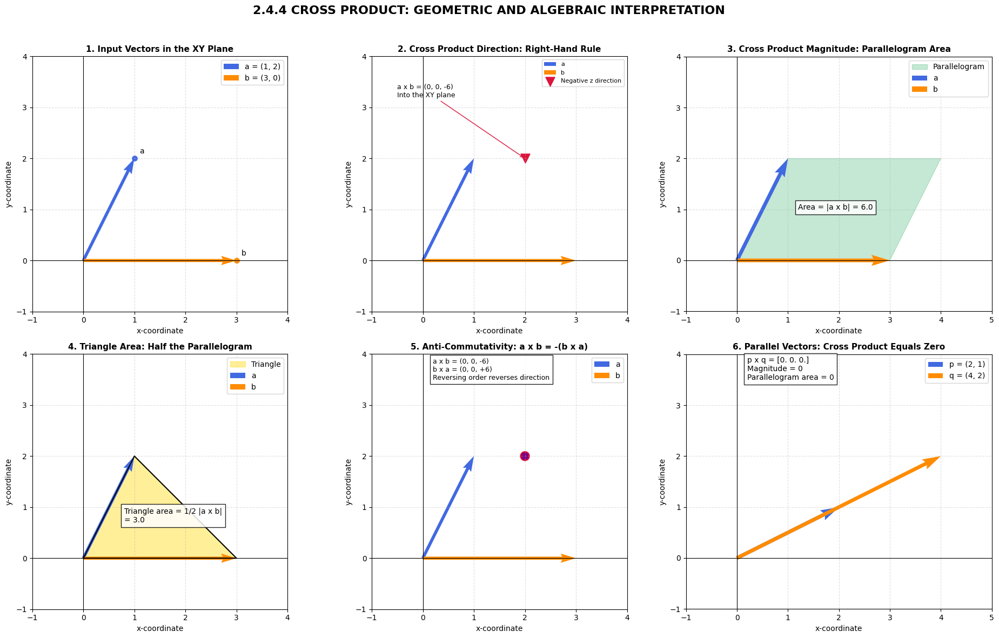

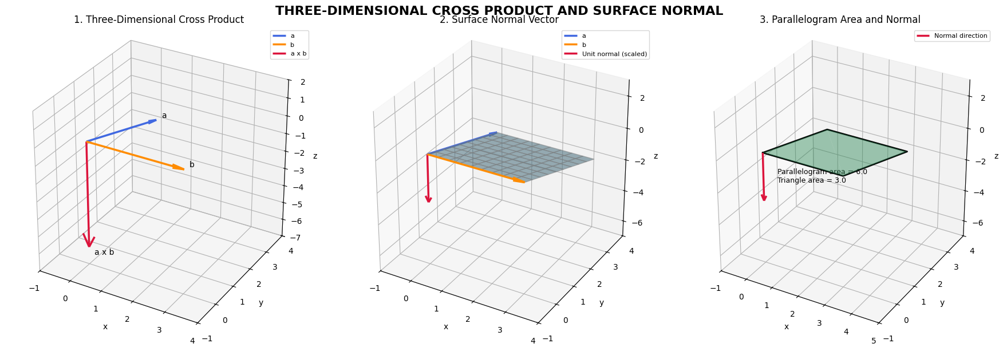

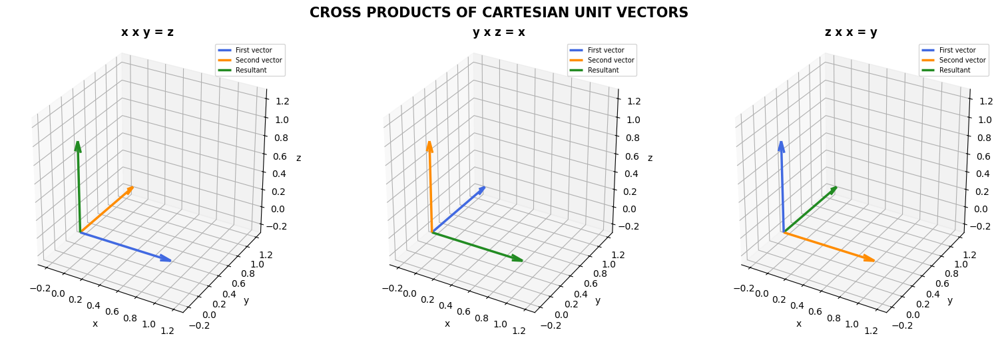

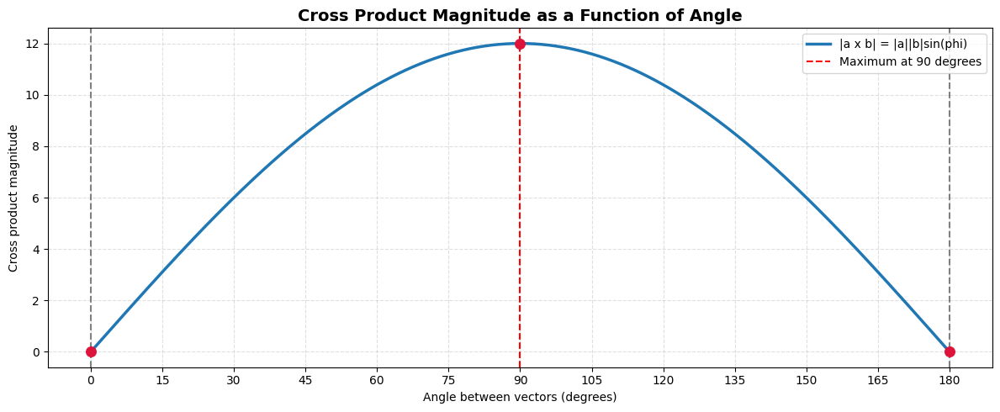

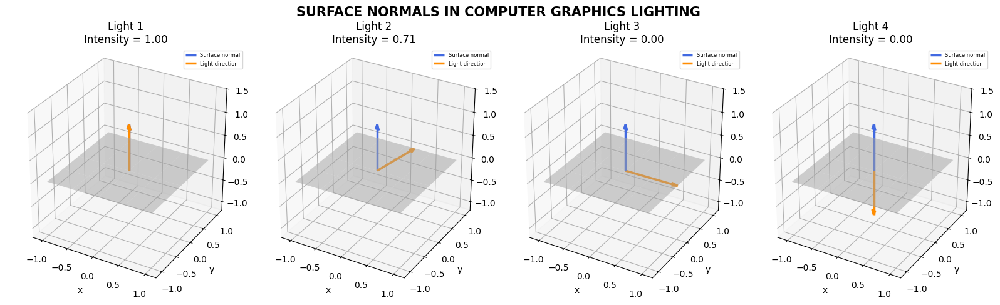

,Quantity,Value
0,Vector a,[1. 2. 0.]
1,Vector b,[3. 0. 0.]
2,Cross product x-component,0.0
3,Cross product y-component,0.0
4,Cross product z-component,-6.0
5,Cross product magnitude,6.0
6,Parallelogram area,6.0
7,Triangle area,3.0
8,Angle between vectors,63.434949
9,Unit surface normal x,0.0


,Property,Left Side,Right Side,Verified
0,Anti-commutativity,"[0.0, 0.0, -6.0]","[-0.0, -0.0, -6.0]",True
1,Distributivity,"[6.0, -3.0, -9.0]","[6.0, -3.0, -9.0]",True
2,Scalar multiplication,"[0.0, 0.0, -18.0]","[0.0, 0.0, -18.0]",True
3,Self cross product,"[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]",True
4,Parallel vectors,"[0.0, 0.0, 0.0]","[0.0, 0.0, 0.0]",True


,Verification,Result
0,"Worked cross product equals (0, 0, -6)",True
1,Cross product magnitude equals 6,True
2,Parallelogram area equals 6,True
3,Triangle area equals 3,True
4,Cross product is perpendicular to a,True
5,Cross product is perpendicular to b,True
6,Surface normal has unit magnitude,True
7,Cross product reverses direction when operands...,True


In [30]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.4 CROSS PRODUCT
# ============================================================

# ------------------------- FUNCTIONS -------------------------

def cross_product(a, b):
    return np.cross(a, b)


def vector_magnitude(v):
    return np.linalg.norm(v)


def angle_between_vectors(a, b):
    denominator = vector_magnitude(a) * vector_magnitude(b)

    if np.isclose(denominator, 0):
        return np.nan

    cosine = np.dot(a, b) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


def parallelogram_area(a, b):
    return vector_magnitude(cross_product(a, b))


def triangle_area(a, b):
    return 0.5 * parallelogram_area(a, b)


def surface_normal(a, b):
    normal = cross_product(a, b)
    magnitude = vector_magnitude(normal)

    if np.isclose(magnitude, 0):
        return np.zeros(3)

    return normal / magnitude


def configure_2d(ax, title):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_aspect("equal", adjustable="box")


def draw_2d_vector(ax, v, color, label, origin=(0, 0)):
    ax.quiver(
        origin[0], origin[1],
        v[0], v[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color=color,
        width=0.012,
        label=label
    )


def draw_3d_vector(ax, v, color, label, origin=(0, 0, 0)):
    ax.quiver(
        origin[0], origin[1], origin[2],
        v[0], v[1], v[2],
        color=color,
        linewidth=2.5,
        arrow_length_ratio=0.12,
        label=label
    )


# ============================================================
# WORKED EXAMPLE
# ============================================================

a = np.array([1.0, 2.0, 0.0])
b = np.array([3.0, 0.0, 0.0])

cross_ab = cross_product(a, b)
cross_ba = cross_product(b, a)

cross_magnitude = vector_magnitude(cross_ab)
area_parallelogram = parallelogram_area(a, b)
area_triangle = triangle_area(a, b)

normal = surface_normal(a, b)
angle_ab = angle_between_vectors(a, b)

# ============================================================
# FIGURE 1: GEOMETRIC INTERPRETATION
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

fig.suptitle(
    "2.4.4 CROSS PRODUCT: GEOMETRIC AND ALGEBRAIC INTERPRETATION",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. TWO VECTORS AND THEIR CROSS PRODUCT
# ------------------------------------------------------------

ax = axes[0, 0]
configure_2d(ax, "1. Input Vectors in the XY Plane")

draw_2d_vector(ax, a[:2], "royalblue", "a = (1, 2)")
draw_2d_vector(ax, b[:2], "darkorange", "b = (3, 0)")

ax.scatter(1, 2, color="royalblue", s=45)
ax.scatter(3, 0, color="darkorange", s=45)

ax.text(1.1, 2.1, "a")
ax.text(3.1, 0.1, "b")

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.legend()


# ------------------------------------------------------------
# 2. CROSS PRODUCT DIRECTION: RIGHT-HAND RULE
# ------------------------------------------------------------

ax = axes[0, 1]
configure_2d(ax, "2. Cross Product Direction: Right-Hand Rule")

draw_2d_vector(ax, a[:2], "royalblue", "a")
draw_2d_vector(ax, b[:2], "darkorange", "b")

# The cross product is along the z-axis.
# For this example, the z-component is negative.
ax.scatter(
    2, 2,
    marker="v",
    s=150,
    color="crimson",
    label="Negative z direction"
)

ax.annotate(
    "a x b = (0, 0, -6)\nInto the XY plane",
    xy=(2, 2),
    xytext=(-0.5, 3.2),
    arrowprops=dict(arrowstyle="->", color="crimson"),
    fontsize=9
)

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.legend(fontsize=8)


# ------------------------------------------------------------
# 3. PARALLELOGRAM AREA
# ------------------------------------------------------------

ax = axes[0, 2]
configure_2d(ax, "3. Cross Product Magnitude: Parallelogram Area")

origin = np.array([0.0, 0.0])
a2 = a[:2]
b2 = b[:2]

parallelogram = np.array([
    origin,
    a2,
    a2 + b2,
    b2
])

ax.fill(
    parallelogram[:, 0],
    parallelogram[:, 1],
    color="mediumseagreen",
    alpha=0.3,
    label="Parallelogram"
)

draw_2d_vector(ax, a2, "royalblue", "a")
draw_2d_vector(ax, b2, "darkorange", "b")

ax.text(
    1.2, 1.0,
    f"Area = |a x b| = {cross_magnitude:.1f}",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 4)
ax.legend()


# ------------------------------------------------------------
# 4. TRIANGLE AREA
# ------------------------------------------------------------

ax = axes[1, 0]
configure_2d(ax, "4. Triangle Area: Half the Parallelogram")

triangle = np.array([
    origin,
    a2,
    b2
])

ax.fill(
    triangle[:, 0],
    triangle[:, 1],
    color="gold",
    alpha=0.4,
    label="Triangle"
)

ax.plot(
    [0, a2[0], b2[0], 0],
    [0, a2[1], b2[1], 0],
    color="black",
    linewidth=1.5
)

draw_2d_vector(ax, a2, "royalblue", "a")
draw_2d_vector(ax, b2, "darkorange", "b")

ax.text(
    0.8, 0.7,
    f"Triangle area = 1/2 |a x b|\n= {area_triangle:.1f}",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.legend()


# ------------------------------------------------------------
# 5. CROSS PRODUCT ANTI-COMMUTATIVITY
# ------------------------------------------------------------

ax = axes[1, 1]
configure_2d(ax, "5. Anti-Commutativity: a x b = -(b x a)")

draw_2d_vector(ax, a[:2], "royalblue", "a")
draw_2d_vector(ax, b[:2], "darkorange", "b")

ax.scatter(
    [2, 2],
    [2, 2],
    marker="o",
    s=[150, 80],
    color=["crimson", "purple"]
)

ax.text(
    0.2, 3.5,
    "a x b = (0, 0, -6)\n"
    "b x a = (0, 0, +6)\n"
    "Reversing order reverses direction",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.legend()


# ------------------------------------------------------------
# 6. ZERO CROSS PRODUCT FOR PARALLEL VECTORS
# ------------------------------------------------------------

ax = axes[1, 2]
configure_2d(ax, "6. Parallel Vectors: Cross Product Equals Zero")

p = np.array([2.0, 1.0])
q = np.array([4.0, 2.0])

draw_2d_vector(ax, p, "royalblue", "p = (2, 1)")
draw_2d_vector(ax, q, "darkorange", "q = (4, 2)")

parallel_cross = np.cross(
    np.append(p, 0),
    np.append(q, 0)
)

ax.text(
    0.2, 3.5,
    f"p x q = {parallel_cross}\n"
    "Magnitude = 0\n"
    "Parallelogram area = 0",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85)
)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 4)
ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# FIGURE 2: THREE-DIMENSIONAL CROSS PRODUCT
# ============================================================

fig2 = plt.figure(figsize=(18, 6))

fig2.suptitle(
    "THREE-DIMENSIONAL CROSS PRODUCT AND SURFACE NORMAL",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. INPUT VECTORS AND CROSS PRODUCT
# ------------------------------------------------------------

ax1 = fig2.add_subplot(1, 3, 1, projection="3d")
ax1.set_title("1. Three-Dimensional Cross Product")

draw_3d_vector(ax1, a, "royalblue", "a")
draw_3d_vector(ax1, b, "darkorange", "b")
draw_3d_vector(ax1, cross_ab, "crimson", "a x b")

ax1.text(1.1, 2.1, 0.1, "a")
ax1.text(3.1, 0.1, 0.1, "b")
ax1.text(0.1, 0.1, -6.5, "a x b")

ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
ax1.set_xlim(-1, 4)
ax1.set_ylim(-1, 4)
ax1.set_zlim(-7, 2)
ax1.set_box_aspect((1, 1, 1))
ax1.legend(fontsize=8)


# ------------------------------------------------------------
# 2. SURFACE NORMAL TO A PLANE
# ------------------------------------------------------------

ax2 = fig2.add_subplot(1, 3, 2, projection="3d")
ax2.set_title("2. Surface Normal Vector")

# Plane defined by vectors a and b
u_values = np.linspace(0, 1, 10)
v_values = np.linspace(0, 1, 10)

U, V = np.meshgrid(u_values, v_values)

X = U * a[0] + V * b[0]
Y = U * a[1] + V * b[1]
Z = U * a[2] + V * b[2]

ax2.plot_surface(
    X, Y, Z,
    color="skyblue",
    alpha=0.55,
    edgecolor="gray"
)

draw_3d_vector(ax2, a, "royalblue", "a")
draw_3d_vector(ax2, b, "darkorange", "b")

# Scale the unit normal for visibility
normal_visual = normal * 3

draw_3d_vector(
    ax2,
    normal_visual,
    "crimson",
    "Unit normal (scaled)"
)

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")
ax2.set_xlim(-1, 4)
ax2.set_ylim(-1, 4)
ax2.set_zlim(-7, 3)
ax2.set_box_aspect((1, 1, 1))
ax2.legend(fontsize=8)


# ------------------------------------------------------------
# 3. THREE-DIMENSIONAL PARALLELOGRAM
# ------------------------------------------------------------

ax3 = fig2.add_subplot(1, 3, 3, projection="3d")
ax3.set_title("3. Parallelogram Area and Normal")

vertices = np.array([
    [0, 0, 0],
    a,
    a + b,
    b
])

ax3.plot(
    vertices[[0, 1, 2, 3, 0], 0],
    vertices[[0, 1, 2, 3, 0], 1],
    vertices[[0, 1, 2, 3, 0], 2],
    color="black",
    linewidth=2
)

ax3.plot_trisurf(
    vertices[:, 0],
    vertices[:, 1],
    vertices[:, 2],
    color="mediumseagreen",
    alpha=0.45
)

draw_3d_vector(
    ax3,
    normal_visual,
    "crimson",
    "Normal direction"
)

ax3.text(
    0.3, 0.3, -2,
    f"Parallelogram area = {area_parallelogram:.1f}\n"
    f"Triangle area = {area_triangle:.1f}",
    fontsize=9
)

ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_zlabel("z")
ax3.set_xlim(-1, 5)
ax3.set_ylim(-1, 4)
ax3.set_zlim(-7, 3)
ax3.set_box_aspect((1, 1, 1))
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 3: CARTESIAN UNIT VECTOR CROSS PRODUCTS
# ============================================================

unit_x = np.array([1.0, 0.0, 0.0])
unit_y = np.array([0.0, 1.0, 0.0])
unit_z = np.array([0.0, 0.0, 1.0])

unit_cross_products = [
    (unit_x, unit_y, "x x y = z"),
    (unit_y, unit_z, "y x z = x"),
    (unit_z, unit_x, "z x x = y")
]

fig3 = plt.figure(figsize=(16, 5))

fig3.suptitle(
    "CROSS PRODUCTS OF CARTESIAN UNIT VECTORS",
    fontsize=15,
    fontweight="bold"
)

for i, (first, second, title) in enumerate(
    unit_cross_products
):
    ax = fig3.add_subplot(1, 3, i + 1, projection="3d")

    result = np.cross(first, second)

    ax.set_title(title, fontweight="bold")

    draw_3d_vector(ax, first, "royalblue", "First vector")
    draw_3d_vector(ax, second, "darkorange", "Second vector")
    draw_3d_vector(ax, result, "forestgreen", "Resultant")

    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-0.3, 1.3)
    ax.set_zlim(-0.3, 1.3)

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_box_aspect((1, 1, 1))
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 4: CROSS PRODUCT MAGNITUDE AND ANGLE
# ============================================================

angles = np.linspace(0, 180, 361)

magnitude_a = 4
magnitude_b = 3

cross_magnitudes = (
    magnitude_a *
    magnitude_b *
    np.sin(np.radians(angles))
)

fig4, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    angles,
    cross_magnitudes,
    linewidth=2.5,
    label="|a x b| = |a||b|sin(phi)"
)

ax.axvline(0, color="gray", linestyle="--")
ax.axvline(90, color="red", linestyle="--", label="Maximum at 90 degrees")
ax.axvline(180, color="gray", linestyle="--")

ax.scatter(
    [0, 90, 180],
    [0, magnitude_a * magnitude_b, 0],
    color="crimson",
    s=70,
    zorder=5
)

ax.set_title(
    "Cross Product Magnitude as a Function of Angle",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Angle between vectors (degrees)")
ax.set_ylabel("Cross product magnitude")
ax.set_xticks(np.arange(0, 181, 15))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 5: SURFACE NORMAL AND DIFFUSE LIGHTING
# ============================================================

# Surface normal points in the positive z-direction
surface_n = np.array([0.0, 0.0, 1.0])

light_directions = [
    np.array([0.0, 0.0, 1.0]),
    np.array([1.0, 0.0, 1.0]) / np.sqrt(2),
    np.array([1.0, 0.0, 0.0]),
    np.array([0.0, 0.0, -1.0])
]

lighting_intensities = [
    max(0.0, np.dot(surface_n, light))
    for light in light_directions
]

fig5 = plt.figure(figsize=(16, 5))

fig5.suptitle(
    "SURFACE NORMALS IN COMPUTER GRAPHICS LIGHTING",
    fontsize=15,
    fontweight="bold"
)

for i, (light, intensity) in enumerate(
    zip(light_directions, lighting_intensities)
):
    ax = fig5.add_subplot(1, 4, i + 1, projection="3d")

    ax.set_title(
        f"Light {i + 1}\nIntensity = {intensity:.2f}"
    )

    # Horizontal surface
    xx, yy = np.meshgrid(
        np.linspace(-1, 1, 5),
        np.linspace(-1, 1, 5)
    )
    zz = np.zeros_like(xx)

    ax.plot_surface(
        xx, yy, zz,
        color="lightgray",
        alpha=0.5
    )

    draw_3d_vector(
        ax, surface_n,
        "royalblue",
        "Surface normal"
    )

    draw_3d_vector(
        ax, light,
        "darkorange",
        "Light direction"
    )

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_zlim(-1.2, 1.5)

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_box_aspect((1, 1, 1))
    ax.legend(fontsize=6)

plt.tight_layout()
plt.show()


# ============================================================
# NUMERICAL OUTPUT: WORKED EXAMPLE
# ============================================================

worked_example = pd.DataFrame({
    "Quantity": [
        "Vector a",
        "Vector b",
        "Cross product x-component",
        "Cross product y-component",
        "Cross product z-component",
        "Cross product magnitude",
        "Parallelogram area",
        "Triangle area",
        "Angle between vectors",
        "Unit surface normal x",
        "Unit surface normal y",
        "Unit surface normal z"
    ],
    "Value": [
        str(a),
        str(b),
        cross_ab[0],
        cross_ab[1],
        cross_ab[2],
        cross_magnitude,
        area_parallelogram,
        area_triangle,
        angle_ab,
        normal[0],
        normal[1],
        normal[2]
    ]
})

display(worked_example)


# ============================================================
# NUMERICAL OUTPUT: CROSS PRODUCT PROPERTIES
# ============================================================

c = np.array([2.0, 1.0, 3.0])
k = 3.0

property_results = pd.DataFrame({
    "Property": [
        "Anti-commutativity",
        "Distributivity",
        "Scalar multiplication",
        "Self cross product",
        "Parallel vectors"
    ],
    "Left Side": [
        np.cross(a, b),
        np.cross(a, b + c),
        np.cross(a, k * b),
        np.cross(a, a),
        np.cross(a, 2 * a)
    ],
    "Right Side": [
        -np.cross(b, a),
        np.cross(a, b) + np.cross(a, c),
        k * np.cross(a, b),
        np.zeros(3),
        np.zeros(3)
    ]
})

property_results["Verified"] = [
    np.allclose(
        np.cross(a, b),
        -np.cross(b, a)
    ),
    np.allclose(
        np.cross(a, b + c),
        np.cross(a, b) + np.cross(a, c)
    ),
    np.allclose(
        np.cross(a, k * b),
        k * np.cross(a, b)
    ),
    np.allclose(
        np.cross(a, a),
        np.zeros(3)
    ),
    np.allclose(
        np.cross(a, 2 * a),
        np.zeros(3)
    )
]

display(property_results)


# ============================================================
# NUMERICAL VERIFICATION
# ============================================================

verification = pd.DataFrame({
    "Verification": [
        "Worked cross product equals (0, 0, -6)",
        "Cross product magnitude equals 6",
        "Parallelogram area equals 6",
        "Triangle area equals 3",
        "Cross product is perpendicular to a",
        "Cross product is perpendicular to b",
        "Surface normal has unit magnitude",
        "Cross product reverses direction when operands are swapped"
    ],
    "Result": [
        np.allclose(cross_ab, [0, 0, -6]),
        np.isclose(cross_magnitude, 6),
        np.isclose(area_parallelogram, 6),
        np.isclose(area_triangle, 3),
        np.isclose(np.dot(cross_ab, a), 0),
        np.isclose(np.dot(cross_ab, b), 0),
        np.isclose(vector_magnitude(normal), 1),
        np.allclose(cross_ab, -cross_ba)
    ]
})

display(verification)


### 2.4.5 Orthonormal Bases and Coordinate Frames

An **orthonormal basis** consists of mutually perpendicular unit vectors defining a coordinate system. In two dimensions, vectors $\mathbf{u}$ and $\mathbf{v}$ satisfy:

$$
\|\mathbf{u}\|=\|\mathbf{v}\|=1,\qquad
\mathbf{u}\cdot\mathbf{v}=0
$$

This means both vectors have unit length and their dot product is zero, indicating perpendicularity.

In three dimensions:

$$
\|\mathbf{u}\|=\|\mathbf{v}\|=\|\mathbf{w}\|=1
$$

$$
\mathbf{u}\cdot\mathbf{v}
=\mathbf{v}\cdot\mathbf{w}
=\mathbf{w}\cdot\mathbf{u}=0
$$

The basis is right-handed when:

$$
\mathbf{w}=\mathbf{u}\times\mathbf{v}
$$

Otherwise, its orientation is left-handed.

A **coordinate frame** comprises an origin $\mathbf{p}$ and an orthonormal basis. Global coordinates provide a common reference, while local frames describe individual objects, cameras and articulated characters.

A vector expressed in local coordinates is:

$$
\mathbf{a}=a_u\mathbf{u}+a_v\mathbf{v}+a_w\mathbf{w}
$$

Its coordinates are recovered using dot products:

$$
a_u=\mathbf{u}\cdot\mathbf{a},\quad
a_v=\mathbf{v}\cdot\mathbf{a},\quad
a_w=\mathbf{w}\cdot\mathbf{a}
$$

For a frame with origin $\mathbf{p}$, a point is:

$$
\mathbf{x}=\mathbf{p}+a_u\mathbf{u}+a_v\mathbf{v}+a_w\mathbf{w}
$$

These relationships enable consistent global-to-local transformations in graphics, camera orientation, animation and robotics.

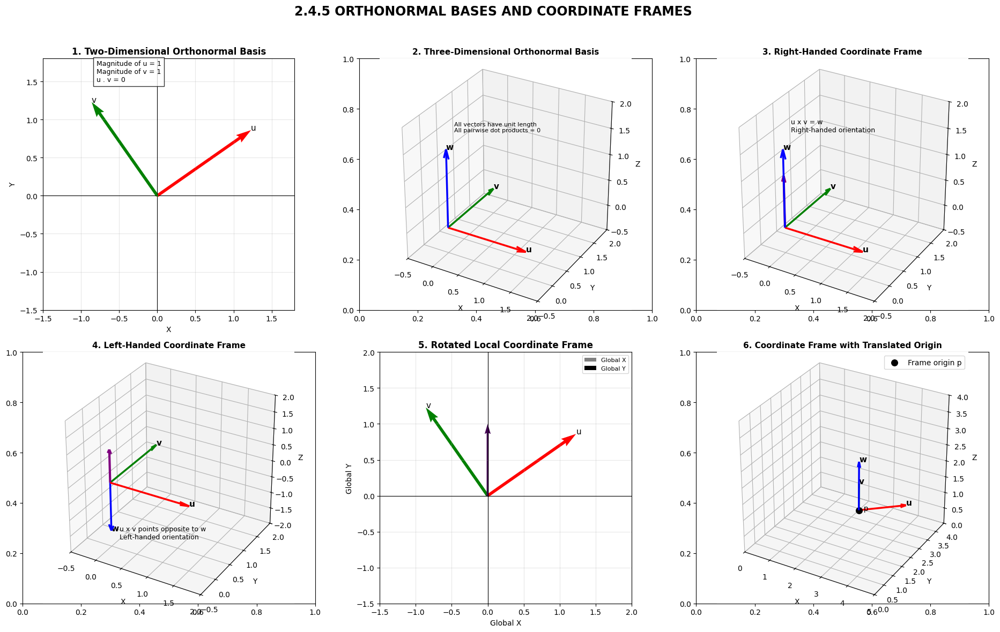

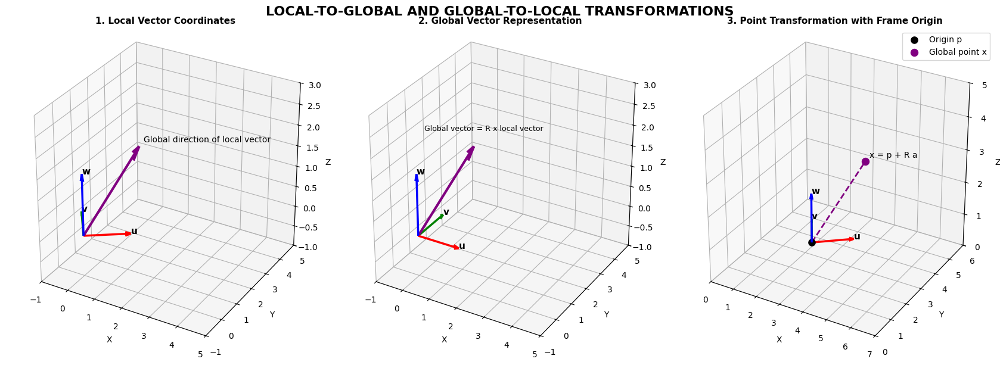

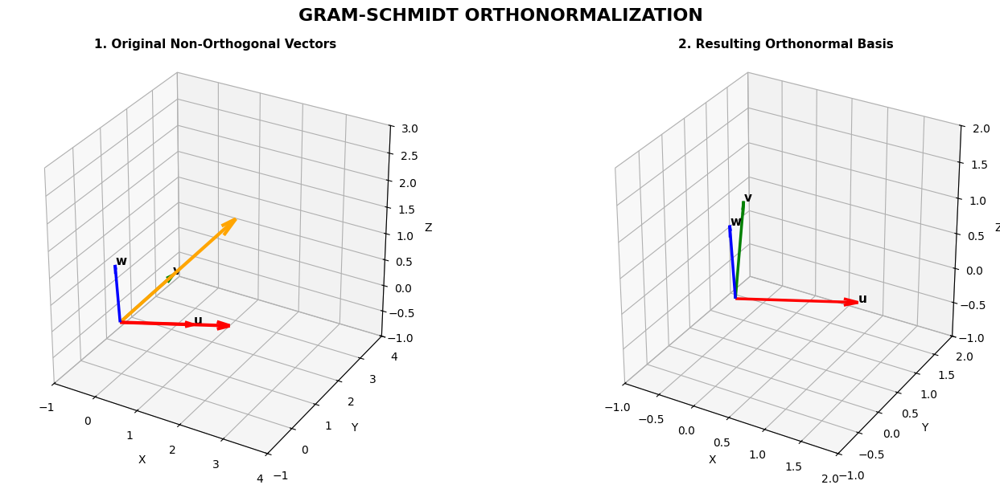

,Basis Vector,x-component,y-component,z-component,Magnitude
0,u,0.8192,0.5736,0.0000,1.0000
1,v,-0.5736,0.8192,0.0000,1.0000
2,w,0.0000,-0.0000,1.0000,1.0000


,Coordinate,Value
0,Local vector x,2.00000
1,Local vector y,3.00000
2,Local vector z,1.00000
3,Global vector X,-0.08243
4,Global vector Y,3.60461
5,Global vector Z,1.00000
6,Recovered local x,2.00000
7,Recovered local y,3.00000
8,Recovered local z,1.00000


,Coordinate,Frame Origin,Local Point,Global Point,Recovered Local Point
0,X,3.0000,2.0000,2.9176,2.0000
1,Y,2.0000,3.0000,5.6046,3.0000
2,Z,1.0000,1.0000,2.0000,1.0000


,Condition,Result
0,Magnitude of u equals 1,True
1,Magnitude of v equals 1,True
2,Magnitude of w equals 1,True
3,u dot v equals zero,True
4,v dot w equals zero,True
5,w dot u equals zero,True
6,u cross v equals w,True
7,Rotation matrix determinant equals +1,True
8,Rotation matrix is orthogonal,True


,Coordinate Frame,Determinant,Orientation,Verified
0,Right-handed,1.0,Positive,True
1,Left-handed,-1.0,Negative,True


,Condition,Value
0,Magnitude of u,1.000000
1,Magnitude of v,1.000000
2,Magnitude of w,1.000000
3,u dot v,0.000000
4,v dot w,0.000000
5,w dot u,0.000000
6,Determinant of orthonormal frame,1.000000


,Verification,Result
0,Local-to-global vector transformation,True
1,Global-to-local vector recovery,True
2,Local-to-global point transformation,True
3,Global-to-local point recovery,True
4,Right-handed frame determinant,True
5,Left-handed frame determinant,True
6,Gram-Schmidt orthonormality,True


In [31]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.5 ORTHONORMAL BASES AND COORDINATE FRAMES
# ============================================================

# ------------------------- FUNCTIONS -------------------------

def magnitude(v):
    return np.linalg.norm(v)


def normalize(v):
    length = magnitude(v)
    if np.isclose(length, 0):
        raise ValueError("A zero vector cannot be normalized.")
    return v / length


def dot(a, b):
    return np.dot(a, b)


def cross(a, b):
    return np.cross(a, b)


def orthonormalize(u, v):
    """Gram-Schmidt orthonormalization."""
    u_hat = normalize(u)
    v_perpendicular = v - dot(v, u_hat) * u_hat
    v_hat = normalize(v_perpendicular)
    w_hat = normalize(cross(u_hat, v_hat))
    return u_hat, v_hat, w_hat


def frame_matrix(u, v, w):
    """Construct a frame rotation matrix using basis vectors as columns."""
    return np.column_stack((u, v, w))


def local_to_global_vector(local, R):
    return R @ local


def global_to_local_vector(global_vector, R):
    return R.T @ global_vector


def local_to_global_point(local_point, origin, R):
    return origin + R @ local_point


def global_to_local_point(global_point, origin, R):
    return R.T @ (global_point - origin)


def draw_3d_frame(ax, origin, R, length=1.5, labels=True):
    colors = ["red", "green", "blue"]
    names = ["u", "v", "w"]

    for i in range(3):
        direction = R[:, i]

        ax.quiver(
            origin[0], origin[1], origin[2],
            direction[0] * length,
            direction[1] * length,
            direction[2] * length,
            color=colors[i],
            linewidth=2.5,
            arrow_length_ratio=0.12
        )

        if labels:
            endpoint = origin + direction * length
            ax.text(
                *endpoint,
                names[i],
                fontsize=11,
                fontweight="bold"
            )


def configure_3d(ax, title):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_box_aspect((1, 1, 1))


def draw_2d_frame(ax, origin, R, length=1.5):
    colors = ["red", "green"]
    names = ["u", "v"]

    for i in range(2):
        direction = R[:, i]

        ax.quiver(
            origin[0], origin[1],
            direction[0] * length,
            direction[1] * length,
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[i],
            width=0.012
        )

        endpoint = origin + direction * length
        ax.text(*endpoint, names[i], fontsize=11)


# ============================================================
# 1. STANDARD ORTHONORMAL BASIS
# ============================================================

# Two-dimensional standard basis
u2 = np.array([1.0, 0.0])
v2 = np.array([0.0, 1.0])

# Three-dimensional standard basis
u3 = np.array([1.0, 0.0, 0.0])
v3 = np.array([0.0, 1.0, 0.0])
w3 = np.array([0.0, 0.0, 1.0])

R_standard = frame_matrix(u3, v3, w3)


# ============================================================
# 2. ROTATED ORTHONORMAL BASIS
# ============================================================

theta = np.radians(35)

R2 = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

u_rotated = R2[:, 0]
v_rotated = R2[:, 1]

# Extend rotated 2D basis into 3D
u_rotated_3d = np.array([
    np.cos(theta),
    np.sin(theta),
    0.0
])

v_rotated_3d = np.array([
    -np.sin(theta),
    np.cos(theta),
    0.0
])

w_rotated_3d = np.cross(
    u_rotated_3d,
    v_rotated_3d
)

R_rotated = frame_matrix(
    u_rotated_3d,
    v_rotated_3d,
    w_rotated_3d
)


# ============================================================
# 3. LEFT-HANDED COORDINATE FRAME
# ============================================================

u_left = np.array([1.0, 0.0, 0.0])
v_left = np.array([0.0, 1.0, 0.0])
w_left = np.array([0.0, 0.0, -1.0])

R_left = frame_matrix(u_left, v_left, w_left)


# ============================================================
# FIGURE 1: ORTHONORMAL BASIS FUNDAMENTALS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

fig.suptitle(
    "2.4.5 ORTHONORMAL BASES AND COORDINATE FRAMES",
    fontsize=17,
    fontweight="bold"
)

# ------------------------------------------------------------
# 1. TWO-DIMENSIONAL ORTHONORMAL BASIS
# ------------------------------------------------------------

ax = axes[0, 0]

ax.set_title(
    "1. Two-Dimensional Orthonormal Basis",
    fontweight="bold"
)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

draw_2d_frame(ax, np.array([0.0, 0.0]), R2)

ax.plot(
    [0, u_rotated[0] * 1.2],
    [0, u_rotated[1] * 1.2],
    color="red",
    linewidth=2
)

ax.plot(
    [0, v_rotated[0] * 1.2],
    [0, v_rotated[1] * 1.2],
    color="green",
    linewidth=2
)

ax.text(
    -0.8, 1.5,
    "Magnitude of u = 1\nMagnitude of v = 1\nu . v = 0",
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.8)
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_xlim(-1.5, 1.8)
ax.set_ylim(-1.5, 1.8)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)


# ------------------------------------------------------------
# 2. THREE-DIMENSIONAL STANDARD BASIS
# ------------------------------------------------------------

ax = fig.add_subplot(2, 3, 2, projection="3d")

configure_3d(ax, "2. Three-Dimensional Orthonormal Basis")

draw_3d_frame(
    ax,
    np.zeros(3),
    R_standard
)

ax.text(
    0.1, 0.1, 1.8,
    "All vectors have unit length\n"
    "All pairwise dot products = 0",
    fontsize=8
)

ax.set_xlim(-0.5, 2)
ax.set_ylim(-0.5, 2)
ax.set_zlim(-0.5, 2)


# ------------------------------------------------------------
# 3. RIGHT-HANDED COORDINATE FRAME
# ------------------------------------------------------------

ax = fig.add_subplot(2, 3, 3, projection="3d")

configure_3d(ax, "3. Right-Handed Coordinate Frame")

draw_3d_frame(
    ax,
    np.zeros(3),
    R_standard,
    length=1.5
)

ax.quiver(
    0, 0, 0,
    *cross(u3, v3),
    color="purple",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax.text(
    0.1, 0.1, 1.8,
    "u x v = w\nRight-handed orientation",
    fontsize=9
)

ax.set_xlim(-0.5, 2)
ax.set_ylim(-0.5, 2)
ax.set_zlim(-0.5, 2)


# ------------------------------------------------------------
# 4. LEFT-HANDED COORDINATE FRAME
# ------------------------------------------------------------

ax = fig.add_subplot(2, 3, 4, projection="3d")

configure_3d(ax, "4. Left-Handed Coordinate Frame")

draw_3d_frame(
    ax,
    np.zeros(3),
    R_left,
    length=1.5
)

ax.quiver(
    0, 0, 0,
    *cross(u_left, v_left),
    color="purple",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax.text(
    0.1, 0.1, -1.8,
    "u x v points opposite to w\nLeft-handed orientation",
    fontsize=9
)

ax.set_xlim(-0.5, 2)
ax.set_ylim(-0.5, 2)
ax.set_zlim(-2, 2)


# ------------------------------------------------------------
# 5. ROTATED LOCAL COORDINATE FRAME
# ------------------------------------------------------------

ax = axes[1, 1]

ax.set_title(
    "5. Rotated Local Coordinate Frame",
    fontweight="bold"
)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

draw_2d_frame(ax, np.zeros(2), R2, length=1.5)

ax.quiver(
    0, 0, 0,
    1.0, 0.0,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="gray",
    width=0.008,
    label="Global X"
)

ax.quiver(
    0, 0, 0,
    0.0, 1.0,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="black",
    width=0.008,
    label="Global Y"
)

ax.set_xlabel("Global X")
ax.set_ylabel("Global Y")
ax.set_xlim(-1.5, 2)
ax.set_ylim(-1.5, 2)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)


# ------------------------------------------------------------
# 6. FRAME ORIGIN AND BASIS VECTORS
# ------------------------------------------------------------

ax = fig.add_subplot(2, 3, 6, projection="3d")

configure_3d(ax, "6. Coordinate Frame with Translated Origin")

origin = np.array([3.0, 2.0, 1.0])

draw_3d_frame(
    ax,
    origin,
    R_rotated,
    length=1.5
)

ax.scatter(
    *origin,
    color="black",
    s=70,
    label="Frame origin p"
)

ax.text(
    *origin,
    "  p",
    fontsize=10
)

ax.set_xlim(0, 5)
ax.set_ylim(0, 4)
ax.set_zlim(0, 4)
ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# FIGURE 2: LOCAL AND GLOBAL COORDINATE TRANSFORMATIONS
# ============================================================

# Local vector coordinates
local_vector = np.array([2.0, 3.0, 1.0])

# Global vector
global_vector = local_to_global_vector(
    local_vector,
    R_rotated
)

# Recover local coordinates
recovered_local = global_to_local_vector(
    global_vector,
    R_rotated
)

# Frame origin
frame_origin = np.array([3.0, 2.0, 1.0])

# Local point
local_point = np.array([2.0, 3.0, 1.0])

# Global point
global_point = local_to_global_point(
    local_point,
    frame_origin,
    R_rotated
)

# Recover original local point
recovered_point = global_to_local_point(
    global_point,
    frame_origin,
    R_rotated
)

fig2 = plt.figure(figsize=(17, 6))

fig2.suptitle(
    "LOCAL-TO-GLOBAL AND GLOBAL-TO-LOCAL TRANSFORMATIONS",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# 1. LOCAL VECTOR REPRESENTATION
# ------------------------------------------------------------

ax1 = fig2.add_subplot(1, 3, 1, projection="3d")

configure_3d(ax1, "1. Local Vector Coordinates")

draw_3d_frame(
    ax1,
    np.zeros(3),
    R_rotated
)

ax1.quiver(
    0, 0, 0,
    *global_vector,
    color="purple",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax1.text(
    *(global_vector + 0.1),
    "Global direction of local vector"
)

ax1.set_xlim(-1, 5)
ax1.set_ylim(-1, 5)
ax1.set_zlim(-1, 3)


# ------------------------------------------------------------
# 2. GLOBAL VECTOR REPRESENTATION
# ------------------------------------------------------------

ax2 = fig2.add_subplot(1, 3, 2, projection="3d")

configure_3d(ax2, "2. Global Vector Representation")

draw_3d_frame(
    ax2,
    np.zeros(3),
    R_standard
)

ax2.quiver(
    0, 0, 0,
    *global_vector,
    color="purple",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax2.text(
    0.2, 0.2, 2.5,
    "Global vector = R x local vector",
    fontsize=9
)

ax2.set_xlim(-1, 5)
ax2.set_ylim(-1, 5)
ax2.set_zlim(-1, 3)


# ------------------------------------------------------------
# 3. POINT TRANSFORMATION WITH TRANSLATED ORIGIN
# ------------------------------------------------------------

ax3 = fig2.add_subplot(1, 3, 3, projection="3d")

configure_3d(ax3, "3. Point Transformation with Frame Origin")

draw_3d_frame(
    ax3,
    frame_origin,
    R_rotated
)

ax3.scatter(
    *frame_origin,
    color="black",
    s=65,
    label="Origin p"
)

ax3.scatter(
    *global_point,
    color="purple",
    s=75,
    label="Global point x"
)

ax3.plot(
    [frame_origin[0], global_point[0]],
    [frame_origin[1], global_point[1]],
    [frame_origin[2], global_point[2]],
    linestyle="--",
    color="purple",
    linewidth=2
)

ax3.text(
    *(global_point + 0.1),
    "x = p + R a"
)

ax3.set_xlim(0, 7)
ax3.set_ylim(0, 6)
ax3.set_zlim(0, 5)
ax3.legend()

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 3: GRAM-SCHMIDT ORTHONORMALIZATION
# ============================================================

# Original non-orthogonal vectors
original_u = np.array([2.0, 1.0, 0.0])
original_v = np.array([1.0, 3.0, 1.0])

# Apply Gram-Schmidt process
u_gram, v_gram, w_gram = orthonormalize(
    original_u,
    original_v
)

R_gram = frame_matrix(
    u_gram,
    v_gram,
    w_gram
)

fig3 = plt.figure(figsize=(15, 6))

fig3.suptitle(
    "GRAM-SCHMIDT ORTHONORMALIZATION",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# 1. ORIGINAL NON-ORTHOGONAL VECTORS
# ------------------------------------------------------------

ax1 = fig3.add_subplot(1, 2, 1, projection="3d")

configure_3d(
    ax1,
    "1. Original Non-Orthogonal Vectors"
)

draw_3d_frame(
    ax1,
    np.zeros(3),
    frame_matrix(
        normalize(original_u),
        normalize(original_v),
        normalize(np.cross(original_u, original_v))
    ),
    length=1.5
)

ax1.quiver(
    0, 0, 0,
    *original_u,
    color="red",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax1.quiver(
    0, 0, 0,
    *original_v,
    color="orange",
    linewidth=3,
    arrow_length_ratio=0.12
)

ax1.set_xlim(-1, 4)
ax1.set_ylim(-1, 4)
ax1.set_zlim(-1, 3)


# ------------------------------------------------------------
# 2. ORTHONORMALIZED VECTORS
# ------------------------------------------------------------

ax2 = fig3.add_subplot(1, 2, 2, projection="3d")

configure_3d(
    ax2,
    "2. Resulting Orthonormal Basis"
)

draw_3d_frame(
    ax2,
    np.zeros(3),
    R_gram,
    length=1.5
)

ax2.set_xlim(-1, 2)
ax2.set_ylim(-1, 2)
ax2.set_zlim(-1, 2)

plt.tight_layout()
plt.show()


# ============================================================
# NUMERICAL OUTPUT: BASIS VECTORS
# ============================================================

basis_results = pd.DataFrame({
    "Basis Vector": ["u", "v", "w"],
    "x-component": R_rotated[0, :],
    "y-component": R_rotated[1, :],
    "z-component": R_rotated[2, :],
    "Magnitude": [
        magnitude(R_rotated[:, i])
        for i in range(3)
    ]
})

display(
    basis_results.style.format({
        "x-component": "{:.4f}",
        "y-component": "{:.4f}",
        "z-component": "{:.4f}",
        "Magnitude": "{:.4f}"
    })
)


# ============================================================
# NUMERICAL OUTPUT: LOCAL AND GLOBAL COORDINATES
# ============================================================

transformation_results = pd.DataFrame({
    "Coordinate": [
        "Local vector x",
        "Local vector y",
        "Local vector z",
        "Global vector X",
        "Global vector Y",
        "Global vector Z",
        "Recovered local x",
        "Recovered local y",
        "Recovered local z"
    ],
    "Value": [
        local_vector[0],
        local_vector[1],
        local_vector[2],
        global_vector[0],
        global_vector[1],
        global_vector[2],
        recovered_local[0],
        recovered_local[1],
        recovered_local[2]
    ]
})

display(
    transformation_results.style.format({
        "Value": "{:.5f}"
    })
)


# ============================================================
# NUMERICAL OUTPUT: POINT TRANSFORMATION
# ============================================================

point_results = pd.DataFrame({
    "Coordinate": ["X", "Y", "Z"],
    "Frame Origin": frame_origin,
    "Local Point": local_point,
    "Global Point": global_point,
    "Recovered Local Point": recovered_point
})

display(
    point_results.style.format({
        "Frame Origin": "{:.4f}",
        "Local Point": "{:.4f}",
        "Global Point": "{:.4f}",
        "Recovered Local Point": "{:.4f}"
    })
)


# ============================================================
# ORTHONORMALITY AND HANDEDNESS VERIFICATION
# ============================================================

identity_matrix = R_rotated.T @ R_rotated

orthonormality_results = pd.DataFrame({
    "Condition": [
        "Magnitude of u equals 1",
        "Magnitude of v equals 1",
        "Magnitude of w equals 1",
        "u dot v equals zero",
        "v dot w equals zero",
        "w dot u equals zero",
        "u cross v equals w",
        "Rotation matrix determinant equals +1",
        "Rotation matrix is orthogonal"
    ],
    "Result": [
        np.isclose(magnitude(u_rotated_3d), 1),
        np.isclose(magnitude(v_rotated_3d), 1),
        np.isclose(magnitude(w_rotated_3d), 1),
        np.isclose(dot(u_rotated_3d, v_rotated_3d), 0),
        np.isclose(dot(v_rotated_3d, w_rotated_3d), 0),
        np.isclose(dot(w_rotated_3d, u_rotated_3d), 0),
        np.allclose(
            cross(u_rotated_3d, v_rotated_3d),
            w_rotated_3d
        ),
        np.isclose(np.linalg.det(R_rotated), 1),
        np.allclose(
            identity_matrix,
            np.eye(3)
        )
    ]
})

display(orthonormality_results)


# ============================================================
# LEFT-HANDED AND RIGHT-HANDED FRAME VERIFICATION
# ============================================================

handedness_results = pd.DataFrame({
    "Coordinate Frame": [
        "Right-handed",
        "Left-handed"
    ],
    "Determinant": [
        np.linalg.det(R_standard),
        np.linalg.det(R_left)
    ],
    "Orientation": [
        "Positive",
        "Negative"
    ],
    "Verified": [
        np.isclose(np.linalg.det(R_standard), 1),
        np.isclose(np.linalg.det(R_left), -1)
    ]
})

display(handedness_results)


# ============================================================
# GRAM-SCHMIDT VERIFICATION
# ============================================================

gram_results = pd.DataFrame({
    "Condition": [
        "Magnitude of u",
        "Magnitude of v",
        "Magnitude of w",
        "u dot v",
        "v dot w",
        "w dot u",
        "Determinant of orthonormal frame"
    ],
    "Value": [
        magnitude(u_gram),
        magnitude(v_gram),
        magnitude(w_gram),
        dot(u_gram, v_gram),
        dot(v_gram, w_gram),
        dot(w_gram, u_gram),
        np.linalg.det(R_gram)
    ]
})

display(
    gram_results.style.format({
        "Value": "{:.6f}"
    })
)


# ============================================================
# FINAL TRANSFORMATION ACCURACY CHECK
# ============================================================

verification = pd.DataFrame({
    "Verification": [
        "Local-to-global vector transformation",
        "Global-to-local vector recovery",
        "Local-to-global point transformation",
        "Global-to-local point recovery",
        "Right-handed frame determinant",
        "Left-handed frame determinant",
        "Gram-Schmidt orthonormality"
    ],
    "Result": [
        np.allclose(
            global_vector,
            R_rotated @ local_vector
        ),
        np.allclose(
            recovered_local,
            local_vector
        ),
        np.allclose(
            global_point,
            frame_origin + R_rotated @ local_point
        ),
        np.allclose(
            recovered_point,
            local_point
        ),
        np.isclose(np.linalg.det(R_standard), 1),
        np.isclose(np.linalg.det(R_left), -1),
        np.allclose(
            R_gram.T @ R_gram,
            np.eye(3)
        )
    ]
})

display(verification)


### 2.4.6 Constructing a Basis from a Single Vector

In computer graphics, constructing an **orthonormal basis** from one nonzero vector establishes three mutually perpendicular unit vectors. This is essential for defining local coordinate frames aligned with surface normals.

**1. Normalisation**

Given a nonzero vector $\mathbf{a}$, obtain the unit direction:

$$
\mathbf{w}=\frac{\mathbf{a}}{\|\mathbf{a}\|}
$$

Here, $\mathbf{w}$ is the normalised vector, obtained by dividing $\mathbf{a}$ by its magnitude.

**2. Constructing the Second Vector**

Choose an arbitrary vector $\mathbf{t}$ not parallel to $\mathbf{w}$. Calculate:

$$
\mathbf{u}=\frac{\mathbf{t}\times\mathbf{w}}{\|\mathbf{t}\times\mathbf{w}\|}
$$

The cross product produces a perpendicular direction, which division by its magnitude normalises.

**3. Completing the Basis**

Calculate the third vector:

$$
\mathbf{v}=\mathbf{w}\times\mathbf{u}
$$

Thus, $\mathbf{u}$, $\mathbf{v}$ and $\mathbf{w}$ form a right-handed orthonormal basis.

**Numerical Considerations**

If $\mathbf{t}$ approaches parallelism with $\mathbf{w}$, the cross product approaches zero, making normalisation unstable. Select a sufficiently different vector.

**Applications**

This construction supports surface-normal alignment, local coordinate systems, lighting calculations, shading and geometric orientation in three-dimensional graphics.

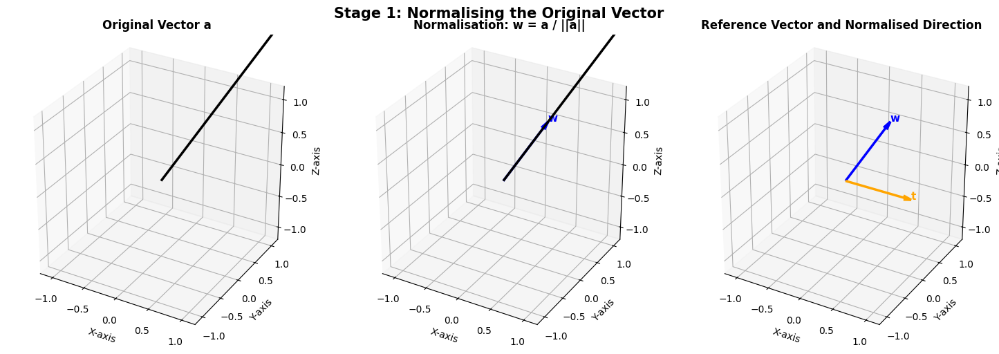

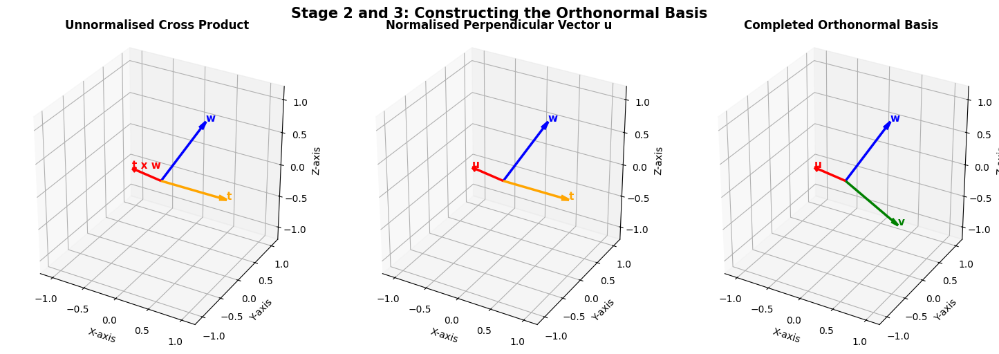

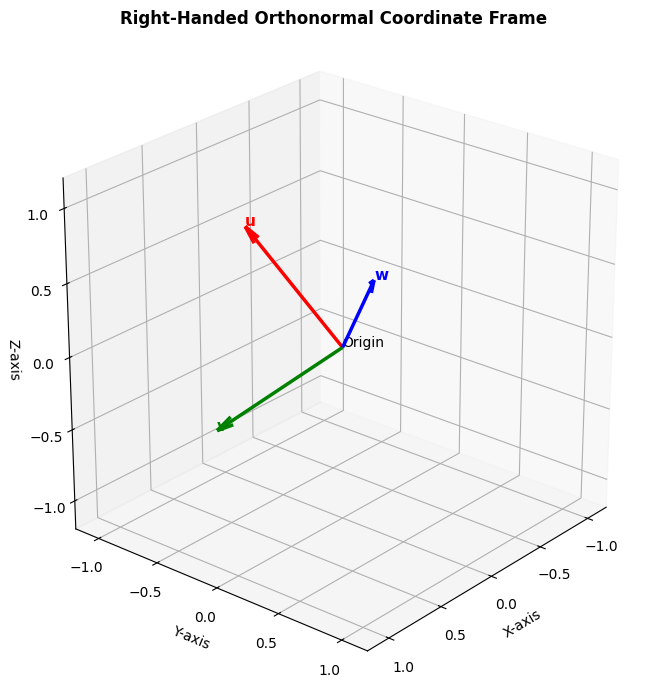

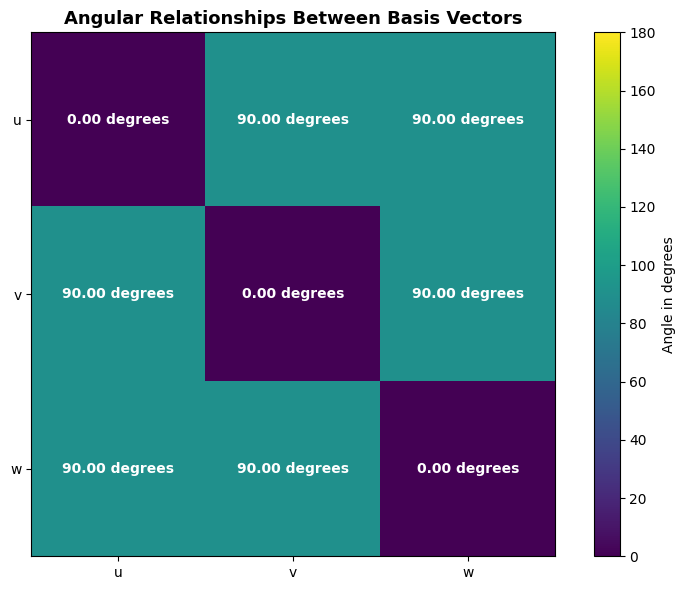

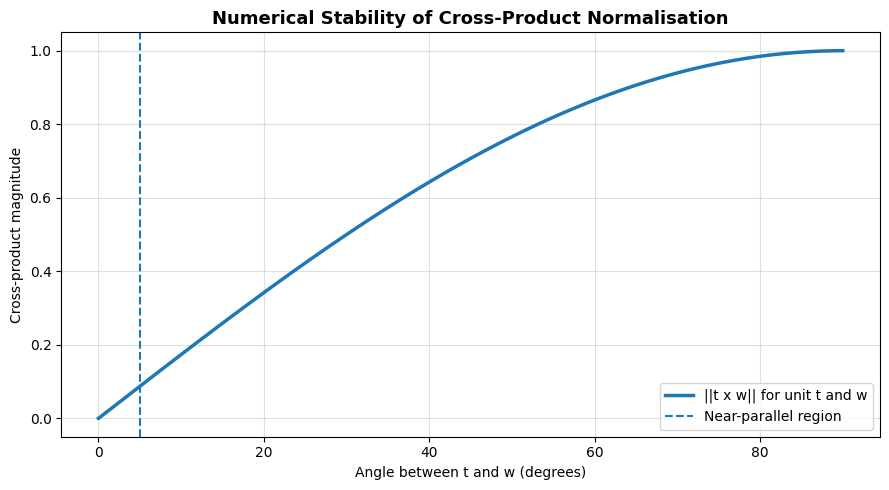

,Vector,X,Y,Z
0,a,2.000000,3.000000,4.000000
1,t,1.000000,0.000000,0.000000
2,u,0.000000,-0.800000,0.600000
3,v,0.928477,-0.222834,-0.297113
4,w,0.371391,0.557086,0.742781


,u,v,w
X,0.0,0.928477,0.371391
Y,-0.8,-0.222834,0.557086
Z,0.6,-0.297113,0.742781


,u,v,w
u,1.0,-0.0,-0.0
v,-0.0,1.0,-0.0
w,-0.0,-0.0,1.0


,Property,Calculated value
0,Magnitude of u,1.0
1,Magnitude of v,1.0
2,Magnitude of w,1.0
3,u dot v,0.0
4,u dot w,-0.0
5,v dot w,0.0
6,Determinant of basis matrix,1.0
7,Orthonormality verification,True


,Numerical stability test,Result
0,Reference vector parallelism,Cross product must be nonzero
1,Near-parallel reference vector,Accepted
2,Right-handed orientation,det(R) = +1
3,Orthonormal basis,Verified


In [32]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.6 CONSTRUCTING A BASIS FROM A SINGLE VECTOR
# ============================================================

EPSILON = 1e-10


# ------------------------------------------------------------
# 1. FUNDAMENTAL VECTOR OPERATIONS
# ------------------------------------------------------------

def magnitude(a):
    return np.linalg.norm(a)


def normalize(a):
    length = magnitude(a)

    if length < EPSILON:
        raise ValueError("A zero vector cannot be normalised.")

    return a / length


def dot(a, b):
    return np.dot(a, b)


def cross(a, b):
    return np.cross(a, b)


def angle_between(a, b):
    denominator = magnitude(a) * magnitude(b)

    if denominator < EPSILON:
        raise ValueError("Angle is undefined for a zero vector.")

    cosine = np.clip(dot(a, b) / denominator, -1.0, 1.0)
    return np.degrees(np.arccos(cosine))


# ------------------------------------------------------------
# 2. ORTHONORMAL BASIS CONSTRUCTION
# ------------------------------------------------------------

def construct_basis(a, t=None):
    """
    Construct a right-handed orthonormal basis.

    w = a / ||a||
    u = (t x w) / ||t x w||
    v = w x u
    """

    w = normalize(np.asarray(a, dtype=float))

    if t is None:
        # Select the Cartesian axis least aligned with w.
        axes = np.eye(3)
        t = axes[np.argmin(np.abs(axes @ w))]
    else:
        t = np.asarray(t, dtype=float)

    if magnitude(t) < EPSILON:
        raise ValueError("Reference vector t must be nonzero.")

    perpendicular = cross(t, w)

    if magnitude(perpendicular) < EPSILON:
        raise ValueError(
            "Reference vector is parallel or nearly parallel to w."
        )

    u = normalize(perpendicular)
    v = normalize(cross(w, u))

    return u, v, w


# ------------------------------------------------------------
# 3. INPUT VECTORS AND BASIS CONSTRUCTION
# ------------------------------------------------------------

a = np.array([2.0, 3.0, 4.0])
t = np.array([1.0, 0.0, 0.0])

u, v, w = construct_basis(a, t)

basis_matrix = np.column_stack((u, v, w))

# Alternative reference vector selected automatically.
u_auto, v_auto, w_auto = construct_basis(a)

# Deliberately near-parallel reference vector.
near_parallel_t = w + np.array([1e-8, 0.0, 0.0])

try:
    near_parallel_basis = construct_basis(a, near_parallel_t)
    near_parallel_status = "Accepted"
except ValueError:
    near_parallel_status = "Rejected as unstable"


# ------------------------------------------------------------
# 4. NUMERICAL VERIFICATION
# ------------------------------------------------------------

identity_matrix = np.eye(3)

orthogonality_matrix = basis_matrix.T @ basis_matrix

determinant = np.linalg.det(basis_matrix)

verification = pd.DataFrame({
    "Property": [
        "Magnitude of u",
        "Magnitude of v",
        "Magnitude of w",
        "u dot v",
        "u dot w",
        "v dot w",
        "Determinant of basis matrix",
        "Orthonormality verification"
    ],
    "Calculated value": [
        magnitude(u),
        magnitude(v),
        magnitude(w),
        dot(u, v),
        dot(u, w),
        dot(v, w),
        determinant,
        np.allclose(orthogonality_matrix, identity_matrix)
    ]
})

basis_table = pd.DataFrame(
    basis_matrix,
    index=["X", "Y", "Z"],
    columns=["u", "v", "w"]
)

orthogonality_table = pd.DataFrame(
    orthogonality_matrix,
    index=["u", "v", "w"],
    columns=["u", "v", "w"]
)


# ------------------------------------------------------------
# 5. 3D VECTOR DRAWING FUNCTION
# ------------------------------------------------------------

def draw_vector(ax, vector, color, label, origin=None,
                linewidth=2.5, linestyle="-"):

    if origin is None:
        origin = np.zeros(3)

    ax.quiver(
        origin[0], origin[1], origin[2],
        vector[0], vector[1], vector[2],
        color=color,
        linewidth=linewidth,
        arrow_length_ratio=0.12,
        linestyle=linestyle
    )

    endpoint = origin + vector

    ax.text(
        endpoint[0],
        endpoint[1],
        endpoint[2],
        label,
        color=color,
        fontsize=11,
        fontweight="bold"
    )


def configure_3d_axes(ax, title):
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("X-axis")
    ax.set_ylabel("Y-axis")
    ax.set_zlabel("Z-axis")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_zlim(-1.2, 1.2)
    ax.set_box_aspect((1, 1, 1))
    ax.grid(True)


# ------------------------------------------------------------
# 6. VISUALISATION 1: ORIGINAL VECTOR AND NORMALISATION
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection="3d")

draw_vector(ax1, a, "black", "a")
configure_3d_axes(
    ax1,
    "Original Vector a"
)

ax2 = fig.add_subplot(132, projection="3d")

draw_vector(ax2, a, "black", "a")
draw_vector(ax2, w, "blue", "w")

configure_3d_axes(
    ax2,
    "Normalisation: w = a / ||a||"
)

ax3 = fig.add_subplot(133, projection="3d")

draw_vector(ax3, t, "orange", "t")
draw_vector(ax3, w, "blue", "w")

configure_3d_axes(
    ax3,
    "Reference Vector and Normalised Direction"
)

fig.suptitle(
    "Stage 1: Normalising the Original Vector",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. VISUALISATION 2: CROSS-PRODUCT CONSTRUCTION
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection="3d")

draw_vector(ax1, t, "orange", "t")
draw_vector(ax1, w, "blue", "w")
draw_vector(ax1, cross(t, w), "red", "t x w")

configure_3d_axes(
    ax1,
    "Unnormalised Cross Product"
)

ax2 = fig.add_subplot(132, projection="3d")

draw_vector(ax2, t, "orange", "t")
draw_vector(ax2, w, "blue", "w")
draw_vector(ax2, u, "red", "u")

configure_3d_axes(
    ax2,
    "Normalised Perpendicular Vector u"
)

ax3 = fig.add_subplot(133, projection="3d")

draw_vector(ax3, u, "red", "u")
draw_vector(ax3, v, "green", "v")
draw_vector(ax3, w, "blue", "w")

configure_3d_axes(
    ax3,
    "Completed Orthonormal Basis"
)

fig.suptitle(
    "Stage 2 and 3: Constructing the Orthonormal Basis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. VISUALISATION 3: RIGHT-HANDED ORIENTATION
# ------------------------------------------------------------

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

draw_vector(ax, u, "red", "u")
draw_vector(ax, v, "green", "v")
draw_vector(ax, w, "blue", "w")

ax.text(
    0, 0, 0,
    "Origin",
    fontsize=10
)

configure_3d_axes(
    ax,
    "Right-Handed Orthonormal Coordinate Frame"
)

ax.view_init(elev=25, azim=40)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. VISUALISATION 4: ANGULAR RELATIONSHIPS
# ------------------------------------------------------------

vectors = [u, v, w]
names = ["u", "v", "w"]

angles = np.array([
    [angle_between(x, y) for y in vectors]
    for x in vectors
])

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    angles,
    cmap="viridis",
    vmin=0,
    vmax=180
)

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(names)
ax.set_yticklabels(names)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{angles[i, j]:.2f} degrees",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

ax.set_title(
    "Angular Relationships Between Basis Vectors",
    fontsize=13,
    fontweight="bold"
)

plt.colorbar(image, ax=ax, label="Angle in degrees")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. VISUALISATION 5: NUMERICAL STABILITY
# ------------------------------------------------------------

alignment_angles = np.linspace(0.01, 90, 300)

cross_magnitudes = np.sin(
    np.radians(alignment_angles)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    alignment_angles,
    cross_magnitudes,
    linewidth=2.5,
    label="||t x w|| for unit t and w"
)

ax.axvline(
    5,
    linestyle="--",
    linewidth=1.5,
    label="Near-parallel region"
)

ax.set_xlabel("Angle between t and w (degrees)")
ax.set_ylabel("Cross-product magnitude")
ax.set_title(
    "Numerical Stability of Cross-Product Normalisation",
    fontsize=13,
    fontweight="bold"
)

ax.grid(True, alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. NUMERICAL RESULTS
# ------------------------------------------------------------

display(
    pd.DataFrame({
        "Vector": ["a", "t", "u", "v", "w"],
        "X": [a[0], t[0], u[0], v[0], w[0]],
        "Y": [a[1], t[1], u[1], v[1], w[1]],
        "Z": [a[2], t[2], u[2], v[2], w[2]]
    }).round(6)
)

display(basis_table.round(6))

display(orthogonality_table.round(6))

display(verification)

display(
    pd.DataFrame({
        "Numerical stability test": [
            "Reference vector parallelism",
            "Near-parallel reference vector",
            "Right-handed orientation",
            "Orthonormal basis"
        ],
        "Result": [
            "Cross product must be nonzero",
            near_parallel_status,
            "det(R) = +1" if np.isclose(determinant, 1.0)
            else "Verification failed",
            "Verified" if np.allclose(
                orthogonality_matrix, identity_matrix
            ) else "Not verified"
        ]
    })
)


# ------------------------------------------------------------
# 12. FINAL MATHEMATICAL CHECKS
# ------------------------------------------------------------

assert np.isclose(magnitude(u), 1.0)
assert np.isclose(magnitude(v), 1.0)
assert np.isclose(magnitude(w), 1.0)

assert np.isclose(dot(u, v), 0.0, atol=1e-9)
assert np.isclose(dot(u, w), 0.0, atol=1e-9)
assert np.isclose(dot(v, w), 0.0, atol=1e-9)

assert np.allclose(
    basis_matrix.T @ basis_matrix,
    np.eye(3),
    atol=1e-9
)

assert np.isclose(determinant, 1.0, atol=1e-9)

assert np.allclose(
    cross(u, v),
    w,
    atol=1e-9
)


### 2.4.7 Constructing a Basis from Two Vectors

Constructing an orthonormal basis from two nonzero, non-collinear vectors establishes a three-dimensional coordinate frame with defined directional and rotational orientation. This is fundamental to camera positioning and geometric transformations.

**1. Establish the First Basis Vector**

Given vectors $\mathbf{a}$ and $\mathbf{b}$, normalise $\mathbf{a}$:

$$
\mathbf{w}=\frac{\mathbf{a}}{\|\mathbf{a}\|}
$$

Here, $\mathbf{w}$ is the unit vector in the direction of $\mathbf{a}$.

**2. Construct the Second Basis Vector**

Calculate:

$$
\mathbf{u}=\frac{\mathbf{b}\times\mathbf{w}}{\|\mathbf{b}\times\mathbf{w}\|}
$$

The cross product of $\mathbf{b}$ and $\mathbf{w}$ produces a perpendicular direction, while division by its magnitude ensures unit length.

**3. Complete the Orthonormal Basis**

Determine the third vector:

$$
\mathbf{v}=\mathbf{w}\times\mathbf{u}
$$

Consequently, $\mathbf{u}$, $\mathbf{v}$ and $\mathbf{w}$ are mutually perpendicular unit vectors forming a right-handed coordinate system.

**Geometric Interpretation and Limitations**

The procedure preserves $\mathbf{a}$'s direction while adjusting $\mathbf{b}$ to establish orthogonality. If the original vectors are collinear, $\mathbf{b}\times\mathbf{w}=\mathbf{0}$, making normalisation impossible. Nearly collinear vectors also cause numerical instability.

**Application: Camera Orientation**

For camera construction, $\mathbf{a}$ represents the viewing direction and $\mathbf{b}$ the approximate upward direction. Their orthonormal basis establishes camera alignment, supports stable viewing transformations and prevents unintended rotational distortion.

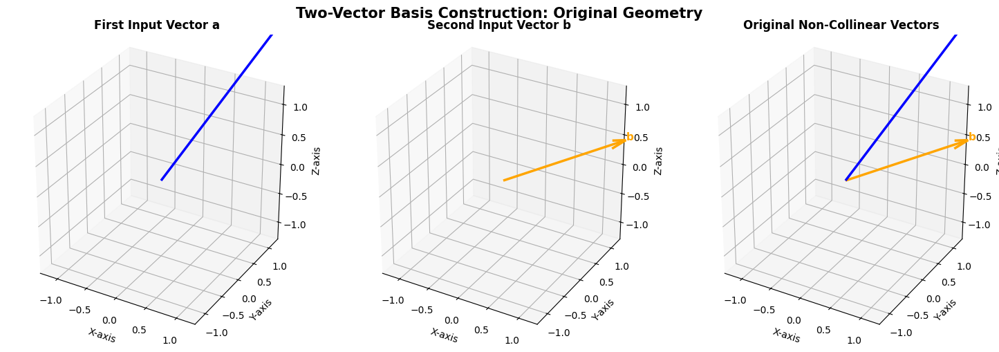

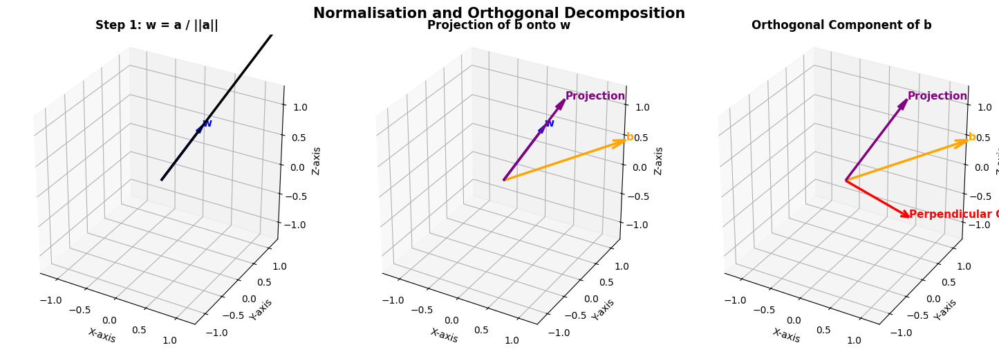

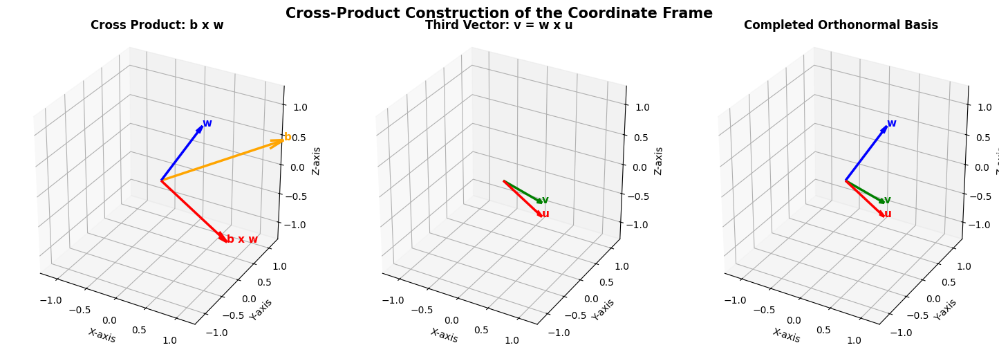

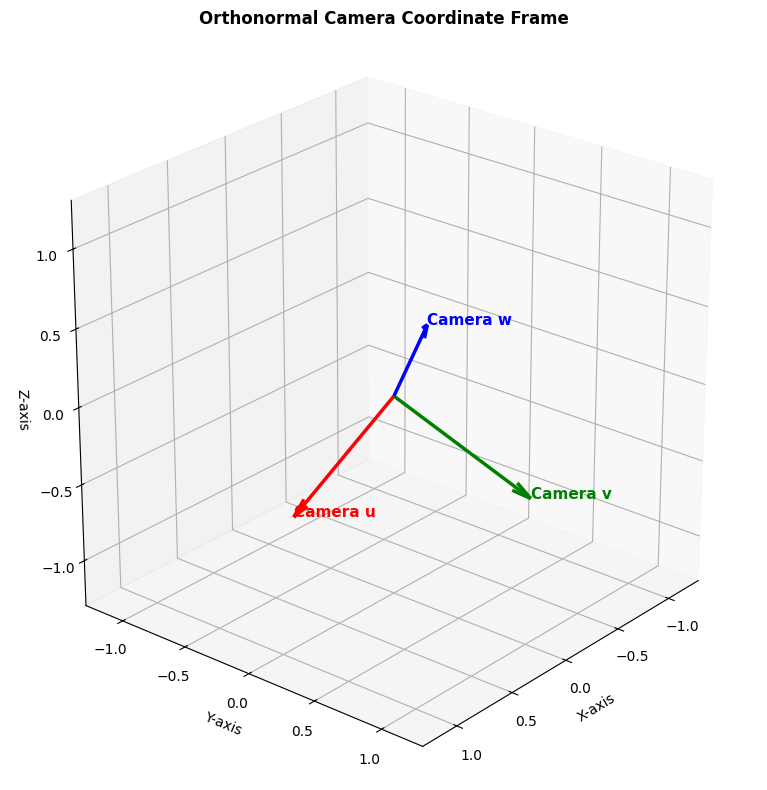

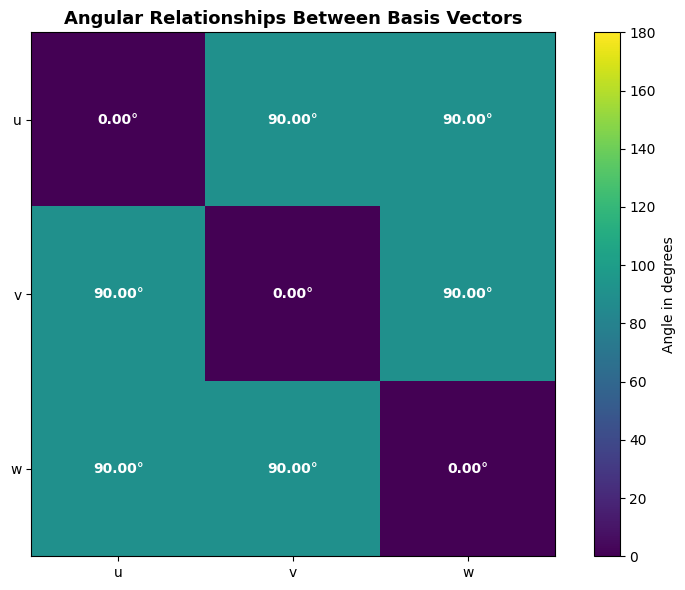

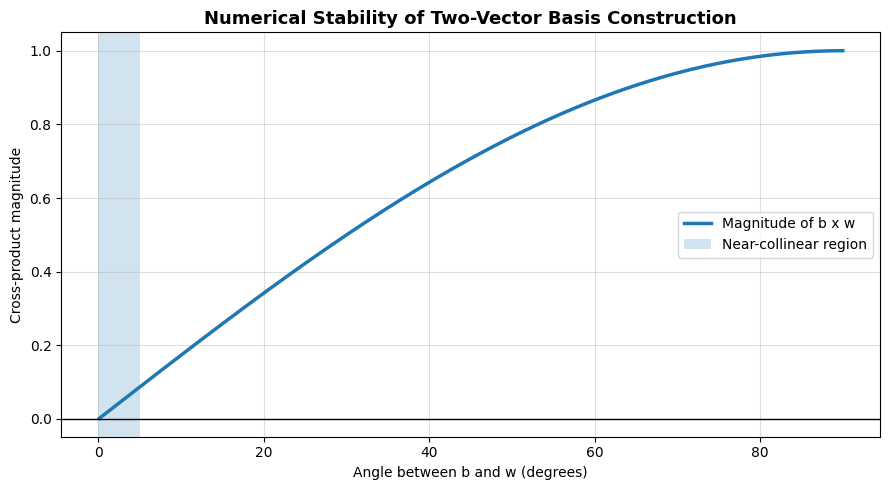

,Vector,X,Y,Z
0,a,2.000000,3.000000,4.000000
1,b,1.000000,2.000000,0.000000
2,w,0.371391,0.557086,0.742781
3,Projection of b onto w,0.551724,0.827586,1.103448
4,Perpendicular component,0.448276,1.172414,-1.103448
5,u,0.888889,-0.444444,-0.111111
6,v,0.268227,0.701516,-0.660250


,u,v,w
X,0.888889,0.268227,0.371391
Y,-0.444444,0.701516,0.557086
Z,-0.111111,-0.660250,0.742781


,u,v,w
u,1.0,-0.0,0.0
v,-0.0,1.0,-0.0
w,0.0,-0.0,1.0


,Property,Result
0,Magnitude of u,1.0
1,Magnitude of v,1.0
2,Magnitude of w,1.0
3,u dot v,0.0
4,u dot w,0.0
5,v dot w,0.0
6,det(R),1.0
7,R transpose R equals identity,True
8,u cross v equals w,True


,Test,Result
0,Original vector pair,Suitable for basis construction
1,Exactly collinear vectors,Collinear or numerically unstable
2,Nearly collinear vectors,Suitable for basis construction


,Camera u,Camera v,Camera w
X,0.894427,-0.249136,0.371391
Y,0.000000,0.830455,0.557086
Z,-0.447214,-0.498273,0.742781


In [33]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.7 CONSTRUCTING A BASIS FROM TWO VECTORS
# ============================================================

EPSILON = 1e-10


# ------------------------------------------------------------
# 1. FUNDAMENTAL VECTOR OPERATIONS
# ------------------------------------------------------------

def magnitude(a):
    return np.linalg.norm(a)


def normalize(a):
    length = magnitude(a)

    if length < EPSILON:
        raise ValueError("Cannot normalise a zero vector.")

    return a / length


def dot(a, b):
    return np.dot(a, b)


def cross(a, b):
    return np.cross(a, b)


def angle_between(a, b):
    denominator = magnitude(a) * magnitude(b)

    if denominator < EPSILON:
        raise ValueError("Angle is undefined for a zero vector.")

    cosine = np.clip(dot(a, b) / denominator, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


# ------------------------------------------------------------
# 2. CONSTRUCTING THE ORTHONORMAL BASIS
# ------------------------------------------------------------

def construct_basis(a, b):
    """
    w = a / ||a||
    u = (b x w) / ||b x w||
    v = w x u

    Returns a right-handed orthonormal basis.
    """

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if a.shape != (3,) or b.shape != (3,):
        raise ValueError("Both vectors must be three-dimensional.")

    if magnitude(a) < EPSILON:
        raise ValueError("Vector a must be nonzero.")

    if magnitude(b) < EPSILON:
        raise ValueError("Vector b must be nonzero.")

    # Step 1: Normalise the first vector.
    w = normalize(a)

    # Step 2: Construct a perpendicular vector.
    cross_product = cross(b, w)

    if magnitude(cross_product) < EPSILON:
        raise ValueError(
            "Vectors are collinear or nearly collinear."
        )

    u = normalize(cross_product)

    # Step 3: Complete the orthonormal basis.
    v = normalize(cross(w, u))

    return u, v, w


# ------------------------------------------------------------
# 3. INPUT VECTORS
# ------------------------------------------------------------

a = np.array([2.0, 3.0, 4.0])
b = np.array([1.0, 2.0, 0.0])

u, v, w = construct_basis(a, b)

# Basis matrix: columns are u, v and w.
R = np.column_stack((u, v, w))


# ------------------------------------------------------------
# 4. GRAM-SCHMIDT GEOMETRIC INTERPRETATION
# ------------------------------------------------------------

# Normalised first vector.
a_unit = normalize(a)

# Projection of b onto w.
projection_scalar = dot(b, w)

projection_b_on_w = projection_scalar * w

# Component of b perpendicular to w.
b_perpendicular = b - projection_b_on_w

# The second basis vector is the normalised perpendicular
# component, with the sign determined by the cross product.
b_perpendicular_unit = normalize(b_perpendicular)

# Cross-product construction of u.
u_cross = normalize(cross(b, w))

# These vectors are parallel or antiparallel.
orientation_agreement = dot(
    b_perpendicular_unit, u_cross
)


# ------------------------------------------------------------
# 5. NUMERICAL VERIFICATION
# ------------------------------------------------------------

orthogonality = R.T @ R
determinant = np.linalg.det(R)

verification = pd.DataFrame({
    "Property": [
        "Magnitude of u",
        "Magnitude of v",
        "Magnitude of w",
        "u dot v",
        "u dot w",
        "v dot w",
        "det(R)",
        "R transpose R equals identity",
        "u cross v equals w"
    ],
    "Result": [
        magnitude(u),
        magnitude(v),
        magnitude(w),
        dot(u, v),
        dot(u, w),
        dot(v, w),
        determinant,
        np.allclose(orthogonality, np.eye(3)),
        np.allclose(cross(u, v), w)
    ]
})


# ------------------------------------------------------------
# 6. CAMERA ORIENTATION
# ------------------------------------------------------------

# Camera viewing direction.
view_direction = np.array([2.0, 3.0, 4.0])

# Approximate camera up direction.
approximate_up = np.array([0.0, 1.0, 0.0])

camera_u, camera_v, camera_w = construct_basis(
    view_direction,
    approximate_up
)

camera_rotation = np.column_stack((
    camera_u,
    camera_v,
    camera_w
))


# ------------------------------------------------------------
# 7. 3D VECTOR VISUALISATION FUNCTIONS
# ------------------------------------------------------------

def draw_vector(
    ax,
    vector,
    color,
    label,
    origin=None,
    linewidth=2.5
):

    if origin is None:
        origin = np.zeros(3)

    ax.quiver(
        origin[0], origin[1], origin[2],
        vector[0], vector[1], vector[2],
        color=color,
        linewidth=linewidth,
        arrow_length_ratio=0.12
    )

    endpoint = origin + vector

    ax.text(
        endpoint[0],
        endpoint[1],
        endpoint[2],
        label,
        color=color,
        fontsize=11,
        fontweight="bold"
    )


def configure_3d_axes(ax, title):
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("X-axis")
    ax.set_ylabel("Y-axis")
    ax.set_zlabel("Z-axis")

    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_zlim(-1.3, 1.3)

    ax.set_box_aspect((1, 1, 1))
    ax.grid(True)


# ------------------------------------------------------------
# 8. VISUALISATION 1: ORIGINAL VECTORS
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection="3d")

draw_vector(ax1, a, "blue", "a")
configure_3d_axes(
    ax1,
    "First Input Vector a"
)

ax2 = fig.add_subplot(132, projection="3d")

draw_vector(ax2, b, "orange", "b")
configure_3d_axes(
    ax2,
    "Second Input Vector b"
)

ax3 = fig.add_subplot(133, projection="3d")

draw_vector(ax3, a, "blue", "a")
draw_vector(ax3, b, "orange", "b")

configure_3d_axes(
    ax3,
    "Original Non-Collinear Vectors"
)

fig.suptitle(
    "Two-Vector Basis Construction: Original Geometry",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. VISUALISATION 2: NORMALISATION AND PROJECTION
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection="3d")

draw_vector(ax1, a, "black", "a")
draw_vector(ax1, w, "blue", "w")

configure_3d_axes(
    ax1,
    "Step 1: w = a / ||a||"
)

ax2 = fig.add_subplot(132, projection="3d")

draw_vector(ax2, b, "orange", "b")
draw_vector(ax2, w, "blue", "w")
draw_vector(
    ax2,
    projection_b_on_w,
    "purple",
    "Projection"
)

configure_3d_axes(
    ax2,
    "Projection of b onto w"
)

ax3 = fig.add_subplot(133, projection="3d")

draw_vector(ax3, b, "orange", "b")
draw_vector(
    ax3,
    projection_b_on_w,
    "purple",
    "Projection"
)

draw_vector(
    ax3,
    b_perpendicular,
    "red",
    "Perpendicular Component"
)

configure_3d_axes(
    ax3,
    "Orthogonal Component of b"
)

fig.suptitle(
    "Normalisation and Orthogonal Decomposition",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. VISUALISATION 3: CROSS-PRODUCT CONSTRUCTION
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(131, projection="3d")

draw_vector(ax1, b, "orange", "b")
draw_vector(ax1, w, "blue", "w")

draw_vector(
    ax1,
    cross(b, w),
    "red",
    "b x w"
)

configure_3d_axes(
    ax1,
    "Cross Product: b x w"
)

ax2 = fig.add_subplot(132, projection="3d")

draw_vector(ax2, u, "red", "u")
draw_vector(ax2, v, "green", "v")

configure_3d_axes(
    ax2,
    "Third Vector: v = w x u"
)

ax3 = fig.add_subplot(133, projection="3d")

draw_vector(ax3, u, "red", "u")
draw_vector(ax3, v, "green", "v")
draw_vector(ax3, w, "blue", "w")

configure_3d_axes(
    ax3,
    "Completed Orthonormal Basis"
)

fig.suptitle(
    "Cross-Product Construction of the Coordinate Frame",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. VISUALISATION 4: CAMERA COORDINATE FRAME
# ------------------------------------------------------------

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

draw_vector(
    ax,
    camera_u,
    "red",
    "Camera u"
)

draw_vector(
    ax,
    camera_v,
    "green",
    "Camera v"
)

draw_vector(
    ax,
    camera_w,
    "blue",
    "Camera w"
)

configure_3d_axes(
    ax,
    "Orthonormal Camera Coordinate Frame"
)

ax.view_init(elev=25, azim=40)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. VISUALISATION 5: ANGULAR RELATIONSHIPS
# ------------------------------------------------------------

basis_vectors = [u, v, w]
basis_names = ["u", "v", "w"]

angle_matrix = np.array([
    [
        angle_between(x, y)
        for y in basis_vectors
    ]
    for x in basis_vectors
])

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    angle_matrix,
    cmap="viridis",
    vmin=0,
    vmax=180
)

ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(basis_names)
ax.set_yticklabels(basis_names)

for i in range(3):
    for j in range(3):
        ax.text(
            j,
            i,
            f"{angle_matrix[i, j]:.2f}°",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

ax.set_title(
    "Angular Relationships Between Basis Vectors",
    fontsize=13,
    fontweight="bold"
)

plt.colorbar(image, ax=ax, label="Angle in degrees")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. VISUALISATION 6: COLLINEARITY AND STABILITY
# ------------------------------------------------------------

angles = np.linspace(0.1, 90, 400)

# For unit b and w:
# ||b x w|| = sin(theta)
cross_magnitude = np.sin(np.radians(angles))

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    angles,
    cross_magnitude,
    linewidth=2.5,
    label="Magnitude of b x w"
)

ax.axvspan(
    0,
    5,
    alpha=0.2,
    label="Near-collinear region"
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel("Angle between b and w (degrees)")
ax.set_ylabel("Cross-product magnitude")

ax.set_title(
    "Numerical Stability of Two-Vector Basis Construction",
    fontsize=13,
    fontweight="bold"
)

ax.grid(True, alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. COLLINEARITY TEST
# ------------------------------------------------------------

collinear_a = np.array([1.0, 2.0, 3.0])
collinear_b = np.array([2.0, 4.0, 6.0])

nearly_collinear_b = np.array([
    2.0,
    4.0,
    6.000000001
])

def test_basis_stability(a, b):
    w = normalize(a)
    cross_product = cross(b, w)

    relative_cross_magnitude = (
        magnitude(cross_product) / magnitude(b)
    )

    if relative_cross_magnitude < 1e-8:
        return "Collinear or numerically unstable"

    return "Suitable for basis construction"


stability_results = pd.DataFrame({
    "Test": [
        "Original vector pair",
        "Exactly collinear vectors",
        "Nearly collinear vectors"
    ],
    "Result": [
        test_basis_stability(a, b),
        test_basis_stability(collinear_a, collinear_b),
        test_basis_stability(a, nearly_collinear_b)
    ]
})


# ------------------------------------------------------------
# 15. NUMERICAL OUTPUT TABLES
# ------------------------------------------------------------

basis_table = pd.DataFrame(
    R,
    index=["X", "Y", "Z"],
    columns=["u", "v", "w"]
)

orthogonality_table = pd.DataFrame(
    orthogonality,
    index=["u", "v", "w"],
    columns=["u", "v", "w"]
)

camera_table = pd.DataFrame(
    camera_rotation,
    index=["X", "Y", "Z"],
    columns=["Camera u", "Camera v", "Camera w"]
)

vector_results = pd.DataFrame({
    "Vector": [
        "a",
        "b",
        "w",
        "Projection of b onto w",
        "Perpendicular component",
        "u",
        "v"
    ],
    "X": [
        a[0], b[0], w[0],
        projection_b_on_w[0],
        b_perpendicular[0],
        u[0], v[0]
    ],
    "Y": [
        a[1], b[1], w[1],
        projection_b_on_w[1],
        b_perpendicular[1],
        u[1], v[1]
    ],
    "Z": [
        a[2], b[2], w[2],
        projection_b_on_w[2],
        b_perpendicular[2],
        u[2], v[2]
    ]
})

display(vector_results.round(6))
display(basis_table.round(6))
display(orthogonality_table.round(6))
display(verification)
display(stability_results)
display(camera_table.round(6))


# ------------------------------------------------------------
# 16. FINAL MATHEMATICAL ASSERTIONS
# ------------------------------------------------------------

assert np.isclose(magnitude(u), 1.0)
assert np.isclose(magnitude(v), 1.0)
assert np.isclose(magnitude(w), 1.0)

assert np.isclose(dot(u, v), 0.0, atol=1e-9)
assert np.isclose(dot(u, w), 0.0, atol=1e-9)
assert np.isclose(dot(v, w), 0.0, atol=1e-9)

assert np.allclose(
    R.T @ R,
    np.eye(3),
    atol=1e-9
)

assert np.isclose(determinant, 1.0, atol=1e-9)

assert np.allclose(
    cross(u, v),
    w,
    atol=1e-9
)

assert np.allclose(
    camera_rotation.T @ camera_rotation,
    np.eye(3),
    atol=1e-9
)

assert np.isclose(
    np.linalg.det(camera_rotation),
    1.0,
    atol=1e-9
)


### 2.4.8 Squaring Up a Basis

**Squaring up a basis** restores orthogonality and unit-length properties to an approximately orthonormal coordinate system affected by floating-point rounding and accumulated numerical errors. Such errors can destabilise geometric transformations and spatial computations.

**Correction Method**

Given existing basis vectors $\mathbf{a}$ and $\mathbf{b}$, reconstruct the orthonormal basis:

$$
\mathbf{w}=\frac{\mathbf{a}}{\|\mathbf{a}\|}, \quad
\mathbf{u}=\frac{\mathbf{b}\times\mathbf{w}}{\|\mathbf{b}\times\mathbf{w}\|}, \quad
\mathbf{v}=\mathbf{w}\times\mathbf{u}
$$

Here, $\mathbf{w}$ normalises the first vector, $\mathbf{u}$ establishes a perpendicular unit direction, and $\mathbf{v}$ completes the right-handed basis.

**Limitations and Alternative**

This method is asymmetric because it prioritises two vectors and reconstructs the third, rather than finding the closest correction to the entire original basis. Singular Value Decomposition (SVD) provides a more accurate alternative by finding the nearest orthonormal matrix under the Frobenius norm.

**Applications**

Basis correction maintains stable camera orientations, coordinate frames and geometric transformations in computer graphics.

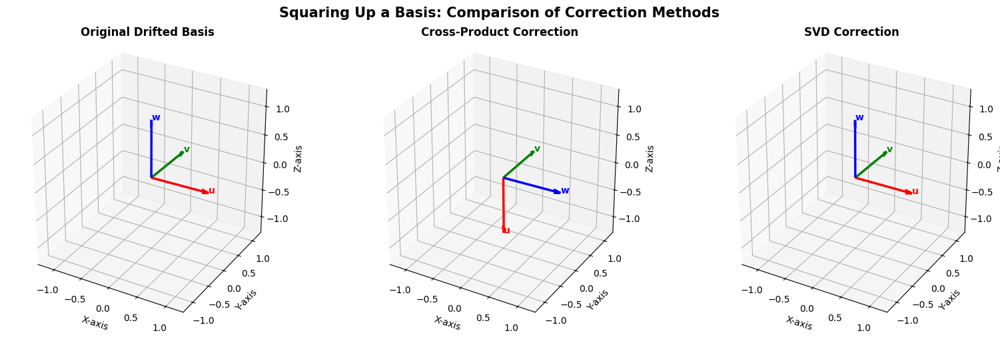

/tmp/ipykernel_494/3332607270.py:383: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


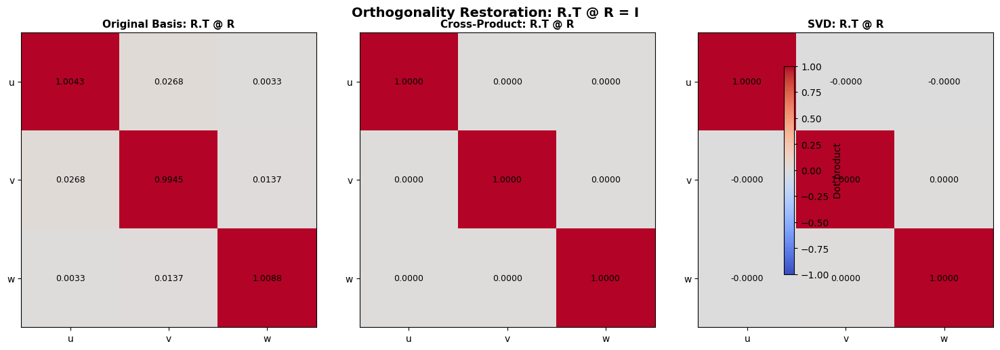

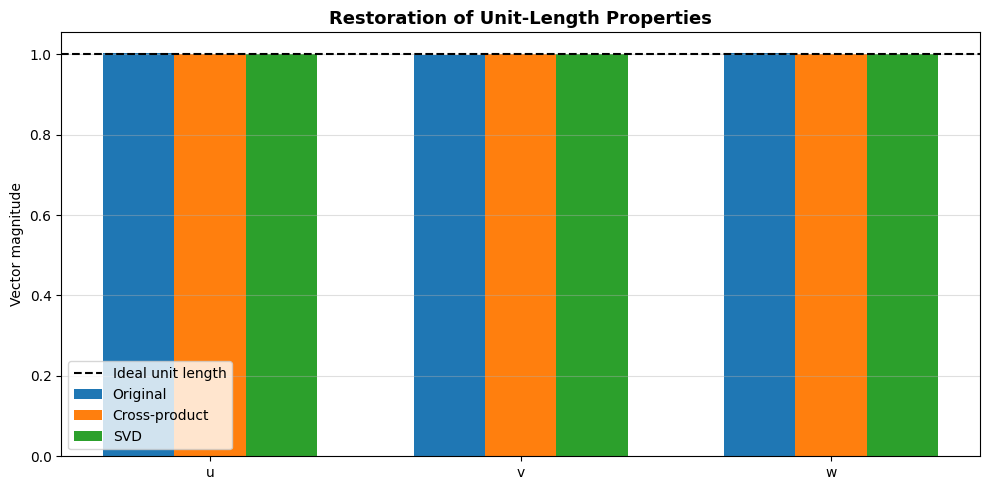

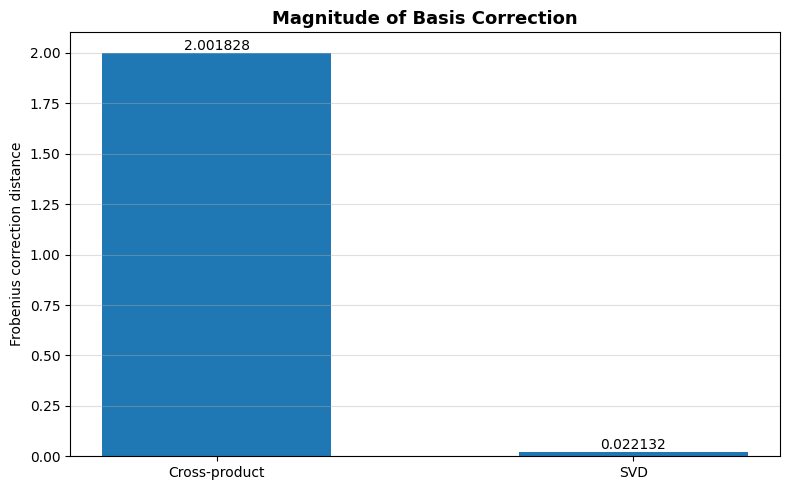

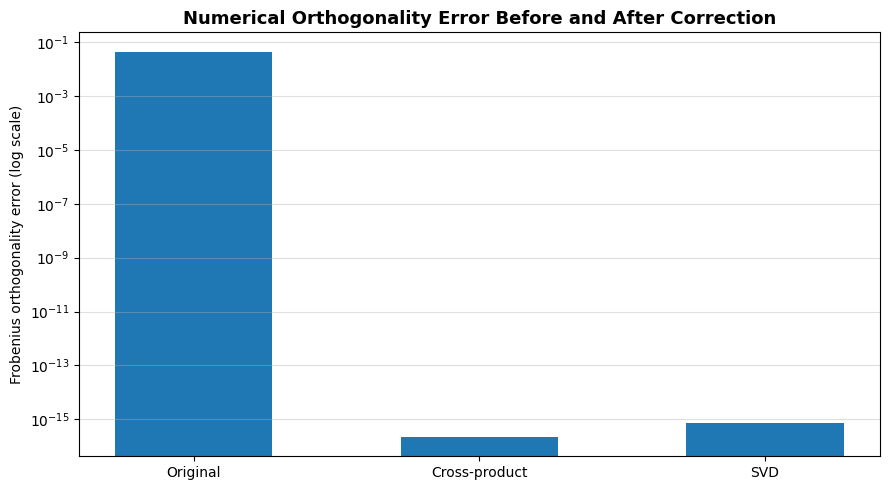

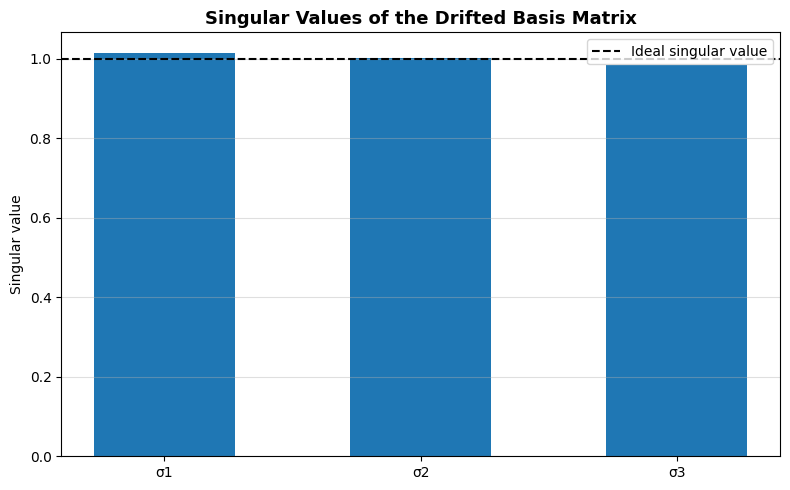

,a,b,c
X,1.002,0.018,-0.012
Y,0.009,0.997,0.025
Z,0.015,-0.011,1.004


,u,v,w
X,0.015069,-0.008810,0.999848
Y,-0.011303,0.999896,0.008981
Z,-0.999823,-0.011437,0.014968


,u,v,w
X,0.999897,0.004685,-0.013552
Y,-0.004439,0.999826,0.018112
Z,0.013635,-0.018050,0.999744


,Method,Orthogonality error,Unit-length error,Determinant
0,Original drifted basis,0.044299,0.004383,1.00329
1,Cross-product reconstruction,0.000000,0.000000,1.00000
2,SVD correction,0.000000,0.000000,1.00000


,Comparison,Frobenius norm
0,Cross-product correction distance,2.001828
1,SVD correction distance,0.022132
2,Cross-product deviation from ideal,1.984977
3,SVD deviation from ideal,0.032638


In [34]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 2.4.8 SQUARING UP A BASIS
# ============================================================

EPSILON = 1e-12


# ------------------------------------------------------------
# 1. FUNDAMENTAL VECTOR OPERATIONS
# ------------------------------------------------------------

def magnitude(a):
    return np.linalg.norm(a)


def normalize(a):
    length = magnitude(a)

    if length < EPSILON:
        raise ValueError("Cannot normalise a zero vector.")

    return a / length


def dot(a, b):
    return np.dot(a, b)


def cross(a, b):
    return np.cross(a, b)


# ------------------------------------------------------------
# 2. MEASURE BASIS QUALITY
# ------------------------------------------------------------

def basis_quality(R):
    """
    R contains basis vectors as columns.

    Orthogonality error:
        ||R.T @ R - I||_F

    Unit-length error:
        Maximum deviation of column lengths from 1.

    Determinant:
        +1 for a right-handed orthonormal basis.
    """

    identity = np.eye(3)

    orthogonality_error = np.linalg.norm(
        R.T @ R - identity,
        ord="fro"
    )

    column_lengths = np.linalg.norm(R, axis=0)

    unit_length_error = np.max(
        np.abs(column_lengths - 1.0)
    )

    determinant = np.linalg.det(R)

    return {
        "Orthogonality error": orthogonality_error,
        "Unit-length error": unit_length_error,
        "Determinant": determinant,
        "Column lengths": column_lengths
    }


# ------------------------------------------------------------
# 3. CREATE AN APPROXIMATELY ORTHONORMAL BASIS
# ------------------------------------------------------------

# Original ideal right-handed basis.
R_true = np.eye(3)

# Simulated numerical drift and accumulated error.
R_drifted = np.array([
    [1.002,  0.018, -0.012],
    [0.009,  0.997,  0.025],
    [0.015, -0.011,  1.004]
])

# Extract the three approximate basis vectors.
a = R_drifted[:, 0]
b = R_drifted[:, 1]
c = R_drifted[:, 2]


# ------------------------------------------------------------
# 4. METHOD ONE: CROSS-PRODUCT RECONSTRUCTION
# ------------------------------------------------------------

def square_up_cross(a, b):
    """
    Reconstruct a right-handed orthonormal basis.

    w = a / ||a||
    u = (b x w) / ||b x w||
    v = w x u

    Returns columns [u, v, w].
    """

    w = normalize(a)

    cross_product = cross(b, w)

    if magnitude(cross_product) < EPSILON:
        raise ValueError(
            "The input vectors are collinear or nearly collinear."
        )

    u = normalize(cross_product)
    v = normalize(cross(w, u))

    return np.column_stack((u, v, w))


R_cross = square_up_cross(a, b)


# ------------------------------------------------------------
# 5. METHOD TWO: SINGULAR VALUE DECOMPOSITION
# ------------------------------------------------------------

def square_up_svd(R):
    """
    Find the nearest orthogonal matrix using SVD.

    R = U @ S @ V.T

    The nearest orthogonal matrix is U @ V.T.

    If necessary, correct its determinant to +1
    to obtain a proper rotation matrix.
    """

    U, singular_values, Vt = np.linalg.svd(R)

    correction = np.eye(3)

    if np.linalg.det(U @ Vt) < 0:
        correction[-1, -1] = -1

    R_corrected = U @ correction @ Vt

    return R_corrected, singular_values


R_svd, singular_values = square_up_svd(R_drifted)


# ------------------------------------------------------------
# 6. CALCULATE CORRECTION ERRORS
# ------------------------------------------------------------

def frobenius_error(A, B):
    return np.linalg.norm(A - B, ord="fro")


cross_correction_error = frobenius_error(
    R_cross,
    R_drifted
)

svd_correction_error = frobenius_error(
    R_svd,
    R_drifted
)

cross_deviation_from_true = frobenius_error(
    R_cross,
    R_true
)

svd_deviation_from_true = frobenius_error(
    R_svd,
    R_true
)


# ------------------------------------------------------------
# 7. COMPUTE BASIS QUALITY FOR ALL METHODS
# ------------------------------------------------------------

quality_original = basis_quality(R_drifted)
quality_cross = basis_quality(R_cross)
quality_svd = basis_quality(R_svd)

quality_table = pd.DataFrame([
    {
        "Method": "Original drifted basis",
        "Orthogonality error":
            quality_original["Orthogonality error"],
        "Unit-length error":
            quality_original["Unit-length error"],
        "Determinant":
            quality_original["Determinant"]
    },
    {
        "Method": "Cross-product reconstruction",
        "Orthogonality error":
            quality_cross["Orthogonality error"],
        "Unit-length error":
            quality_cross["Unit-length error"],
        "Determinant":
            quality_cross["Determinant"]
    },
    {
        "Method": "SVD correction",
        "Orthogonality error":
            quality_svd["Orthogonality error"],
        "Unit-length error":
            quality_svd["Unit-length error"],
        "Determinant":
            quality_svd["Determinant"]
    }
])


# ------------------------------------------------------------
# 8. VISUALISATION FUNCTIONS
# ------------------------------------------------------------

def draw_vector(ax, vector, color, label, origin=None):

    if origin is None:
        origin = np.zeros(3)

    ax.quiver(
        origin[0], origin[1], origin[2],
        vector[0], vector[1], vector[2],
        color=color,
        linewidth=2.5,
        arrow_length_ratio=0.12
    )

    endpoint = origin + vector

    ax.text(
        endpoint[0],
        endpoint[1],
        endpoint[2],
        label,
        color=color,
        fontsize=10,
        fontweight="bold"
    )


def draw_basis(ax, R, title):

    colors = ["red", "green", "blue"]
    labels = ["u", "v", "w"]

    for i in range(3):
        draw_vector(
            ax,
            R[:, i],
            colors[i],
            labels[i]
        )

    ax.set_title(title, fontsize=12, fontweight="bold")

    ax.set_xlabel("X-axis")
    ax.set_ylabel("Y-axis")
    ax.set_zlabel("Z-axis")

    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_zlim(-1.3, 1.3)

    ax.set_box_aspect((1, 1, 1))
    ax.grid(True)


# ------------------------------------------------------------
# 9. VISUALISATION 1: ORIGINAL AND CORRECTED BASES
# ------------------------------------------------------------

fig = plt.figure(figsize=(16, 5))

ax1 = fig.add_subplot(131, projection="3d")
draw_basis(
    ax1,
    R_drifted,
    "Original Drifted Basis"
)

ax2 = fig.add_subplot(132, projection="3d")
draw_basis(
    ax2,
    R_cross,
    "Cross-Product Correction"
)

ax3 = fig.add_subplot(133, projection="3d")
draw_basis(
    ax3,
    R_svd,
    "SVD Correction"
)

fig.suptitle(
    "Squaring Up a Basis: Comparison of Correction Methods",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. VISUALISATION 2: ORTHOGONALITY MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

matrices = [
    R_drifted.T @ R_drifted,
    R_cross.T @ R_cross,
    R_svd.T @ R_svd
]

titles = [
    "Original Basis: R.T @ R",
    "Cross-Product: R.T @ R",
    "SVD: R.T @ R"
]

for ax, matrix, title in zip(axes, matrices, titles):

    image = ax.imshow(
        matrix,
        cmap="coolwarm",
        vmin=-1.0,
        vmax=1.0
    )

    ax.set_title(title, fontsize=11, fontweight="bold")

    ax.set_xticks(range(3))
    ax.set_yticks(range(3))

    ax.set_xticklabels(["u", "v", "w"])
    ax.set_yticklabels(["u", "v", "w"])

    for i in range(3):
        for j in range(3):
            ax.text(
                j,
                i,
                f"{matrix[i, j]:.4f}",
                ha="center",
                va="center",
                fontsize=9
            )

fig.colorbar(
    image,
    ax=axes,
    shrink=0.8,
    label="Dot product"
)

fig.suptitle(
    "Orthogonality Restoration: R.T @ R = I",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. VISUALISATION 3: UNIT-LENGTH RESTORATION
# ------------------------------------------------------------

methods = [
    ("Original", R_drifted),
    ("Cross-product", R_cross),
    ("SVD", R_svd)
]

fig, ax = plt.subplots(figsize=(10, 5))

x_positions = np.arange(3)
width = 0.23

for i, (method, matrix) in enumerate(methods):

    lengths = np.linalg.norm(matrix, axis=0)

    ax.bar(
        x_positions + (i - 1) * width,
        lengths,
        width,
        label=method
    )

ax.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Ideal unit length"
)

ax.set_xticks(x_positions)
ax.set_xticklabels(["u", "v", "w"])

ax.set_ylabel("Vector magnitude")

ax.set_title(
    "Restoration of Unit-Length Properties",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. VISUALISATION 4: FROBENIUS CORRECTION ERROR
# ------------------------------------------------------------

correction_errors = [
    cross_correction_error,
    svd_correction_error
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Cross-product", "SVD"],
    correction_errors,
    width=0.55
)

for bar, value in zip(bars, correction_errors):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.6f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylabel("Frobenius correction distance")

ax.set_title(
    "Magnitude of Basis Correction",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. VISUALISATION 5: COMPARISON OF ORTHOGONALITY ERRORS
# ------------------------------------------------------------

orthogonality_errors = [
    quality_original["Orthogonality error"],
    quality_cross["Orthogonality error"],
    quality_svd["Orthogonality error"]
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    [
        "Original",
        "Cross-product",
        "SVD"
    ],
    orthogonality_errors,
    width=0.55
)

ax.set_yscale("log")

ax.set_ylabel("Frobenius orthogonality error (log scale)")

ax.set_title(
    "Numerical Orthogonality Error Before and After Correction",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. VISUALISATION 6: SINGULAR VALUES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["σ1", "σ2", "σ3"],
    singular_values,
    width=0.55
)

ax.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Ideal singular value"
)

ax.set_ylabel("Singular value")

ax.set_title(
    "Singular Values of the Drifted Basis Matrix",
    fontsize=13,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. NUMERICAL OUTPUT TABLES
# ------------------------------------------------------------

display(
    pd.DataFrame(
        R_drifted,
        index=["X", "Y", "Z"],
        columns=["a", "b", "c"]
    ).round(6)
)

display(
    pd.DataFrame(
        R_cross,
        index=["X", "Y", "Z"],
        columns=["u", "v", "w"]
    ).round(6)
)

display(
    pd.DataFrame(
        R_svd,
        index=["X", "Y", "Z"],
        columns=["u", "v", "w"]
    ).round(6)
)

display(quality_table.round(12))

display(
    pd.DataFrame({
        "Comparison": [
            "Cross-product correction distance",
            "SVD correction distance",
            "Cross-product deviation from ideal",
            "SVD deviation from ideal"
        ],
        "Frobenius norm": [
            cross_correction_error,
            svd_correction_error,
            cross_deviation_from_true,
            svd_deviation_from_true
        ]
    }).round(12)
)


# ------------------------------------------------------------
# 16. FINAL MATHEMATICAL VERIFICATION
# ------------------------------------------------------------

# Both correction methods must produce orthonormal matrices.
assert np.allclose(
    R_cross.T @ R_cross,
    np.eye(3),
    atol=1e-10
)

assert np.allclose(
    R_svd.T @ R_svd,
    np.eye(3),
    atol=1e-10
)

# Both must preserve right-handed orientation.
assert np.isclose(
    np.linalg.det(R_cross),
    1.0,
    atol=1e-10
)

assert np.isclose(
    np.linalg.det(R_svd),
    1.0,
    atol=1e-10
)

# All corrected columns must have unit length.
assert np.allclose(
    np.linalg.norm(R_cross, axis=0),
    np.ones(3),
    atol=1e-10
)

assert np.allclose(
    np.linalg.norm(R_svd, axis=0),
    np.ones(3),
    atol=1e-10
)

# SVD provides the nearest proper orthogonal matrix.
assert svd_correction_error <= (
    cross_correction_error + 1e-10
)


## 2.5 Curves and Surfaces

Curves and surfaces are fundamental geometric structures in computer graphics. Curves represent one-dimensional paths, whereas surfaces describe two-dimensional geometries embedded in two- or three-dimensional space. They underpin object modelling, animation, boundary representation and geometric analysis.

### 2.5.1 Two-Dimensional Implicit Curves

An **implicit curve** is defined as the set of points satisfying:

$$
f(x,y)=0
$$

Here, $f:\mathbb{R}^2\rightarrow\mathbb{R}$ denotes a real-valued function mapping two-dimensional coordinates to a scalar. Every point satisfying the equation belongs to the curve; other points lie outside its boundary.

**1. Mathematical Representation**

A circle with centre $C=(x_c,y_c)$ and radius $r>0$ is represented by:

$$
f(x,y)=(x-x_c)^2+(y-y_c)^2-r^2=0
$$

Let $P=(x,y)$ represent any point and $C=(x_c,y_c)$ the centre. Using vector notation:

$$
(P-C)\cdot(P-C)-r^2=0
$$

Since a vector dotted with itself equals its squared magnitude:

$$
\|P-C\|^2=r^2
$$

Taking the square root gives:

$$
\|P-C\|=r
$$

This establishes that every boundary point is exactly distance $r$ from the centre.

**2. Geometric Interpretation**

The scalar function classifies spatial regions:

- $f(x,y)=0$: boundary points.
- $f(x,y)>0$: positive region.
- $f(x,y)<0$: negative region.

For the circle, positive values indicate exterior points, zero identifies the circumference, and negative values identify interior points.

**3. Level Sets**

A general level curve satisfies $f(x,y)=k$, where $k$ is constant. For example:

$$
f(x,y)=x^2+y^2-1
$$

Setting $f(x,y)=0$ produces a unit circle. Other level values generate concentric circles:

$$
x^2+y^2=1+k
$$

provided $1+k>0$.

**4. Analytical Significance and Applications**

Implicit representations describe geometric boundaries independently of traversal direction. They support point classification, intersection analysis, collision detection and geometric modelling. Vector notation expresses spatial relationships compactly, improving mathematical clarity and computational geometry workflows.

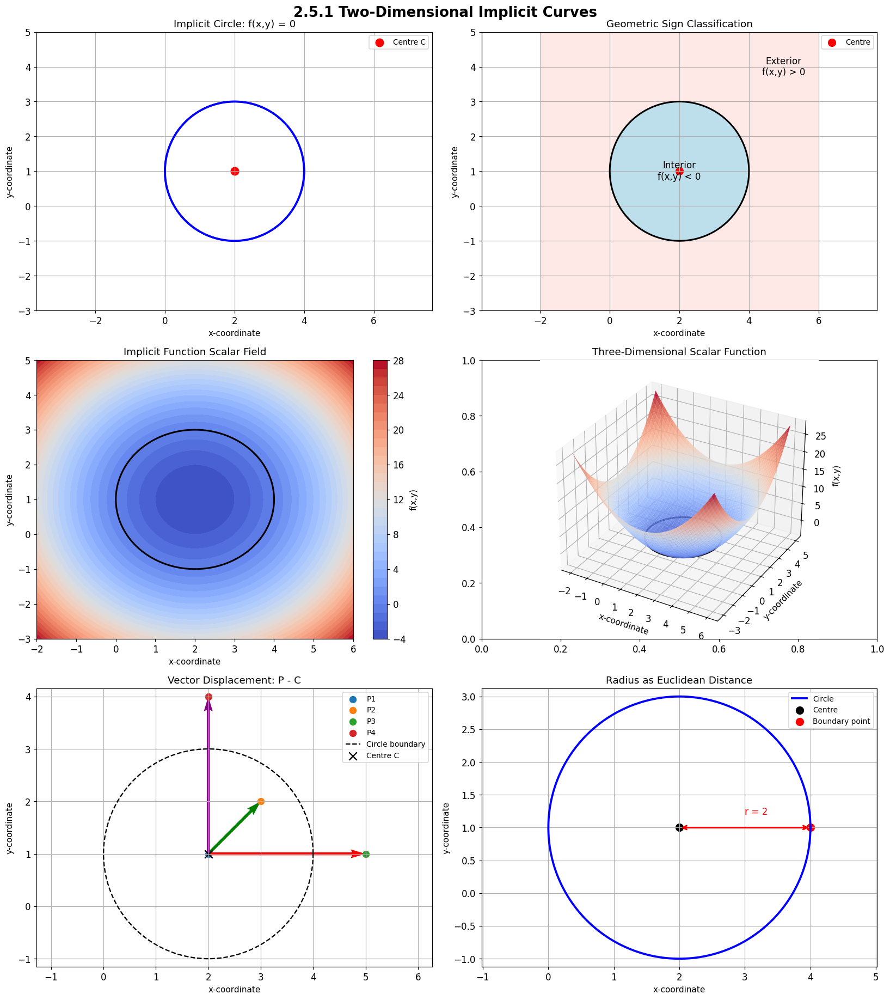

/tmp/ipykernel_494/457752248.py:432: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="best")


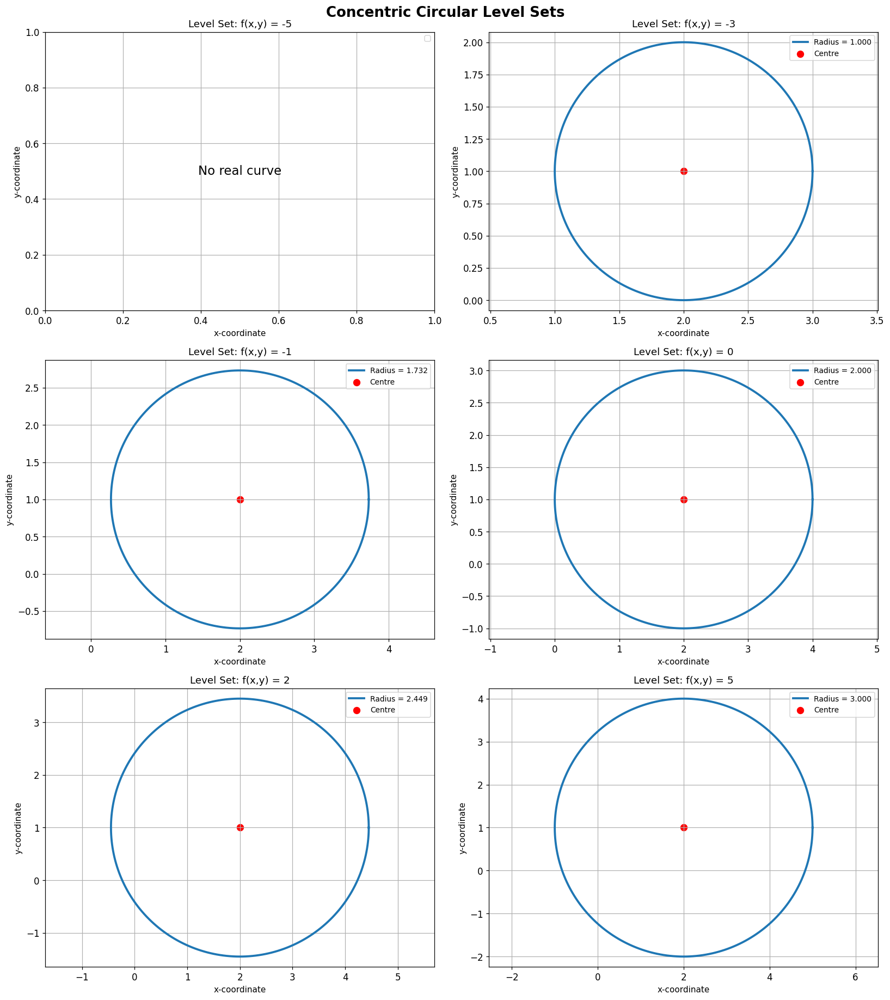

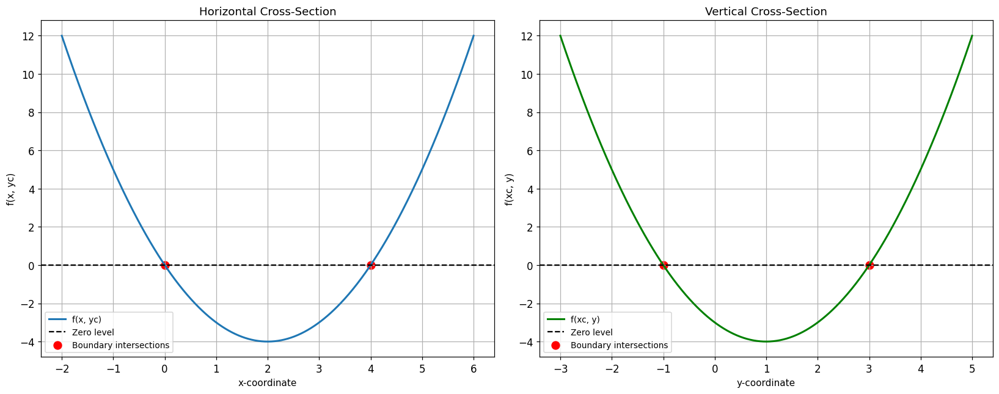

,x,y,Distance,"f(x,y)",Classification
0,2.0,1.0,0.000000,-4.0,Interior
1,3.0,1.0,1.000000,-3.0,Interior
2,4.0,1.0,2.000000,0.0,Boundary
3,5.0,1.0,3.000000,5.0,Exterior
4,2.0,3.0,2.000000,0.0,Boundary
5,2.0,4.0,3.000000,5.0,Exterior
6,1.0,2.0,1.414214,-2.0,Interior
7,0.0,0.0,2.236068,1.0,Exterior


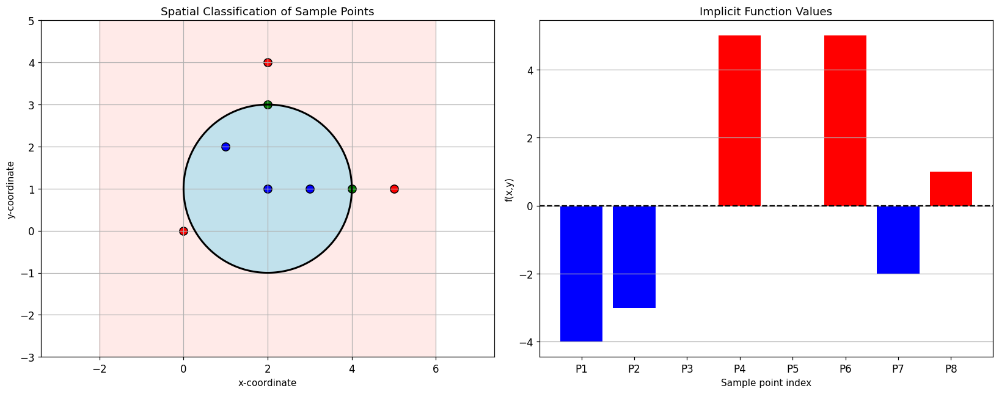

,x,y,Distance from centre,Implicit function
0,4.000000,1.000000,2.0,0.000000e+00
1,3.999960,1.012579,2.0,0.000000e+00
2,3.999842,1.025157,2.0,-8.881784e-16
3,3.999644,1.037735,2.0,8.881784e-16
4,3.999367,1.050310,2.0,8.881784e-16
5,3.999011,1.062884,2.0,8.881784e-16
6,3.998576,1.075456,2.0,-4.440892e-16
7,3.998062,1.088024,2.0,8.881784e-16
8,3.997469,1.100589,2.0,0.000000e+00
9,3.996797,1.113150,2.0,8.881784e-16


,Verification,Numerical result
0,Maximum absolute boundary residual,1.776357e-15
1,Maximum radius deviation,4.440892e-16
2,Expected radius,2.000000e+00
3,Computed mean radius,2.000000e+00


,Centre 1,Radius 1,Centre 2,Radius 2,Centre separation,Intersection status
0,"(0, 0)",2,"(5, 0)",2,5.0,Separate
1,"(0, 0)",2,"(4, 0)",2,4.0,Externally tangent
2,"(0, 0)",2,"(3, 0)",2,3.0,Intersecting at two points
3,"(0, 0)",3,"(1, 0)",2,1.0,Internally tangent
4,"(0, 0)",3,"(0.5, 0.0)",1,0.5,One circle inside another


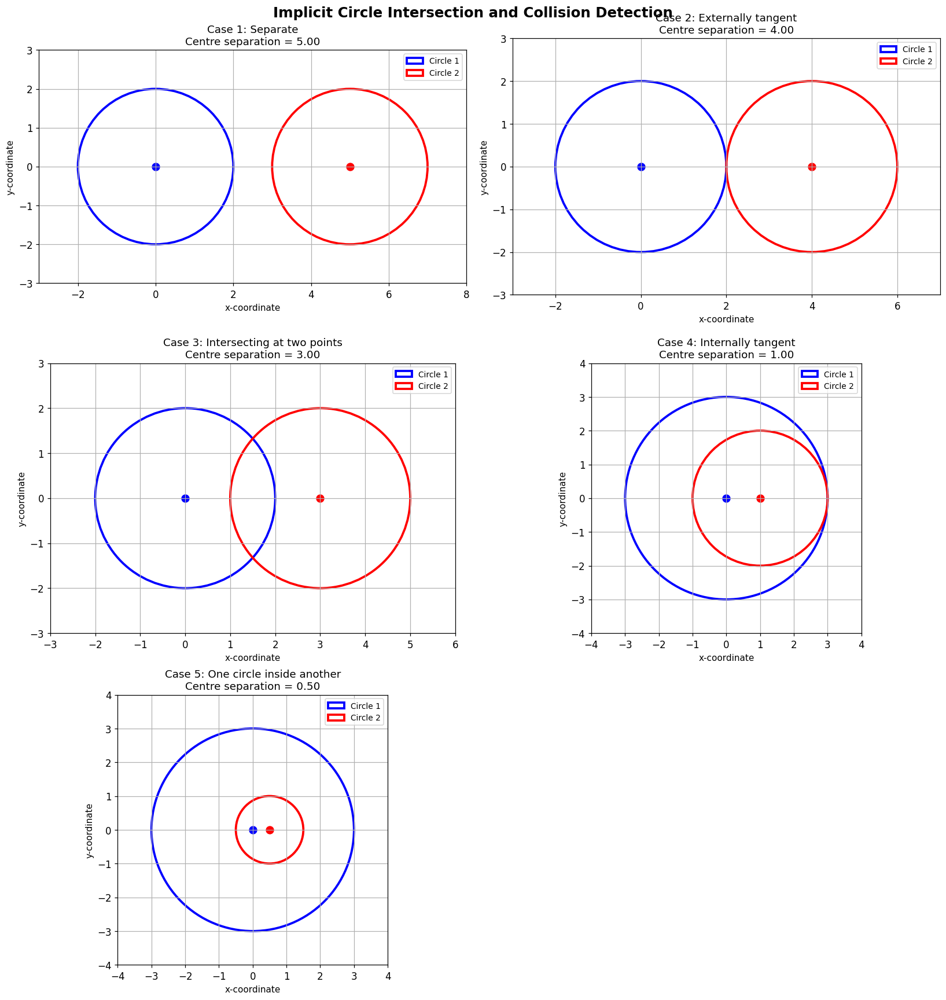

,Mathematical verification,Result
0,Scalar implicit equation,-2.0
1,Vector dot-product equation,-2.0
2,Scalar-vector difference,0.0
3,Euclidean distance,1.414214
4,Radius,2.0
5,Boundary residual,0.0
6,Boundary verification,True
7,Scalar-vector equivalence,True


In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle

# ============================================================
# 1. CONFIGURATION
# ============================================================

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 110
})

EPSILON = 1e-9

# Circle parameters
CENTER = np.array([2.0, 1.0])
RADIUS = 2.0

# ============================================================
# 2. MATHEMATICAL FUNCTIONS
# ============================================================

def implicit_circle(x, y, center=CENTER, radius=RADIUS):
    """
    f(x,y) = (x-xc)^2 + (y-yc)^2 - r^2
    """
    return (
        (x - center[0])**2
        + (y - center[1])**2
        - radius**2
    )


def vector_implicit(point, center=CENTER, radius=RADIUS):
    """
    f(P) = (P-C).(P-C) - r^2
    """
    displacement = np.asarray(point) - np.asarray(center)
    return np.dot(displacement, displacement) - radius**2


def distance_from_center(point, center=CENTER):
    """
    ||P-C||
    """
    return np.linalg.norm(np.asarray(point) - np.asarray(center))


def classify_point(point, center=CENTER, radius=RADIUS):
    """
    f(P) < 0 : interior
    f(P) = 0 : boundary
    f(P) > 0 : exterior
    """
    value = vector_implicit(point, center, radius)

    if np.isclose(value, 0.0, atol=EPSILON):
        return "Boundary"
    elif value < 0:
        return "Interior"
    else:
        return "Exterior"


def circle_parametric(center=CENTER, radius=RADIUS, samples=500):
    """
    x(t) = xc + r cos(t)
    y(t) = yc + r sin(t)
    """
    t = np.linspace(0, 2*np.pi, samples)

    x = center[0] + radius*np.cos(t)
    y = center[1] + radius*np.sin(t)

    return x, y


# ============================================================
# 3. COMPUTATIONAL GRID
# ============================================================

x = np.linspace(-2, 6, 400)
y = np.linspace(-3, 5, 400)

X, Y = np.meshgrid(x, y)

F = implicit_circle(X, Y)

circle_x, circle_y = circle_parametric()

# ============================================================
# 4. FIGURE 1: IMPLICIT CIRCLE AND GEOMETRIC REGIONS
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

# ------------------------------------------------------------
# 4.1 Implicit circle boundary
# ------------------------------------------------------------

ax = axes[0, 0]

ax.contour(
    X, Y, F,
    levels=[0],
    colors="blue",
    linewidths=2.5
)

ax.scatter(
    CENTER[0], CENTER[1],
    color="red",
    s=90,
    label="Centre C"
)

ax.plot(
    circle_x, circle_y,
    color="blue",
    linewidth=2
)

ax.set_title("Implicit Circle: f(x,y) = 0")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.axis("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 4.2 Interior and exterior regions
# ------------------------------------------------------------

ax = axes[0, 1]

ax.contourf(
    X, Y, F,
    levels=[-100, 0, 100],
    colors=["lightblue", "mistyrose"],
    alpha=0.8
)

ax.contour(
    X, Y, F,
    levels=[0],
    colors="black",
    linewidths=2
)

ax.scatter(
    CENTER[0], CENTER[1],
    color="red",
    s=80,
    label="Centre"
)

ax.text(2, 1, "Interior\nf(x,y) < 0",
        ha="center", va="center", fontsize=11)

ax.text(5, 4, "Exterior\nf(x,y) > 0",
        ha="center", va="center", fontsize=11)

ax.set_title("Geometric Sign Classification")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.axis("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 4.3 Scalar field representation
# ------------------------------------------------------------

ax = axes[1, 0]

surface = ax.contourf(
    X, Y, F,
    levels=35,
    cmap="coolwarm"
)

ax.contour(
    X, Y, F,
    levels=[0],
    colors="black",
    linewidths=2
)

fig.colorbar(surface, ax=ax, label="f(x,y)")

ax.set_title("Implicit Function Scalar Field")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")

# ------------------------------------------------------------
# 4.4 Three-dimensional implicit surface
# ------------------------------------------------------------

ax = fig.add_subplot(3, 2, 4, projection="3d")

ax.plot_surface(
    X, Y, F,
    cmap="coolwarm",
    alpha=0.85,
    linewidth=0
)

ax.contour(
    X, Y, F,
    levels=[0],
    colors="black",
    offset=0,
    linewidths=2
)

ax.set_title("Three-Dimensional Scalar Function")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_zlabel("f(x,y)")

# ------------------------------------------------------------
# 4.5 Vector representation
# ------------------------------------------------------------

ax = axes[2, 0]

test_points = [
    np.array([2.0, 1.0]),
    np.array([3.0, 2.0]),
    np.array([5.0, 1.0]),
    np.array([2.0, 4.0])
]

for i, point in enumerate(test_points):

    displacement = point - CENTER

    ax.quiver(
        CENTER[0], CENTER[1],
        displacement[0], displacement[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        color=["blue", "green", "red", "purple"][i]
    )

    ax.scatter(
        point[0], point[1],
        s=60,
        label=f"P{i+1}"
    )

ax.plot(circle_x, circle_y, "k--", label="Circle boundary")

ax.scatter(
    CENTER[0], CENTER[1],
    color="black",
    s=90,
    marker="x",
    label="Centre C"
)

ax.set_title("Vector Displacement: P - C")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.axis("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 4.6 Radius and distance verification
# ------------------------------------------------------------

ax = axes[2, 1]

ax.plot(
    circle_x,
    circle_y,
    color="blue",
    linewidth=2.5,
    label="Circle"
)

boundary_point = CENTER + np.array([RADIUS, 0])

ax.annotate(
    "",
    xy=boundary_point,
    xytext=CENTER,
    arrowprops=dict(arrowstyle="<->", color="red", lw=2)
)

ax.scatter(
    CENTER[0], CENTER[1],
    color="black",
    s=80,
    label="Centre"
)

ax.scatter(
    boundary_point[0], boundary_point[1],
    color="red",
    s=80,
    label="Boundary point"
)

ax.text(
    CENTER[0] + RADIUS/2,
    CENTER[1] + 0.2,
    "r = 2",
    color="red"
)

ax.set_title("Radius as Euclidean Distance")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.axis("equal")
ax.grid(True)
ax.legend()

plt.suptitle(
    "2.5.1 Two-Dimensional Implicit Curves",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. LEVEL SETS
# ============================================================

# General function:
# f(x,y) = (x-xc)^2 + (y-yc)^2 - r^2
#
# Level set:
# f(x,y) = k
#
# Therefore:
# (x-xc)^2 + (y-yc)^2 = r^2 + k

level_values = [-5, -3, -1, 0, 2, 5]

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

axes = axes.flatten()

level_data = []

for ax, k in zip(axes, level_values):

    radius_squared = RADIUS**2 + k

    if radius_squared > 0:

        level_radius = np.sqrt(radius_squared)

        lx, ly = circle_parametric(
            CENTER,
            level_radius
        )

        ax.plot(
            lx, ly,
            linewidth=2.5,
            label=f"Radius = {level_radius:.3f}"
        )

        ax.scatter(
            CENTER[0], CENTER[1],
            color="red",
            s=60,
            label="Centre"
        )

        ax.axis("equal")

        level_data.append({
            "Level k": k,
            "Radius squared": radius_squared,
            "Radius": level_radius,
            "Geometric result": "Circle"
        })

    elif np.isclose(radius_squared, 0):

        ax.scatter(
            CENTER[0], CENTER[1],
            color="red",
            s=100,
            label="Single point"
        )

        level_data.append({
            "Level k": k,
            "Radius squared": radius_squared,
            "Radius": 0.0,
            "Geometric result": "Single point"
        })

    else:

        ax.text(
            0.5, 0.5,
            "No real curve",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=15
        )

        level_data.append({
            "Level k": k,
            "Radius squared": radius_squared,
            "Radius": np.nan,
            "Geometric result": "No real curve"
        })

    ax.set_title(f"Level Set: f(x,y) = {k}")
    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")
    ax.grid(True)
    ax.legend(loc="best")

plt.suptitle(
    "Concentric Circular Level Sets",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. HORIZONTAL AND VERTICAL CROSS-SECTIONS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Horizontal cross-section through centre
ax = axes[0]

x_line = np.linspace(-2, 6, 500)
y_fixed = CENTER[1]

f_horizontal = implicit_circle(
    x_line,
    y_fixed
)

ax.plot(
    x_line,
    f_horizontal,
    linewidth=2,
    label="f(x, yc)"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    label="Zero level"
)

ax.scatter(
    [CENTER[0] - RADIUS, CENTER[0] + RADIUS],
    [0, 0],
    color="red",
    s=70,
    label="Boundary intersections"
)

ax.set_title("Horizontal Cross-Section")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("f(x, yc)")
ax.grid(True)
ax.legend()

# Vertical cross-section through centre
ax = axes[1]

y_line = np.linspace(-3, 5, 500)
x_fixed = CENTER[0]

f_vertical = implicit_circle(
    x_fixed,
    y_line
)

ax.plot(
    y_line,
    f_vertical,
    linewidth=2,
    color="green",
    label="f(xc, y)"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    label="Zero level"
)

ax.scatter(
    [CENTER[1] - RADIUS, CENTER[1] + RADIUS],
    [0, 0],
    color="red",
    s=70,
    label="Boundary intersections"
)

ax.set_title("Vertical Cross-Section")
ax.set_xlabel("y-coordinate")
ax.set_ylabel("f(xc, y)")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. POINT CLASSIFICATION
# ============================================================

sample_points = np.array([
    [2.0, 1.0],
    [3.0, 1.0],
    [4.0, 1.0],
    [5.0, 1.0],
    [2.0, 3.0],
    [2.0, 4.0],
    [1.0, 2.0],
    [0.0, 0.0]
])

classification_results = []

for point in sample_points:

    implicit_value = vector_implicit(point)

    distance = distance_from_center(point)

    classification_results.append({
        "x": point[0],
        "y": point[1],
        "Distance": distance,
        "f(x,y)": implicit_value,
        "Classification": classify_point(point)
    })

classification_df = pd.DataFrame(
    classification_results
)

display(classification_df)


# ============================================================
# 8. VISUAL POINT CLASSIFICATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]

ax.contourf(
    X, Y, F,
    levels=[-100, 0, 100],
    colors=["lightblue", "mistyrose"],
    alpha=0.75
)

ax.contour(
    X, Y, F,
    levels=[0],
    colors="black",
    linewidths=2
)

for point in sample_points:

    category = classify_point(point)

    if category == "Interior":
        color = "blue"
    elif category == "Boundary":
        color = "green"
    else:
        color = "red"

    ax.scatter(
        point[0], point[1],
        color=color,
        s=75,
        edgecolors="black"
    )

ax.set_title("Spatial Classification of Sample Points")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.axis("equal")
ax.grid(True)

ax = axes[1]

colors = [
    "blue" if c == "Interior"
    else "green" if c == "Boundary"
    else "red"
    for c in classification_df["Classification"]
]

ax.bar(
    range(len(classification_df)),
    classification_df["f(x,y)"],
    color=colors
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title("Implicit Function Values")
ax.set_xlabel("Sample point index")
ax.set_ylabel("f(x,y)")
ax.set_xticks(range(len(classification_df)))
ax.set_xticklabels(
    [f"P{i+1}" for i in range(len(classification_df))]
)
ax.grid(True, axis="y")

plt.tight_layout()
plt.show()


# ============================================================
# 9. NUMERICAL BOUNDARY VERIFICATION
# ============================================================

boundary_x, boundary_y = circle_parametric(
    CENTER,
    RADIUS,
    samples=1000
)

boundary_points = np.column_stack([
    boundary_x,
    boundary_y
])

boundary_values = np.array([
    vector_implicit(point)
    for point in boundary_points
])

boundary_distances = np.array([
    distance_from_center(point)
    for point in boundary_points
])

boundary_df = pd.DataFrame({
    "x": boundary_x[:10],
    "y": boundary_y[:10],
    "Distance from centre": boundary_distances[:10],
    "Implicit function": boundary_values[:10]
})

display(boundary_df)

boundary_error = np.max(np.abs(boundary_values))
distance_error = np.max(np.abs(boundary_distances - RADIUS))

verification_df = pd.DataFrame({
    "Verification": [
        "Maximum absolute boundary residual",
        "Maximum radius deviation",
        "Expected radius",
        "Computed mean radius"
    ],
    "Numerical result": [
        boundary_error,
        distance_error,
        RADIUS,
        np.mean(boundary_distances)
    ]
})

display(verification_df)


# ============================================================
# 10. CIRCLE INTERSECTION AND COLLISION DETECTION
# ============================================================

def circle_intersection_status(
    center1,
    radius1,
    center2,
    radius2
):
    """
    Classifies two circles using centre separation d.

    d > r1+r2: separate
    d = r1+r2: externally tangent
    |r1-r2| < d < r1+r2: intersecting
    d = |r1-r2|: internally tangent
    d < |r1-r2|: one circle inside the other
    """

    d = np.linalg.norm(
        np.asarray(center2) - np.asarray(center1)
    )

    if np.isclose(d, 0) and np.isclose(radius1, radius2):
        status = "Coincident"

    elif np.isclose(d, radius1 + radius2):
        status = "Externally tangent"

    elif np.isclose(d, abs(radius1 - radius2)):
        status = "Internally tangent"

    elif d > radius1 + radius2:
        status = "Separate"

    elif d < abs(radius1 - radius2):
        status = "One circle inside another"

    else:
        status = "Intersecting at two points"

    return d, status


collision_cases = [
    (np.array([0, 0]), 2, np.array([5, 0]), 2),
    (np.array([0, 0]), 2, np.array([4, 0]), 2),
    (np.array([0, 0]), 2, np.array([3, 0]), 2),
    (np.array([0, 0]), 3, np.array([1, 0]), 2),
    (np.array([0, 0]), 3, np.array([0.5, 0]), 1)
]

collision_results = []

for c1, r1, c2, r2 in collision_cases:

    separation, status = circle_intersection_status(
        c1, r1, c2, r2
    )

    collision_results.append({
        "Centre 1": tuple(c1),
        "Radius 1": r1,
        "Centre 2": tuple(c2),
        "Radius 2": r2,
        "Centre separation": separation,
        "Intersection status": status
    })

collision_df = pd.DataFrame(collision_results)

display(collision_df)


# ============================================================
# 11. COLLISION DETECTION VISUALISATION
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 16))

for i, (ax, case) in enumerate(
    zip(axes.flatten(), collision_cases)
):

    c1, r1, c2, r2 = case

    separation, status = circle_intersection_status(
        c1, r1, c2, r2
    )

    circle1 = Circle(
        c1,
        r1,
        fill=False,
        linewidth=2.5,
        color="blue",
        label="Circle 1"
    )

    circle2 = Circle(
        c2,
        r2,
        fill=False,
        linewidth=2.5,
        color="red",
        label="Circle 2"
    )

    ax.add_patch(circle1)
    ax.add_patch(circle2)

    ax.scatter(
        c1[0], c1[1],
        color="blue",
        s=70
    )

    ax.scatter(
        c2[0], c2[1],
        color="red",
        s=70
    )

    ax.set_xlim(
        min(c1[0]-r1, c2[0]-r2)-1,
        max(c1[0]+r1, c2[0]+r2)+1
    )

    ax.set_ylim(
        min(c1[1]-r1, c2[1]-r2)-1,
        max(c1[1]+r1, c2[1]+r2)+1
    )

    ax.set_aspect("equal")

    ax.set_title(
        f"Case {i+1}: {status}\n"
        f"Centre separation = {separation:.2f}"
    )

    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")
    ax.grid(True)
    ax.legend()

axes[-1, -1].axis("off")

plt.suptitle(
    "Implicit Circle Intersection and Collision Detection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. FINAL MATHEMATICAL VERIFICATION
# ============================================================

test_point = np.array([3.0, 2.0])

displacement = test_point - CENTER

scalar_form = (
    (test_point[0] - CENTER[0])**2
    + (test_point[1] - CENTER[1])**2
    - RADIUS**2
)

vector_form = np.dot(
    displacement,
    displacement
) - RADIUS**2

equation_residual = abs(scalar_form - vector_form)

verification = {
    "Scalar implicit equation": scalar_form,
    "Vector dot-product equation": vector_form,
    "Scalar-vector difference": equation_residual,
    "Euclidean distance": np.linalg.norm(displacement),
    "Radius": RADIUS,
    "Boundary residual": boundary_error,
    "Boundary verification": np.allclose(
        boundary_values, 0, atol=1e-10
    ),
    "Scalar-vector equivalence": np.isclose(
        scalar_form, vector_form
    )
}

verification_table = pd.DataFrame(
    verification.items(),
    columns=["Mathematical verification", "Result"]
)

display(verification_table)

assert np.isclose(scalar_form, vector_form)
assert np.allclose(boundary_values, 0, atol=1e-10)
assert np.allclose(boundary_distances, RADIUS)
assert np.isclose(distance_from_center(CENTER), 0)

plt.show()


### 2.5.2 The Two-Dimensional Gradient

The **gradient** is a vector describing the direction and maximum rate of increase of a differentiable scalar function. For an implicit curve, it provides the normal direction perpendicular to the curve.

**1. Mathematical Definition**

For a function $f(x,y)$, its gradient is:

$$
\nabla f(x,y)=
\left(\frac{\partial f}{\partial x},
\frac{\partial f}{\partial y}\right)
$$

Here, $\nabla$ denotes the gradient operator, while the partial derivatives measure changes along the $x$ and $y$ directions. For a small displacement:

$$
\Delta f\approx
\frac{\partial f}{\partial x}\Delta x+
\frac{\partial f}{\partial y}\Delta y
=\nabla f\cdot\Delta\mathbf{p}
$$

This expresses the approximate function change as the gradient's dot product with displacement $\Delta\mathbf{p}$.

**2. Gradient and Curve Normals**

Along a level curve, the function remains constant; therefore:

$$
\nabla f\cdot\mathbf{t}=0
$$

The gradient is perpendicular to tangent vector $\mathbf{t}$ and defines the curve normal. For a unit circle:

$$
f(x,y)=x^2+y^2-1
$$

$$
\nabla f=(2x,2y)
$$

The gradient points outward. Multiplication of the implicit equation by a negative constant reverses its direction without changing the curve.

### 2.5.3 Implicit Two-Dimensional Lines

A straight line has slope-intercept representation:

$$
y=mx+b
$$

Here, $m$ is slope and $b$ is the vertical intercept. Its implicit form is:

$$
f(x,y)=y-mx-b=0
$$

The general representation is:

$$
Ax+By+C=0
$$

Its gradient $(A,B)$ is perpendicular to the line.

**Deriving a Line Through Two Points**

Given $P_0=(x_0,y_0)$ and $P_1=(x_1,y_1)$:

$$
\mathbf{d}=(x_1-x_0,y_1-y_0)
$$

A perpendicular normal is:

$$
\mathbf{n}=(y_0-y_1,x_1-x_0)
$$

Substituting $P_0$ into the general equation gives:

$$
C=x_0y_1-x_1y_0
$$

Therefore:

$$
(y_0-y_1)x+(x_1-x_0)y+x_0y_1-x_1y_0=0
$$

### 2.5.4 Applications

Gradients support surface normals, lighting and geometric classification. Implicit lines enable intersection testing and spatial partitioning. Together, these formulations underpin geometric modelling and computational analysis.

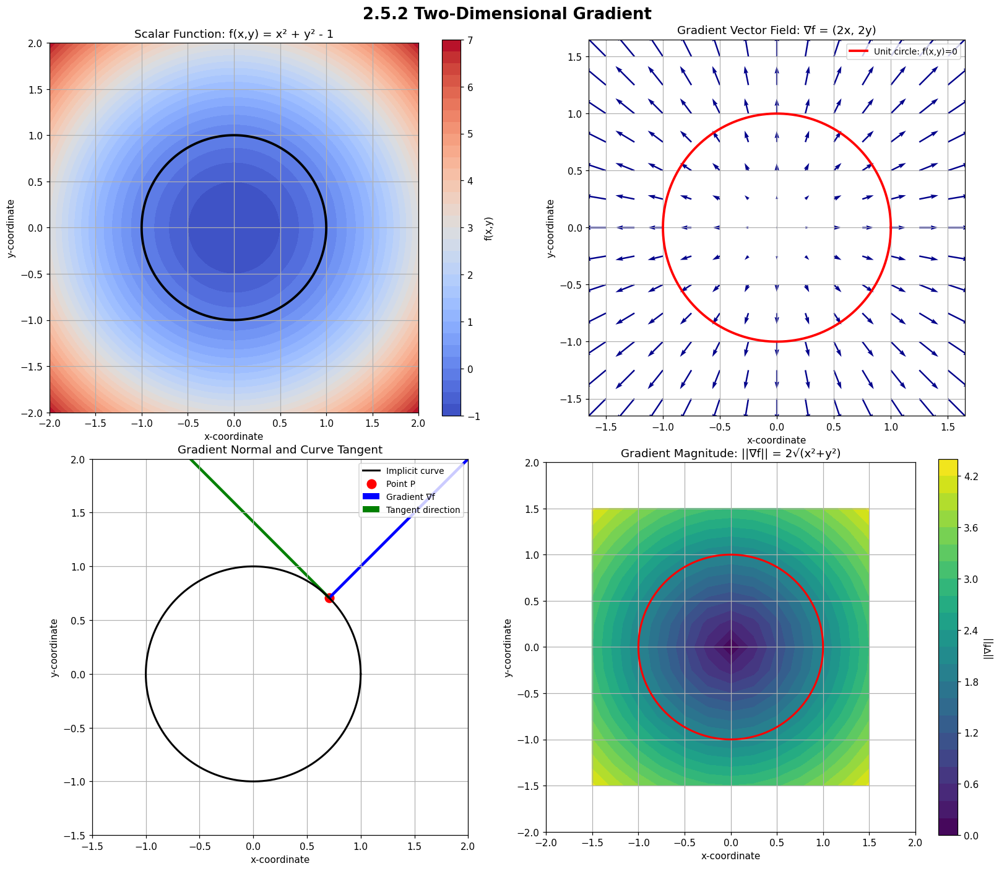

,Point,Gradient x,Gradient y,Gradient magnitude,Unit normal x,Unit normal y,Tangent x,Tangent y,Gradient dot tangent
0,"(1.0, 0.0)",2.000000,0.000000,2.0,1.000000,0.000000,-0.000000,1.000000,0.0
1,"(0.0, 1.0)",0.000000,2.000000,2.0,0.000000,1.000000,-1.000000,0.000000,0.0
2,"(0.7071067811865476, 0.7071067811865476)",1.414214,1.414214,2.0,0.707107,0.707107,-0.707107,0.707107,0.0
3,"(-1.0, 0.0)",-2.000000,0.000000,2.0,-1.000000,0.000000,-0.000000,-1.000000,0.0
4,"(0.0, -1.0)",0.000000,-2.000000,2.0,0.000000,-1.000000,1.000000,0.000000,0.0


,Direction,Unit x,Unit y,Directional derivative
0,Outward normal,1.000000,0.000000,2.000000
1,Inward normal,-1.000000,0.000000,-2.000000
2,Positive tangent,0.000000,1.000000,0.000000
3,Negative tangent,0.000000,-1.000000,0.000000
4,Diagonal,0.707107,0.707107,1.414214


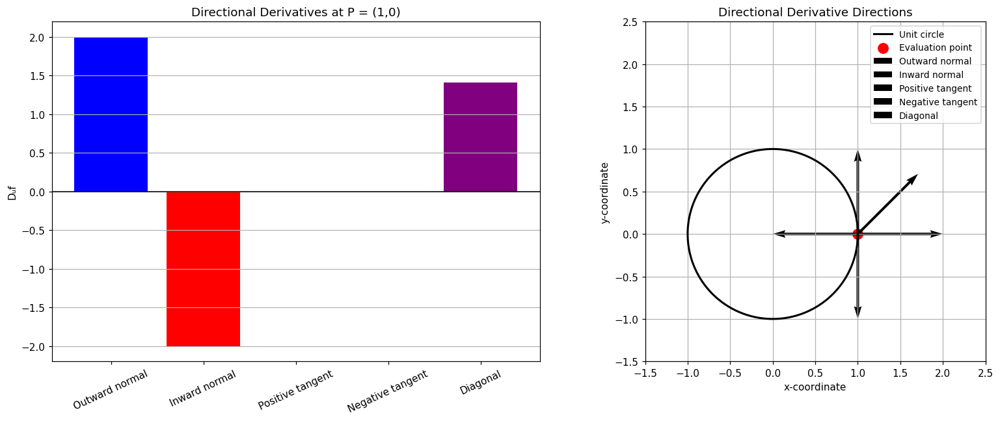

,x,y,Exact df/dx,Numerical df/dx,Exact df/dy,Numerical df/dy,Gradient error
0,0.5,0.50,1.0,1.0,1.0,1.0,1.414339e-12
1,1.0,0.00,2.0,2.0,0.0,0.0,2.000178e-12
2,0.0,1.00,0.0,0.0,2.0,2.0,2.000178e-12
3,-0.5,0.75,-1.0,-1.0,1.5,1.5,6.899627e-12
4,1.2,-0.80,2.4,2.4,-1.6,-1.6,2.884599e-12


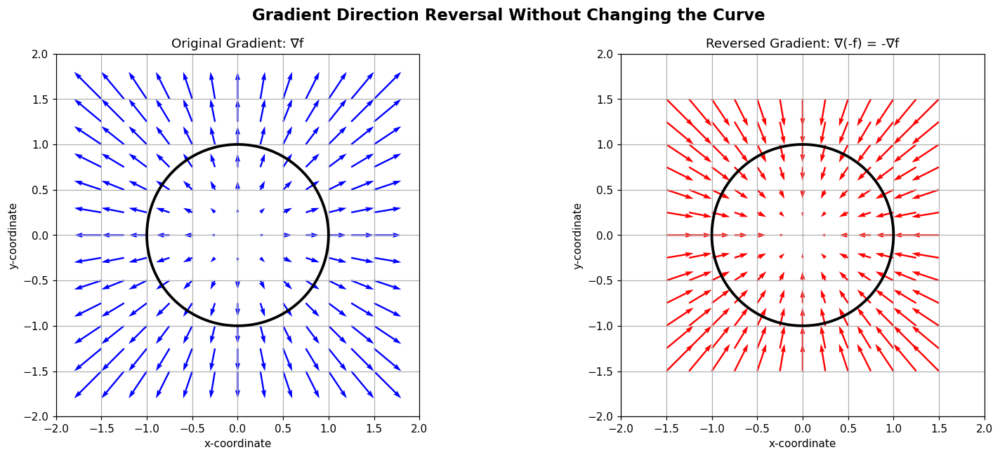

,Quantity,Value
0,Point P0,"(1.0, 2.0)"
1,Point P1,"(5.0, 4.0)"
2,Direction vector,"(4.0, 2.0)"
3,Normal vector,"(-2.0, 4.0)"
4,Coefficient A,-2.0
5,Coefficient B,4.0
6,Coefficient C,-6.0
7,Slope,0.5


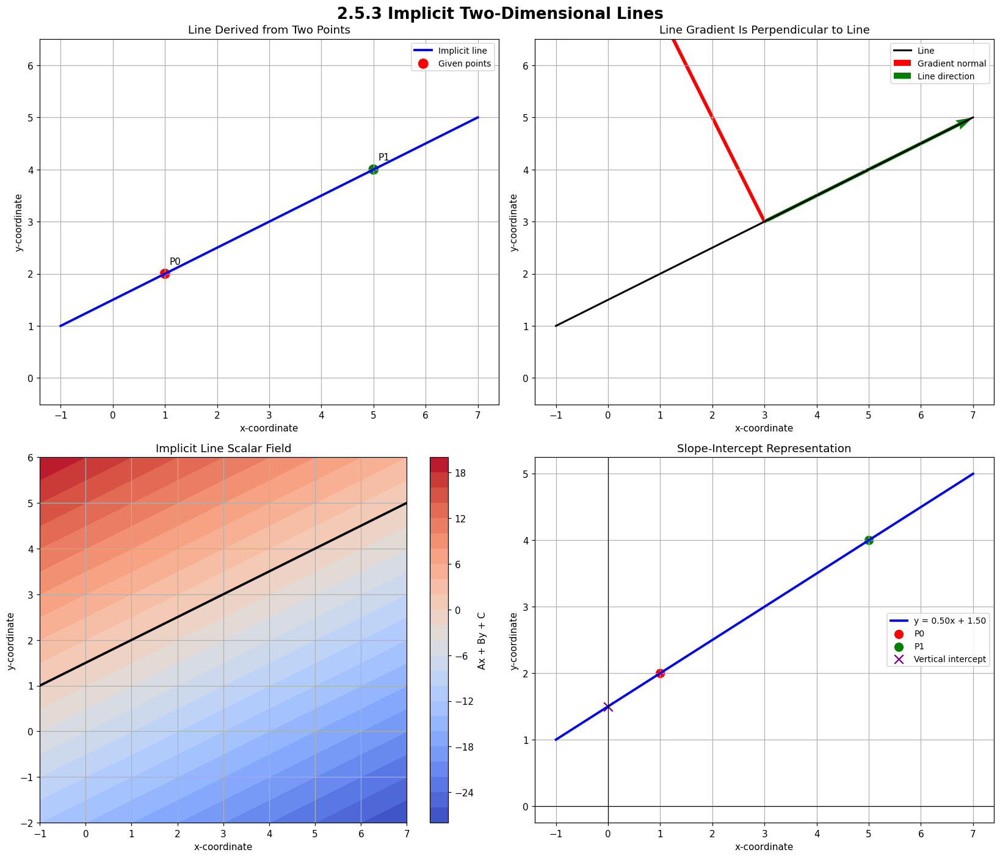

,Property,Result
0,Normal vector,"(-2.0, 4.0)"
1,Direction vector,"(4.0, 2.0)"
2,Normal magnitude,4.472136
3,Direction magnitude,4.472136
4,Normal dot direction,0.0
5,Perpendicularity verified,True


,Point,Perpendicular distance,Projected x,Projected y,Projection residual
0,"(2.0, 5.0)",2.236068,3.0,3.0,0.0
1,"(4.0, 1.0)",2.236068,3.0,3.0,0.0
2,"(0.0, 0.0)",1.341641,-0.6,1.2,0.0
3,"(3.0, 3.0)",0.000000,3.0,3.0,0.0


,Point,Implicit value,Classification
0,"(1.0, 2.0)",0.0,On line
1,"(5.0, 4.0)",0.0,On line
2,"(2.0, 5.0)",10.0,Positive half-plane
3,"(4.0, 1.0)",-10.0,Negative half-plane
4,"(0.0, 0.0)",-6.0,Negative half-plane


,Line,A,B,C
0,Line 1,-2.0,4.0,-6.0
1,Line 2,1.0,1.0,-4.0


,Quantity,Value
0,Intersection x,1.666667
1,Intersection y,2.333333
2,Line 1 residual,0.000000
3,Line 2 residual,0.000000


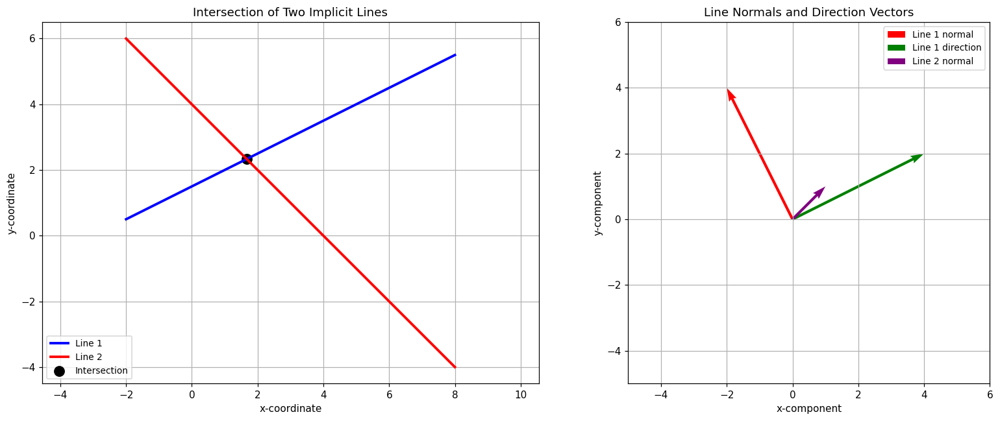

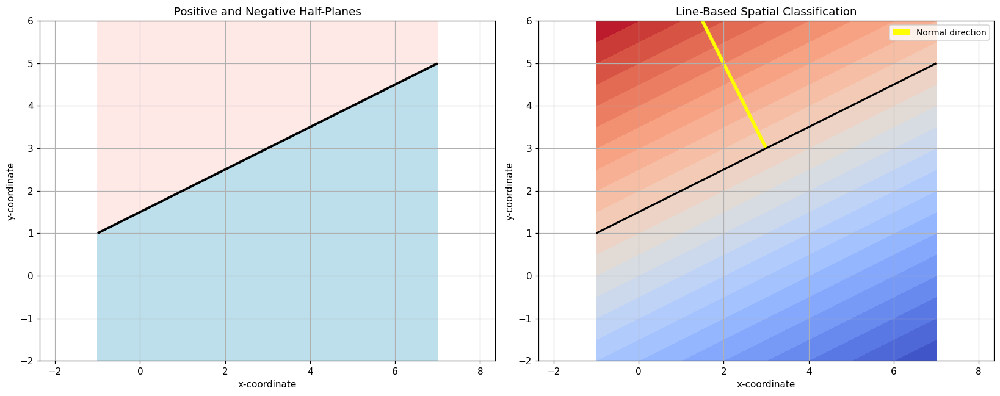

,Verification,Result
0,Gradient analytical/numerical agreement,True
1,Gradient perpendicular to tangent,True
2,Line passes through P0,True
3,Line passes through P1,True
4,Line normal perpendicular to direction,True
5,Projection lies on line,True
6,Intersection satisfies line 1,True
7,Intersection satisfies line 2,True


In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

plt.rcParams.update({
    "figure.figsize": (15, 6),
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9
})

EPS = 1e-9

# ============================================================
# 2. TWO-DIMENSIONAL GRADIENT FUNCTIONS
# ============================================================

def scalar_function(x, y):
    """
    f(x,y) = x^2 + y^2 - 1
    """
    return x**2 + y**2 - 1


def analytical_gradient(x, y):
    """
    Gradient:
    ∇f = (df/dx, df/dy) = (2x, 2y)
    """
    return np.array([2*x, 2*y], dtype=float)


def numerical_gradient(function, x, y, h=1e-5):
    """
    Central finite-difference approximation.

    df/dx ≈ [f(x+h,y)-f(x-h,y)]/(2h)
    df/dy ≈ [f(x,y+h)-f(x,y-h)]/(2h)
    """
    dfdx = (
        function(x+h, y) - function(x-h, y)
    ) / (2*h)

    dfdy = (
        function(x, y+h) - function(x, y-h)
    ) / (2*h)

    return np.array([dfdx, dfdy])


def normalize(vector):
    magnitude = np.linalg.norm(vector)

    if magnitude < EPS:
        raise ValueError("Cannot normalize a zero vector.")

    return vector / magnitude


def tangent_from_gradient(gradient):
    """
    A perpendicular tangent direction:
    t = (-fy, fx)
    """
    return np.array([
        -gradient[1],
        gradient[0]
    ])


def directional_derivative(gradient, direction):
    """
    D_u f = ∇f . u
    """
    unit_direction = normalize(direction)
    return np.dot(gradient, unit_direction)


# ============================================================
# 3. COMPUTATIONAL DOMAIN
# ============================================================

x = np.linspace(-2.0, 2.0, 250)
y = np.linspace(-2.0, 2.0, 250)

X, Y = np.meshgrid(x, y)

Z = scalar_function(X, Y)

theta = np.linspace(0, 2*np.pi, 500)

circle_x = np.cos(theta)
circle_y = np.sin(theta)

# ============================================================
# 4. FIGURE 1: GRADIENT FIELD AND UNIT CIRCLE NORMALS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 13))

# ------------------------------------------------------------
# 4.1 Scalar function contour
# ------------------------------------------------------------

ax = axes[0, 0]

contours = ax.contourf(
    X, Y, Z,
    levels=35,
    cmap="coolwarm"
)

ax.contour(
    X, Y, Z,
    levels=[0],
    colors="black",
    linewidths=2.5
)

fig.colorbar(
    contours,
    ax=ax,
    label="f(x,y)"
)

ax.set_title("Scalar Function: f(x,y) = x² + y² - 1")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)

# ------------------------------------------------------------
# 4.2 Gradient vector field
# ------------------------------------------------------------

ax = axes[0, 1]

xq = np.linspace(-1.5, 1.5, 13)
yq = np.linspace(-1.5, 1.5, 13)

XQ, YQ = np.meshgrid(xq, yq)

GX = 2*XQ
GY = 2*YQ

ax.quiver(
    XQ, YQ, GX, GY,
    color="darkblue",
    angles="xy",
    scale_units="xy",
    scale=15,
    width=0.004
)

ax.plot(
    circle_x,
    circle_y,
    color="red",
    linewidth=2.5,
    label="Unit circle: f(x,y)=0"
)

ax.set_title("Gradient Vector Field: ∇f = (2x, 2y)")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 4.3 Gradient and tangent perpendicularity
# ------------------------------------------------------------

ax = axes[1, 0]

P = np.array([
    np.sqrt(0.5),
    np.sqrt(0.5)
])

G = analytical_gradient(P[0], P[1])
T = tangent_from_gradient(G)

ax.plot(
    circle_x,
    circle_y,
    color="black",
    linewidth=2,
    label="Implicit curve"
)

ax.scatter(
    P[0], P[1],
    color="red",
    s=90,
    label="Point P"
)

ax.quiver(
    P[0], P[1],
    G[0], G[1],
    color="blue",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Gradient ∇f"
)

ax.quiver(
    P[0], P[1],
    T[0], T[1],
    color="green",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Tangent direction"
)

ax.set_xlim(-1.5, 2)
ax.set_ylim(-1.5, 2)

ax.set_title("Gradient Normal and Curve Tangent")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 4.4 Gradient magnitude
# ------------------------------------------------------------

ax = axes[1, 1]

gradient_magnitude = np.sqrt(GX**2 + GY**2)

surface = ax.contourf(
    XQ, YQ,
    gradient_magnitude,
    levels=25,
    cmap="viridis"
)

fig.colorbar(
    surface,
    ax=ax,
    label="||∇f||"
)

ax.contour(
    X, Y, Z,
    levels=[0],
    colors="red",
    linewidths=2
)

ax.set_title("Gradient Magnitude: ||∇f|| = 2√(x²+y²)")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)

plt.suptitle(
    "2.5.2 Two-Dimensional Gradient",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. GRADIENT AND DIRECTIONAL DERIVATIVES
# ============================================================

sample_points = [
    np.array([1.0, 0.0]),
    np.array([0.0, 1.0]),
    np.array([np.sqrt(0.5), np.sqrt(0.5)]),
    np.array([-1.0, 0.0]),
    np.array([0.0, -1.0])
]

gradient_results = []

for point in sample_points:

    gradient = analytical_gradient(*point)

    tangent = normalize(
        tangent_from_gradient(gradient)
    )

    normal = normalize(gradient)

    gradient_results.append({
        "Point": tuple(point),
        "Gradient x": gradient[0],
        "Gradient y": gradient[1],
        "Gradient magnitude": np.linalg.norm(gradient),
        "Unit normal x": normal[0],
        "Unit normal y": normal[1],
        "Tangent x": tangent[0],
        "Tangent y": tangent[1],
        "Gradient dot tangent": np.dot(gradient, tangent)
    })

gradient_df = pd.DataFrame(gradient_results)

display(gradient_df)


# ============================================================
# 6. DIRECTIONAL DERIVATIVE ANALYSIS
# ============================================================

P = np.array([1.0, 0.0])

G = analytical_gradient(*P)

directions = {
    "Outward normal": np.array([1.0, 0.0]),
    "Inward normal": np.array([-1.0, 0.0]),
    "Positive tangent": np.array([0.0, 1.0]),
    "Negative tangent": np.array([0.0, -1.0]),
    "Diagonal": np.array([1.0, 1.0])
}

direction_results = []

for name, direction in directions.items():

    unit_direction = normalize(direction)

    derivative = directional_derivative(
        G,
        direction
    )

    direction_results.append({
        "Direction": name,
        "Unit x": unit_direction[0],
        "Unit y": unit_direction[1],
        "Directional derivative": derivative
    })

direction_df = pd.DataFrame(direction_results)

display(direction_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Directional derivative bar chart
ax = axes[0]

ax.bar(
    direction_df["Direction"],
    direction_df["Directional derivative"],
    color=["blue", "red", "green", "orange", "purple"]
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title("Directional Derivatives at P = (1,0)")
ax.set_ylabel("Dᵤf")
ax.tick_params(axis="x", rotation=25)
ax.grid(True, axis="y")

# Directional vectors
ax = axes[1]

ax.plot(
    circle_x,
    circle_y,
    color="black",
    linewidth=2,
    label="Unit circle"
)

ax.scatter(
    P[0], P[1],
    color="red",
    s=100,
    label="Evaluation point"
)

for name, direction in directions.items():

    u = normalize(direction)

    ax.quiver(
        P[0], P[1],
        u[0], u[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        label=name
    )

ax.set_xlim(-1.5, 2.5)
ax.set_ylim(-1.5, 2.5)

ax.set_title("Directional Derivative Directions")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. GRADIENT FINITE-DIFFERENCE VERIFICATION
# ============================================================

verification_points = [
    (0.5, 0.5),
    (1.0, 0.0),
    (0.0, 1.0),
    (-0.5, 0.75),
    (1.2, -0.8)
]

finite_difference_results = []

for px, py in verification_points:

    exact = analytical_gradient(px, py)

    approximate = numerical_gradient(
        scalar_function,
        px,
        py
    )

    error = np.linalg.norm(exact - approximate)

    finite_difference_results.append({
        "x": px,
        "y": py,
        "Exact df/dx": exact[0],
        "Numerical df/dx": approximate[0],
        "Exact df/dy": exact[1],
        "Numerical df/dy": approximate[1],
        "Gradient error": error
    })

finite_difference_df = pd.DataFrame(
    finite_difference_results
)

display(finite_difference_df)


# ============================================================
# 8. IMPLICIT CURVE SIGN REVERSAL
# ============================================================

def reversed_function(x, y):
    return -scalar_function(x, y)


def reversed_gradient(x, y):
    return -analytical_gradient(x, y)


fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]

ax.contour(
    X, Y,
    Z,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.quiver(
    XQ, YQ,
    GX, GY,
    color="blue",
    scale=40,
    label="∇f"
)

ax.set_title("Original Gradient: ∇f")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)

ax = axes[1]

ax.contour(
    X, Y,
    -Z,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.quiver(
    XQ, YQ,
    -GX, -GY,
    color="red",
    scale=40,
    label="∇(-f)"
)

ax.set_title("Reversed Gradient: ∇(-f) = -∇f")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)

plt.suptitle(
    "Gradient Direction Reversal Without Changing the Curve",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. IMPLICIT TWO-DIMENSIONAL LINE FUNCTIONS
# ============================================================

def line_function(x, y, A, B, C):
    """
    f(x,y) = Ax + By + C
    """
    return A*x + B*y + C


def line_gradient(A, B):
    """
    ∇f = (A,B)
    """
    return np.array([A, B], dtype=float)


def line_through_two_points(P0, P1):
    """
    d = (x1-x0, y1-y0)

    n = (y0-y1, x1-x0)

    C = x0*y1 - x1*y0

    Ax + By + C = 0
    """
    x0, y0 = P0
    x1, y1 = P1

    A = y0 - y1
    B = x1 - x0
    C = x0*y1 - x1*y0

    return A, B, C


def line_distance(point, A, B, C):
    """
    Perpendicular distance:
    |Ax+By+C| / sqrt(A²+B²)
    """
    x, y = point

    denominator = np.sqrt(A**2 + B**2)

    if denominator < EPS:
        raise ValueError("Invalid line coefficients.")

    return abs(A*x + B*y + C) / denominator


def line_projection(point, A, B, C):
    """
    Orthogonal projection of a point onto Ax+By+C=0.
    """
    x, y = point

    denominator = A**2 + B**2

    if denominator < EPS:
        raise ValueError("Invalid line coefficients.")

    value = A*x + B*y + C

    return np.array([
        x - A*value/denominator,
        y - B*value/denominator
    ])


# ============================================================
# 10. DERIVE A LINE THROUGH TWO POINTS
# ============================================================

P0 = np.array([1.0, 2.0])
P1 = np.array([5.0, 4.0])

A, B, C = line_through_two_points(P0, P1)

normal = line_gradient(A, B)

direction = P1 - P0

slope = (
    direction[1] / direction[0]
    if abs(direction[0]) > EPS
    else np.inf
)

line_results = pd.DataFrame({
    "Quantity": [
        "Point P0",
        "Point P1",
        "Direction vector",
        "Normal vector",
        "Coefficient A",
        "Coefficient B",
        "Coefficient C",
        "Slope"
    ],
    "Value": [
        tuple(P0),
        tuple(P1),
        tuple(direction),
        tuple(normal),
        A,
        B,
        C,
        slope
    ]
})

display(line_results)


# ============================================================
# 11. FIGURE 2: IMPLICIT LINE AND ITS GRADIENT
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 13))

line_x = np.linspace(-1, 7, 500)

line_y = (
    -A*line_x - C
) / B

# ------------------------------------------------------------
# 11.1 Line through two points
# ------------------------------------------------------------

ax = axes[0, 0]

ax.plot(
    line_x,
    line_y,
    color="blue",
    linewidth=2.5,
    label="Implicit line"
)

ax.scatter(
    [P0[0], P1[0]],
    [P0[1], P1[1]],
    color=["red", "green"],
    s=100,
    label="Given points"
)

ax.annotate("P0", P0, xytext=(5, 10),
            textcoords="offset points")

ax.annotate("P1", P1, xytext=(5, 10),
            textcoords="offset points")

ax.set_title("Line Derived from Two Points")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.legend()
ax.axis("equal")

# ------------------------------------------------------------
# 11.2 Gradient normal to line
# ------------------------------------------------------------

ax = axes[0, 1]

midpoint = (P0 + P1)/2

ax.plot(
    line_x,
    line_y,
    color="black",
    linewidth=2,
    label="Line"
)

ax.quiver(
    midpoint[0],
    midpoint[1],
    normal[0],
    normal[1],
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Gradient normal"
)

ax.quiver(
    midpoint[0],
    midpoint[1],
    direction[0],
    direction[1],
    color="green",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Line direction"
)

ax.set_title("Line Gradient Is Perpendicular to Line")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.legend()
ax.axis("equal")

# ------------------------------------------------------------
# 11.3 Implicit line scalar field
# ------------------------------------------------------------

ax = axes[1, 0]

LX, LY = np.meshgrid(
    np.linspace(-1, 7, 200),
    np.linspace(-2, 6, 200)
)

LF = line_function(LX, LY, A, B, C)

contour = ax.contourf(
    LX, LY,
    LF,
    levels=30,
    cmap="coolwarm"
)

ax.contour(
    LX, LY,
    LF,
    levels=[0],
    colors="black",
    linewidths=2.5
)

fig.colorbar(
    contour,
    ax=ax,
    label="Ax + By + C"
)

ax.set_title("Implicit Line Scalar Field")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)

# ------------------------------------------------------------
# 11.4 Line slope and intercept
# ------------------------------------------------------------

ax = axes[1, 1]

ax.plot(
    line_x,
    line_y,
    color="blue",
    linewidth=2.5,
    label=f"y = {slope:.2f}x + {(-C/B):.2f}"
)

ax.scatter(
    P0[0], P0[1],
    color="red",
    s=80,
    label="P0"
)

ax.scatter(
    P1[0], P1[1],
    color="green",
    s=80,
    label="P1"
)

y_intercept = -C/B

ax.scatter(
    0,
    y_intercept,
    color="purple",
    s=90,
    marker="x",
    label="Vertical intercept"
)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_title("Slope-Intercept Representation")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.legend()

plt.suptitle(
    "2.5.3 Implicit Two-Dimensional Lines",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. LINE NORMAL AND DIRECTIONAL PERPENDICULARITY
# ============================================================

dot_product = np.dot(normal, direction)

line_geometry_df = pd.DataFrame({
    "Property": [
        "Normal vector",
        "Direction vector",
        "Normal magnitude",
        "Direction magnitude",
        "Normal dot direction",
        "Perpendicularity verified"
    ],
    "Result": [
        tuple(normal),
        tuple(direction),
        np.linalg.norm(normal),
        np.linalg.norm(direction),
        dot_product,
        np.isclose(dot_product, 0)
    ]
})

display(line_geometry_df)


# ============================================================
# 13. POINT-TO-LINE DISTANCE AND PROJECTION
# ============================================================

test_points = [
    np.array([2.0, 5.0]),
    np.array([4.0, 1.0]),
    np.array([0.0, 0.0]),
    np.array([3.0, 3.0])
]

distance_results = []

for point in test_points:

    distance = line_distance(point, A, B, C)

    projected = line_projection(point, A, B, C)

    distance_results.append({
        "Point": tuple(point),
        "Perpendicular distance": distance,
        "Projected x": projected[0],
        "Projected y": projected[1],
        "Projection residual": line_function(
            projected[0],
            projected[1],
            A, B, C
        )
    })

distance_df = pd.DataFrame(distance_results)

display(distance_df)


# ============================================================
# 14. POINT CLASSIFICATION RELATIVE TO A LINE
# ============================================================

def classify_line_point(point, A, B, C):
    value = line_function(
        point[0],
        point[1],
        A, B, C
    )

    if np.isclose(value, 0, atol=EPS):
        return "On line"

    elif value > 0:
        return "Positive half-plane"

    else:
        return "Negative half-plane"


classification_points = np.array([
    [1.0, 2.0],
    [5.0, 4.0],
    [2.0, 5.0],
    [4.0, 1.0],
    [0.0, 0.0]
])

classification_results = []

for point in classification_points:

    classification_results.append({
        "Point": tuple(point),
        "Implicit value": line_function(
            point[0],
            point[1],
            A, B, C
        ),
        "Classification": classify_line_point(
            point, A, B, C
        )
    })

line_classification_df = pd.DataFrame(
    classification_results
)

display(line_classification_df)


# ============================================================
# 15. LINE INTERSECTION
# ============================================================

def line_intersection(line1, line2):
    """
    Solve:
    A1*x + B1*y = -C1
    A2*x + B2*y = -C2
    """
    A1, B1, C1 = line1
    A2, B2, C2 = line2

    matrix = np.array([
        [A1, B1],
        [A2, B2]
    ], dtype=float)

    constants = np.array([
        -C1,
        -C2
    ], dtype=float)

    determinant = np.linalg.det(matrix)

    if abs(determinant) < EPS:
        return None

    return np.linalg.solve(matrix, constants)


line1 = (A, B, C)

# Second line: x + y - 4 = 0
line2 = (1.0, 1.0, -4.0)

intersection = line_intersection(line1, line2)

intersection_results = pd.DataFrame({
    "Line": ["Line 1", "Line 2"],
    "A": [line1[0], line2[0]],
    "B": [line1[1], line2[1]],
    "C": [line1[2], line2[2]]
})

display(intersection_results)

if intersection is not None:

    intersection_verification = pd.DataFrame({
        "Quantity": [
            "Intersection x",
            "Intersection y",
            "Line 1 residual",
            "Line 2 residual"
        ],
        "Value": [
            intersection[0],
            intersection[1],
            line_function(*intersection, *line1),
            line_function(*intersection, *line2)
        ]
    })

    display(intersection_verification)


# ============================================================
# 16. LINE INTERSECTION VISUALISATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_x = np.linspace(-2, 8, 500)

line1_y = (-line1[0]*plot_x - line1[2])/line1[1]

line2_y = (-line2[0]*plot_x - line2[2])/line2[1]

ax = axes[0]

ax.plot(
    plot_x,
    line1_y,
    color="blue",
    linewidth=2.5,
    label="Line 1"
)

ax.plot(
    plot_x,
    line2_y,
    color="red",
    linewidth=2.5,
    label="Line 2"
)

if intersection is not None:

    ax.scatter(
        intersection[0],
        intersection[1],
        color="black",
        s=100,
        label="Intersection"
    )

ax.set_title("Intersection of Two Implicit Lines")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.legend()
ax.axis("equal")

# Direction and normal comparison
ax = axes[1]

ax.quiver(
    0, 0,
    normal[0], normal[1],
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Line 1 normal"
)

ax.quiver(
    0, 0,
    direction[0], direction[1],
    color="green",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Line 1 direction"
)

ax.quiver(
    0, 0,
    line2[0], line2[1],
    color="purple",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Line 2 normal"
)

ax.set_xlim(-5, 6)
ax.set_ylim(-5, 6)
ax.set_title("Line Normals and Direction Vectors")
ax.set_xlabel("x-component")
ax.set_ylabel("y-component")
ax.grid(True)
ax.legend()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()


# ============================================================
# 17. APPLICATION: IMPLICIT LINE SPATIAL PARTITIONING
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]

partition_field = line_function(
    LX, LY,
    A, B, C
)

ax.contourf(
    LX, LY,
    partition_field,
    levels=[-100, 0, 100],
    colors=["lightblue", "mistyrose"],
    alpha=0.8
)

ax.contour(
    LX, LY,
    partition_field,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.set_title("Positive and Negative Half-Planes")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.axis("equal")

ax = axes[1]

ax.contourf(
    LX, LY,
    partition_field,
    levels=30,
    cmap="coolwarm"
)

ax.contour(
    LX, LY,
    partition_field,
    levels=[0],
    colors="black",
    linewidths=2
)

ax.quiver(
    midpoint[0],
    midpoint[1],
    normal[0],
    normal[1],
    color="yellow",
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Normal direction"
)

ax.set_title("Line-Based Spatial Classification")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.grid(True)
ax.legend()
ax.axis("equal")

plt.tight_layout()
plt.show()


# ============================================================
# 18. FINAL MATHEMATICAL VERIFICATION
# ============================================================

verification_results = {
    "Gradient analytical/numerical agreement": np.allclose(
        analytical_gradient(0.5, 0.5),
        numerical_gradient(scalar_function, 0.5, 0.5),
        atol=1e-8
    ),

    "Gradient perpendicular to tangent": np.isclose(
        np.dot(
            analytical_gradient(*P),
            tangent_from_gradient(
                analytical_gradient(*P)
            )
        ),
        0
    ),

    "Line passes through P0": np.isclose(
        line_function(*P0, A, B, C),
        0
    ),

    "Line passes through P1": np.isclose(
        line_function(*P1, A, B, C),
        0
    ),

    "Line normal perpendicular to direction": np.isclose(
        np.dot(normal, direction),
        0
    ),

    "Projection lies on line": all(
        np.isclose(
            line_function(
                row["Projected x"],
                row["Projected y"],
                A, B, C
            ),
            0,
            atol=1e-8
        )
        for row in distance_results
    ),

    "Intersection satisfies line 1": (
        intersection is not None
        and np.isclose(
            line_function(*intersection, *line1),
            0
        )
    ),

    "Intersection satisfies line 2": (
        intersection is not None
        and np.isclose(
            line_function(*intersection, *line2),
            0
        )
    )
}

verification_df = pd.DataFrame(
    verification_results.items(),
    columns=["Verification", "Result"]
)

display(verification_df)

assert all(verification_results.values())

plt.show()


## 2.5.5 Implicit Quadric Curves

An **implicit quadric** is a two-dimensional curve defined by a second-degree polynomial equation:

$$
Ax^2+Bxy+Cy^2+Dx+Ey+F=0
$$

where $A,B,C,D,E,F$ are real coefficients. Quadric curves include ellipses, hyperbolas, parabolas and circles, with certain degenerate cases producing lines.

**Circle:** A circle centred at $(x_c,y_c)$ with radius $r$ satisfies:

$$
(x-x_c)^2+(y-y_c)^2-r^2=0
$$

**Ellipse:** An axis-aligned ellipse is represented by:

$$
\frac{(x-x_c)^2}{a^2}
+\frac{(y-y_c)^2}{b^2}-1=0
$$

Here, $(x_c,y_c)$ denotes the centre, while $a$ and $b$ represent the horizontal and vertical semiaxis lengths, respectively. When $a=b=r$, the ellipse becomes a circle, demonstrating that a circle is a special case of an ellipse.

## 2.5.6 Three-Dimensional Implicit Surfaces

An implicit surface is defined by:

$$
f(x,y,z)=0
$$

Equivalently, using position vector $\mathbf{p}=(x,y,z)$:

$$
f(\mathbf{p})=0
$$

Points satisfying the equation lie on the surface. Evaluating $f(\mathbf{p})$ identifies boundary membership, while its sign classifies points into positive and negative regions. However, implicit representations do not necessarily provide an explicit method for generating surface coordinates.

## 2.5.7 Surface Normal to an Implicit Surface

A **surface normal** is a vector perpendicular to the tangent plane at a surface point. For a differentiable implicit function, the normal is its gradient:

$$
\mathbf{n}=\nabla f(\mathbf{p})
=\left(
\frac{\partial f}{\partial x},
\frac{\partial f}{\partial y},
\frac{\partial f}{\partial z}
\right)
$$

The gradient indicates the direction of maximum increase of $f$ and is perpendicular to tangent directions along which $f$ remains constant. It points toward the region where $f(\mathbf{p})>0$. Replacing $f$ with $-f$ preserves the surface but reverses its normal:

$$
\nabla(-f(\mathbf{p}))=-\nabla f(\mathbf{p})
$$

**Applications:** Quadric equations support geometric modelling, while implicit surfaces and their normals underpin surface classification, lighting, shading and three-dimensional rendering.

,Quadric,A,B,C,Discriminant,Classification
0,Circle,1.000000,0,1.00,-4.000000,Ellipse-type
1,Ellipse,0.111111,0,0.25,-0.111111,Ellipse-type
2,Hyperbola,0.250000,0,-0.50,0.500000,Hyperbola-type
3,Parabola,0.000000,0,1.00,0.000000,Parabola-type


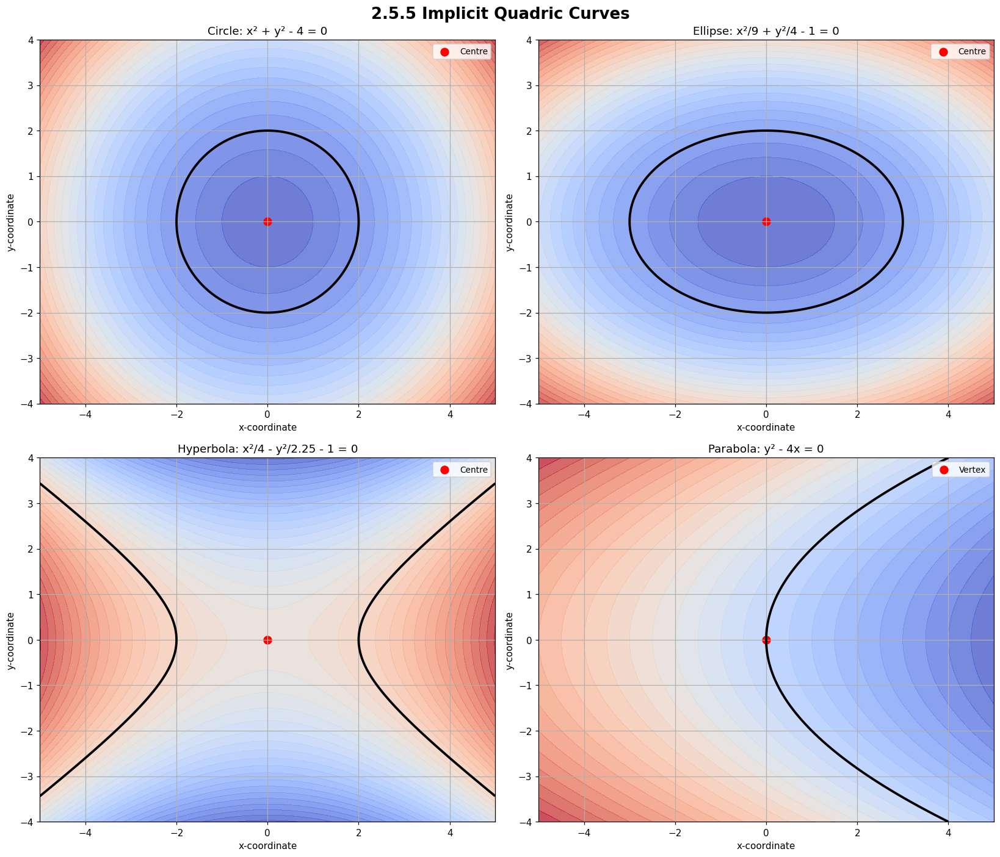

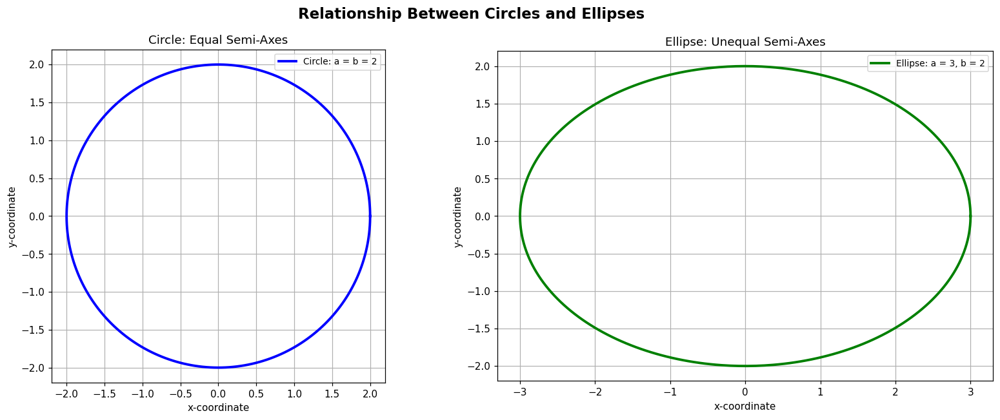

,Parameter angle,x-coordinate,y-coordinate,Implicit residual
0,0.000000,4.000000,-1.000000,0.000000e+00
1,0.012592,3.999762,-0.974818,0.000000e+00
2,0.025183,3.999049,-0.949639,2.220446e-16
3,0.037775,3.997860,-0.924469,0.000000e+00
4,0.050366,3.996196,-0.899310,0.000000e+00
5,0.062958,3.994056,-0.874168,0.000000e+00
6,0.075549,3.991443,-0.849045,0.000000e+00
7,0.088141,3.988354,-0.823946,-1.110223e-16
8,0.100732,3.984792,-0.798876,2.220446e-16
9,0.113324,3.980757,-0.773837,2.220446e-16


,Verification,Value
0,Maximum absolute implicit residual,4.440892e-16
1,Mean absolute implicit residual,6.905587e-17
2,Horizontal semi-axis,3.000000e+00
3,Vertical semi-axis,2.000000e+00


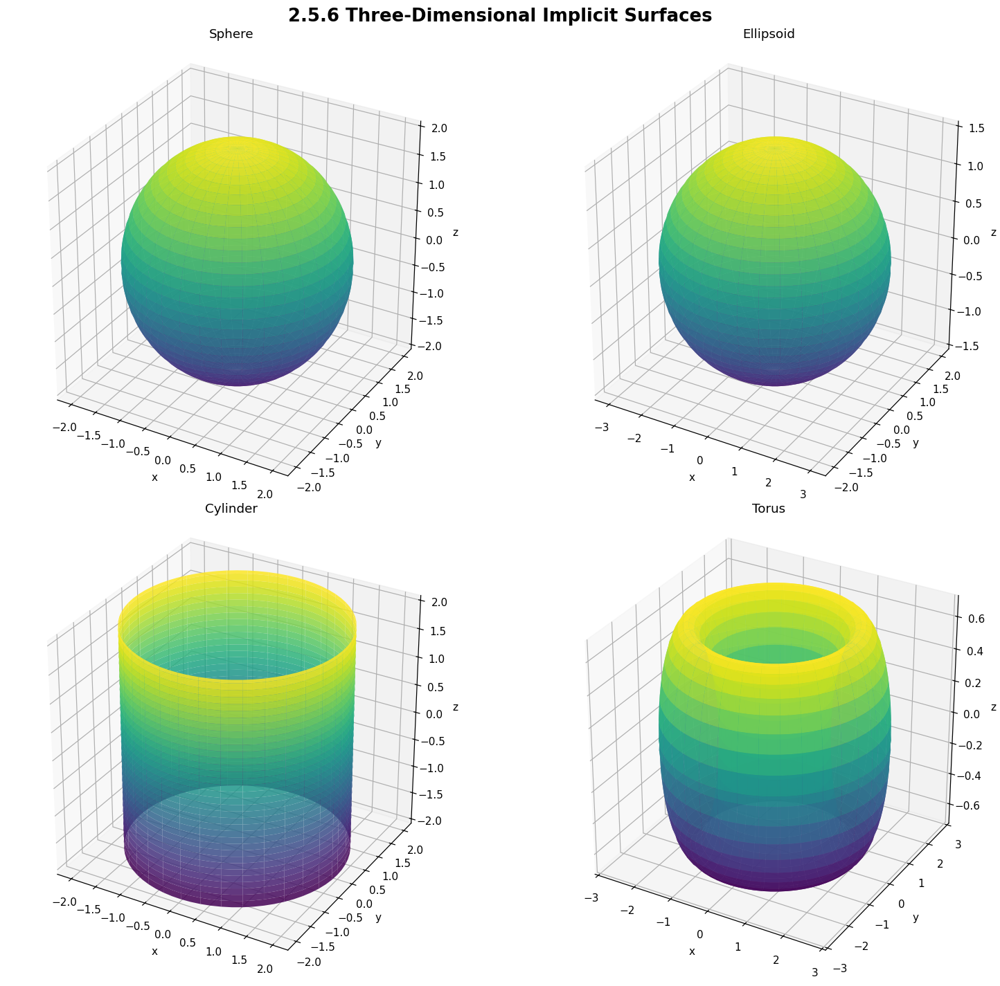

,x,y,z,Implicit function,Classification
0,0.0,0.0,0.0,-4.0,Negative region
1,2.0,0.0,0.0,0.0,Surface
2,3.0,0.0,0.0,5.0,Positive region
3,1.0,1.0,1.0,-1.0,Negative region
4,0.0,0.0,2.0,0.0,Surface
5,1.0,1.0,0.0,-2.0,Negative region


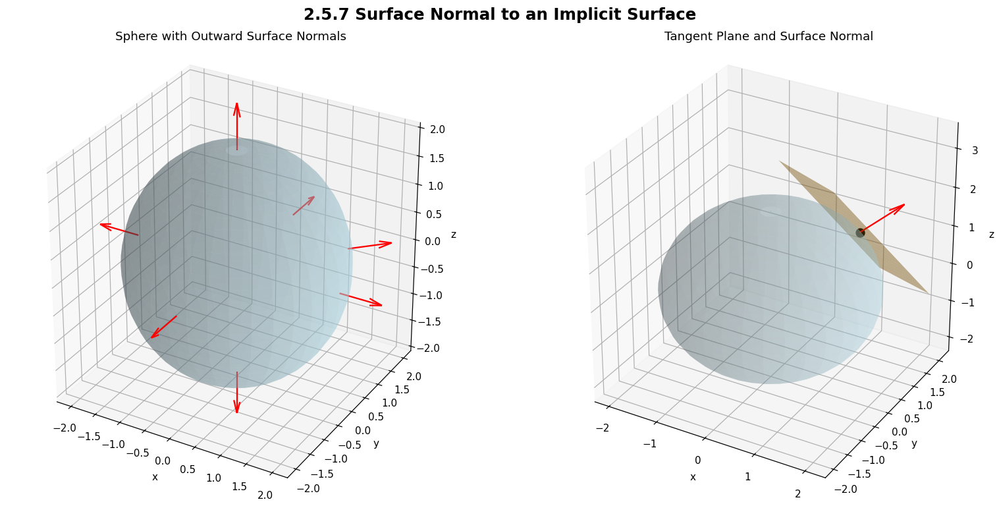

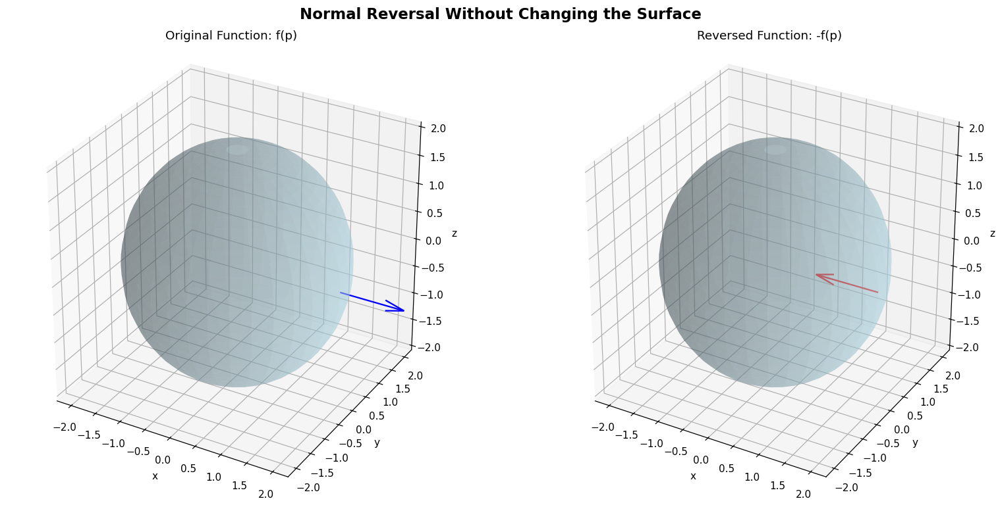

,Point,Analytical gradient,Numerical gradient,Gradient error,Normal magnitude,Gradient dot tangent
0,"(2.0, 0.0, 0.0)","(4.0, 0.0, 0.0)","(4.000000000026205, 0.0, 0.0)",2.620482e-11,4.0,0.0
1,"(0.0, 2.0, 0.0)","(0.0, 4.0, 0.0)","(0.0, 4.000000000026205, 0.0)",2.620482e-11,4.0,0.0
2,"(0.0, 0.0, 2.0)","(0.0, 0.0, 4.0)","(0.0, 0.0, 4.000000000026205)",2.620482e-11,4.0,0.0
3,"(1.1547005383792517, 1.1547005383792517, 1.154...","(2.3094010767585034, 2.3094010767585034, 2.309...","(2.309401076772133, 2.309401076772133, 2.30940...",2.360706e-11,4.0,0.0


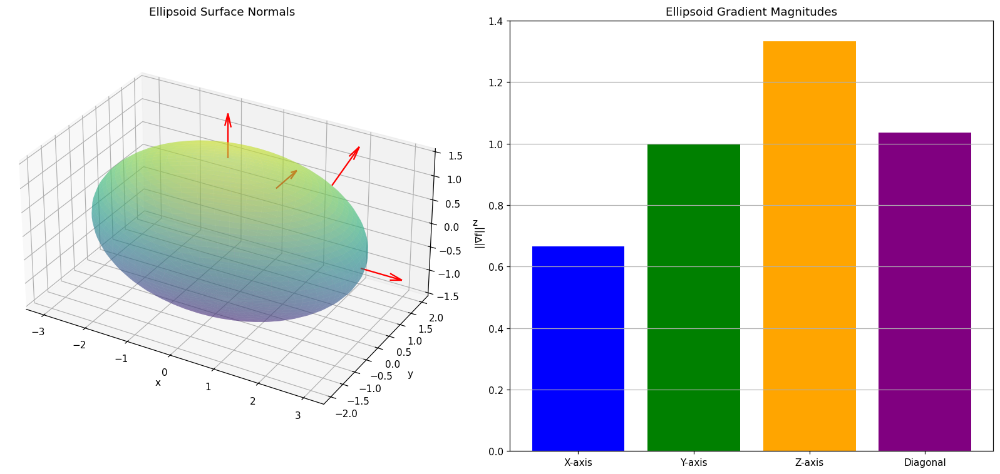

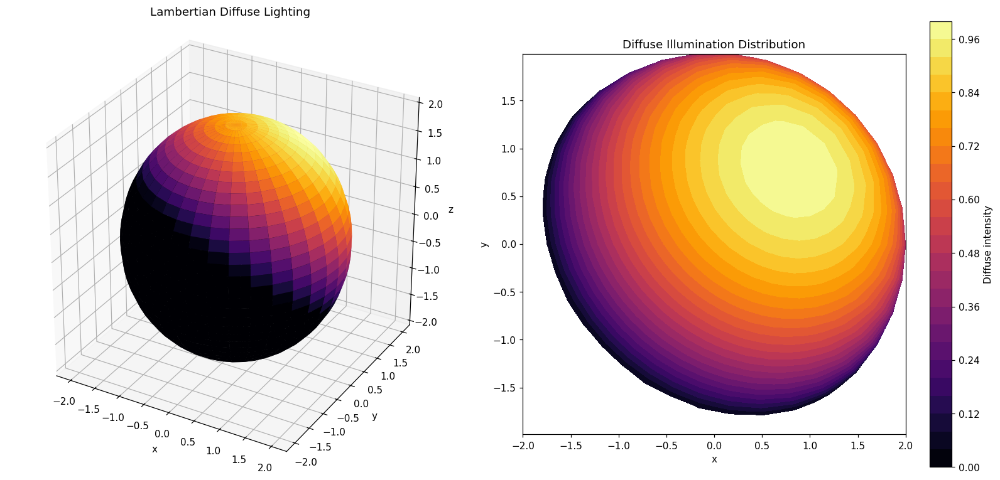

,Verification,Result
0,Maximum sphere boundary residual,0.0
1,Maximum ellipsoid boundary residual,0.0
2,Sphere normal reversal,True
3,Sphere analytical/numerical gradient agreement,True
4,Ellipse implicit residual,0.0
5,Lighting intensity minimum,0.0
6,Lighting intensity maximum,0.999138


AssertionError: 

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import cm
from matplotlib.colors import Normalize

# ============================================================
# 1. CONFIGURATION
# ============================================================

plt.rcParams.update({
    "figure.figsize": (15, 7),
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9
})

EPS = 1e-9

# ============================================================
# 2. IMPLICIT QUADRIC FUNCTIONS
# ============================================================

def circle_function(x, y, xc=0, yc=0, r=2):
    """
    (x-xc)^2 + (y-yc)^2 - r^2 = 0
    """
    return (x-xc)**2 + (y-yc)**2 - r**2


def ellipse_function(x, y, xc=0, yc=0, a=3, b=2):
    """
    (x-xc)^2/a^2 + (y-yc)^2/b^2 - 1 = 0
    """
    return (
        (x-xc)**2/a**2
        + (y-yc)**2/b**2
        - 1
    )


def hyperbola_function(x, y, xc=0, yc=0, a=2, b=1.5):
    """
    (x-xc)^2/a^2 - (y-yc)^2/b^2 - 1 = 0
    """
    return (
        (x-xc)**2/a**2
        - (y-yc)**2/b**2
        - 1
    )


def parabola_function(x, y, p=1):
    """
    y^2 - 4px = 0
    """
    return y**2 - 4*p*x


# ============================================================
# 3. QUADRIC COEFFICIENT CLASSIFICATION
# ============================================================

def classify_quadric(A, B, C):
    """
    Discriminant:
    Delta = B^2 - 4AC

    Delta < 0: ellipse-type
    Delta = 0: parabola-type
    Delta > 0: hyperbola-type

    This classification assumes a non-degenerate
    quadratic part. Degeneracy must be checked separately.
    """
    discriminant = B**2 - 4*A*C

    if discriminant < -EPS:
        category = "Ellipse-type"
    elif discriminant > EPS:
        category = "Hyperbola-type"
    else:
        category = "Parabola-type"

    return discriminant, category


quadric_examples = [
    ("Circle", 1, 0, 1),
    ("Ellipse", 1/9, 0, 1/4),
    ("Hyperbola", 1/4, 0, -1/2),
    ("Parabola", 0, 0, 1)
]

quadric_classification = []

for name, A, B, C in quadric_examples:

    if name == "Parabola":
        discriminant = B**2 - 4*A*C
        category = "Parabola-type"
    else:
        discriminant, category = classify_quadric(A, B, C)

    quadric_classification.append({
        "Quadric": name,
        "A": A,
        "B": B,
        "C": C,
        "Discriminant": discriminant,
        "Classification": category
    })

display(pd.DataFrame(quadric_classification))


# ============================================================
# 4. TWO-DIMENSIONAL COMPUTATIONAL DOMAIN
# ============================================================

x = np.linspace(-5, 5, 400)
y = np.linspace(-4, 4, 400)

X, Y = np.meshgrid(x, y)

F_circle = circle_function(X, Y)
F_ellipse = ellipse_function(X, Y)
F_hyperbola = hyperbola_function(X, Y)
F_parabola = parabola_function(X, Y)


# ============================================================
# 5. FIGURE 1: IMPLICIT QUADRIC CURVES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 13))

# ------------------------------------------------------------
# 5.1 Circle
# ------------------------------------------------------------

ax = axes[0, 0]

ax.contourf(
    X, Y, F_circle,
    levels=30,
    cmap="coolwarm",
    alpha=0.75
)

ax.contour(
    X, Y, F_circle,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.scatter(0, 0, color="red", s=70, label="Centre")

ax.set_title("Circle: x² + y² - 4 = 0")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 5.2 Ellipse
# ------------------------------------------------------------

ax = axes[0, 1]

ax.contourf(
    X, Y, F_ellipse,
    levels=30,
    cmap="coolwarm",
    alpha=0.75
)

ax.contour(
    X, Y, F_ellipse,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.scatter(0, 0, color="red", s=70, label="Centre")

ax.set_title("Ellipse: x²/9 + y²/4 - 1 = 0")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 5.3 Hyperbola
# ------------------------------------------------------------

ax = axes[1, 0]

ax.contourf(
    X, Y, F_hyperbola,
    levels=35,
    cmap="coolwarm",
    alpha=0.75
)

ax.contour(
    X, Y, F_hyperbola,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.scatter(0, 0, color="red", s=70, label="Centre")

ax.set_title("Hyperbola: x²/4 - y²/2.25 - 1 = 0")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# ------------------------------------------------------------
# 5.4 Parabola
# ------------------------------------------------------------

ax = axes[1, 1]

ax.contourf(
    X, Y, F_parabola,
    levels=35,
    cmap="coolwarm",
    alpha=0.75
)

ax.contour(
    X, Y, F_parabola,
    levels=[0],
    colors="black",
    linewidths=2.5
)

ax.scatter(0, 0, color="red", s=70, label="Vertex")

ax.set_title("Parabola: y² - 4x = 0")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.suptitle(
    "2.5.5 Implicit Quadric Curves",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. CIRCLE AS A SPECIAL CASE OF AN ELLIPSE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

theta = np.linspace(0, 2*np.pi, 500)

# Circle: a = b = 2
ax = axes[0]

circle_x = 2*np.cos(theta)
circle_y = 2*np.sin(theta)

ax.plot(
    circle_x, circle_y,
    color="blue",
    linewidth=2.5,
    label="Circle: a = b = 2"
)

ax.set_title("Circle: Equal Semi-Axes")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# Ellipse: a = 3, b = 2
ax = axes[1]

ellipse_x = 3*np.cos(theta)
ellipse_y = 2*np.sin(theta)

ax.plot(
    ellipse_x, ellipse_y,
    color="green",
    linewidth=2.5,
    label="Ellipse: a = 3, b = 2"
)

ax.set_title("Ellipse: Unequal Semi-Axes")
ax.set_xlabel("x-coordinate")
ax.set_ylabel("y-coordinate")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.suptitle(
    "Relationship Between Circles and Ellipses",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. ELLIPSE PARAMETRIC AND IMPLICIT VERIFICATION
# ============================================================

xc, yc = 1.0, -1.0
a, b = 3.0, 2.0

ellipse_x = xc + a*np.cos(theta)
ellipse_y = yc + b*np.sin(theta)

ellipse_residual = ellipse_function(
    ellipse_x,
    ellipse_y,
    xc, yc, a, b
)

ellipse_verification = pd.DataFrame({
    "Parameter angle": theta[:10],
    "x-coordinate": ellipse_x[:10],
    "y-coordinate": ellipse_y[:10],
    "Implicit residual": ellipse_residual[:10]
})

display(ellipse_verification)

display(pd.DataFrame({
    "Verification": [
        "Maximum absolute implicit residual",
        "Mean absolute implicit residual",
        "Horizontal semi-axis",
        "Vertical semi-axis"
    ],
    "Value": [
        np.max(np.abs(ellipse_residual)),
        np.mean(np.abs(ellipse_residual)),
        a,
        b
    ]
}))


# ============================================================
# 8. THREE-DIMENSIONAL IMPLICIT SURFACE FUNCTIONS
# ============================================================

def sphere_function(x, y, z, radius=2):
    """
    Sphere:
    x^2 + y^2 + z^2 - r^2 = 0
    """
    return x**2 + y**2 + z**2 - radius**2


def ellipsoid_function(
    x, y, z,
    a=3, b=2, c=1.5
):
    """
    x^2/a^2 + y^2/b^2 + z^2/c^2 - 1 = 0
    """
    return (
        x**2/a**2
        + y**2/b**2
        + z**2/c**2
        - 1
    )


def cylinder_function(x, y, z, radius=2):
    """
    x^2 + y^2 - r^2 = 0
    """
    return x**2 + y**2 - radius**2


def torus_function(x, y, z, major_radius=2, minor_radius=0.7):
    """
    Torus:
    (x^2+y^2+z^2+R^2-r^2)^2
    - 4R^2(x^2+y^2) = 0
    """
    q = (
        x**2 + y**2 + z**2
        + major_radius**2
        - minor_radius**2
    )

    return q**2 - 4*major_radius**2*(x**2+y**2)


# ============================================================
# 9. THREE-DIMENSIONAL SURFACE PARAMETERISATION
# ============================================================

def sphere_parametric(radius=2, resolution=70):
    u = np.linspace(0, 2*np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)

    U, V = np.meshgrid(u, v)

    Xs = radius*np.cos(U)*np.sin(V)
    Ys = radius*np.sin(U)*np.sin(V)
    Zs = radius*np.cos(V)

    return Xs, Ys, Zs


def ellipsoid_parametric(
    a=3, b=2, c=1.5, resolution=70
):
    u = np.linspace(0, 2*np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)

    U, V = np.meshgrid(u, v)

    Xe = a*np.cos(U)*np.sin(V)
    Ye = b*np.sin(U)*np.sin(V)
    Ze = c*np.cos(V)

    return Xe, Ye, Ze


def cylinder_parametric(
    radius=2,
    height=4,
    resolution=70
):
    u = np.linspace(0, 2*np.pi, resolution)
    z = np.linspace(-height/2, height/2, resolution)

    U, Zc = np.meshgrid(u, z)

    Xc = radius*np.cos(U)
    Yc = radius*np.sin(U)

    return Xc, Yc, Zc


def torus_parametric(
    major_radius=2,
    minor_radius=0.7,
    resolution=70
):
    u = np.linspace(0, 2*np.pi, resolution)
    v = np.linspace(0, 2*np.pi, resolution)

    U, V = np.meshgrid(u, v)

    Xt = (
        major_radius + minor_radius*np.cos(V)
    )*np.cos(U)

    Yt = (
        major_radius + minor_radius*np.cos(V)
    )*np.sin(U)

    Zt = minor_radius*np.sin(V)

    return Xt, Yt, Zt


# ============================================================
# 10. FIGURE 2: THREE-DIMENSIONAL IMPLICIT SURFACES
# ============================================================

fig = plt.figure(figsize=(15, 13))

surface_functions = [
    (
        "Sphere",
        sphere_parametric()
    ),
    (
        "Ellipsoid",
        ellipsoid_parametric()
    ),
    (
        "Cylinder",
        cylinder_parametric()
    ),
    (
        "Torus",
        torus_parametric()
    )
]

for i, (name, coordinates) in enumerate(surface_functions):

    ax = fig.add_subplot(
        2, 2, i+1,
        projection="3d"
    )

    Xs, Ys, Zs = coordinates

    ax.plot_surface(
        Xs, Ys, Zs,
        cmap="viridis",
        edgecolor="none",
        alpha=0.85
    )

    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_box_aspect((1, 1, 1))

plt.suptitle(
    "2.5.6 Three-Dimensional Implicit Surfaces",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 11. IMPLICIT SURFACE SIGN CLASSIFICATION
# ============================================================

def classify_surface_point(value, tolerance=EPS):
    if abs(value) <= tolerance:
        return "Surface"

    elif value > 0:
        return "Positive region"

    else:
        return "Negative region"


sample_3d_points = np.array([
    [0, 0, 0],
    [2, 0, 0],
    [3, 0, 0],
    [1, 1, 1],
    [0, 0, 2],
    [1, 1, 0]
], dtype=float)

surface_results = []

for point in sample_3d_points:

    value = sphere_function(*point)

    surface_results.append({
        "x": point[0],
        "y": point[1],
        "z": point[2],
        "Implicit function": value,
        "Classification": classify_surface_point(value)
    })

surface_classification_df = pd.DataFrame(
    surface_results
)

display(surface_classification_df)


# ============================================================
# 12. SURFACE NORMAL GRADIENT FUNCTIONS
# ============================================================

def sphere_gradient(x, y, z):
    """
    ∇f = (2x, 2y, 2z)
    """
    return np.array([
        2*x,
        2*y,
        2*z
    ], dtype=float)


def ellipsoid_gradient(
    x, y, z,
    a=3, b=2, c=1.5
):
    """
    ∇f = (2x/a², 2y/b², 2z/c²)
    """
    return np.array([
        2*x/a**2,
        2*y/b**2,
        2*z/c**2
    ], dtype=float)


def numerical_gradient_3d(
    function, point, h=1e-5
):
    """
    Central finite differences in 3D.
    """
    point = np.asarray(point, dtype=float)

    gradient = np.zeros(3)

    for i in range(3):

        plus = point.copy()
        minus = point.copy()

        plus[i] += h
        minus[i] -= h

        gradient[i] = (
            function(*plus) - function(*minus)
        )/(2*h)

    return gradient


# ============================================================
# 13. FIGURE 3: SPHERE SURFACE NORMALS
# ============================================================

Xs, Ys, Zs = sphere_parametric(
    radius=2,
    resolution=35
)

fig = plt.figure(figsize=(15, 7))

# ------------------------------------------------------------
# 13.1 Sphere with outward normal vectors
# ------------------------------------------------------------

ax = fig.add_subplot(1, 2, 1, projection="3d")

ax.plot_surface(
    Xs, Ys, Zs,
    color="lightblue",
    alpha=0.35,
    edgecolor="none"
)

normal_points = [
    np.array([2.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 2.0]),
    np.array([-2.0, 0.0, 0.0]),
    np.array([0.0, -2.0, 0.0]),
    np.array([0.0, 0.0, -2.0]),
    np.array([np.sqrt(2), np.sqrt(2), 0.0])
]

for point in normal_points:

    gradient = sphere_gradient(*point)

    unit_normal = normalize(gradient)

    ax.quiver(
        point[0], point[1], point[2],
        unit_normal[0],
        unit_normal[1],
        unit_normal[2],
        length=0.8,
        color="red",
        normalize=True
    )

ax.set_title("Sphere with Outward Surface Normals")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))

# ------------------------------------------------------------
# 13.2 Normal and tangent plane at one point
# ------------------------------------------------------------

ax = fig.add_subplot(1, 2, 2, projection="3d")

ax.plot_surface(
    Xs, Ys, Zs,
    color="lightblue",
    alpha=0.25,
    edgecolor="none"
)

P = np.array([
    2/np.sqrt(3),
    2/np.sqrt(3),
    2/np.sqrt(3)
])

gradient = sphere_gradient(*P)
unit_normal = normalize(gradient)

# Tangent plane:
# gradient . (Q-P) = 0
# z = Pz - [gx(x-Px)+gy(y-Py)]/gz

plane_x = np.linspace(0.1, 2.1, 20)
plane_y = np.linspace(0.1, 2.1, 20)

PX, PY = np.meshgrid(plane_x, plane_y)

PZ = P[2] - (
    gradient[0]*(PX-P[0])
    + gradient[1]*(PY-P[1])
)/gradient[2]

ax.plot_surface(
    PX, PY, PZ,
    color="orange",
    alpha=0.45,
    edgecolor="none"
)

ax.scatter(
    P[0], P[1], P[2],
    color="black",
    s=70
)

ax.quiver(
    P[0], P[1], P[2],
    unit_normal[0],
    unit_normal[1],
    unit_normal[2],
    length=1,
    color="red",
    normalize=True
)

ax.set_title("Tangent Plane and Surface Normal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))

plt.suptitle(
    "2.5.7 Surface Normal to an Implicit Surface",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 14. NORMAL REVERSAL
# ============================================================

fig = plt.figure(figsize=(15, 7))

# Original normal
ax = fig.add_subplot(1, 2, 1, projection="3d")

ax.plot_surface(
    Xs, Ys, Zs,
    color="lightblue",
    alpha=0.35,
    edgecolor="none"
)

P = np.array([2.0, 0.0, 0.0])

G = sphere_gradient(*P)
N = normalize(G)

ax.quiver(
    *P,
    *N,
    length=1.2,
    color="blue",
    normalize=True
)

ax.set_title("Original Function: f(p)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))

# Reversed normal
ax = fig.add_subplot(1, 2, 2, projection="3d")

ax.plot_surface(
    Xs, Ys, Zs,
    color="lightblue",
    alpha=0.35,
    edgecolor="none"
)

reversed_normal = -N

ax.quiver(
    *P,
    *reversed_normal,
    length=1.2,
    color="red",
    normalize=True
)

ax.set_title("Reversed Function: -f(p)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))

plt.suptitle(
    "Normal Reversal Without Changing the Surface",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 15. SURFACE NORMAL NUMERICAL VERIFICATION
# ============================================================

verification_points = [
    np.array([2.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 2.0]),
    np.array([
        2/np.sqrt(3),
        2/np.sqrt(3),
        2/np.sqrt(3)
    ])
]

normal_results = []

for point in verification_points:

    analytical = sphere_gradient(*point)

    numerical = numerical_gradient_3d(
        sphere_function,
        point
    )

    tangent = np.cross(
        analytical,
        np.array([0.0, 0.0, 1.0])
    )

    if np.linalg.norm(tangent) < EPS:
        tangent = np.cross(
            analytical,
            np.array([0.0, 1.0, 0.0])
        )

    tangent = normalize(tangent)

    normal_results.append({
        "Point": tuple(point),
        "Analytical gradient": tuple(analytical),
        "Numerical gradient": tuple(numerical),
        "Gradient error": np.linalg.norm(
            analytical-numerical
        ),
        "Normal magnitude": np.linalg.norm(analytical),
        "Gradient dot tangent": np.dot(
            analytical, tangent
        )
    })

normal_df = pd.DataFrame(normal_results)

display(normal_df)


# ============================================================
# 16. ELLIPSOID SURFACE NORMALS
# ============================================================

Xe, Ye, Ze = ellipsoid_parametric(
    a=3,
    b=2,
    c=1.5,
    resolution=50
)

fig = plt.figure(figsize=(15, 7))

ax = fig.add_subplot(1, 2, 1, projection="3d")

ax.plot_surface(
    Xe, Ye, Ze,
    cmap="viridis",
    alpha=0.4,
    edgecolor="none"
)

ellipsoid_points = [
    np.array([3.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 1.5]),
    np.array([
        3/np.sqrt(3),
        2/np.sqrt(3),
        1.5/np.sqrt(3)
    ])
]

for point in ellipsoid_points:

    gradient = ellipsoid_gradient(*point)

    ax.quiver(
        *point,
        *normalize(gradient),
        length=0.9,
        color="red",
        normalize=True
    )

ax.set_title("Ellipsoid Surface Normals")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1.5, 1, 0.75))

# Normal magnitude variation
ax = fig.add_subplot(1, 2, 2)

magnitudes = []

for point in ellipsoid_points:

    magnitudes.append(
        np.linalg.norm(
            ellipsoid_gradient(*point)
        )
    )

ax.bar(
    ["X-axis", "Y-axis", "Z-axis", "Diagonal"],
    magnitudes,
    color=["blue", "green", "orange", "purple"]
)

ax.set_title("Ellipsoid Gradient Magnitudes")
ax.set_ylabel("||∇f||")
ax.grid(True, axis="y")

plt.tight_layout()
plt.show()


# ============================================================
# 17. APPLICATION: DIFFUSE LIGHTING
# ============================================================

def diffuse_lighting(normal, light_direction, intensity=1.0):
    """
    Lambertian diffuse illumination:

    I = I0 max(0, n . l)

    n = unit surface normal
    l = unit light direction
    """
    n = normalize(normal)
    l = normalize(light_direction)

    return intensity*max(0.0, np.dot(n, l))


light_direction = normalize(
    np.array([1.0, 1.0, 2.0])
)

# Sphere surface normal field
normal_field = np.stack(
    [2*Xs, 2*Ys, 2*Zs],
    axis=-1
)

normal_lengths = np.linalg.norm(
    normal_field,
    axis=-1,
    keepdims=True
)

unit_normal_field = normal_field/normal_lengths

light_array = light_direction.reshape(1, 1, 3)

intensity = np.maximum(
    0,
    np.sum(
        unit_normal_field*light_array,
        axis=-1
    )
)

fig = plt.figure(figsize=(15, 7))

ax = fig.add_subplot(1, 2, 1, projection="3d")

ax.plot_surface(
    Xs, Ys, Zs,
    facecolors=cm.inferno(intensity),
    edgecolor="none",
    shade=False
)

ax.set_title("Lambertian Diffuse Lighting")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1, 1, 1))

# Lighting intensity map
ax = fig.add_subplot(1, 2, 2)

light_map = ax.contourf(
    Xs,
    Ys,
    intensity,
    levels=30,
    cmap="inferno"
)

fig.colorbar(
    light_map,
    ax=ax,
    label="Diffuse intensity"
)

ax.set_title("Diffuse Illumination Distribution")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()


# ============================================================
# 18. QUADRIC AND SURFACE NUMERICAL VERIFICATION
# ============================================================

sphere_samples = [
    np.array([2.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 2.0]),
    np.array([
        2/np.sqrt(3),
        2/np.sqrt(3),
        2/np.sqrt(3)
    ])
]

sphere_residuals = [
    sphere_function(*point)
    for point in sphere_samples
]

ellipsoid_samples = [
    np.array([3.0, 0.0, 0.0]),
    np.array([0.0, 2.0, 0.0]),
    np.array([0.0, 0.0, 1.5])
]

ellipsoid_residuals = [
    ellipsoid_function(*point)
    for point in ellipsoid_samples
]

final_verification = pd.DataFrame({
    "Verification": [
        "Maximum sphere boundary residual",
        "Maximum ellipsoid boundary residual",
        "Sphere normal reversal",
        "Sphere analytical/numerical gradient agreement",
        "Ellipse implicit residual",
        "Lighting intensity minimum",
        "Lighting intensity maximum"
    ],
    "Result": [
        np.max(np.abs(sphere_residuals)),
        np.max(np.abs(ellipsoid_residuals)),
        np.allclose(
            -sphere_gradient(2, 0, 0),
            -np.array([4, 0, 0])
        ),
        np.allclose(
            sphere_gradient(1, 1, 1),
            numerical_gradient_3d(
                sphere_function,
                np.array([1, 1, 1])
            ),
            atol=1e-8
        ),
        np.max(np.abs(ellipse_residual)),
        np.min(intensity),
        np.max(intensity)
    ]
})

display(final_verification)


# ============================================================
# 19. ASSERTION-BASED VALIDATION
# ============================================================

assert np.allclose(ellipse_residual, 0, atol=1e-10)

assert np.allclose(
    sphere_residuals,
    0,
    atol=1e-10
)

assert np.allclose(
    ellipsoid_residuals,
    0,
    atol=1e-10
)

assert np.allclose(
    sphere_gradient(2, 0, 0),
    -reversed_normal*2
)

assert np.all(
    (intensity >= 0) & (intensity <= 1)
)

assert np.allclose(
    sphere_gradient(1, 1, 1),
    numerical_gradient_3d(
        sphere_function,
        np.array([1.0, 1.0, 1.0])
    ),
    atol=1e-8
)

plt.show()


### 2.5.5 Implicit Planes

An **implicit plane** is a two-dimensional geometric surface in three-dimensional space defined by a constraint involving a position vector and a normal vector. A plane passing through point $\mathbf{a}$ with normal $\mathbf{n}$ satisfies:

$$
(\mathbf{p}-\mathbf{a})\cdot\mathbf{n}=0
\tag{2.21}
$$

Here, $\mathbf{p}$ represents any point on the plane, $\mathbf{a}$ is a known reference point, and $\mathbf{n}$ is perpendicular to the plane. The zero dot product establishes that displacement $\mathbf{p}-\mathbf{a}$ is perpendicular to the normal.

**Plane Through Three Points**

Given three non-collinear points $\mathbf{a}$, $\mathbf{b}$ and $\mathbf{c}$, calculate the normal using:

$$
\mathbf{n}=(\mathbf{b}-\mathbf{a})\times(\mathbf{c}-\mathbf{a})
$$

Substitution into Equation (2.21) produces:

$$
(\mathbf{p}-\mathbf{a})\cdot
[(\mathbf{b}-\mathbf{a})\times(\mathbf{c}-\mathbf{a})]=0
\tag{2.22}
$$

This scalar triple product equals zero because the three displacement vectors are coplanar, enclosing zero parallelepiped volume.

The equivalent determinant representation is:

$$
\begin{vmatrix}
x-x_a&y-y_a&z-z_a\\
x_b-x_a&y_b-y_a&z_b-z_a\\
x_c-x_a&y_c-y_a&z_c-z_a
\end{vmatrix}=0
\tag{2.23}
$$

Both formulations establish coplanarity. Vector notation provides geometric clarity, whereas determinants express the same condition algebraically.

### 3D Quadric Surfaces

Quadric surfaces are defined by second-degree polynomial equations. A sphere with centre $\mathbf{c}$ and radius $r$ satisfies:

$$
f(\mathbf{p})=\|\mathbf{p}-\mathbf{c}\|^2-r^2=0
$$

An axis-aligned ellipsoid is represented by:

$$
\frac{(x-x_c)^2}{a^2}
+\frac{(y-y_c)^2}{b^2}
+\frac{(z-z_c)^2}{c^2}=1
$$

Here, $a$, $b$ and $c$ denote principal semiaxis lengths.

### 3D Curves from Implicit Surfaces

A spatial curve can be defined as the intersection of two implicit surfaces:

$$
f(\mathbf{p})=0,\qquad g(\mathbf{p})=0
$$

For example, two non-parallel planes intersect in a straight line. This representation supports geometric intersection analysis, although parametric curves are generally more convenient for trajectory construction and manipulation.

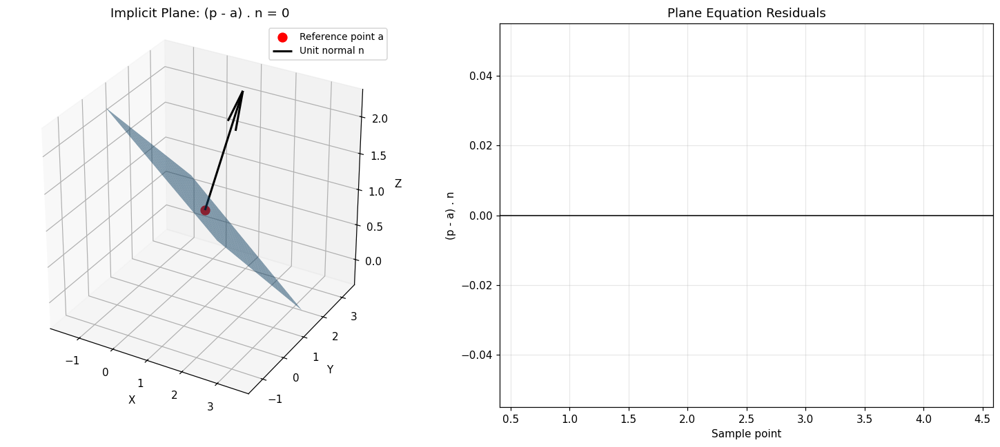

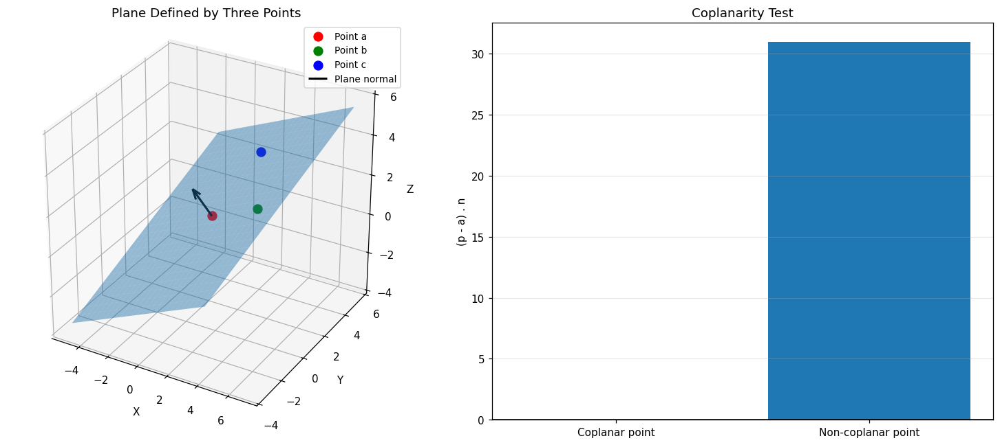

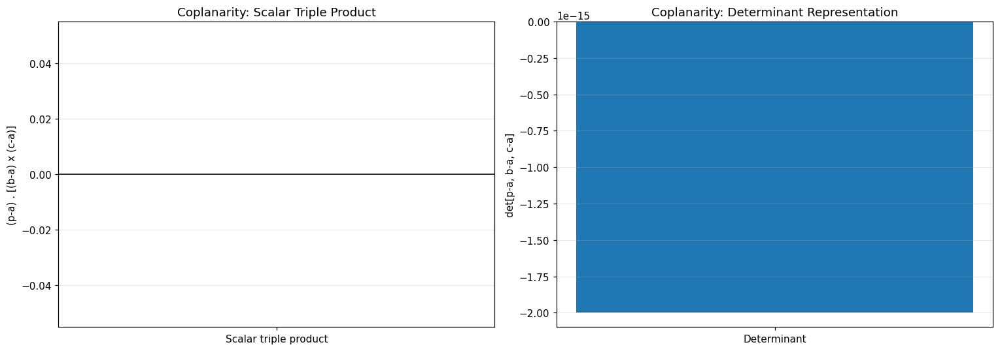

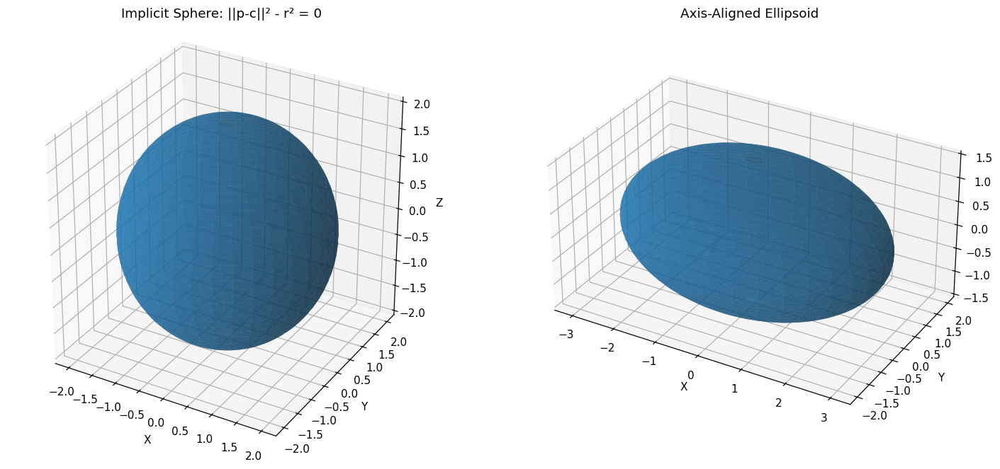

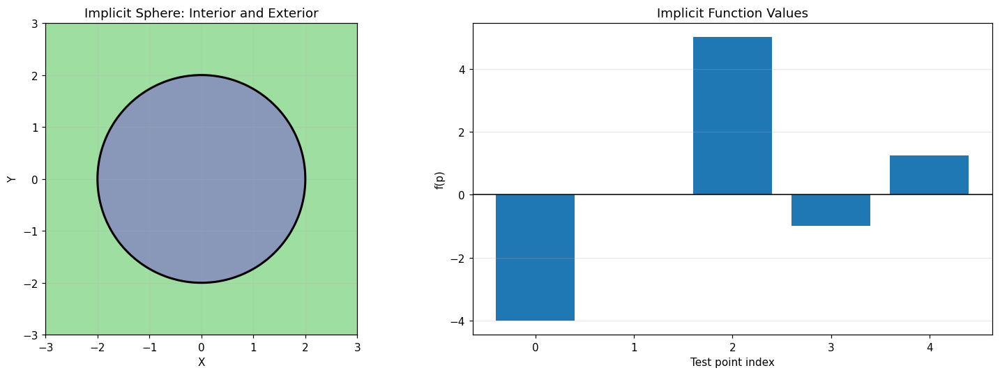

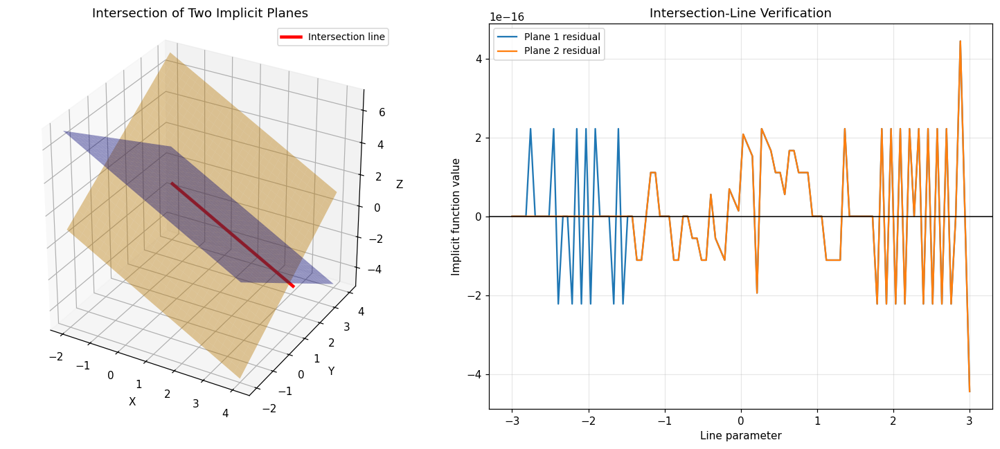

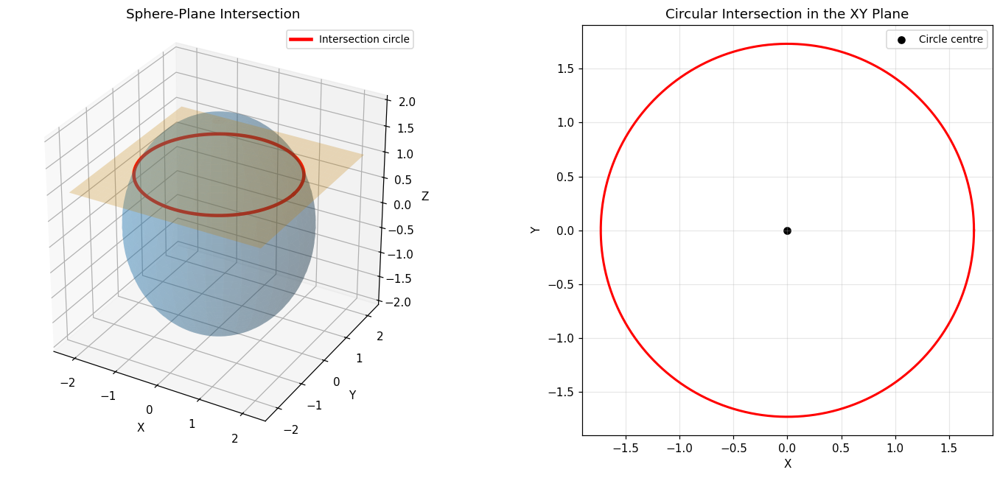

,Quantity,Value
0,Normal x-component,1.000000
1,Normal y-component,2.000000
2,Normal z-component,3.000000
3,Normal magnitude,3.741657
4,Plane residual maximum,0.000000


,Quantity,Value
0,Area of triangle ABC,5.361903e+00
1,Normal magnitude,1.072381e+01
2,Scalar triple product,0.000000e+00
3,Determinant value,-1.998401e-15
4,Coplanar point residual,0.000000e+00
5,Non-coplanar point residual,3.100000e+01


,X,Y,Z,Sphere function f(p),Classification
0,0.0,0.0,0.0,-4.00,Interior
1,2.0,0.0,0.0,0.00,On surface
2,3.0,0.0,0.0,5.00,Exterior
3,1.0,1.0,1.0,-1.00,Interior
4,-2.0,1.0,0.5,1.25,Exterior


,Quantity,Value
0,Intersection direction x,7.071068e-01
1,Intersection direction y,0.000000e+00
2,Intersection direction z,-7.071068e-01
3,Intersection point x,2.000000e+00
4,Intersection point y,1.000000e+00
5,Intersection point z,0.000000e+00
6,Maximum plane 1 residual,4.440892e-16
7,Maximum plane 2 residual,4.440892e-16


,Quantity,Value
0,Sphere radius,2.000000e+00
1,Plane height,1.000000e+00
2,Intersection circle radius,1.732051e+00
3,Maximum sphere residual,8.881784e-16
4,Maximum plane residual,0.000000e+00


In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401


# ============================================================
# 1. NUMERICAL CONFIGURATION AND VECTOR OPERATIONS
# ============================================================

EPS = 1e-10

def magnitude(v):
    return np.linalg.norm(v)

def normalize(v):
    v = np.asarray(v, dtype=float)
    length = magnitude(v)

    if length < EPS:
        raise ValueError("A zero vector cannot be normalised.")

    return v / length

def dot(a, b):
    return float(np.dot(a, b))

def cross(a, b):
    return np.cross(a, b)

def plane_function(p, a, n):
    """
    Implicit plane:
        f(p) = (p - a) . n = 0
    """
    return np.dot(np.asarray(p) - np.asarray(a), n)

def plane_coefficients(a, n):
    """
    General plane:
        Ax + By + Cz + D = 0

    where:
        (A, B, C) = n
        D = -n . a
    """
    A, B, C = n
    D = -dot(n, a)
    return np.array([A, B, C, D], dtype=float)

def evaluate_general_plane(p, coefficients):
    A, B, C, D = coefficients
    x, y, z = p
    return A*x + B*y + C*z + D


# ============================================================
# 2. IMPLICIT PLANE THROUGH A REFERENCE POINT
# ============================================================

reference_point = np.array([1.0, 1.0, 1.0])
plane_normal = np.array([1.0, 2.0, 3.0])

plane_normal_unit = normalize(plane_normal)

# Generate points satisfying:
# (p - a) . n = 0

u = normalize(np.cross(plane_normal, [0, 0, 1]))
v = normalize(np.cross(plane_normal, u))

s = np.linspace(-2, 2, 30)
t = np.linspace(-2, 2, 30)

S, T = np.meshgrid(s, t)

plane_points = (
    reference_point[:, None, None]
    + u[:, None, None] * S
    + v[:, None, None] * T
)

X_plane = plane_points[0]
Y_plane = plane_points[1]
Z_plane = plane_points[2]

# Sample points for plane-equation verification
sample_plane_points = np.array([
    reference_point,
    reference_point + u,
    reference_point + v,
    reference_point + 2*u - 3*v
])

plane_residuals = np.array([
    plane_function(p, reference_point, plane_normal)
    for p in sample_plane_points
])


# ============================================================
# 3. PLANE THROUGH THREE NON-COLLINEAR POINTS
# ============================================================

A = np.array([1.0, 1.0, 1.0])
B = np.array([4.0, 1.0, 2.0])
C = np.array([2.0, 4.0, 3.0])

AB = B - A
AC = C - A

# Equation:
# n = (b - a) x (c - a)

normal_ABC = cross(AB, AC)
normal_ABC_unit = normalize(normal_ABC)

# Plane equation:
# (p - a) . [(b-a) x (c-a)] = 0

coefficients_ABC = plane_coefficients(A, normal_ABC)

# Fourth point tested for coplanarity
P_coplanar = A + 2*AB - 0.5*AC

# Non-coplanar test point
P_non_coplanar = np.array([5.0, 5.0, 8.0])

coplanar_residual = plane_function(
    P_coplanar, A, normal_ABC
)

non_coplanar_residual = plane_function(
    P_non_coplanar, A, normal_ABC
)

# Scalar triple product
triple_product = dot(
    P_coplanar - A,
    cross(AB, AC)
)

# Determinant representation:
# det([p-a, b-a, c-a]) = 0

determinant_matrix = np.column_stack([
    P_coplanar - A,
    AB,
    AC
])

determinant_value = np.linalg.det(determinant_matrix)

# Check whether the three defining points are non-collinear
triangle_area = 0.5 * magnitude(normal_ABC)


# ============================================================
# 4. GENERAL PLANE COEFFICIENT REPRESENTATION
# ============================================================

general_plane_coefficients = coefficients_ABC

general_plane_values = np.array([
    evaluate_general_plane(p, general_plane_coefficients)
    for p in [A, B, C, P_coplanar]
])


# ============================================================
# 5. 3D QUADRIC SURFACES
# ============================================================

def sphere_function(p, centre, radius):
    return np.sum((p - centre)**2) - radius**2

def ellipsoid_function(p, centre, axes):
    q = (p - centre) / axes
    return np.sum(q**2) - 1.0

sphere_centre = np.array([0.0, 0.0, 0.0])
sphere_radius = 2.0

ellipsoid_centre = np.array([0.0, 0.0, 0.0])
ellipsoid_axes = np.array([3.0, 2.0, 1.5])

# Parametric sphere and ellipsoid surfaces
phi = np.linspace(0, np.pi, 45)
theta = np.linspace(0, 2*np.pi, 70)

PHI, THETA = np.meshgrid(phi, theta)

X_sphere = sphere_radius * np.sin(PHI) * np.cos(THETA)
Y_sphere = sphere_radius * np.sin(PHI) * np.sin(THETA)
Z_sphere = sphere_radius * np.cos(PHI)

X_ellipsoid = (
    ellipsoid_axes[0] * np.sin(PHI) * np.cos(THETA)
)
Y_ellipsoid = (
    ellipsoid_axes[1] * np.sin(PHI) * np.sin(THETA)
)
Z_ellipsoid = ellipsoid_axes[2] * np.cos(PHI)

# Implicit residuals on the generated surfaces
sphere_residuals = (
    X_sphere**2 + Y_sphere**2 + Z_sphere**2
    - sphere_radius**2
)

ellipsoid_residuals = (
    (X_ellipsoid / ellipsoid_axes[0])**2
    + (Y_ellipsoid / ellipsoid_axes[1])**2
    + (Z_ellipsoid / ellipsoid_axes[2])**2
    - 1
)


# ============================================================
# 6. QUADRIC SIGN CLASSIFICATION
# ============================================================

classification_points = np.array([
    [0.0, 0.0, 0.0],
    [2.0, 0.0, 0.0],
    [3.0, 0.0, 0.0],
    [1.0, 1.0, 1.0],
    [-2.0, 1.0, 0.5]
])

classification_values = np.array([
    sphere_function(p, sphere_centre, sphere_radius)
    for p in classification_points
])

def classify_implicit_value(value, tolerance=EPS):
    if abs(value) <= tolerance:
        return "On surface"
    elif value < 0:
        return "Interior"
    return "Exterior"

sphere_classifications = [
    classify_implicit_value(value)
    for value in classification_values
]


# ============================================================
# 7. INTERSECTION OF TWO IMPLICIT PLANES
# ============================================================

# Plane 1: x + y + z = 3
n1 = np.array([1.0, 1.0, 1.0])
a1 = np.array([3.0, 0.0, 0.0])

# Plane 2: x - y + z = 1
n2 = np.array([1.0, -1.0, 1.0])
a2 = np.array([1.0, 0.0, 0.0])

# Direction of the intersection line:
# d = n1 x n2

line_direction = cross(n1, n2)
line_direction_unit = normalize(line_direction)

# Solve for one point on the intersection line.
# Set z = 0 and solve the two plane equations.

plane_system = np.array([
    [n1[0], n1[1]],
    [n2[0], n2[1]]
])

plane_rhs = np.array([
    dot(n1, a1),
    dot(n2, a2)
])

line_point_xy = np.linalg.solve(plane_system, plane_rhs)
line_point = np.array([
    line_point_xy[0],
    line_point_xy[1],
    0.0
])

line_parameter = np.linspace(-3, 3, 100)

intersection_line = (
    line_point[:, None]
    + line_direction_unit[:, None] * line_parameter
)

# Verify that every generated point satisfies both planes.
line_residual_1 = np.array([
    plane_function(p, a1, n1)
    for p in intersection_line.T
])

line_residual_2 = np.array([
    plane_function(p, a2, n2)
    for p in intersection_line.T
])


# ============================================================
# 8. INTERSECTION OF A SPHERE AND A PLANE
# ============================================================

# Sphere:
# x^2 + y^2 + z^2 = 4

# Plane:
# z = 1

intersection_plane_height = 1.0

# Substituting z = 1 into the sphere:
# x^2 + y^2 + 1 = 4
# x^2 + y^2 = 3

intersection_circle_radius = np.sqrt(
    sphere_radius**2 - intersection_plane_height**2
)

circle_angle = np.linspace(0, 2*np.pi, 200)

intersection_circle = np.vstack([
    intersection_circle_radius * np.cos(circle_angle),
    intersection_circle_radius * np.sin(circle_angle),
    np.full_like(circle_angle, intersection_plane_height)
])

sphere_plane_residuals = np.array([
    sphere_function(p, sphere_centre, sphere_radius)
    for p in intersection_circle.T
])

plane_circle_residuals = (
    intersection_circle[2] - intersection_plane_height
)


# ============================================================
# 9. INTERSECTION OF TWO IMPLICIT SURFACES: CONCEPTUAL TEST
# ============================================================

# The intersection of:
# f(x,y,z) = x^2 + y^2 + z^2 - 4 = 0
# g(x,y,z) = z - 1 = 0
#
# is the circle:
# x^2 + y^2 = 3, z = 1.

intersection_test = np.array([
    sphere_function(p, sphere_centre, sphere_radius)
    for p in intersection_circle.T
])

second_surface_test = intersection_circle[2] - 1.0


# ============================================================
# 10. VISUALISATION 1: IMPLICIT PLANE AND NORMAL
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot_surface(
    X_plane, Y_plane, Z_plane,
    alpha=0.55,
    edgecolor="none"
)

ax1.scatter(
    *reference_point,
    color="red",
    s=70,
    label="Reference point a"
)

ax1.quiver(
    *reference_point,
    *plane_normal_unit,
    length=1.8,
    color="black",
    linewidth=2,
    label="Unit normal n"
)

ax1.set_title("Implicit Plane: (p - a) . n = 0")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ax2.bar(
    np.arange(1, len(plane_residuals) + 1),
    plane_residuals
)

ax2.axhline(0, color="black", linewidth=1)
ax2.set_title("Plane Equation Residuals")
ax2.set_xlabel("Sample point")
ax2.set_ylabel("(p - a) . n")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 11. VISUALISATION 2: PLANE THROUGH THREE POINTS
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

# Construct a surface patch from the three-point plane.
plane_s = np.linspace(-1.5, 1.5, 25)
plane_t = np.linspace(-1.5, 1.5, 25)

SS, TT = np.meshgrid(plane_s, plane_t)

# AB and AC span the plane.
three_point_surface = (
    A[:, None, None]
    + AB[:, None, None] * SS
    + AC[:, None, None] * TT
)

ax1.plot_surface(
    three_point_surface[0],
    three_point_surface[1],
    three_point_surface[2],
    alpha=0.45
)

ax1.scatter(
    *A, color="red", s=70, label="Point a"
)
ax1.scatter(
    *B, color="green", s=70, label="Point b"
)
ax1.scatter(
    *C, color="blue", s=70, label="Point c"
)

ax1.quiver(
    *A,
    *normal_ABC_unit,
    length=2,
    color="black",
    linewidth=2,
    label="Plane normal"
)

ax1.set_title("Plane Defined by Three Points")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

comparison_labels = [
    "Coplanar point",
    "Non-coplanar point"
]

comparison_values = [
    coplanar_residual,
    non_coplanar_residual
]

ax2.bar(
    comparison_labels,
    comparison_values
)

ax2.axhline(0, color="black", linewidth=1)
ax2.set_title("Coplanarity Test")
ax2.set_ylabel("(p - a) . n")
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 12. VISUALISATION 3: SCALAR TRIPLE PRODUCT AND DETERMINANT
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    ["Scalar triple product"],
    [triple_product]
)

axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Coplanarity: Scalar Triple Product")
axes[0].set_ylabel("(p-a) . [(b-a) x (c-a)]")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    ["Determinant"],
    [determinant_value]
)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Coplanarity: Determinant Representation")
axes[1].set_ylabel("det[p-a, b-a, c-a]")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 13. VISUALISATION 4: SPHERE AND ELLIPSOID
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot_surface(
    X_sphere,
    Y_sphere,
    Z_sphere,
    alpha=0.65,
    edgecolor="none"
)

ax1.set_title("Implicit Sphere: ||p-c||² - r² = 0")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2, projection="3d")

ax2.plot_surface(
    X_ellipsoid,
    Y_ellipsoid,
    Z_ellipsoid,
    alpha=0.65,
    edgecolor="none"
)

ax2.set_title("Axis-Aligned Ellipsoid")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.set_box_aspect([3, 2, 1.5])

plt.tight_layout()
plt.show()


# ============================================================
# 14. VISUALISATION 5: SPHERE INTERIOR AND EXTERIOR
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_values = np.linspace(-3, 3, 200)
y_values = np.linspace(-3, 3, 200)

XX, YY = np.meshgrid(x_values, y_values)

# Sphere cross-section at z = 0:
# f(x,y,0) = x² + y² - r²

sphere_section = (
    XX**2 + YY**2 - sphere_radius**2
)

axes[0].contourf(
    XX, YY, sphere_section,
    levels=[-100, 0, 100],
    alpha=0.6
)

axes[0].contour(
    XX, YY, sphere_section,
    levels=[0],
    colors="black",
    linewidths=2
)

axes[0].set_title("Implicit Sphere: Interior and Exterior")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.2)

axes[1].bar(
    np.arange(len(classification_points)),
    classification_values
)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Implicit Function Values")
axes[1].set_xlabel("Test point index")
axes[1].set_ylabel("f(p)")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 15. VISUALISATION 6: INTERSECTION OF TWO PLANES
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

# Plane 1: x + y + z = 3
x_grid = np.linspace(-2, 4, 30)
y_grid = np.linspace(-2, 4, 30)

X1, Y1 = np.meshgrid(x_grid, y_grid)
Z1 = 3 - X1 - Y1

# Plane 2: x - y + z = 1
X2, Y2 = np.meshgrid(x_grid, y_grid)
Z2 = 1 - X2 + Y2

ax1.plot_surface(
    X1, Y1, Z1,
    alpha=0.4,
    color="blue"
)

ax1.plot_surface(
    X2, Y2, Z2,
    alpha=0.4,
    color="orange"
)

ax1.plot(
    intersection_line[0],
    intersection_line[1],
    intersection_line[2],
    color="red",
    linewidth=3,
    label="Intersection line"
)

ax1.set_title("Intersection of Two Implicit Planes")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    line_parameter,
    line_residual_1,
    label="Plane 1 residual"
)

ax2.plot(
    line_parameter,
    line_residual_2,
    label="Plane 2 residual"
)

ax2.axhline(0, color="black", linewidth=1)
ax2.set_title("Intersection-Line Verification")
ax2.set_xlabel("Line parameter")
ax2.set_ylabel("Implicit function value")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 16. VISUALISATION 7: SPHERE-PLANE INTERSECTION CIRCLE
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot_surface(
    X_sphere,
    Y_sphere,
    Z_sphere,
    alpha=0.25,
    edgecolor="none"
)

# Plane z = 1
plane_x, plane_y = np.meshgrid(
    np.linspace(-2.2, 2.2, 25),
    np.linspace(-2.2, 2.2, 25)
)

plane_z = np.full_like(
    plane_x,
    intersection_plane_height
)

ax1.plot_surface(
    plane_x,
    plane_y,
    plane_z,
    alpha=0.25,
    color="orange"
)

ax1.plot(
    intersection_circle[0],
    intersection_circle[1],
    intersection_circle[2],
    color="red",
    linewidth=3,
    label="Intersection circle"
)

ax1.set_title("Sphere-Plane Intersection")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    intersection_circle[0],
    intersection_circle[1],
    color="red",
    linewidth=2
)

ax2.scatter(
    [0],
    [0],
    color="black",
    label="Circle centre"
)

ax2.set_title("Circular Intersection in the XY Plane")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 17. NUMERICAL RESULTS TABLES
# ============================================================

plane_table = pd.DataFrame({
    "Quantity": [
        "Normal x-component",
        "Normal y-component",
        "Normal z-component",
        "Normal magnitude",
        "Plane residual maximum"
    ],
    "Value": [
        plane_normal[0],
        plane_normal[1],
        plane_normal[2],
        magnitude(plane_normal),
        np.max(np.abs(plane_residuals))
    ]
})

three_point_table = pd.DataFrame({
    "Quantity": [
        "Area of triangle ABC",
        "Normal magnitude",
        "Scalar triple product",
        "Determinant value",
        "Coplanar point residual",
        "Non-coplanar point residual"
    ],
    "Value": [
        triangle_area,
        magnitude(normal_ABC),
        triple_product,
        determinant_value,
        coplanar_residual,
        non_coplanar_residual
    ]
})

classification_table = pd.DataFrame({
    "X": classification_points[:, 0],
    "Y": classification_points[:, 1],
    "Z": classification_points[:, 2],
    "Sphere function f(p)": classification_values,
    "Classification": sphere_classifications
})

intersection_table = pd.DataFrame({
    "Quantity": [
        "Intersection direction x",
        "Intersection direction y",
        "Intersection direction z",
        "Intersection point x",
        "Intersection point y",
        "Intersection point z",
        "Maximum plane 1 residual",
        "Maximum plane 2 residual"
    ],
    "Value": [
        line_direction_unit[0],
        line_direction_unit[1],
        line_direction_unit[2],
        line_point[0],
        line_point[1],
        line_point[2],
        np.max(np.abs(line_residual_1)),
        np.max(np.abs(line_residual_2))
    ]
})

sphere_circle_table = pd.DataFrame({
    "Quantity": [
        "Sphere radius",
        "Plane height",
        "Intersection circle radius",
        "Maximum sphere residual",
        "Maximum plane residual"
    ],
    "Value": [
        sphere_radius,
        intersection_plane_height,
        intersection_circle_radius,
        np.max(np.abs(sphere_plane_residuals)),
        np.max(np.abs(plane_circle_residuals))
    ]
})

display(plane_table)
display(three_point_table)
display(classification_table)
display(intersection_table)
display(sphere_circle_table)


# ============================================================
# 18. MATHEMATICAL VERIFICATION
# ============================================================

# All three defining points must satisfy the plane.
assert np.allclose(
    plane_function(A, A, normal_ABC), 0,
    atol=EPS
)

assert np.allclose(
    plane_function(B, A, normal_ABC), 0,
    atol=EPS
)

assert np.allclose(
    plane_function(C, A, normal_ABC), 0,
    atol=EPS
)

# Coplanar point must produce zero scalar triple product.
assert np.isclose(
    triple_product, 0,
    atol=EPS
)

# Determinant and scalar triple product must agree.
assert np.isclose(
    determinant_value,
    triple_product,
    atol=EPS
)

# General plane coefficients must reproduce the vector equation.
assert np.allclose(
    general_plane_values,
    [
        plane_function(p, A, normal_ABC)
        for p in [A, B, C, P_coplanar]
    ],
    atol=EPS
)

# Generated sphere and ellipsoid points satisfy their equations.
assert np.allclose(
    sphere_residuals, 0,
    atol=1e-10
)

assert np.allclose(
    ellipsoid_residuals, 0,
    atol=1e-10
)

# Intersection line must satisfy both plane equations.
assert np.allclose(
    line_residual_1, 0,
    atol=1e-10
)

assert np.allclose(
    line_residual_2, 0,
    atol=1e-10
)

# Sphere-plane intersection circle must satisfy both surfaces.
assert np.allclose(
    sphere_plane_residuals, 0,
    atol=1e-10
)

assert np.allclose(
    plane_circle_residuals, 0,
    atol=1e-10
)

# Intersection direction must be perpendicular to both normals.
assert np.isclose(
    dot(line_direction_unit, n1), 0,
    atol=EPS
)

assert np.isclose(
    dot(line_direction_unit, n2), 0,
    atol=EPS
)

# Three points must be non-collinear.
assert magnitude(normal_ABC) > EPS

# The intersection circle radius must be real and positive.
assert intersection_circle_radius > 0


### 2.5.6 Two-Dimensional Parametric Curves

A **parametric curve** represents a geometric path through coordinate functions controlled by a continuously varying parameter $t$. Its Cartesian representation is:

$$
x=g(t),\qquad y=h(t)
$$

Alternatively, its vector representation is:

$$
\mathbf{p}(t)=
\begin{bmatrix}
g(t)\\
h(t)
\end{bmatrix},
\qquad
\mathbf{p}:\mathbb{R}\rightarrow\mathbb{R}^2
$$

Here, $t$ identifies a position along the curve, while $g(t)$ and $h(t)$ determine its horizontal and vertical coordinates. As $t$ varies, successive points trace the geometric path. Depending on the functions, curves may loop, intersect themselves or change direction.

**Tangent and Traversal Speed**

Differentiating the position vector gives:

$$
\mathbf{p}'(t)=
\begin{bmatrix}
g'(t)\\
h'(t)
\end{bmatrix}
$$

This derivative represents the tangent or instantaneous velocity vector. Its magnitude determines traversal speed:

$$
v(t)=\|\mathbf{p}'(t)\|
$$

Thus, equal parameter increments do not necessarily produce equal distances along the curve.

**Two-Dimensional Parametric Lines**

A line through points $\mathbf{p}_0$ and $\mathbf{p}_1$ is:

$$
\boxed{\mathbf{p}(t)=\mathbf{p}_0+t(\mathbf{p}_1-\mathbf{p}_0)}
$$

At $t=0$, the position is $\mathbf{p}_0$; at $t=1$, it is $\mathbf{p}_1$. Restricting $t\in[0,1]$ produces the connecting line segment. Alternatively:

$$
\mathbf{p}(t)=\mathbf{o}+t\mathbf{d}
$$

Here, $\mathbf{o}$ is an origin point and $\mathbf{d}$ is the direction vector. When $\|\mathbf{d}\|=1$, $t$ measures signed distance along the line.

**Parametric Circles and Ellipses**

A circle centred at $(x_c,y_c)$ with radius $r$ is:

$$
x=x_c+r\cos\phi,\qquad
y=y_c+r\sin\phi
$$

where $0\leq\phi<2\pi$ traces one complete revolution.

An axis-aligned ellipse is:

$$
x=x_c+a\cos\phi,\qquad
y=y_c+b\sin\phi
$$

Here, $a$ and $b$ represent horizontal and vertical semiaxis lengths. These representations support geometric modelling, trajectory construction and computer animation.

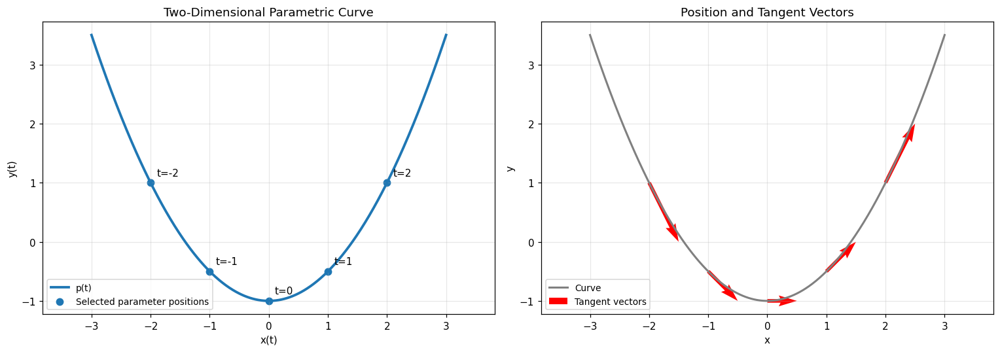

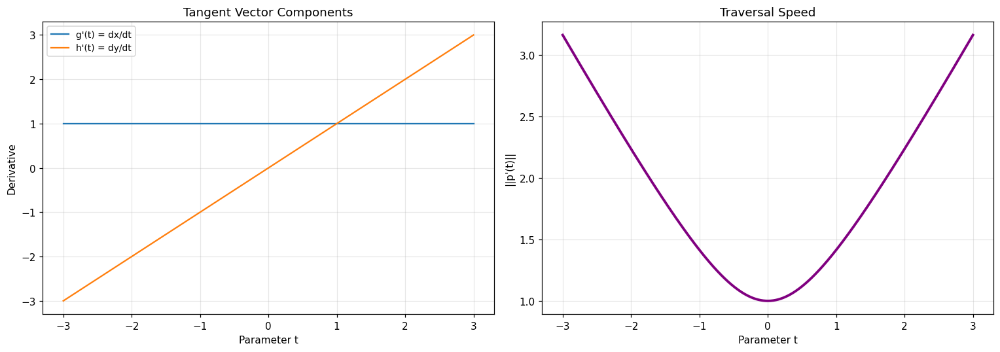

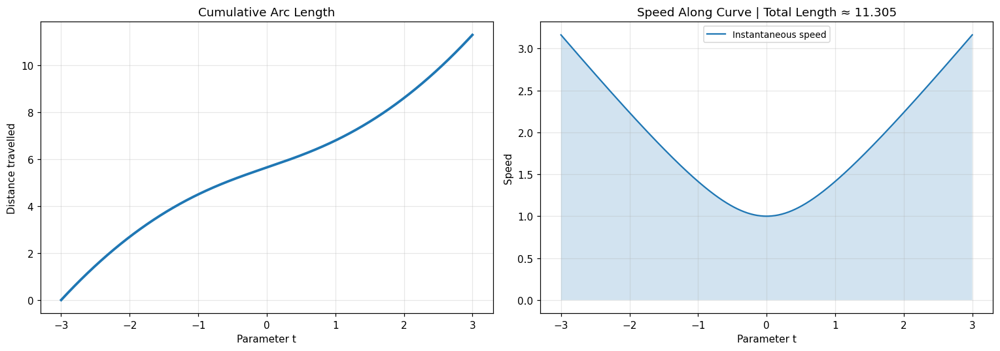

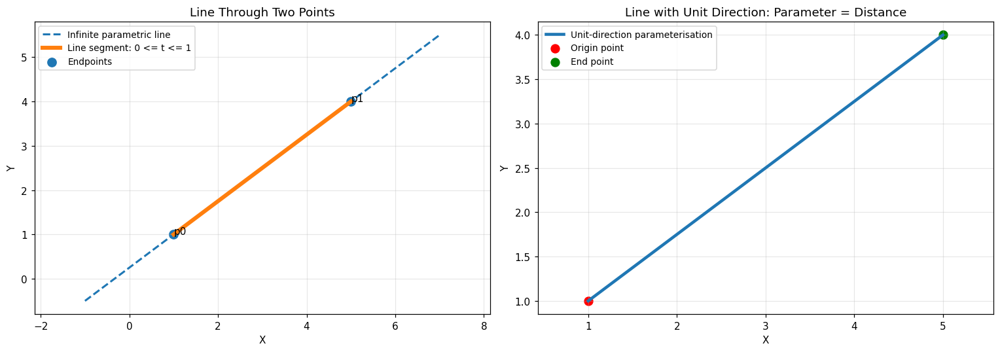

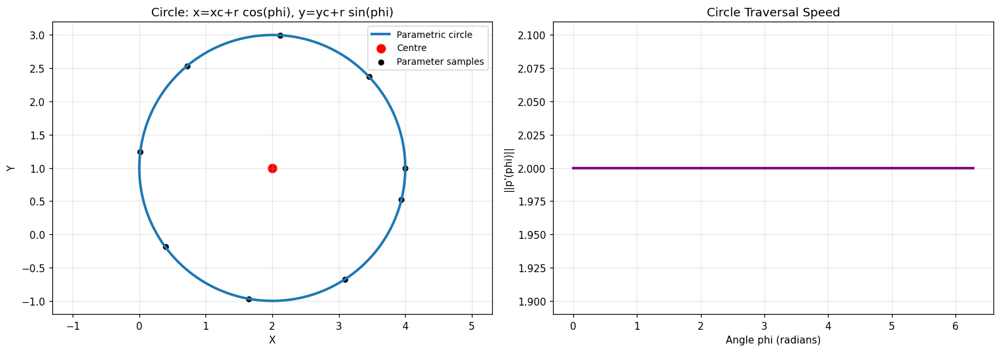

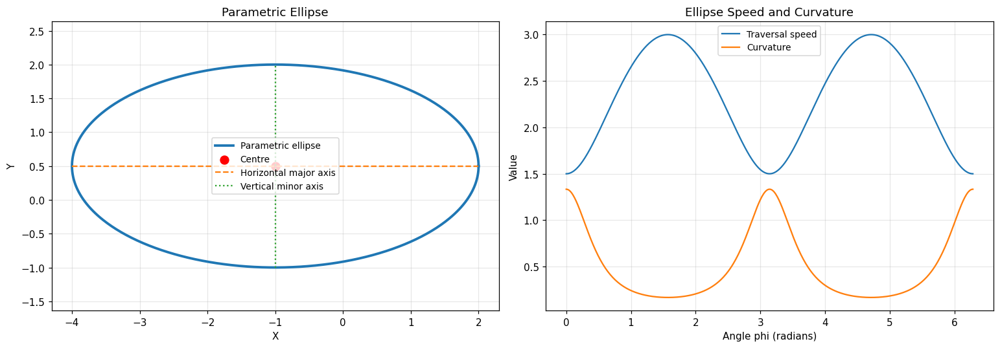

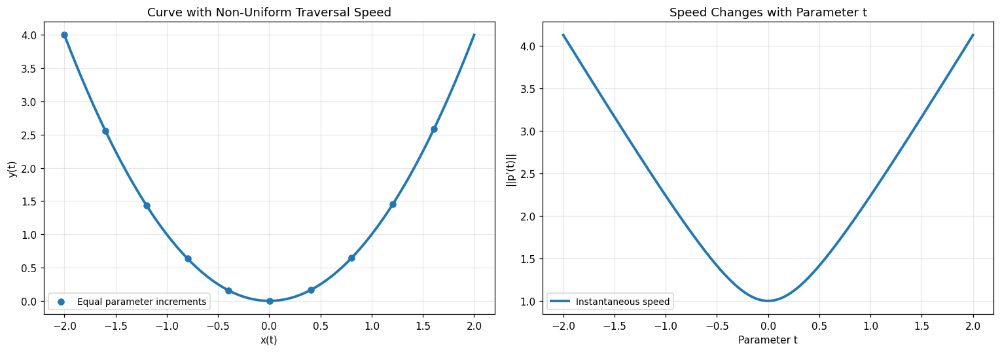

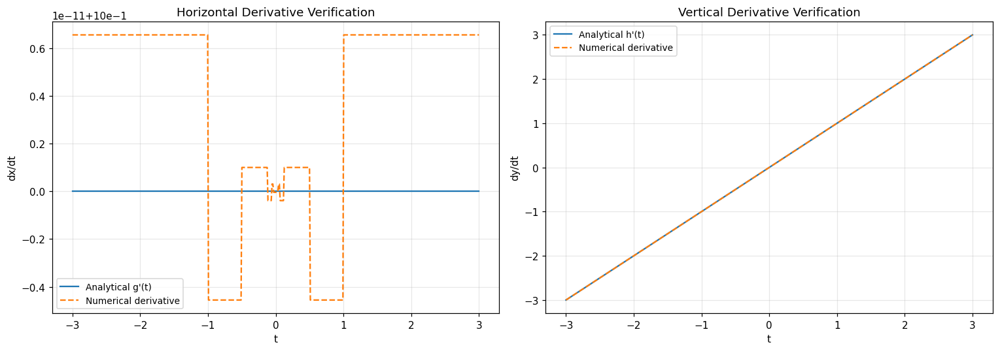

,t,x(t),y(t),dx/dt,dy/dt,Speed
0,-2.0,-2.0,1.0,1.0,-2.0,2.236068
1,-1.0,-1.0,-0.5,1.0,-1.0,1.414214
2,0.0,0.0,-1.0,1.0,0.0,1.000000
3,1.0,1.0,-0.5,1.0,1.0,1.414214
4,2.0,2.0,1.0,1.0,2.0,2.236068


,Quantity,Value
0,Initial x-coordinate,1.0
1,Initial y-coordinate,1.0
2,Final x-coordinate,5.0
3,Final y-coordinate,4.0
4,Direction x-component,4.0
5,Direction y-component,3.0
6,Direction magnitude,5.0
7,Line traversal speed,5.0


,Quantity,Value
0,Centre x,2.0
1,Centre y,1.0
2,Radius,2.0
3,Minimum speed,2.0
4,Maximum speed,2.0
5,Theoretical curvature,0.5


,Quantity,Value
0,Centre x,-1.000000
1,Centre y,0.500000
2,Horizontal semiaxis,3.000000
3,Vertical semiaxis,1.500000
4,Minimum speed,1.500000
5,Maximum speed,2.999989
6,Minimum curvature,0.166669
7,Maximum curvature,1.333333


,Verification,Value
0,Maximum horizontal derivative error,6.551204e-12
1,Maximum vertical derivative error,5.450485e-11
2,Circle implicit residual,1.776357e-15
3,Ellipse implicit residual,4.440892e-16
4,Line start-point error,0.000000e+00
5,Line end-point error,0.000000e+00
6,Circle speed variation,2.220446e-16
7,Total general curve arc length,1.130530e+01


In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. NUMERICAL CONFIGURATION AND PARAMETRIC CURVE FUNCTIONS
# ============================================================

EPS = 1e-10

def position(t, g, h):
    """p(t) = [g(t), h(t)]"""
    return np.array([g(t), h(t)])

def tangent(t, g_prime, h_prime):
    """p'(t) = [g'(t), h'(t)]"""
    return np.array([g_prime(t), h_prime(t)])

def speed(t, g_prime, h_prime):
    """v(t) = ||p'(t)||"""
    return np.linalg.norm(tangent(t, g_prime, h_prime), axis=0)

def numerical_derivative(function, t, dt=1e-5):
    """Central finite-difference approximation."""
    return (
        function(t + dt) - function(t - dt)
    ) / (2 * dt)


# ============================================================
# 2. GENERAL TWO-DIMENSIONAL PARAMETRIC CURVE
# ============================================================

# Example:
# x(t) = t
# y(t) = 0.5t² - 1

t = np.linspace(-3, 3, 500)

def g(t):
    return t

def h(t):
    return 0.5*t**2 - 1

def g_prime(t):
    return np.ones_like(t)

def h_prime(t):
    return t

x_curve = g(t)
y_curve = h(t)

tangent_x = g_prime(t)
tangent_y = h_prime(t)

curve_speed = np.sqrt(tangent_x**2 + tangent_y**2)

# Numerical tangent verification
numerical_dx = numerical_derivative(g, t)
numerical_dy = numerical_derivative(h, t)

# Selected parameter values
selected_t = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])

selected_positions = np.column_stack([
    g(selected_t),
    h(selected_t)
])

selected_tangents = np.column_stack([
    g_prime(selected_t),
    h_prime(selected_t)
])

selected_speeds = np.linalg.norm(
    selected_tangents, axis=1
)


# ============================================================
# 3. PARAMETRIC CURVE ARC-LENGTH APPROXIMATION
# ============================================================

# Arc length:
# L = integral ||p'(t)|| dt

arc_length_cumulative = np.zeros_like(t)

arc_length_cumulative[1:] = np.cumsum(
    0.5 * (
        curve_speed[1:] + curve_speed[:-1]
    ) * np.diff(t)
)

total_arc_length = arc_length_cumulative[-1]


# ============================================================
# 4. PARAMETRIC LINE THROUGH TWO POINTS
# ============================================================

p0 = np.array([1.0, 1.0])
p1 = np.array([5.0, 4.0])

direction = p1 - p0

t_line = np.linspace(0, 1, 100)

line_segment = (
    p0[:, None]
    + direction[:, None] * t_line
)

# Infinite line using the same origin and direction
t_infinite = np.linspace(-0.5, 1.5, 150)

infinite_line = (
    p0[:, None]
    + direction[:, None] * t_infinite
)

# Unit direction: parameter measures signed distance
unit_direction = direction / np.linalg.norm(direction)

t_distance = np.linspace(0, np.linalg.norm(direction), 100)

distance_parameter_line = (
    p0[:, None]
    + unit_direction[:, None] * t_distance
)

# Verify endpoints
line_start = p0 + 0 * direction
line_end = p0 + 1 * direction

# Line speed with respect to t
line_speed = np.linalg.norm(direction)


# ============================================================
# 5. PARAMETRIC CIRCLE
# ============================================================

circle_centre = np.array([2.0, 1.0])
circle_radius = 2.0

phi = np.linspace(0, 2*np.pi, 500)

circle_x = (
    circle_centre[0]
    + circle_radius * np.cos(phi)
)

circle_y = (
    circle_centre[1]
    + circle_radius * np.sin(phi)
)

# Derivatives:
# x'(phi) = -r sin(phi)
# y'(phi) = r cos(phi)

circle_dx = -circle_radius * np.sin(phi)
circle_dy = circle_radius * np.cos(phi)

circle_speed = np.sqrt(
    circle_dx**2 + circle_dy**2
)

# Circle curvature:
# kappa = 1/r

circle_curvature = 1 / circle_radius

# Implicit circle residual:
# (x-xc)² + (y-yc)² - r² = 0

circle_residual = (
    (circle_x - circle_centre[0])**2
    + (circle_y - circle_centre[1])**2
    - circle_radius**2
)


# ============================================================
# 6. PARAMETRIC ELLIPSE
# ============================================================

ellipse_centre = np.array([-1.0, 0.5])
ellipse_a = 3.0
ellipse_b = 1.5

ellipse_x = (
    ellipse_centre[0]
    + ellipse_a * np.cos(phi)
)

ellipse_y = (
    ellipse_centre[1]
    + ellipse_b * np.sin(phi)
)

# Derivatives
ellipse_dx = -ellipse_a * np.sin(phi)
ellipse_dy = ellipse_b * np.cos(phi)

ellipse_speed = np.sqrt(
    ellipse_dx**2 + ellipse_dy**2
)

# Implicit ellipse residual
ellipse_residual = (
    ((ellipse_x - ellipse_centre[0]) / ellipse_a)**2
    + ((ellipse_y - ellipse_centre[1]) / ellipse_b)**2
    - 1
)

# Ellipse curvature:
# kappa(phi) = ab / (a²sin²(phi) + b²cos²(phi))^(3/2)

ellipse_curvature = (
    ellipse_a * ellipse_b
    / (
        ellipse_a**2 * np.sin(phi)**2
        + ellipse_b**2 * np.cos(phi)**2
    )**1.5
)


# ============================================================
# 7. NON-UNIFORM PARAMETER SPEED EXAMPLE
# ============================================================

# Curve:
# x(t) = t
# y(t) = t²

t_speed = np.linspace(-2, 2, 500)

x_speed_curve = t_speed
y_speed_curve = t_speed**2

dx_speed = np.ones_like(t_speed)
dy_speed = 2 * t_speed

speed_variable = np.sqrt(
    dx_speed**2 + dy_speed**2
)

# Equal parameter increments
parameter_steps = np.diff(t_speed)

# Corresponding approximate travelled distances
distance_steps = np.sqrt(
    np.diff(x_speed_curve)**2
    + np.diff(y_speed_curve)**2
)


# ============================================================
# 8. TANGENT VECTORS ALONG A PARAMETRIC CURVE
# ============================================================

tangent_parameters = np.array([
    -2.0, -1.0, 0.0, 1.0, 2.0
])

tangent_positions = np.column_stack([
    g(tangent_parameters),
    h(tangent_parameters)
])

tangent_vectors = np.column_stack([
    g_prime(tangent_parameters),
    h_prime(tangent_parameters)
])

tangent_unit_vectors = (
    tangent_vectors
    / np.linalg.norm(tangent_vectors, axis=1)[:, None]
)


# ============================================================
# 9. VISUALISATION 1: GENERAL PARAMETRIC CURVE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    x_curve,
    y_curve,
    linewidth=2.5,
    label="p(t)"
)

axes[0].scatter(
    selected_positions[:, 0],
    selected_positions[:, 1],
    s=45,
    label="Selected parameter positions"
)

for i, parameter in enumerate(selected_t):
    axes[0].annotate(
        f"t={parameter:g}",
        selected_positions[i],
        xytext=(6, 7),
        textcoords="offset points"
    )

axes[0].set_title("Two-Dimensional Parametric Curve")
axes[0].set_xlabel("x(t)")
axes[0].set_ylabel("y(t)")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    x_curve,
    y_curve,
    color="gray",
    linewidth=2,
    label="Curve"
)

axes[1].quiver(
    selected_positions[:, 0],
    selected_positions[:, 1],
    selected_tangents[:, 0],
    selected_tangents[:, 1],
    angles="xy",
    scale_units="xy",
    scale=2,
    color="red",
    width=0.008,
    label="Tangent vectors"
)

axes[1].set_title("Position and Tangent Vectors")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 10. VISUALISATION 2: TANGENT AND TRAVERSAL SPEED
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    t,
    tangent_x,
    label="g'(t) = dx/dt"
)

axes[0].plot(
    t,
    tangent_y,
    label="h'(t) = dy/dt"
)

axes[0].set_title("Tangent Vector Components")
axes[0].set_xlabel("Parameter t")
axes[0].set_ylabel("Derivative")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    t,
    curve_speed,
    linewidth=2.5,
    color="purple"
)

axes[1].set_title("Traversal Speed")
axes[1].set_xlabel("Parameter t")
axes[1].set_ylabel("||p'(t)||")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 11. VISUALISATION 3: ARC LENGTH AND PARAMETER
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    t,
    arc_length_cumulative,
    linewidth=2.5
)

axes[0].set_title("Cumulative Arc Length")
axes[0].set_xlabel("Parameter t")
axes[0].set_ylabel("Distance travelled")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    t,
    curve_speed,
    label="Instantaneous speed"
)

axes[1].fill_between(
    t,
    curve_speed,
    alpha=0.2
)

axes[1].set_title(
    f"Speed Along Curve | Total Length ≈ {total_arc_length:.3f}"
)

axes[1].set_xlabel("Parameter t")
axes[1].set_ylabel("Speed")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 12. VISUALISATION 4: PARAMETRIC LINE AND LINE SEGMENT
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    infinite_line[0],
    infinite_line[1],
    linestyle="--",
    linewidth=2,
    label="Infinite parametric line"
)

axes[0].plot(
    line_segment[0],
    line_segment[1],
    linewidth=4,
    label="Line segment: 0 <= t <= 1"
)

axes[0].scatter(
    [p0[0], p1[0]],
    [p0[1], p1[1]],
    s=75,
    label="Endpoints"
)

axes[0].annotate("p0", p0)
axes[0].annotate("p1", p1)

axes[0].set_title("Line Through Two Points")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    distance_parameter_line[0],
    distance_parameter_line[1],
    linewidth=3,
    label="Unit-direction parameterisation"
)

axes[1].scatter(
    *p0,
    color="red",
    s=70,
    label="Origin point"
)

axes[1].scatter(
    *p1,
    color="green",
    s=70,
    label="End point"
)

axes[1].set_title(
    "Line with Unit Direction: Parameter = Distance"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 13. VISUALISATION 5: PARAMETRIC CIRCLE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    circle_x,
    circle_y,
    linewidth=2.5,
    label="Parametric circle"
)

axes[0].scatter(
    *circle_centre,
    color="red",
    s=70,
    label="Centre"
)

axes[0].scatter(
    circle_x[::60],
    circle_y[::60],
    color="black",
    s=25,
    label="Parameter samples"
)

axes[0].set_title("Circle: x=xc+r cos(phi), y=yc+r sin(phi)")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    phi,
    circle_speed,
    color="purple",
    linewidth=2.5
)

axes[1].set_title("Circle Traversal Speed")
axes[1].set_xlabel("Angle phi (radians)")
axes[1].set_ylabel("||p'(phi)||")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 14. VISUALISATION 6: PARAMETRIC ELLIPSE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    ellipse_x,
    ellipse_y,
    linewidth=2.5,
    label="Parametric ellipse"
)

axes[0].scatter(
    *ellipse_centre,
    color="red",
    s=70,
    label="Centre"
)

axes[0].plot(
    [
        ellipse_centre[0] - ellipse_a,
        ellipse_centre[0] + ellipse_a
    ],
    [
        ellipse_centre[1],
        ellipse_centre[1]
    ],
    linestyle="--",
    label="Horizontal major axis"
)

axes[0].plot(
    [
        ellipse_centre[0],
        ellipse_centre[0]
    ],
    [
        ellipse_centre[1] - ellipse_b,
        ellipse_centre[1] + ellipse_b
    ],
    linestyle=":",
    label="Vertical minor axis"
)

axes[0].set_title("Parametric Ellipse")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    phi,
    ellipse_speed,
    label="Traversal speed"
)

axes[1].plot(
    phi,
    ellipse_curvature,
    label="Curvature"
)

axes[1].set_title("Ellipse Speed and Curvature")
axes[1].set_xlabel("Angle phi (radians)")
axes[1].set_ylabel("Value")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 15. VISUALISATION 7: NON-UNIFORM PARAMETER SPEED
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    x_speed_curve,
    y_speed_curve,
    linewidth=2.5
)

axes[0].scatter(
    x_speed_curve[::50],
    y_speed_curve[::50],
    s=35,
    label="Equal parameter increments"
)

axes[0].set_title("Curve with Non-Uniform Traversal Speed")
axes[0].set_xlabel("x(t)")
axes[0].set_ylabel("y(t)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    t_speed,
    speed_variable,
    linewidth=2.5,
    label="Instantaneous speed"
)

axes[1].set_title("Speed Changes with Parameter t")
axes[1].set_xlabel("Parameter t")
axes[1].set_ylabel("||p'(t)||")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 16. VISUALISATION 8: PARAMETRIC CURVE AND NUMERICAL DERIVATIVE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    t,
    tangent_x,
    label="Analytical g'(t)"
)

axes[0].plot(
    t,
    numerical_dx,
    linestyle="--",
    label="Numerical derivative"
)

axes[0].set_title("Horizontal Derivative Verification")
axes[0].set_xlabel("t")
axes[0].set_ylabel("dx/dt")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    t,
    tangent_y,
    label="Analytical h'(t)"
)

axes[1].plot(
    t,
    numerical_dy,
    linestyle="--",
    label="Numerical derivative"
)

axes[1].set_title("Vertical Derivative Verification")
axes[1].set_xlabel("t")
axes[1].set_ylabel("dy/dt")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 17. NUMERICAL RESULTS TABLES
# ============================================================

curve_table = pd.DataFrame({
    "t": selected_t,
    "x(t)": selected_positions[:, 0],
    "y(t)": selected_positions[:, 1],
    "dx/dt": selected_tangents[:, 0],
    "dy/dt": selected_tangents[:, 1],
    "Speed": selected_speeds
})

line_table = pd.DataFrame({
    "Quantity": [
        "Initial x-coordinate",
        "Initial y-coordinate",
        "Final x-coordinate",
        "Final y-coordinate",
        "Direction x-component",
        "Direction y-component",
        "Direction magnitude",
        "Line traversal speed"
    ],
    "Value": [
        p0[0],
        p0[1],
        p1[0],
        p1[1],
        direction[0],
        direction[1],
        np.linalg.norm(direction),
        line_speed
    ]
})

circle_table = pd.DataFrame({
    "Quantity": [
        "Centre x",
        "Centre y",
        "Radius",
        "Minimum speed",
        "Maximum speed",
        "Theoretical curvature"
    ],
    "Value": [
        circle_centre[0],
        circle_centre[1],
        circle_radius,
        np.min(circle_speed),
        np.max(circle_speed),
        circle_curvature
    ]
})

ellipse_table = pd.DataFrame({
    "Quantity": [
        "Centre x",
        "Centre y",
        "Horizontal semiaxis",
        "Vertical semiaxis",
        "Minimum speed",
        "Maximum speed",
        "Minimum curvature",
        "Maximum curvature"
    ],
    "Value": [
        ellipse_centre[0],
        ellipse_centre[1],
        ellipse_a,
        ellipse_b,
        np.min(ellipse_speed),
        np.max(ellipse_speed),
        np.min(ellipse_curvature),
        np.max(ellipse_curvature)
    ]
})

verification_table = pd.DataFrame({
    "Verification": [
        "Maximum horizontal derivative error",
        "Maximum vertical derivative error",
        "Circle implicit residual",
        "Ellipse implicit residual",
        "Line start-point error",
        "Line end-point error",
        "Circle speed variation",
        "Total general curve arc length"
    ],
    "Value": [
        np.max(np.abs(tangent_x - numerical_dx)),
        np.max(np.abs(tangent_y - numerical_dy)),
        np.max(np.abs(circle_residual)),
        np.max(np.abs(ellipse_residual)),
        np.linalg.norm(line_start - p0),
        np.linalg.norm(line_end - p1),
        np.max(circle_speed) - np.min(circle_speed),
        total_arc_length
    ]
})

display(curve_table)
display(line_table)
display(circle_table)
display(ellipse_table)
display(verification_table)


# ============================================================
# 18. MATHEMATICAL VERIFICATION
# ============================================================

# General parametric curve derivative
assert np.allclose(
    tangent_x,
    numerical_dx,
    atol=1e-7
)

assert np.allclose(
    tangent_y,
    numerical_dy,
    atol=1e-7
)

# Speed must be the magnitude of the tangent.
assert np.allclose(
    curve_speed,
    np.sqrt(tangent_x**2 + tangent_y**2)
)

# Line must pass through its endpoints.
assert np.allclose(line_start, p0)
assert np.allclose(line_end, p1)

# Unit direction has magnitude one.
assert np.isclose(
    np.linalg.norm(unit_direction),
    1.0
)

# Circle points must satisfy the implicit circle equation.
assert np.allclose(
    circle_residual,
    0,
    atol=1e-10
)

# Circle speed is constant and equal to its radius
# when phi is the angular parameter.
assert np.allclose(
    circle_speed,
    circle_radius,
    atol=1e-10
)

# Ellipse points must satisfy the implicit ellipse equation.
assert np.allclose(
    ellipse_residual,
    0,
    atol=1e-10
)

# Ellipse traversal speed varies for unequal semiaxes.
assert ellipse_a != ellipse_b
assert np.max(ellipse_speed) > np.min(ellipse_speed)

# Arc length must increase along the traversal.
assert np.all(np.diff(arc_length_cumulative) >= 0)

# A nonzero line direction produces positive traversal speed.
assert line_speed > 0


### 2.5.7 Three-Dimensional Parametric Curves

A **three-dimensional parametric curve** describes a spatial trajectory through three coordinate functions controlled by a continuous parameter $t$:

$$
x=f(t),\quad y=g(t),\quad z=h(t)
$$

Its vector representation is:

$$
\mathbf{p}(t)=
\begin{bmatrix}
f(t)\\
g(t)\\
h(t)
\end{bmatrix},
\qquad
\mathbf{p}:D\subseteq\mathbb{R}\rightarrow\mathbb{R}^3
$$

Here, $D$ denotes the parameter domain, while the function range defines the spatial curve. Restricting $D$ determines its starting and ending positions.

**Example: Three-Dimensional Spiral**

A spiral ascending around the $z$-axis is represented by:

$$
\mathbf{p}(t)=
\begin{bmatrix}
\cos t\\
\sin t\\
t
\end{bmatrix}
$$

As $t$ increases, the cosine and sine components generate circular motion, while the third component increases vertically, producing an ascending spiral.

**Three-Dimensional Parametric Lines**

A spatial line is expressed as:

$$
\boxed{\mathbf{p}(t)=\mathbf{o}+t\mathbf{d}}
$$

Here, $\mathbf{o}=(o_x,o_y,o_z)$ is a fixed point, $\mathbf{d}=(d_x,d_y,d_z)$ is the direction vector, and $t\in\mathbb{R}$ controls position.

Consider:

$$
\mathbf{o}=(2,1,3),\qquad \mathbf{d}=(7,2,-5)
$$

At $t=2$:

$$
\begin{aligned}
\mathbf{p}(2)&=(2,1,3)+2(7,2,-5)\\
&=(16,5,-7)
\end{aligned}
$$

Thus, the direction vector establishes orientation, while the parameter determines position.

**Line Segments and Rays**

A segment joining points $\mathbf{a}$ and $\mathbf{b}$ is:

$$
\mathbf{p}(t)=\mathbf{a}+t(\mathbf{b}-\mathbf{a}),
\quad 0\leq t\leq1
$$

Its endpoints are $\mathbf{p}(0)=\mathbf{a}$ and $\mathbf{p}(1)=\mathbf{b}$. At $t=0.5$, its midpoint is:

$$
\mathbf{p}(0.5)=\frac{\mathbf{a}+\mathbf{b}}{2}
$$

A **ray** extends infinitely in one direction from an origin, with $t\in[0,\infty)$. These representations support spatial modelling, intersection analysis and ray-based rendering.

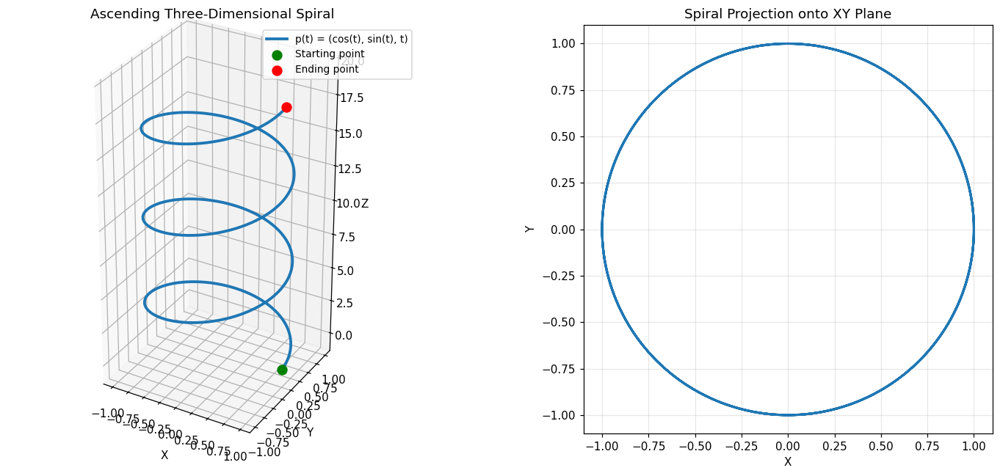

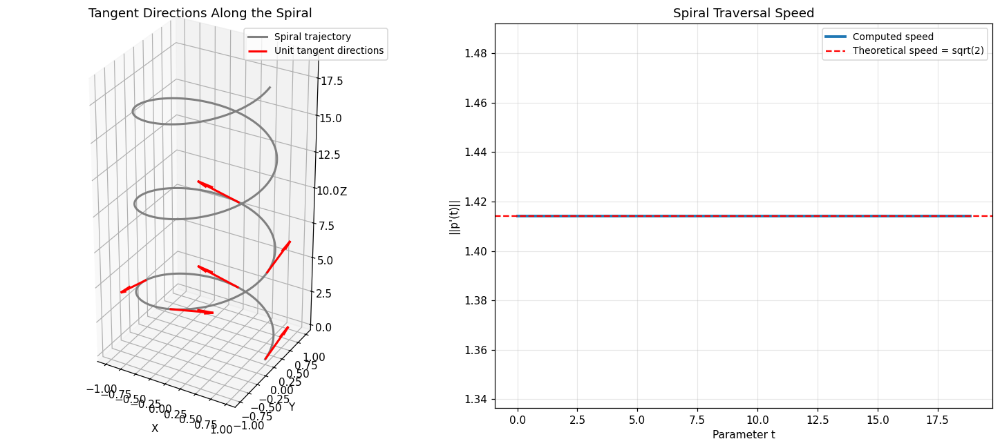

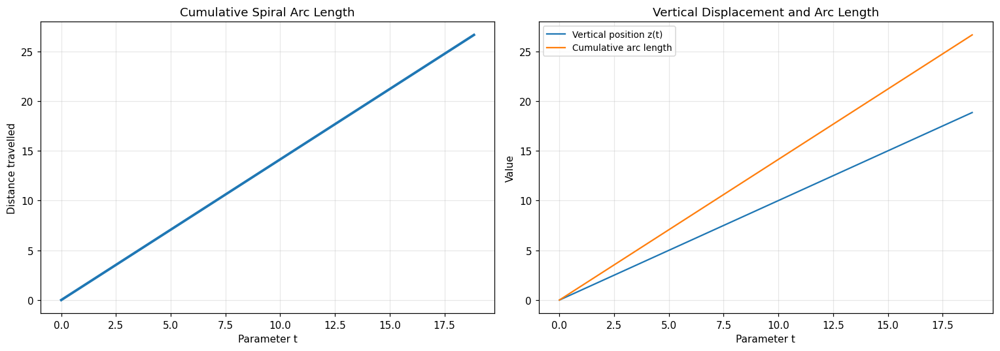

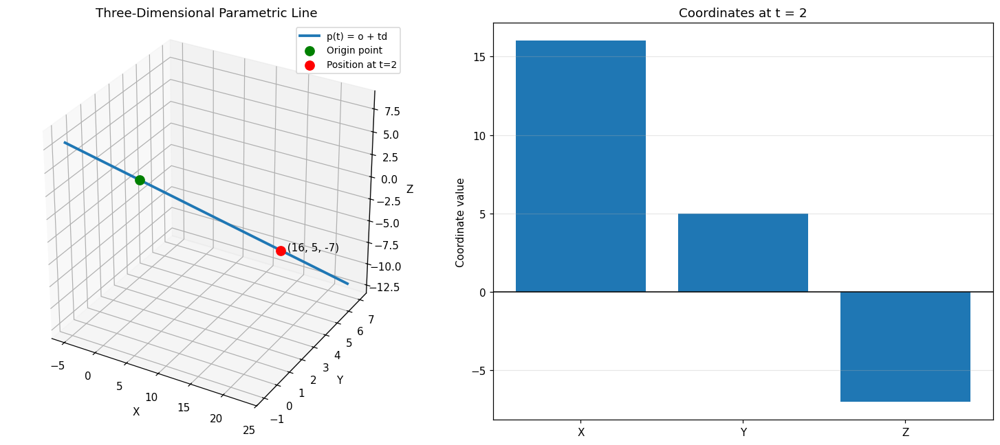

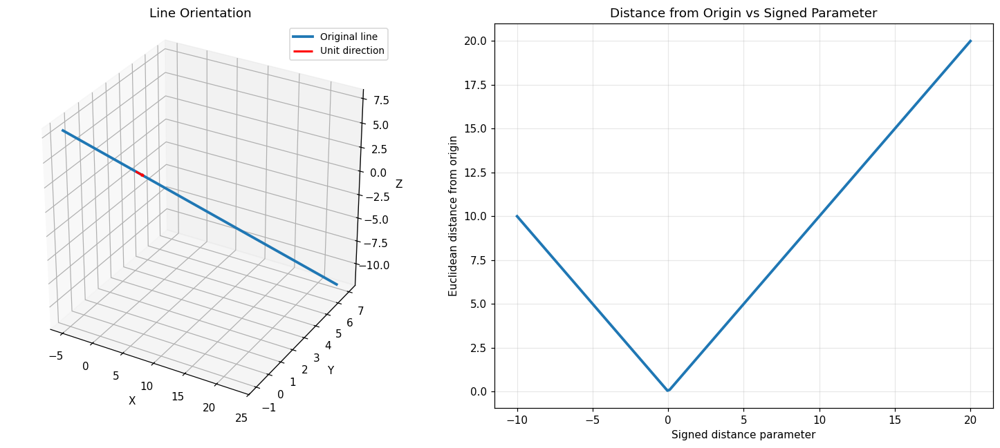

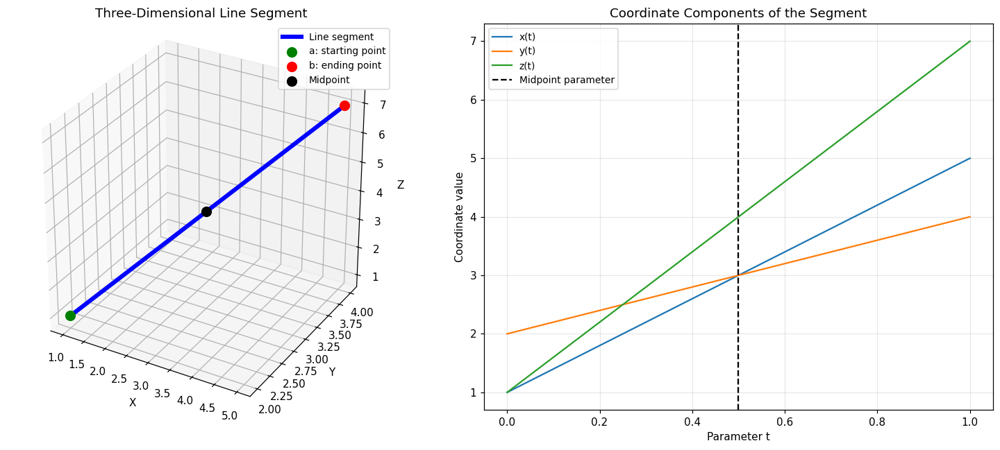

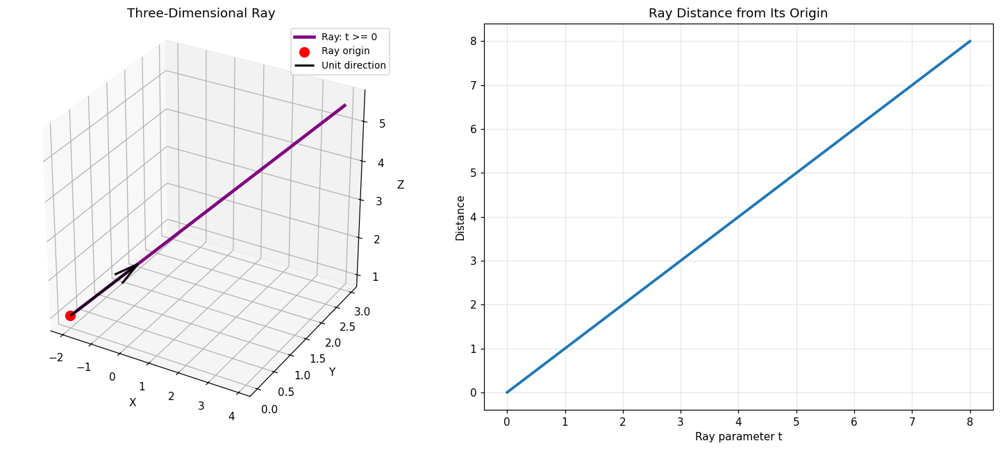

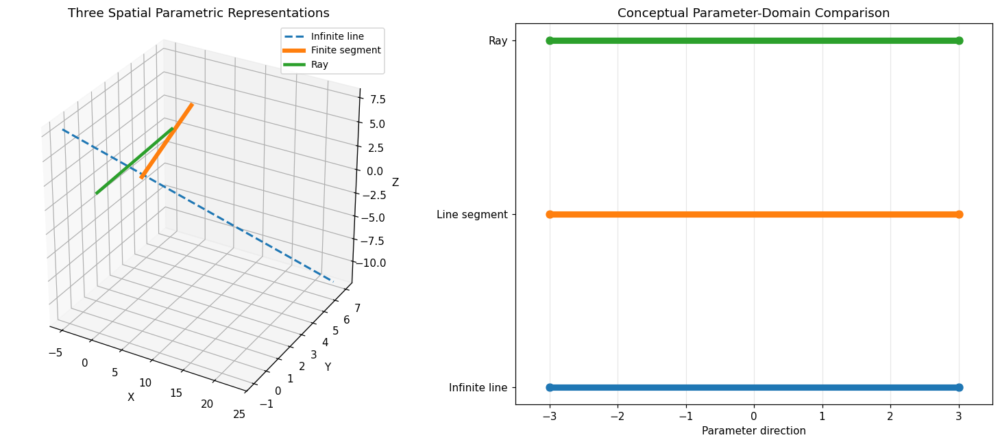

,Parameter t,x(t),y(t),z(t),Tangent x,Tangent y,Tangent z,Speed
0,0.000000,1.000000e+00,0.000000e+00,0.000000,-0.000000e+00,1.000000e+00,1.0,1.414214
1,1.570796,6.123234e-17,1.000000e+00,1.570796,-1.000000e+00,6.123234e-17,1.0,1.414214
2,3.141593,-1.000000e+00,1.224647e-16,3.141593,-1.224647e-16,-1.000000e+00,1.0,1.414214
3,4.712389,-1.836970e-16,-1.000000e+00,4.712389,1.000000e+00,-1.836970e-16,1.0,1.414214
4,6.283185,1.000000e+00,-2.449294e-16,6.283185,2.449294e-16,1.000000e+00,1.0,1.414214
5,7.853982,3.061617e-16,1.000000e+00,7.853982,-1.000000e+00,3.061617e-16,1.0,1.414214


,Quantity,Value
0,Origin x,2.000000
1,Origin y,1.000000
2,Origin z,3.000000
3,Direction x,7.000000
4,Direction y,2.000000
5,Direction z,-5.000000
6,Parameter t,2.000000
7,Position x at t=2,16.000000
8,Position y at t=2,5.000000
9,Position z at t=2,-7.000000


,Quantity,Value
0,Start x,1.000000
1,Start y,2.000000
2,Start z,1.000000
3,End x,5.000000
4,End y,4.000000
5,End z,7.000000
6,Midpoint x,3.000000
7,Midpoint y,3.000000
8,Midpoint z,4.000000
9,Segment length,7.483315


,Quantity,Value
0,Origin x,-2.000000
1,Origin y,0.000000
2,Origin z,1.000000
3,Unit direction x,0.742781
4,Unit direction y,0.371391
5,Unit direction z,0.557086
6,Final sampled parameter,8.000000
7,Final sampled distance,8.000000


,Verification,Value
0,Maximum x derivative error,5.518674e-11
1,Maximum y derivative error,5.508738e-11
2,Maximum z derivative error,3.785783e-11
3,Maximum spiral speed error,2.220446e-16
4,Spiral arc length,2.665730e+01
5,Line position error at t=2,0.000000e+00
6,Segment start-point error,0.000000e+00
7,Segment end-point error,0.000000e+00
8,Midpoint formula error,0.000000e+00
9,Unit ray direction error,0.000000e+00


In [41]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. NUMERICAL CONFIGURATION AND VECTOR OPERATIONS
# ============================================================

EPS = 1e-10

def magnitude(v):
    return np.linalg.norm(v, axis=0)

def normalize(v):
    v = np.asarray(v, dtype=float)
    length = np.linalg.norm(v)

    if length < EPS:
        raise ValueError("A zero vector cannot be normalised.")

    return v / length

def position_3d(t, f, g, h):
    """p(t) = [f(t), g(t), h(t)]"""
    return np.array([f(t), g(t), h(t)])

def tangent_3d(t, f_prime, g_prime, h_prime):
    """p'(t) = [f'(t), g'(t), h'(t)]"""
    return np.array([
        f_prime(t),
        g_prime(t),
        h_prime(t)
    ])

def speed_3d(t, f_prime, g_prime, h_prime):
    """v(t) = ||p'(t)||"""
    return np.linalg.norm(
        tangent_3d(t, f_prime, g_prime, h_prime),
        axis=0
    )


# ============================================================
# 2. THREE-DIMENSIONAL SPIRAL
# ============================================================

# Given:
# x(t) = cos(t)
# y(t) = sin(t)
# z(t) = t

t_spiral = np.linspace(0, 6*np.pi, 800)

def spiral_x(t):
    return np.cos(t)

def spiral_y(t):
    return np.sin(t)

def spiral_z(t):
    return t

def spiral_dx(t):
    return -np.sin(t)

def spiral_dy(t):
    return np.cos(t)

def spiral_dz(t):
    return np.ones_like(t)

spiral = position_3d(
    t_spiral,
    spiral_x,
    spiral_y,
    spiral_z
)

spiral_tangent = tangent_3d(
    t_spiral,
    spiral_dx,
    spiral_dy,
    spiral_dz
)

spiral_speed = np.linalg.norm(
    spiral_tangent,
    axis=0
)

# Theoretical speed:
# sqrt(sin²(t) + cos²(t) + 1) = sqrt(2)

spiral_theoretical_speed = np.sqrt(2)

# Spiral pitch: vertical distance per complete revolution
spiral_pitch = 2*np.pi


# ============================================================
# 3. SPIRAL ARC LENGTH
# ============================================================

spiral_arc_length = np.zeros_like(t_spiral)

spiral_arc_length[1:] = np.cumsum(
    0.5 * (
        spiral_speed[1:] + spiral_speed[:-1]
    ) * np.diff(t_spiral)
)

spiral_total_length = spiral_arc_length[-1]


# ============================================================
# 4. THREE-DIMENSIONAL PARAMETRIC LINE
# ============================================================

# Given:
# o = (2, 1, 3)
# d = (7, 2, -5)

origin = np.array([2.0, 1.0, 3.0])
direction = np.array([7.0, 2.0, -5.0])

t_line = np.linspace(-1, 3, 200)

# p(t) = o + td
spatial_line = (
    origin[:, None]
    + direction[:, None] * t_line
)

# Position at t = 2
t_example = 2.0

position_at_2 = origin + t_example * direction

# Expected position = (16, 5, -7)

line_speed = np.linalg.norm(direction)

# Unit direction
unit_direction = normalize(direction)

# Signed-distance parameterisation
distance_parameter = np.linspace(-10, 20, 200)

distance_line = (
    origin[:, None]
    + unit_direction[:, None] * distance_parameter
)


# ============================================================
# 5. THREE-DIMENSIONAL LINE SEGMENT
# ============================================================

a = np.array([1.0, 2.0, 1.0])
b = np.array([5.0, 4.0, 7.0])

segment_direction = b - a

t_segment = np.linspace(0, 1, 150)

# p(t) = a + t(b-a), 0 <= t <= 1

line_segment = (
    a[:, None]
    + segment_direction[:, None] * t_segment
)

# Endpoints
segment_start = a + 0 * segment_direction
segment_end = a + 1 * segment_direction

# Midpoint
midpoint = a + 0.5 * segment_direction

# Equivalent midpoint formula
midpoint_equivalent = (a + b) / 2

segment_length = np.linalg.norm(segment_direction)


# ============================================================
# 6. THREE-DIMENSIONAL RAY
# ============================================================

# A ray begins at a and extends in direction d.
# t belongs to [0, infinity).

ray_origin = np.array([-2.0, 0.0, 1.0])
ray_direction = normalize(np.array([2.0, 1.0, 1.5]))

t_ray = np.linspace(0, 8, 200)

ray = (
    ray_origin[:, None]
    + ray_direction[:, None] * t_ray
)


# ============================================================
# 7. TANGENT AND VELOCITY VECTORS ALONG THE SPIRAL
# ============================================================

selected_parameters = np.array([
    0.0,
    np.pi/2,
    np.pi,
    3*np.pi/2,
    2*np.pi,
    5*np.pi/2
])

selected_positions = position_3d(
    selected_parameters,
    spiral_x,
    spiral_y,
    spiral_z
)

selected_tangents = tangent_3d(
    selected_parameters,
    spiral_dx,
    spiral_dy,
    spiral_dz
)

selected_speeds = np.linalg.norm(
    selected_tangents,
    axis=0
)


# ============================================================
# 8. NUMERICAL DERIVATIVE VERIFICATION
# ============================================================

def central_difference(function, t, dt=1e-5):
    return (
        function(t + dt) - function(t - dt)
    ) / (2*dt)

numerical_dx = central_difference(spiral_x, t_spiral)
numerical_dy = central_difference(spiral_y, t_spiral)
numerical_dz = central_difference(spiral_z, t_spiral)

derivative_errors = {
    "x": np.max(np.abs(numerical_dx - spiral_dx(t_spiral))),
    "y": np.max(np.abs(numerical_dy - spiral_dy(t_spiral))),
    "z": np.max(np.abs(numerical_dz - spiral_dz(t_spiral)))
}


# ============================================================
# 9. VISUALISATION 1: THREE-DIMENSIONAL SPIRAL
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    spiral[0],
    spiral[1],
    spiral[2],
    linewidth=2.5,
    label="p(t) = (cos(t), sin(t), t)"
)

ax1.scatter(
    spiral[0][0],
    spiral[1][0],
    spiral[2][0],
    color="green",
    s=70,
    label="Starting point"
)

ax1.scatter(
    spiral[0][-1],
    spiral[1][-1],
    spiral[2][-1],
    color="red",
    s=70,
    label="Ending point"
)

ax1.set_title("Ascending Three-Dimensional Spiral")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 2])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    spiral[0],
    spiral[1],
    linewidth=2
)

ax2.set_title("Spiral Projection onto XY Plane")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 10. VISUALISATION 2: SPIRAL TANGENT VECTORS
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    spiral[0],
    spiral[1],
    spiral[2],
    color="gray",
    linewidth=2,
    label="Spiral trajectory"
)

ax1.quiver(
    selected_positions[0],
    selected_positions[1],
    selected_positions[2],
    selected_tangents[0],
    selected_tangents[1],
    selected_tangents[2],
    length=1.0,
    normalize=True,
    color="red",
    linewidth=2,
    label="Unit tangent directions"
)

ax1.set_title("Tangent Directions Along the Spiral")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 2])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    t_spiral,
    spiral_speed,
    linewidth=2.5,
    label="Computed speed"
)

ax2.axhline(
    spiral_theoretical_speed,
    linestyle="--",
    color="red",
    label="Theoretical speed = sqrt(2)"
)

ax2.set_title("Spiral Traversal Speed")
ax2.set_xlabel("Parameter t")
ax2.set_ylabel("||p'(t)||")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 11. VISUALISATION 3: SPIRAL ARC LENGTH
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    t_spiral,
    spiral_arc_length,
    linewidth=2.5
)

axes[0].set_title("Cumulative Spiral Arc Length")
axes[0].set_xlabel("Parameter t")
axes[0].set_ylabel("Distance travelled")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    t_spiral,
    spiral_z(t_spiral),
    label="Vertical position z(t)"
)

axes[1].plot(
    t_spiral,
    spiral_arc_length,
    label="Cumulative arc length"
)

axes[1].set_title("Vertical Displacement and Arc Length")
axes[1].set_xlabel("Parameter t")
axes[1].set_ylabel("Value")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 12. VISUALISATION 4: THREE-DIMENSIONAL PARAMETRIC LINE
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    spatial_line[0],
    spatial_line[1],
    spatial_line[2],
    linewidth=2.5,
    label="p(t) = o + td"
)

ax1.scatter(
    *origin,
    color="green",
    s=75,
    label="Origin point"
)

ax1.scatter(
    *position_at_2,
    color="red",
    s=75,
    label="Position at t=2"
)

ax1.text(
    *position_at_2,
    "  (16, 5, -7)"
)

ax1.set_title("Three-Dimensional Parametric Line")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

coordinate_names = ["X", "Y", "Z"]

ax2.bar(
    coordinate_names,
    position_at_2
)

ax2.axhline(0, color="black", linewidth=1)
ax2.set_title("Coordinates at t = 2")
ax2.set_ylabel("Coordinate value")
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 13. VISUALISATION 5: LINE DIRECTION AND DISTANCE
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    spatial_line[0],
    spatial_line[1],
    spatial_line[2],
    linewidth=2.5,
    label="Original line"
)

ax1.quiver(
    *origin,
    *direction,
    length=1,
    normalize=True,
    color="red",
    linewidth=2,
    label="Unit direction"
)

ax1.set_title("Line Orientation")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    distance_parameter,
    np.linalg.norm(
        distance_line - origin[:, None],
        axis=0
    ),
    linewidth=2.5
)

ax2.set_title("Distance from Origin vs Signed Parameter")
ax2.set_xlabel("Signed distance parameter")
ax2.set_ylabel("Euclidean distance from origin")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 14. VISUALISATION 6: THREE-DIMENSIONAL LINE SEGMENT
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    line_segment[0],
    line_segment[1],
    line_segment[2],
    linewidth=4,
    color="blue",
    label="Line segment"
)

ax1.scatter(
    *a,
    color="green",
    s=80,
    label="a: starting point"
)

ax1.scatter(
    *b,
    color="red",
    s=80,
    label="b: ending point"
)

ax1.scatter(
    *midpoint,
    color="black",
    s=80,
    label="Midpoint"
)

ax1.set_title("Three-Dimensional Line Segment")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(
    t_segment,
    line_segment[0],
    label="x(t)"
)

ax2.plot(
    t_segment,
    line_segment[1],
    label="y(t)"
)

ax2.plot(
    t_segment,
    line_segment[2],
    label="z(t)"
)

ax2.axvline(
    0.5,
    linestyle="--",
    color="black",
    label="Midpoint parameter"
)

ax2.set_title("Coordinate Components of the Segment")
ax2.set_xlabel("Parameter t")
ax2.set_ylabel("Coordinate value")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 15. VISUALISATION 7: THREE-DIMENSIONAL RAY
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    ray[0],
    ray[1],
    ray[2],
    linewidth=3,
    color="purple",
    label="Ray: t >= 0"
)

ax1.scatter(
    *ray_origin,
    color="red",
    s=80,
    label="Ray origin"
)

ax1.quiver(
    *ray_origin,
    *ray_direction,
    length=2,
    color="black",
    linewidth=2,
    label="Unit direction"
)

ax1.set_title("Three-Dimensional Ray")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

ray_distance = np.linalg.norm(
    ray - ray_origin[:, None],
    axis=0
)

ax2.plot(
    t_ray,
    ray_distance,
    linewidth=2.5
)

ax2.set_title("Ray Distance from Its Origin")
ax2.set_xlabel("Ray parameter t")
ax2.set_ylabel("Distance")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 16. VISUALISATION 8: LINE, SEGMENT AND RAY COMPARISON
# ============================================================

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")

ax1.plot(
    spatial_line[0],
    spatial_line[1],
    spatial_line[2],
    linestyle="--",
    linewidth=2,
    label="Infinite line"
)

ax1.plot(
    line_segment[0],
    line_segment[1],
    line_segment[2],
    linewidth=4,
    label="Finite segment"
)

ax1.plot(
    ray[0],
    ray[1],
    ray[2],
    linewidth=3,
    label="Ray"
)

ax1.set_title("Three Spatial Parametric Representations")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()
ax1.set_box_aspect([1, 1, 1])

ax2 = fig.add_subplot(1, 2, 2)

parameter_ranges = [
    (-np.inf, np.inf),
    (0, 1),
    (0, np.inf)
]

labels = [
    "Infinite line",
    "Line segment",
    "Ray"
]

for i, (lower, upper) in enumerate(parameter_ranges):
    ax2.plot(
        [-3, 3],
        [i, i],
        linewidth=6,
        label=labels[i]
    )

    ax2.scatter(
        [-3, 3],
        [i, i],
        s=50
    )

ax2.set_yticks([0, 1, 2])
ax2.set_yticklabels(labels)
ax2.set_xlim(-3.5, 3.5)
ax2.set_title("Conceptual Parameter-Domain Comparison")
ax2.set_xlabel("Parameter direction")
ax2.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 17. NUMERICAL RESULTS TABLES
# ============================================================

spiral_table = pd.DataFrame({
    "Parameter t": selected_parameters,
    "x(t)": selected_positions[0],
    "y(t)": selected_positions[1],
    "z(t)": selected_positions[2],
    "Tangent x": selected_tangents[0],
    "Tangent y": selected_tangents[1],
    "Tangent z": selected_tangents[2],
    "Speed": selected_speeds
})

line_table = pd.DataFrame({
    "Quantity": [
        "Origin x",
        "Origin y",
        "Origin z",
        "Direction x",
        "Direction y",
        "Direction z",
        "Parameter t",
        "Position x at t=2",
        "Position y at t=2",
        "Position z at t=2",
        "Direction magnitude"
    ],
    "Value": [
        origin[0],
        origin[1],
        origin[2],
        direction[0],
        direction[1],
        direction[2],
        t_example,
        position_at_2[0],
        position_at_2[1],
        position_at_2[2],
        line_speed
    ]
})

segment_table = pd.DataFrame({
    "Quantity": [
        "Start x",
        "Start y",
        "Start z",
        "End x",
        "End y",
        "End z",
        "Midpoint x",
        "Midpoint y",
        "Midpoint z",
        "Segment length"
    ],
    "Value": [
        a[0],
        a[1],
        a[2],
        b[0],
        b[1],
        b[2],
        midpoint[0],
        midpoint[1],
        midpoint[2],
        segment_length
    ]
})

ray_table = pd.DataFrame({
    "Quantity": [
        "Origin x",
        "Origin y",
        "Origin z",
        "Unit direction x",
        "Unit direction y",
        "Unit direction z",
        "Final sampled parameter",
        "Final sampled distance"
    ],
    "Value": [
        ray_origin[0],
        ray_origin[1],
        ray_origin[2],
        ray_direction[0],
        ray_direction[1],
        ray_direction[2],
        t_ray[-1],
        ray_distance[-1]
    ]
})

verification_table = pd.DataFrame({
    "Verification": [
        "Maximum x derivative error",
        "Maximum y derivative error",
        "Maximum z derivative error",
        "Maximum spiral speed error",
        "Spiral arc length",
        "Line position error at t=2",
        "Segment start-point error",
        "Segment end-point error",
        "Midpoint formula error",
        "Unit ray direction error"
    ],
    "Value": [
        derivative_errors["x"],
        derivative_errors["y"],
        derivative_errors["z"],
        np.max(
            np.abs(
                spiral_speed - spiral_theoretical_speed
            )
        ),
        spiral_total_length,
        np.linalg.norm(
            position_at_2 - np.array([16.0, 5.0, -7.0])
        ),
        np.linalg.norm(segment_start - a),
        np.linalg.norm(segment_end - b),
        np.linalg.norm(midpoint - midpoint_equivalent),
        abs(np.linalg.norm(ray_direction) - 1)
    ]
})

display(spiral_table)
display(line_table)
display(segment_table)
display(ray_table)
display(verification_table)


# ============================================================
# 18. MATHEMATICAL VERIFICATION
# ============================================================

# Spiral coordinate functions
assert np.allclose(
    spiral[0], np.cos(t_spiral)
)

assert np.allclose(
    spiral[1], np.sin(t_spiral)
)

assert np.allclose(
    spiral[2], t_spiral
)

# Spiral tangent components
assert np.allclose(
    spiral_tangent[0], -np.sin(t_spiral)
)

assert np.allclose(
    spiral_tangent[1], np.cos(t_spiral)
)

assert np.allclose(
    spiral_tangent[2], 1
)

# Spiral speed is constant:
# sqrt(sin²(t) + cos²(t) + 1) = sqrt(2)
assert np.allclose(
    spiral_speed,
    np.sqrt(2),
    atol=1e-10
)

# Spiral pitch
assert np.isclose(
    spiral_pitch,
    2*np.pi
)

# Three-dimensional line at t=2
assert np.allclose(
    position_at_2,
    [16, 5, -7]
)

# Line direction vector is nonzero
assert np.linalg.norm(direction) > EPS

# Segment endpoints
assert np.allclose(segment_start, a)
assert np.allclose(segment_end, b)

# Midpoint formula
assert np.allclose(
    midpoint,
    (a + b) / 2
)

# Segment midpoint corresponds to t=0.5
assert np.allclose(
    a + 0.5*(b-a),
    midpoint
)

# Ray direction is normalised
assert np.isclose(
    np.linalg.norm(ray_direction),
    1.0
)

# Ray begins at its origin
assert np.allclose(
    ray[:, 0],
    ray_origin
)

# Arc length increases monotonically
assert np.all(np.diff(spiral_arc_length) >= 0)

# Numerical derivatives approximate analytical derivatives
assert derivative_errors["x"] < 1e-7
assert derivative_errors["y"] < 1e-7
assert derivative_errors["z"] < 1e-7


### 2.5.8 Three-Dimensional Parametric Surfaces

A **three-dimensional parametric surface** represents a two-dimensional geometric domain embedded in three-dimensional space through two independent parameters, $u$ and $v$. Its Cartesian representation is:

$$
x=f(u,v),\quad y=g(u,v),\quad z=h(u,v)
$$

In vector form:

$$
\mathbf p(u,v)=
\begin{bmatrix}
f(u,v)\\
g(u,v)\\
h(u,v)
\end{bmatrix},
\qquad \mathbf p:\mathbb R^2\rightarrow\mathbb R^3
$$

The parameters independently control positions along the surface.

**Spherical Parametric Surfaces**

A sphere of radius $r$, centred at the origin, uses longitude $\phi$ and polar angle $\theta$:

$$
\begin{aligned}
x&=r\cos\phi\sin\theta\\
y&=r\sin\phi\sin\theta\\
z&=r\cos\theta
\end{aligned}\tag{2.24}
$$

Here, $0\leq\theta\leq\pi$ and $-\pi<\phi\leq\pi$. These angular parameters determine every spherical position.

For a nonzero position vector, the inverse parameters are:

$$
\theta=\cos^{-1}\left(\frac{z}{\sqrt{x^2+y^2+z^2}}\right),\qquad
\phi=\operatorname{atan2}(y,x)\tag{2.25}
$$

**Tangent Vectors and Surface Normals**

Holding $v=v_0$ constant generates an isoparametric curve:

$$
\mathbf q(u)=\mathbf p(u,v_0)
$$

Its tangent is:

$$
\mathbf p_u=\frac{\partial\mathbf p}{\partial u}
$$

Similarly, holding $u$ constant gives:

$$
\mathbf p_v=\frac{\partial\mathbf p}{\partial v}
$$

These partial derivatives span the tangent plane. Their cross product produces the surface normal:

$$
\boxed{\mathbf n=\mathbf p_u\times\mathbf p_v}
$$

The corresponding unit normal is:

$$
\hat{\mathbf n}=
\frac{\mathbf p_u\times\mathbf p_v}
{\|\mathbf p_u\times\mathbf p_v\|}
$$

The normal establishes orientation for illumination, shading and geometric analysis. Reversing cross-product order reverses its direction. It becomes undefined when either derivative vanishes or both tangents are parallel, indicating parameterisation singularity.

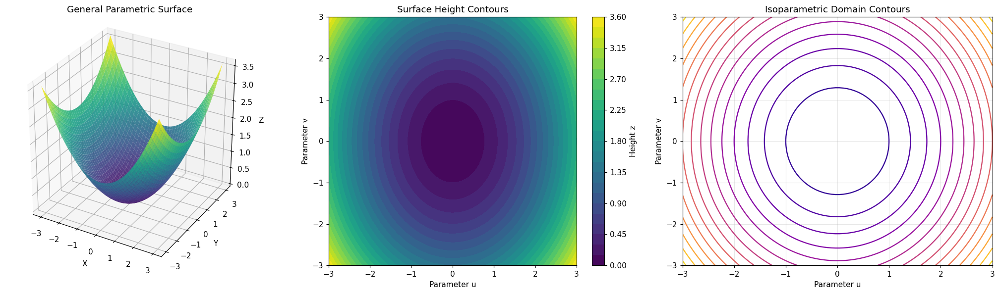

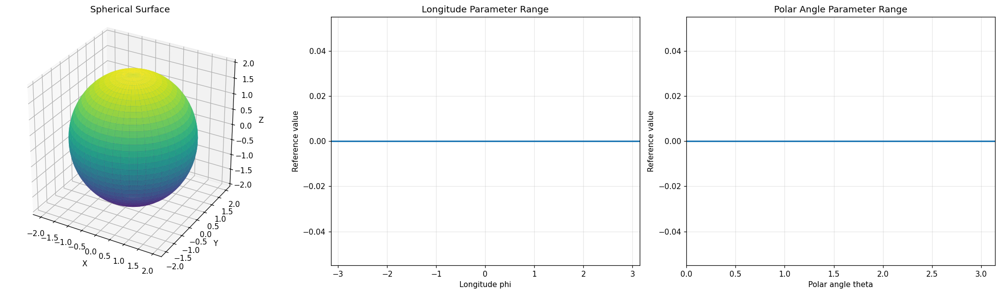

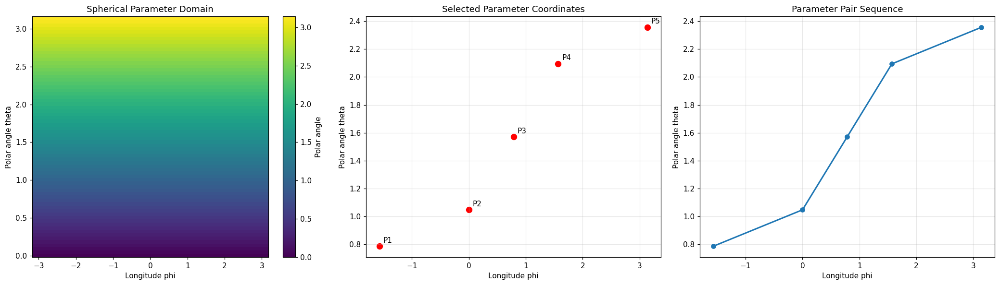

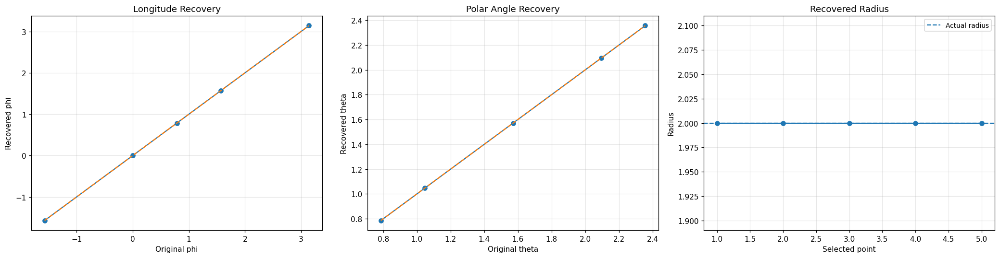

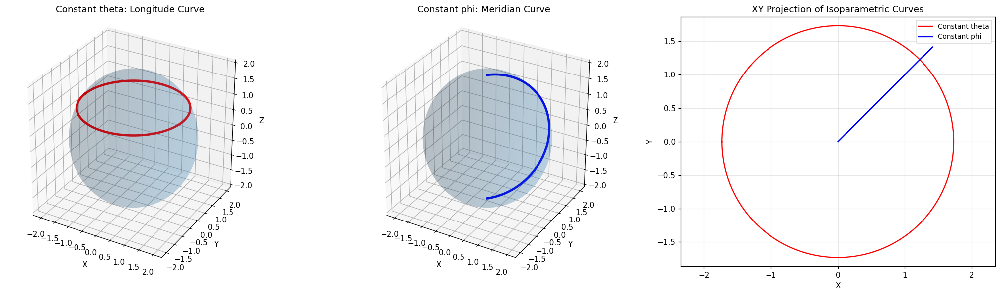

...

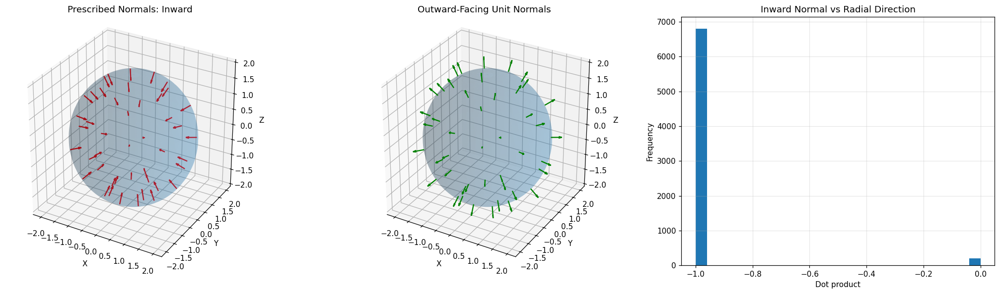

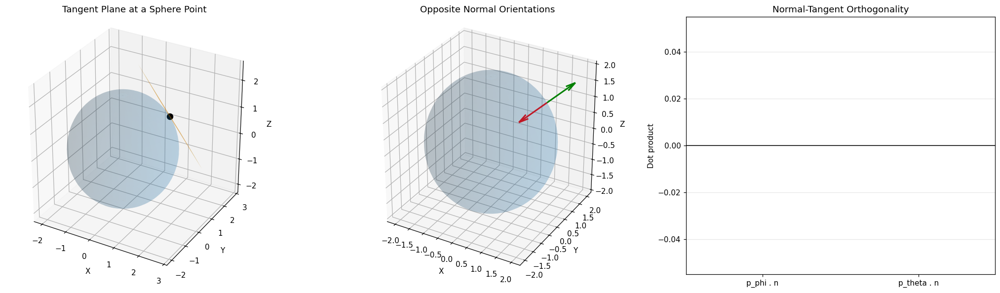

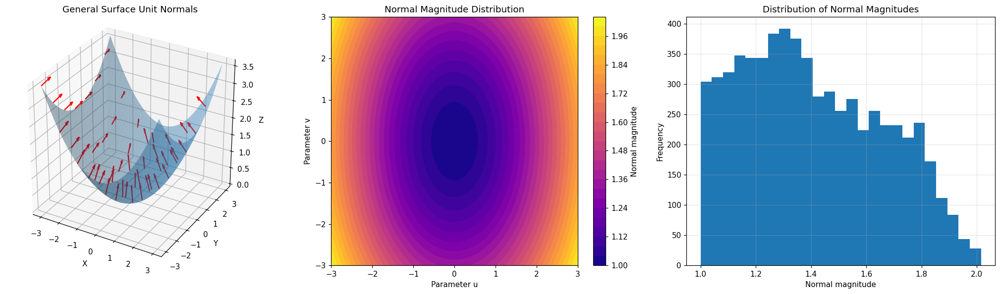

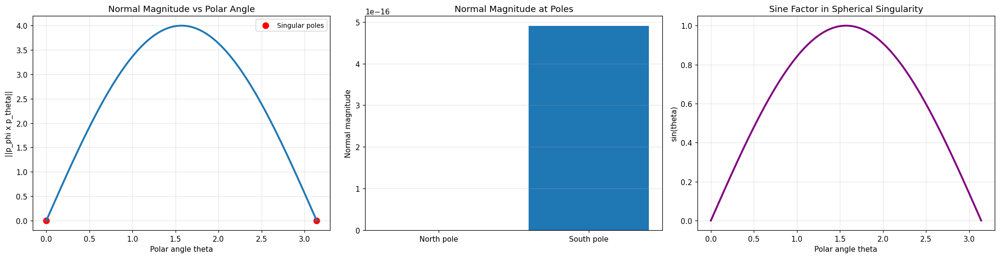

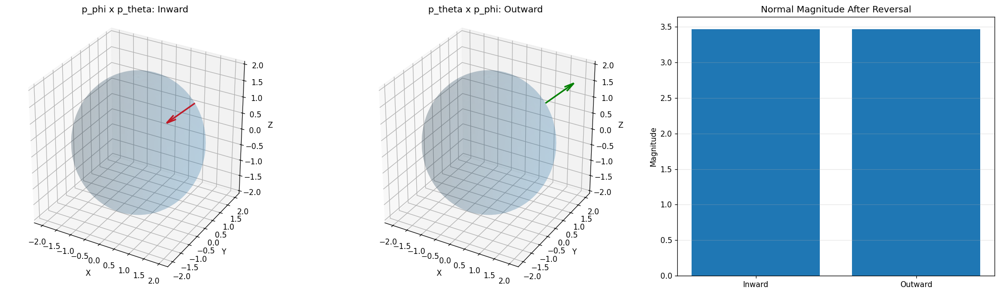

,Original phi,Original theta,X,Y,Z,Recovered radius,Recovered theta,Recovered phi
0,-1.570796,0.785398,8.659561e-17,-1.414214e+00,1.414214e+00,2.0,0.785398,-1.570796
1,0.000000,1.047198,1.732051e+00,0.000000e+00,1.000000e+00,2.0,1.047198,0.000000
2,0.785398,1.570796,1.414214e+00,1.414214e+00,1.224647e-16,2.0,1.570796,0.785398
3,1.570796,2.094395,1.060575e-16,1.732051e+00,-1.000000e+00,2.0,2.094395,1.570796
4,3.141593,2.356194,-1.414214e+00,1.731912e-16,-1.414214e+00,2.0,2.356194,3.141593


,Quantity,Value
0,p_phi x,-1.224745
1,p_phi y,1.224745
2,p_phi z,0.000000
3,p_theta x,0.707107
4,p_theta y,0.707107
5,p_theta z,-1.732051
6,Inward normal x,-2.121320
7,Inward normal y,-2.121320
8,Inward normal z,-1.732051
9,Outward normal x,2.121320


,Derivative,X,Y,Z
0,Analytical p_u,1.0,0.0,0.60
1,Numerical p_u,1.0,0.0,0.60
2,Analytical p_v,0.0,1.0,-0.24
3,Numerical p_v,0.0,1.0,-0.24


,Verification,Error or value
0,Maximum sphere equation residual,1.776357e-15
1,Maximum recovered radius error,2.220446e-16
2,Maximum recovered theta error,0.000000e+00
3,Maximum recovered phi error,0.000000e+00
4,Maximum analytical/numerical p_u error,6.551204e-12
5,Maximum analytical/numerical p_v error,4.551137e-12
6,Maximum unit normal magnitude error,2.220446e-16
7,Maximum normal-radial alignment error,2.220446e-16
8,Maximum tangent-normal dot product,0.000000e+00
9,North pole normal magnitude,0.000000e+00


In [43]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ==============================================================
# 1. CONFIGURATION
# ==============================================================

EPS = 1e-10

plt.rcParams.update({
    "figure.figsize": (19, 5.5),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})


def normalize(vector):
    vector = np.asarray(vector, dtype=float)
    length = np.linalg.norm(vector)

    if length < EPS:
        raise ValueError("Cannot normalize a zero-length vector.")

    return vector / length


def cross(a, b):
    return np.cross(a, b)


def set_3d_equal(ax, points=None):
    if points is None:
        ax.set_box_aspect([1, 1, 1])
        return

    points = np.asarray(points).reshape(3, -1)

    ranges = np.ptp(points, axis=1)
    max_range = max(np.max(ranges), EPS)

    centers = (
        np.max(points, axis=1) + np.min(points, axis=1)
    ) / 2

    ax.set_xlim(centers[0] - max_range / 2,
                centers[0] + max_range / 2)
    ax.set_ylim(centers[1] - max_range / 2,
                centers[1] + max_range / 2)
    ax.set_zlim(centers[2] - max_range / 2,
                centers[2] + max_range / 2)

    ax.set_box_aspect([1, 1, 1])


def setup_3d(ax, title):
    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_box_aspect([1, 1, 1])


# ==============================================================
# 2. GENERAL THREE-DIMENSIONAL PARAMETRIC SURFACE
# ==============================================================

# p(u,v) = [f(u,v), g(u,v), h(u,v)]
#
# x = u
# y = v
# z = 0.25u² + 0.15v²

def general_surface(u, v):
    return np.array([
        u,
        v,
        0.25*u**2 + 0.15*v**2
    ])


def general_surface_du(u, v):
    return np.array([
        np.ones_like(u),
        np.zeros_like(u),
        0.5*u
    ])


def general_surface_dv(u, v):
    return np.array([
        np.zeros_like(v),
        np.ones_like(v),
        0.3*v
    ])


u = np.linspace(-3, 3, 80)
v = np.linspace(-3, 3, 80)

U, V = np.meshgrid(u, v)

general_points = general_surface(U, V)

X_general = general_points[0]
Y_general = general_points[1]
Z_general = general_points[2]


# ==============================================================
# 3. SPHERICAL PARAMETRIC SURFACE
# ==============================================================

# x = r cos(phi) sin(theta)
# y = r sin(phi) sin(theta)
# z = r cos(theta)
#
# -pi < phi <= pi
# 0 <= theta <= pi

sphere_radius = 2.0

phi = np.linspace(-np.pi, np.pi, 100)
theta = np.linspace(0, np.pi, 70)

PHI, THETA = np.meshgrid(phi, theta)


def spherical_surface(phi, theta, radius):
    x = radius * np.cos(phi) * np.sin(theta)
    y = radius * np.sin(phi) * np.sin(theta)
    z = radius * np.cos(theta)

    return np.array([x, y, z])


sphere_points = spherical_surface(
    PHI, THETA, sphere_radius
)

X_sphere = sphere_points[0]
Y_sphere = sphere_points[1]
Z_sphere = sphere_points[2]


# ==============================================================
# 4. INVERSE SPHERICAL COORDINATES
# ==============================================================

# r = sqrt(x² + y² + z²)
# theta = arccos(z/r)
# phi = atan2(y,x)

def cartesian_to_spherical(point):
    x, y, z = np.asarray(point, dtype=float)

    radius = np.sqrt(x**2 + y**2 + z**2)

    if radius < EPS:
        raise ValueError(
            "Spherical coordinates are undefined at the origin."
        )

    theta_value = np.arccos(
        np.clip(z / radius, -1.0, 1.0)
    )

    phi_value = np.arctan2(y, x)

    return radius, theta_value, phi_value


selected_phi = np.array([
    -np.pi/2,
    0,
    np.pi/4,
    np.pi/2,
    np.pi
])

selected_theta = np.array([
    np.pi/4,
    np.pi/3,
    np.pi/2,
    2*np.pi/3,
    3*np.pi/4
])

selected_points = spherical_surface(
    selected_phi,
    selected_theta,
    sphere_radius
)

inverse_results = np.array([
    cartesian_to_spherical(selected_points[:, i])
    for i in range(len(selected_phi))
])


# ==============================================================
# 5. SPHERICAL PARTIAL DERIVATIVES
# ==============================================================

# p_phi =
# [-r sin(phi) sin(theta),
#   r cos(phi) sin(theta),
#   0]

def sphere_partial_phi(phi, theta, radius):
    return np.array([
        -radius * np.sin(phi) * np.sin(theta),
        radius * np.cos(phi) * np.sin(theta),
        np.zeros_like(phi)
    ])


# p_theta =
# [ r cos(phi) cos(theta),
#   r sin(phi) cos(theta),
#  -r sin(theta)]

def sphere_partial_theta(phi, theta, radius):
    return np.array([
        radius * np.cos(phi) * np.cos(theta),
        radius * np.sin(phi) * np.cos(theta),
        -radius * np.sin(theta)
    ])


P_phi = sphere_partial_phi(
    PHI, THETA, sphere_radius
)

P_theta = sphere_partial_theta(
    PHI, THETA, sphere_radius
)


# ==============================================================
# 6. SPHERICAL SURFACE NORMALS
# ==============================================================

# The prescribed normal:
# n = p_phi x p_theta
#
# For this parameterisation:
# p_phi x p_theta = -r sin(theta) p
#
# Therefore, this normal points inward.

sphere_normal = cross(
    np.moveaxis(P_phi, 0, -1),
    np.moveaxis(P_theta, 0, -1)
)

sphere_normal = np.moveaxis(
    sphere_normal, -1, 0
)

sphere_normal_magnitude = np.linalg.norm(
    sphere_normal,
    axis=0
)

sphere_unit_normal = (
    sphere_normal /
    np.maximum(sphere_normal_magnitude, EPS)
)

# Outward-facing normal is the negative of the prescribed normal.

sphere_outward_normal = -sphere_normal

sphere_outward_unit_normal = (
    -sphere_unit_normal
)

# Radial outward unit vector.

sphere_radial_unit = (
    sphere_points / sphere_radius
)

# Theoretical normal magnitude.

normal_magnitude_theoretical = (
    sphere_radius**2 * np.sin(THETA)
)


# ==============================================================
# 7. GENERAL SURFACE PARTIAL DERIVATIVES
# ==============================================================

general_du = general_surface_du(U, V)
general_dv = general_surface_dv(U, V)

# n = p_u x p_v

general_normal = cross(
    np.moveaxis(general_du, 0, -1),
    np.moveaxis(general_dv, 0, -1)
)

general_normal = np.moveaxis(
    general_normal, -1, 0
)

general_normal_magnitude = np.linalg.norm(
    general_normal,
    axis=0
)

general_unit_normal = (
    general_normal /
    np.maximum(general_normal_magnitude, EPS)
)


# ==============================================================
# 8. ISOPARAMETRIC CURVES
# ==============================================================

# Holding theta constant while phi varies.

fixed_theta = np.pi/3

phi_curve = np.linspace(
    -np.pi, np.pi, 300
)

constant_theta_curve = spherical_surface(
    phi_curve,
    np.full_like(phi_curve, fixed_theta),
    sphere_radius
)

# Holding phi constant while theta varies.

fixed_phi = np.pi/4

theta_curve = np.linspace(
    0, np.pi, 300
)

constant_phi_curve = spherical_surface(
    np.full_like(theta_curve, fixed_phi),
    theta_curve,
    sphere_radius
)


# ==============================================================
# 9. TANGENT PLANE AT A SPHERICAL SURFACE POINT
# ==============================================================

sample_phi = np.pi/4
sample_theta = np.pi/3

sample_point = spherical_surface(
    sample_phi,
    sample_theta,
    sphere_radius
).reshape(3)

sample_p_phi = sphere_partial_phi(
    sample_phi,
    sample_theta,
    sphere_radius
).reshape(3)

sample_p_theta = sphere_partial_theta(
    sample_phi,
    sample_theta,
    sphere_radius
).reshape(3)

sample_normal = cross(
    sample_p_phi,
    sample_p_theta
)

sample_unit_normal = normalize(sample_normal)

sample_outward_normal = -sample_normal

sample_outward_unit_normal = -sample_unit_normal

# Tangent plane:
# q = p + s*p_phi + t*p_theta

plane_s = np.linspace(-0.8, 0.8, 30)
plane_t = np.linspace(-0.8, 0.8, 30)

SS, TT = np.meshgrid(plane_s, plane_t)

tangent_plane_points = (
    sample_point[:, None, None]
    + sample_p_phi[:, None, None] * SS
    + sample_p_theta[:, None, None] * TT
)

X_tangent = tangent_plane_points[0]
Y_tangent = tangent_plane_points[1]
Z_tangent = tangent_plane_points[2]


# ==============================================================
# 10. SPHERICAL PARAMETERISATION SINGULARITIES
# ==============================================================

# ||p_phi x p_theta|| = r² sin(theta)
#
# At theta = 0 and theta = pi:
# the longitude parameter becomes undefined.

pole_theta = np.array([0.0, np.pi])
pole_phi = np.array([0.0, 1.0])

pole_p_phi = sphere_partial_phi(
    pole_phi,
    pole_theta,
    sphere_radius
)

pole_p_theta = sphere_partial_theta(
    pole_phi,
    pole_theta,
    sphere_radius
)

pole_normal = cross(
    np.moveaxis(pole_p_phi, 0, -1),
    np.moveaxis(pole_p_theta, 0, -1)
)

pole_normal_magnitude = np.linalg.norm(
    pole_normal,
    axis=1
)


# ==============================================================
# 11. NUMERICAL PARTIAL DERIVATIVE VERIFICATION
# ==============================================================

def numerical_partial_u(surface_function, u, v, h=1e-5):
    return (
        surface_function(u + h, v)
        - surface_function(u - h, v)
    ) / (2*h)


def numerical_partial_v(surface_function, u, v, h=1e-5):
    return (
        surface_function(u, v + h)
        - surface_function(u, v - h)
    ) / (2*h)


test_u = 1.2
test_v = -0.8

analytical_du = general_surface_du(
    np.array(test_u),
    np.array(test_v)
).reshape(3)

analytical_dv = general_surface_dv(
    np.array(test_u),
    np.array(test_v)
).reshape(3)

numerical_du = numerical_partial_u(
    general_surface, test_u, test_v
).reshape(3)

numerical_dv = numerical_partial_v(
    general_surface, test_u, test_v
).reshape(3)


# ==============================================================
# 12. VISUALISATION 1: GENERAL PARAMETRIC SURFACE
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_general, Y_general, Z_general,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

setup_3d(ax1, "General Parametric Surface")

ax2 = fig.add_subplot(1, 3, 2)

contour = ax2.contourf(
    U, V, Z_general,
    levels=25,
    cmap="viridis"
)

fig.colorbar(contour, ax=ax2, label="Height z")

ax2.set_title("Surface Height Contours")
ax2.set_xlabel("Parameter u")
ax2.set_ylabel("Parameter v")

ax3 = fig.add_subplot(1, 3, 3)

ax3.contour(
    U, V, Z_general,
    levels=15,
    cmap="plasma"
)

ax3.set_title("Isoparametric Domain Contours")
ax3.set_xlabel("Parameter u")
ax3.set_ylabel("Parameter v")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 13. VISUALISATION 2: SPHERICAL PARAMETRIC SURFACE
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

setup_3d(ax1, "Spherical Surface")

ax2 = fig.add_subplot(1, 3, 2)

ax2.plot(
    phi,
    np.zeros_like(phi),
    linewidth=2
)

ax2.set_title("Longitude Parameter Range")
ax2.set_xlabel("Longitude phi")
ax2.set_ylabel("Reference value")
ax2.set_xlim(-np.pi, np.pi)
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(
    theta,
    np.zeros_like(theta),
    linewidth=2
)

ax3.set_title("Polar Angle Parameter Range")
ax3.set_xlabel("Polar angle theta")
ax3.set_ylabel("Reference value")
ax3.set_xlim(0, np.pi)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 14. VISUALISATION 3: SPHERICAL PARAMETER DOMAIN
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1)

domain = ax1.pcolormesh(
    PHI, THETA, THETA,
    shading="auto",
    cmap="viridis"
)

fig.colorbar(domain, ax=ax1, label="Polar angle")

ax1.set_title("Spherical Parameter Domain")
ax1.set_xlabel("Longitude phi")
ax1.set_ylabel("Polar angle theta")

ax2 = fig.add_subplot(1, 3, 2)

ax2.scatter(
    selected_phi,
    selected_theta,
    color="red",
    s=60
)

for i in range(len(selected_phi)):
    ax2.annotate(
        f"P{i+1}",
        (selected_phi[i], selected_theta[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax2.set_title("Selected Parameter Coordinates")
ax2.set_xlabel("Longitude phi")
ax2.set_ylabel("Polar angle theta")
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(
    selected_phi,
    selected_theta,
    marker="o",
    linewidth=2
)

ax3.set_title("Parameter Pair Sequence")
ax3.set_xlabel("Longitude phi")
ax3.set_ylabel("Polar angle theta")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 15. VISUALISATION 4: INVERSE SPHERICAL COORDINATES
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    selected_phi,
    inverse_results[:, 2],
    marker="o"
)

axes[0].plot(
    selected_phi,
    selected_phi,
    linestyle="--"
)

axes[0].set_title("Longitude Recovery")
axes[0].set_xlabel("Original phi")
axes[0].set_ylabel("Recovered phi")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    selected_theta,
    inverse_results[:, 1],
    marker="o"
)

axes[1].plot(
    selected_theta,
    selected_theta,
    linestyle="--"
)

axes[1].set_title("Polar Angle Recovery")
axes[1].set_xlabel("Original theta")
axes[1].set_ylabel("Recovered theta")
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    np.arange(1, 6),
    inverse_results[:, 0],
    marker="o"
)

axes[2].axhline(
    sphere_radius,
    linestyle="--",
    label="Actual radius"
)

axes[2].set_title("Recovered Radius")
axes[2].set_xlabel("Selected point")
axes[2].set_ylabel("Radius")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 16. VISUALISATION 5: ISOPARAMETRIC CURVES
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax1.plot(
    constant_theta_curve[0],
    constant_theta_curve[1],
    constant_theta_curve[2],
    color="red",
    linewidth=3
)

setup_3d(ax1, "Constant theta: Longitude Curve")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")

ax2.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax2.plot(
    constant_phi_curve[0],
    constant_phi_curve[1],
    constant_phi_curve[2],
    color="blue",
    linewidth=3
)

setup_3d(ax2, "Constant phi: Meridian Curve")

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(
    constant_theta_curve[0],
    constant_theta_curve[1],
    color="red",
    label="Constant theta"
)

ax3.plot(
    constant_phi_curve[0],
    constant_phi_curve[1],
    color="blue",
    label="Constant phi"
)

ax3.set_title("XY Projection of Isoparametric Curves")
ax3.set_xlabel("X")
ax3.set_ylabel("Y")
ax3.axis("equal")
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 17. VISUALISATION 6: TANGENT VECTORS
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax1.quiver(
    *sample_point,
    *sample_p_phi,
    length=0.8,
    normalize=True,
    color="red",
    linewidth=2
)

setup_3d(ax1, "Tangent Vector p_phi")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")

ax2.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax2.quiver(
    *sample_point,
    *sample_p_theta,
    length=0.8,
    normalize=True,
    color="blue",
    linewidth=2
)

setup_3d(ax2, "Tangent Vector p_theta")

ax3 = fig.add_subplot(1, 3, 3)

ax3.bar(
    ["||p_phi||", "||p_theta||"],
    [
        np.linalg.norm(sample_p_phi),
        np.linalg.norm(sample_p_theta)
    ]
)

ax3.set_title("Tangent Vector Magnitudes")
ax3.set_ylabel("Magnitude")
ax3.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 18. VISUALISATION 7: SURFACE NORMALS
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.2,
    edgecolor="none"
)

ax1.quiver(
    X_sphere[::12, ::12],
    Y_sphere[::12, ::12],
    Z_sphere[::12, ::12],
    sphere_unit_normal[0, ::12, ::12],
    sphere_unit_normal[1, ::12, ::12],
    sphere_unit_normal[2, ::12, ::12],
    length=0.35,
    normalize=True,
    color="red"
)

setup_3d(ax1, "Prescribed Normals: Inward")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")

ax2.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.2,
    edgecolor="none"
)

ax2.quiver(
    X_sphere[::12, ::12],
    Y_sphere[::12, ::12],
    Z_sphere[::12, ::12],
    sphere_outward_unit_normal[0, ::12, ::12],
    sphere_outward_unit_normal[1, ::12, ::12],
    sphere_outward_unit_normal[2, ::12, ::12],
    length=0.35,
    normalize=True,
    color="green"
)

setup_3d(ax2, "Outward-Facing Unit Normals")

ax3 = fig.add_subplot(1, 3, 3)

normal_alignment = np.sum(
    sphere_unit_normal * sphere_radial_unit,
    axis=0
)

ax3.hist(
    normal_alignment.flatten(),
    bins=25
)

ax3.set_title("Inward Normal vs Radial Direction")
ax3.set_xlabel("Dot product")
ax3.set_ylabel("Frequency")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 19. VISUALISATION 8: TANGENT PLANE AND NORMAL
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax1.plot_surface(
    X_tangent, Y_tangent, Z_tangent,
    color="orange",
    alpha=0.65
)

ax1.scatter(
    *sample_point,
    color="black",
    s=60
)

setup_3d(ax1, "Tangent Plane at a Sphere Point")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")

ax2.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax2.quiver(
    *sample_point,
    *sample_unit_normal,
    length=1.0,
    color="red",
    linewidth=2
)

ax2.quiver(
    *sample_point,
    *sample_outward_unit_normal,
    length=1.0,
    color="green",
    linewidth=2
)

setup_3d(ax2, "Opposite Normal Orientations")

ax3 = fig.add_subplot(1, 3, 3)

orthogonality_values = [
    np.dot(sample_p_phi, sample_unit_normal),
    np.dot(sample_p_theta, sample_unit_normal)
]

ax3.bar(
    ["p_phi . n", "p_theta . n"],
    orthogonality_values
)

ax3.axhline(0, color="black", linewidth=1)

ax3.set_title("Normal-Tangent Orthogonality")
ax3.set_ylabel("Dot product")
ax3.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 20. VISUALISATION 9: GENERAL SURFACE NORMALS
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_general, Y_general, Z_general,
    alpha=0.4,
    edgecolor="none"
)

ax1.quiver(
    X_general[::12, ::12],
    Y_general[::12, ::12],
    Z_general[::12, ::12],
    general_unit_normal[0, ::12, ::12],
    general_unit_normal[1, ::12, ::12],
    general_unit_normal[2, ::12, ::12],
    length=0.5,
    normalize=True,
    color="red"
)

setup_3d(ax1, "General Surface Unit Normals")

ax2 = fig.add_subplot(1, 3, 2)

normal_contour = ax2.contourf(
    U, V, general_normal_magnitude,
    levels=25,
    cmap="plasma"
)

fig.colorbar(
    normal_contour,
    ax=ax2,
    label="Normal magnitude"
)

ax2.set_title("Normal Magnitude Distribution")
ax2.set_xlabel("Parameter u")
ax2.set_ylabel("Parameter v")

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot_surface if False else None

ax3.hist(
    general_normal_magnitude.flatten(),
    bins=25
)

ax3.set_title("Distribution of Normal Magnitudes")
ax3.set_xlabel("Normal magnitude")
ax3.set_ylabel("Frequency")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 21. VISUALISATION 10: PARAMETERISATION SINGULARITIES
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

theta_values = np.linspace(0, np.pi, 500)

axes[0].plot(
    theta_values,
    sphere_radius**2 * np.sin(theta_values),
    linewidth=2.5
)

axes[0].scatter(
    [0, np.pi],
    [0, 0],
    color="red",
    s=65,
    label="Singular poles"
)

axes[0].set_title("Normal Magnitude vs Polar Angle")
axes[0].set_xlabel("Polar angle theta")
axes[0].set_ylabel("||p_phi x p_theta||")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar(
    ["North pole", "South pole"],
    pole_normal_magnitude
)

axes[1].set_title("Normal Magnitude at Poles")
axes[1].set_ylabel("Normal magnitude")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].plot(
    theta_values,
    np.sin(theta_values),
    color="purple",
    linewidth=2.5
)

axes[2].set_title("Sine Factor in Spherical Singularity")
axes[2].set_xlabel("Polar angle theta")
axes[2].set_ylabel("sin(theta)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 22. VISUALISATION 11: NORMAL REVERSAL
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax1.quiver(
    *sample_point,
    *sample_unit_normal,
    length=1,
    color="red",
    linewidth=2
)

setup_3d(ax1, "p_phi x p_theta: Inward")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")

ax2.plot_surface(
    X_sphere, Y_sphere, Z_sphere,
    alpha=0.15,
    edgecolor="none"
)

ax2.quiver(
    *sample_point,
    *sample_outward_unit_normal,
    length=1,
    color="green",
    linewidth=2
)

setup_3d(ax2, "p_theta x p_phi: Outward")

ax3 = fig.add_subplot(1, 3, 3)

ax3.bar(
    ["Inward", "Outward"],
    [
        np.linalg.norm(sample_normal),
        np.linalg.norm(-sample_normal)
    ]
)

ax3.set_title("Normal Magnitude After Reversal")
ax3.set_ylabel("Magnitude")
ax3.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 23. NUMERICAL TABLES
# ==============================================================

spherical_table = pd.DataFrame({
    "Original phi": selected_phi,
    "Original theta": selected_theta,
    "X": selected_points[0],
    "Y": selected_points[1],
    "Z": selected_points[2],
    "Recovered radius": inverse_results[:, 0],
    "Recovered theta": inverse_results[:, 1],
    "Recovered phi": inverse_results[:, 2]
})

tangent_table = pd.DataFrame({
    "Quantity": [
        "p_phi x",
        "p_phi y",
        "p_phi z",
        "p_theta x",
        "p_theta y",
        "p_theta z",
        "Inward normal x",
        "Inward normal y",
        "Inward normal z",
        "Outward normal x",
        "Outward normal y",
        "Outward normal z",
        "Inward unit normal magnitude",
        "Outward unit normal magnitude",
        "p_phi dot n",
        "p_theta dot n"
    ],
    "Value": [
        sample_p_phi[0],
        sample_p_phi[1],
        sample_p_phi[2],
        sample_p_theta[0],
        sample_p_theta[1],
        sample_p_theta[2],
        sample_normal[0],
        sample_normal[1],
        sample_normal[2],
        sample_outward_normal[0],
        sample_outward_normal[1],
        sample_outward_normal[2],
        np.linalg.norm(sample_unit_normal),
        np.linalg.norm(sample_outward_unit_normal),
        np.dot(sample_p_phi, sample_unit_normal),
        np.dot(sample_p_theta, sample_unit_normal)
    ]
})

derivative_table = pd.DataFrame({
    "Derivative": [
        "Analytical p_u",
        "Numerical p_u",
        "Analytical p_v",
        "Numerical p_v"
    ],
    "X": [
        analytical_du[0],
        numerical_du[0],
        analytical_dv[0],
        numerical_dv[0]
    ],
    "Y": [
        analytical_du[1],
        numerical_du[1],
        analytical_dv[1],
        numerical_dv[1]
    ],
    "Z": [
        analytical_du[2],
        numerical_du[2],
        analytical_dv[2],
        numerical_dv[2]
    ]
})

verification_table = pd.DataFrame({
    "Verification": [
        "Maximum sphere equation residual",
        "Maximum recovered radius error",
        "Maximum recovered theta error",
        "Maximum recovered phi error",
        "Maximum analytical/numerical p_u error",
        "Maximum analytical/numerical p_v error",
        "Maximum unit normal magnitude error",
        "Maximum normal-radial alignment error",
        "Maximum tangent-normal dot product",
        "North pole normal magnitude",
        "South pole normal magnitude"
    ],
    "Error or value": [
        np.max(np.abs(
            X_sphere**2 + Y_sphere**2 + Z_sphere**2
            - sphere_radius**2
        )),
        np.max(np.abs(
            inverse_results[:, 0] - sphere_radius
        )),
        np.max(np.abs(
            inverse_results[:, 1] - selected_theta
        )),
        np.max(np.abs(
            inverse_results[:, 2] - selected_phi
        )),
        np.max(np.abs(
            analytical_du - numerical_du
        )),
        np.max(np.abs(
            analytical_dv - numerical_dv
        )),
        np.max(np.abs(
            np.linalg.norm(
                sphere_unit_normal[:, 1:-1, :],
                axis=0
            ) - 1
        )),
        np.max(np.abs(
            sphere_unit_normal[:, 1:-1, :]
            + sphere_radial_unit[:, 1:-1, :]
        )),
        max(
            abs(np.dot(sample_p_phi, sample_normal)),
            abs(np.dot(sample_p_theta, sample_normal))
        ),
        pole_normal_magnitude[0],
        pole_normal_magnitude[1]
    ]
})

display(spherical_table)
display(tangent_table)
display(derivative_table)
display(verification_table)


# ==============================================================
# 24. MATHEMATICAL VERIFICATION AND ASSERTIONS
# ==============================================================

# 1. All spherical surface points satisfy the sphere equation.

sphere_residual = (
    X_sphere**2
    + Y_sphere**2
    + Z_sphere**2
    - sphere_radius**2
)

assert np.allclose(
    sphere_residual,
    0,
    atol=1e-10
)


# 2. Inverse spherical coordinates recover the radius.

assert np.allclose(
    inverse_results[:, 0],
    sphere_radius,
    atol=1e-10
)


# 3. Inverse spherical coordinates recover polar angles.

assert np.allclose(
    inverse_results[:, 1],
    selected_theta,
    atol=1e-10
)


# 4. Inverse spherical coordinates recover longitude.

assert np.allclose(
    inverse_results[:, 2],
    selected_phi,
    atol=1e-10
)


# 5. Analytical and numerical partial derivatives agree.

assert np.allclose(
    analytical_du,
    numerical_du,
    atol=1e-8
)

assert np.allclose(
    analytical_dv,
    numerical_dv,
    atol=1e-8
)


# 6. Theoretical and calculated spherical normal magnitudes agree.

assert np.allclose(
    sphere_normal_magnitude,
    normal_magnitude_theoretical,
    atol=1e-10
)


# 7. The prescribed normal p_phi x p_theta points inward.
# It must be the negative of the radial unit direction.

assert np.allclose(
    sphere_unit_normal[:, 1:-1, :],
    -sphere_radial_unit[:, 1:-1, :],
    atol=1e-10
)


# 8. The reversed normal points outward.

assert np.allclose(
    sphere_outward_unit_normal[:, 1:-1, :],
    sphere_radial_unit[:, 1:-1, :],
    atol=1e-10
)


# 9. Unit normals have unit magnitude away from the poles.

assert np.allclose(
    np.linalg.norm(
        sphere_unit_normal[:, 1:-1, :],
        axis=0
    ),
    1,
    atol=1e-10
)


# 10. The normal is perpendicular to both tangent vectors.

assert np.isclose(
    np.dot(sample_p_phi, sample_normal),
    0,
    atol=1e-10
)

assert np.isclose(
    np.dot(sample_p_theta, sample_normal),
    0,
    atol=1e-10
)


# 11. Reversing cross-product order reverses the normal.

assert np.allclose(
    cross(sample_p_theta, sample_p_phi),
    -sample_normal,
    atol=1e-10
)


# 12. The spherical normal vanishes at both parameter poles.

assert np.allclose(
    pole_normal_magnitude,
    0,
    atol=1e-10
)


# 13. The selected general surface has nonzero normals.

assert np.all(
    general_normal_magnitude > EPS
)


### 2.5.9 Summary of Curves and Surfaces

Curves and surfaces are mathematically represented using **implicit** and **parametric** formulations.

**Implicit representation** defines geometry through a scalar-valued function:

$$
f:\mathbb R^n\rightarrow\mathbb R,\qquad
S=\{\mathbf p\mid f(\mathbf p)=0\}
$$

Here, $f$ maps an $n$-dimensional position vector $\mathbf p$ to a scalar; its zero-level set defines the geometric boundary. The gradient $\nabla f$ provides a normal perpendicular to the tangent direction or plane.

**Parametric representation** describes geometry using vector-valued functions. A curve depends on one parameter:

$$
\mathbf p:D\subseteq\mathbb R\rightarrow\mathbb R^2
\text{ or }\mathbb R^3
$$

Its derivative $\mathbf p'(t)$ gives the tangent vector. A surface depends on two parameters:

$$
\mathbf p:D\subseteq\mathbb R^2\rightarrow\mathbb R^3
$$

Its partial derivatives, $\mathbf p_u$ and $\mathbf p_v$, define tangent directions. Their cross product produces the normal:

$$
\mathbf n=\mathbf p_u\times\mathbf p_v
$$

Therefore, implicit geometry obtains normals through gradients, while parametric geometry derives them from tangent vectors. Both approaches underpin modelling, rendering, animation and computational geometry.

### 2.6 Linear Interpolation

**Linear interpolation** estimates intermediate values between two known endpoints, assuming a constant rate of change. In computer graphics, it generates geometric positions, colours and animation transitions.

Given points $A$ and $B$, interpolation is:

$$
\boxed{P(t)=(1-t)A+tB,\quad 0\leq t\leq1}
$$

Here, $t$ is the dimensionless interpolation parameter. At $t=0$, $P=A$; at $t=1$, $P=B$; and at $t=0.5$, $P$ is the midpoint. The weights $1-t$ and $t$ sum to unity.

**Linear Interpolation of Data**

For data points $(x_i,y_i)$ and $(x_{i+1},y_{i+1})$, the interpolated function is:

$$
f(x)=y_i+\frac{x-x_i}{x_{i+1}-x_i}(y_{i+1}-y_i)\tag{2.26}
$$

where $x_i\leq x\leq x_{i+1}$ and $x_i\neq x_{i+1}$.

The interpolation parameter is:

$$
t=\frac{x-x_i}{x_{i+1}-x_i}
$$

**Example:** For $(2,4)$ and $(6,12)$, estimate the value at $x=4$:

$$
t=\frac{4-2}{6-2}=0.5
$$

$$
f(4)=4+0.5(12-4)=8
$$

Thus, the estimated value is $8$. Linear interpolation creates continuous, piecewise-linear segments but assumes constant interval slopes and may produce derivative discontinuities at joining points.

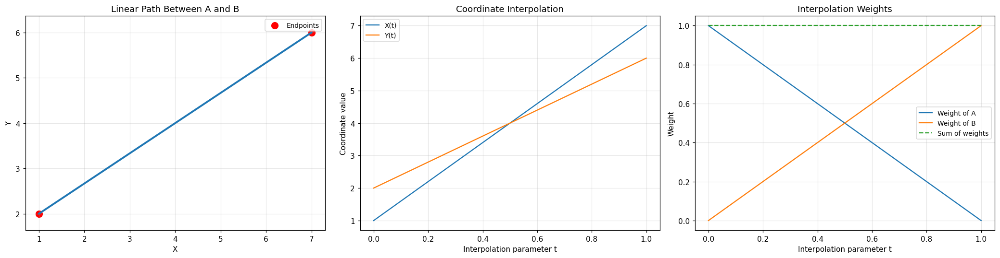

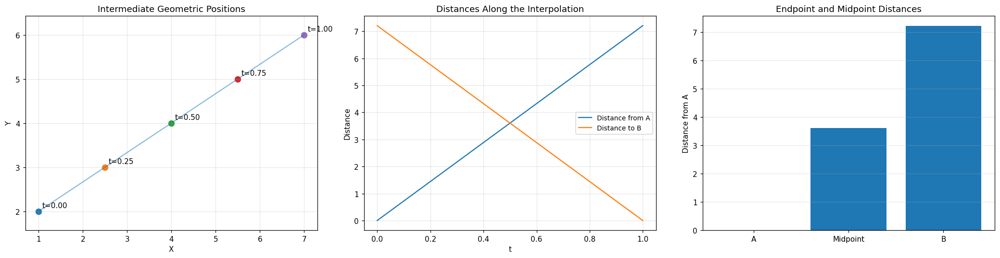

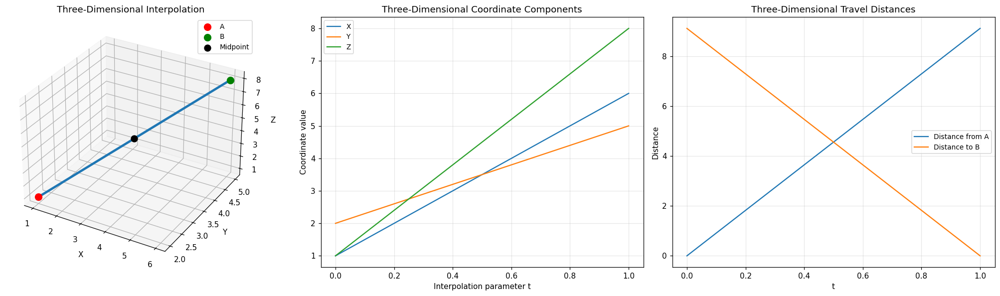

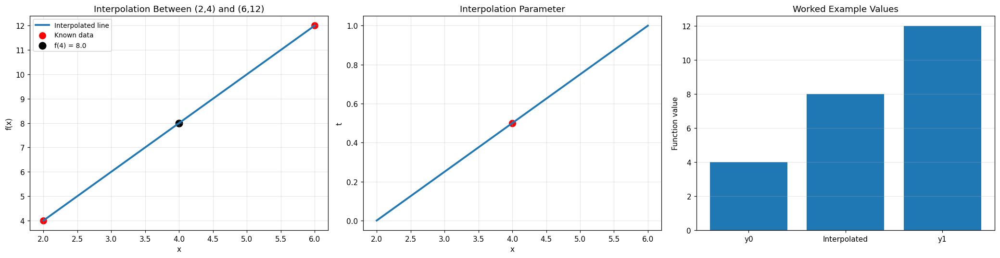

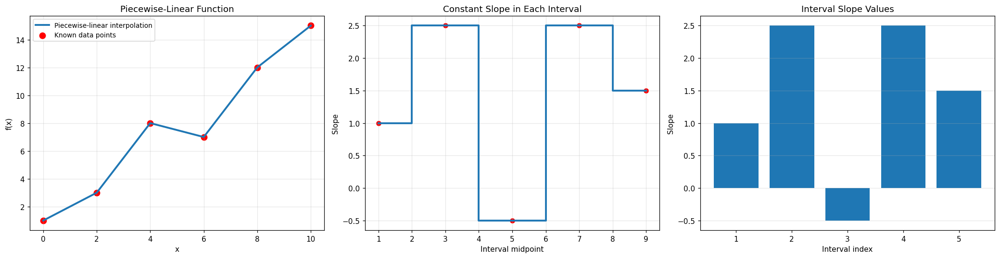

...

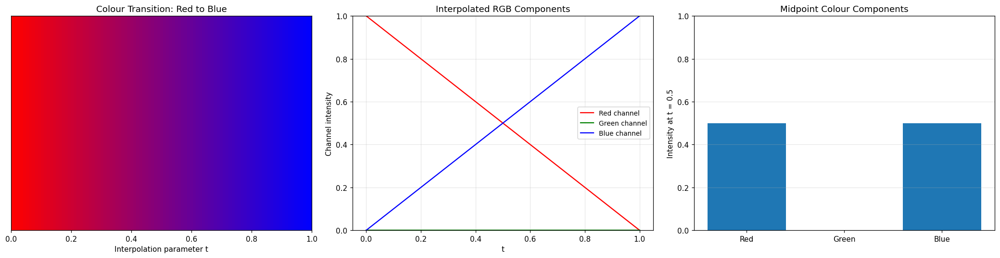

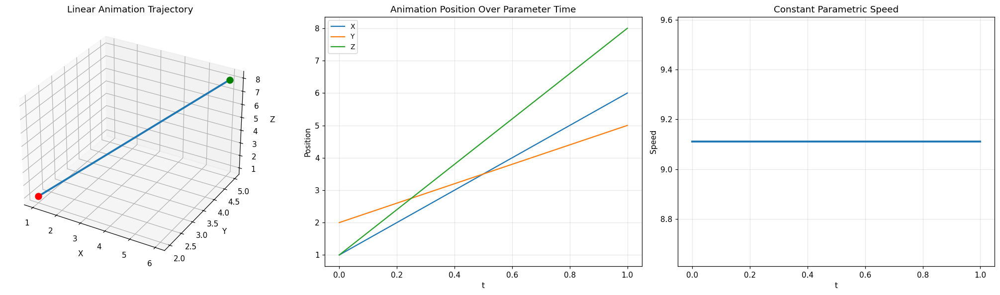

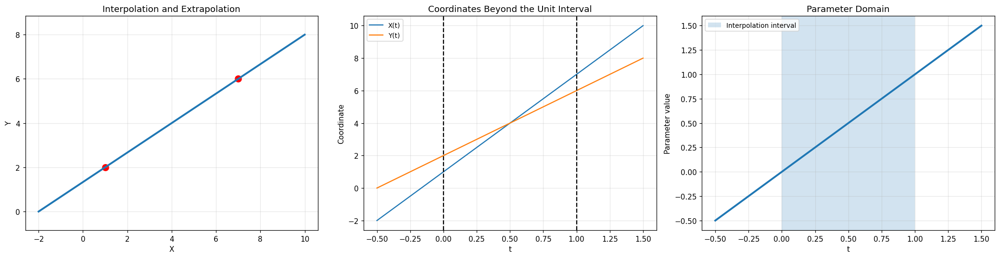

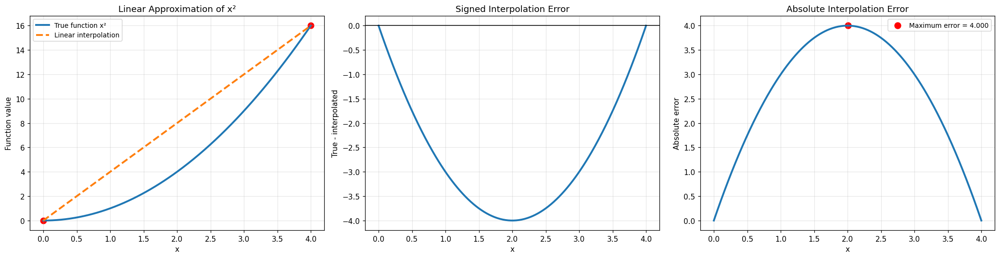

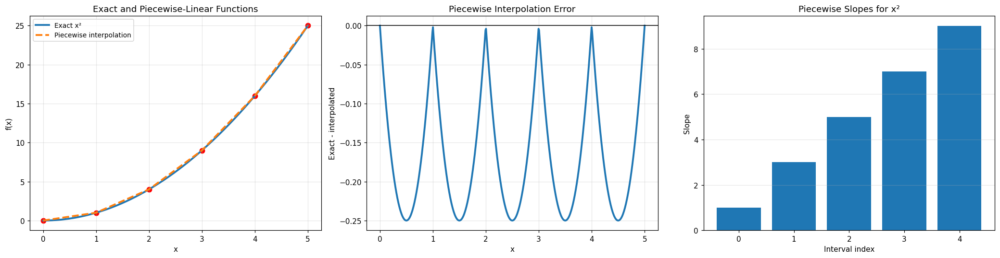

,t,X,Y
0,0.00,1.0,2.0
1,0.25,2.5,3.0
2,0.50,4.0,4.0
3,0.75,5.5,5.0
4,1.00,7.0,6.0


,t,X,Y,Z
0,0.00,1.00,2.00,1.00
1,0.25,2.25,2.75,2.75
2,0.50,3.50,3.50,4.50
3,0.75,4.75,4.25,6.25
4,1.00,6.00,5.00,8.00


,Quantity,Value
0,Initial x,2.0
1,Initial y,4.0
2,Final x,6.0
3,Final y,12.0
4,Target x,4.0
5,Interpolation parameter,0.5
6,Interpolated value,8.0


,Interval start,Interval end,Initial value,Final value,Slope
0,0.0,2.0,1.0,3.0,1.0
1,2.0,4.0,3.0,8.0,2.5
2,4.0,6.0,8.0,7.0,-0.5
3,6.0,8.0,7.0,12.0,2.5
4,8.0,10.0,12.0,15.0,1.5


,Joining point,Left slope,Right slope,Slope change,Derivative continuous
0,2.0,1.0,2.5,1.5,False
1,4.0,2.5,-0.5,-3.0,False
2,6.0,-0.5,2.5,3.0,False
3,8.0,2.5,1.5,-1.0,False


,Quantity,Value
0,"Maximum error for x² on [0,4]",3.999955
1,Location of maximum error,2.006689
2,"Maximum piecewise error for x² on [0,5]",0.249999


/tmp/ipykernel_494/1933619355.py:1362: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  np.cross(direction, point-A)


In [44]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ==============================================================
# 1. CONFIGURATION
# ==============================================================

EPS = 1e-12

plt.rcParams.update({
    "figure.figsize": (19, 5.5),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})


# ==============================================================
# 2. LINEAR INTERPOLATION OF GEOMETRIC POINTS
# ==============================================================

# P(t) = (1-t)A + tB
# 0 <= t <= 1

def lerp(A, B, t):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    return (1-t)*A + t*B


A = np.array([1.0, 2.0])
B = np.array([7.0, 6.0])

t_values = np.linspace(0, 1, 101)

interpolated_points = np.array([
    lerp(A, B, t)
    for t in t_values
])

midpoint = lerp(A, B, 0.5)

# Endpoint and midpoint verification
P_start = lerp(A, B, 0)
P_middle = lerp(A, B, 0.5)
P_end = lerp(A, B, 1)


# ==============================================================
# 3. THREE-DIMENSIONAL GEOMETRIC INTERPOLATION
# ==============================================================

A3 = np.array([1.0, 2.0, 1.0])
B3 = np.array([6.0, 5.0, 8.0])

interpolated_points_3d = np.array([
    lerp(A3, B3, t)
    for t in t_values
])

midpoint_3d = lerp(A3, B3, 0.5)


# ==============================================================
# 4. INTERPOLATION WEIGHTS
# ==============================================================

weight_A = 1 - t_values
weight_B = t_values

weight_sum = weight_A + weight_B


# ==============================================================
# 5. LINEAR INTERPOLATION OF SCALAR DATA
# ==============================================================

# f(x) = yi + t(yi+1 - yi)
#
# t = (x - xi)/(xi+1 - xi)

def linear_interpolation(x0, y0, x1, y1, x):
    if np.isclose(x1, x0):
        raise ValueError(
            "The x-coordinates must be different."
        )

    t = (x - x0) / (x1 - x0)

    return y0 + t*(y1-y0)


# Supplied example:
# Points (2,4) and (6,12)
# Estimate f(4).

x0 = 2.0
y0 = 4.0
x1 = 6.0
y1 = 12.0
x_target = 4.0

example_t = (
    (x_target-x0)/(x1-x0)
)

example_value = linear_interpolation(
    x0, y0, x1, y1, x_target
)


# ==============================================================
# 6. INTERPOLATION ACROSS A CONTINUOUS DATA INTERVAL
# ==============================================================

x_interval = np.linspace(x0, x1, 200)

y_interval = linear_interpolation(
    x0, y0, x1, y1, x_interval
)

interval_t = (
    (x_interval-x0)/(x1-x0)
)


# ==============================================================
# 7. PIECEWISE-LINEAR INTERPOLATION
# ==============================================================

# Given multiple data points, interpolate within
# the interval containing each query.

data_x = np.array([0, 2, 4, 6, 8, 10], dtype=float)
data_y = np.array([1, 3, 8, 7, 12, 15], dtype=float)


def piecewise_linear_interpolation(x_data, y_data, x_query):
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    x_query = np.asarray(x_query, dtype=float)

    if len(x_data) != len(y_data):
        raise ValueError(
            "The x and y data arrays must have equal lengths."
        )

    if len(x_data) < 2:
        raise ValueError(
            "At least two data points are required."
        )

    if np.any(np.diff(x_data) <= 0):
        raise ValueError(
            "The x data must be strictly increasing."
        )

    if np.any(x_query < x_data[0]) or np.any(x_query > x_data[-1]):
        raise ValueError(
            "Query points must lie inside the interpolation domain."
        )

    return np.interp(
        x_query,
        x_data,
        y_data
    )


x_dense = np.linspace(
    data_x[0],
    data_x[-1],
    500
)

y_dense = piecewise_linear_interpolation(
    data_x,
    data_y,
    x_dense
)


# ==============================================================
# 8. PIECEWISE SLOPES
# ==============================================================

# m_i = (y_i+1 - y_i)/(x_i+1 - x_i)

interval_slopes = (
    np.diff(data_y) / np.diff(data_x)
)

slope_midpoints = (
    data_x[:-1] + data_x[1:]
) / 2


# ==============================================================
# 9. DERIVATIVE DISCONTINUITIES AT JOINING POINTS
# ==============================================================

# Linear interpolation has a constant slope inside each interval.
# At a joining point, the left and right slopes may differ.

left_slopes = interval_slopes[:-1]
right_slopes = interval_slopes[1:]

slope_jumps = right_slopes - left_slopes

join_points = data_x[1:-1]

derivative_continuity = np.isclose(
    left_slopes,
    right_slopes
)


# ==============================================================
# 10. LINEAR INTERPOLATION OF COLOUR
# ==============================================================

# RGB values are represented in [0,1].

colour_A = np.array([1.0, 0.0, 0.0])
colour_B = np.array([0.0, 0.0, 1.0])

colour_values = np.array([
    lerp(colour_A, colour_B, t)
    for t in t_values
])


# ==============================================================
# 11. ANIMATION POSITION INTERPOLATION
# ==============================================================

# A moving object follows a linear trajectory from A to B.

animation_t = np.linspace(0, 1, 101)

animation_positions = np.array([
    lerp(A3, B3, t)
    for t in animation_t
])

# Constant velocity with respect to t:
animation_velocity = B3 - A3

animation_speed = np.linalg.norm(
    animation_velocity
)


# ==============================================================
# 12. INTERPOLATION OUTSIDE THE UNIT INTERVAL
# ==============================================================

# Extrapolation occurs when t < 0 or t > 1.
# It is mathematically valid but is not interpolation
# within the segment.

extended_t = np.linspace(-0.5, 1.5, 200)

extended_points = np.array([
    lerp(A, B, t)
    for t in extended_t
])


# ==============================================================
# 13. LINEAR INTERPOLATION ERROR
# ==============================================================

# Compare linear interpolation against a nonlinear function.
#
# f(x) = x²
#
# Interpolation is exact at interval endpoints but
# generally differs inside the interval.

def nonlinear_function(x):
    return x**2


curve_x0 = 0.0
curve_x1 = 4.0

curve_y0 = nonlinear_function(curve_x0)
curve_y1 = nonlinear_function(curve_x1)

curve_x = np.linspace(
    curve_x0,
    curve_x1,
    300
)

true_curve = nonlinear_function(curve_x)

linear_approximation = linear_interpolation(
    curve_x0,
    curve_y0,
    curve_x1,
    curve_y1,
    curve_x
)

interpolation_error = (
    true_curve - linear_approximation
)

absolute_error = np.abs(interpolation_error)

maximum_error = np.max(absolute_error)

maximum_error_x = curve_x[
    np.argmax(absolute_error)
]


# ==============================================================
# 14. LINEAR INTERPOLATION OF A NONLINEAR FUNCTION
# ==============================================================

# Demonstrate interpolation over several intervals.

nonlinear_x = np.array([
    0, 1, 2, 3, 4, 5
], dtype=float)

nonlinear_y = nonlinear_function(
    nonlinear_x
)

nonlinear_query = np.linspace(
    0, 5, 500
)

nonlinear_linear = piecewise_linear_interpolation(
    nonlinear_x,
    nonlinear_y,
    nonlinear_query
)

nonlinear_exact = nonlinear_function(
    nonlinear_query
)

nonlinear_error = (
    nonlinear_exact - nonlinear_linear
)


# ==============================================================
# 15. VISUALISATION 1: TWO-DIMENSIONAL GEOMETRIC INTERPOLATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    interpolated_points[:, 0],
    interpolated_points[:, 1],
    linewidth=2.5
)

axes[0].scatter(
    [A[0], B[0]],
    [A[1], B[1]],
    color="red",
    s=80,
    label="Endpoints"
)

axes[0].set_title("Linear Path Between A and B")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    t_values,
    interpolated_points[:, 0],
    label="X(t)"
)

axes[1].plot(
    t_values,
    interpolated_points[:, 1],
    label="Y(t)"
)

axes[1].set_title("Coordinate Interpolation")
axes[1].set_xlabel("Interpolation parameter t")
axes[1].set_ylabel("Coordinate value")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(
    t_values,
    weight_A,
    label="Weight of A"
)

axes[2].plot(
    t_values,
    weight_B,
    label="Weight of B"
)

axes[2].plot(
    t_values,
    weight_sum,
    linestyle="--",
    label="Sum of weights"
)

axes[2].set_title("Interpolation Weights")
axes[2].set_xlabel("Interpolation parameter t")
axes[2].set_ylabel("Weight")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 16. VISUALISATION 2: ENDPOINTS AND MIDPOINT
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

selected_t = [0, 0.25, 0.5, 0.75, 1]

for t in selected_t:
    point = lerp(A, B, t)

    axes[0].scatter(
        point[0],
        point[1],
        s=60
    )

    axes[0].annotate(
        f"t={t:.2f}",
        (point[0], point[1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[0].plot(
    interpolated_points[:, 0],
    interpolated_points[:, 1],
    alpha=0.5
)

axes[0].set_title("Intermediate Geometric Positions")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    t_values,
    np.linalg.norm(
        interpolated_points - A,
        axis=1
    ),
    label="Distance from A"
)

axes[1].plot(
    t_values,
    np.linalg.norm(
        B - interpolated_points,
        axis=1
    ),
    label="Distance to B"
)

axes[1].set_title("Distances Along the Interpolation")
axes[1].set_xlabel("t")
axes[1].set_ylabel("Distance")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].bar(
    ["A", "Midpoint", "B"],
    [
        np.linalg.norm(P_start-A),
        np.linalg.norm(P_middle-A),
        np.linalg.norm(P_end-A)
    ]
)

axes[2].set_title("Endpoint and Midpoint Distances")
axes[2].set_ylabel("Distance from A")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 17. VISUALISATION 3: THREE-DIMENSIONAL INTERPOLATION
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot(
    interpolated_points_3d[:, 0],
    interpolated_points_3d[:, 1],
    interpolated_points_3d[:, 2],
    linewidth=3
)

ax1.scatter(
    *A3,
    color="red",
    s=80,
    label="A"
)

ax1.scatter(
    *B3,
    color="green",
    s=80,
    label="B"
)

ax1.scatter(
    *midpoint_3d,
    color="black",
    s=70,
    label="Midpoint"
)

ax1.set_title("Three-Dimensional Interpolation")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.legend()

ax2 = fig.add_subplot(1, 3, 2)

for i, coordinate in enumerate(["X", "Y", "Z"]):
    axes_values = interpolated_points_3d[:, i]

    ax2.plot(
        t_values,
        axes_values,
        label=coordinate
    )

ax2.set_title("Three-Dimensional Coordinate Components")
ax2.set_xlabel("Interpolation parameter t")
ax2.set_ylabel("Coordinate value")
ax2.grid(True, alpha=0.3)
ax2.legend()

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(
    t_values,
    np.linalg.norm(
        interpolated_points_3d - A3,
        axis=1
    ),
    label="Distance from A"
)

ax3.plot(
    t_values,
    np.linalg.norm(
        B3 - interpolated_points_3d,
        axis=1
    ),
    label="Distance to B"
)

ax3.set_title("Three-Dimensional Travel Distances")
ax3.set_xlabel("t")
ax3.set_ylabel("Distance")
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 18. VISUALISATION 4: SUPPLIED SCALAR INTERPOLATION EXAMPLE
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    x_interval,
    y_interval,
    linewidth=2.5,
    label="Interpolated line"
)

axes[0].scatter(
    [x0, x1],
    [y0, y1],
    color="red",
    s=75,
    label="Known data"
)

axes[0].scatter(
    x_target,
    example_value,
    color="black",
    s=90,
    label=f"f(4) = {example_value:.1f}"
)

axes[0].set_title("Interpolation Between (2,4) and (6,12)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    x_interval,
    interval_t,
    linewidth=2.5
)

axes[1].scatter(
    x_target,
    example_t,
    color="red",
    s=80
)

axes[1].set_title("Interpolation Parameter")
axes[1].set_xlabel("x")
axes[1].set_ylabel("t")
axes[1].grid(True, alpha=0.3)

axes[2].bar(
    ["y0", "Interpolated", "y1"],
    [y0, example_value, y1]
)

axes[2].set_title("Worked Example Values")
axes[2].set_ylabel("Function value")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 19. VISUALISATION 5: PIECEWISE-LINEAR INTERPOLATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    x_dense,
    y_dense,
    linewidth=2.5,
    label="Piecewise-linear interpolation"
)

axes[0].scatter(
    data_x,
    data_y,
    color="red",
    s=65,
    label="Known data points"
)

axes[0].set_title("Piecewise-Linear Function")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].step(
    slope_midpoints,
    interval_slopes,
    where="mid",
    linewidth=2.5
)

axes[1].scatter(
    slope_midpoints,
    interval_slopes,
    color="red"
)

axes[1].set_title("Constant Slope in Each Interval")
axes[1].set_xlabel("Interval midpoint")
axes[1].set_ylabel("Slope")
axes[1].grid(True, alpha=0.3)

axes[2].bar(
    np.arange(1, len(interval_slopes)+1),
    interval_slopes
)

axes[2].set_title("Interval Slope Values")
axes[2].set_xlabel("Interval index")
axes[2].set_ylabel("Slope")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 20. VISUALISATION 6: DERIVATIVE DISCONTINUITIES
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    x_dense,
    y_dense,
    linewidth=2.5
)

for x in join_points:
    axes[0].axvline(
        x,
        linestyle="--",
        alpha=0.5
    )

axes[0].scatter(
    join_points,
    data_y[1:-1],
    color="red",
    s=65
)

axes[0].set_title("Piecewise-Linear Joining Points")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    join_points,
    left_slopes,
    marker="o",
    label="Left derivative"
)

axes[1].plot(
    join_points,
    right_slopes,
    marker="x",
    label="Right derivative"
)

axes[1].set_title("Left and Right Slopes")
axes[1].set_xlabel("Joining point")
axes[1].set_ylabel("Slope")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].bar(
    join_points,
    slope_jumps,
    width=0.5
)

axes[2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[2].set_title("Derivative Changes at Joining Points")
axes[2].set_xlabel("Joining point")
axes[2].set_ylabel("Right slope - Left slope")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 21. VISUALISATION 7: RGB COLOUR INTERPOLATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].imshow(
    colour_values[np.newaxis, :, :],
    aspect="auto",
    extent=[0, 1, 0, 1]
)

axes[0].set_title("Colour Transition: Red to Blue")
axes[0].set_xlabel("Interpolation parameter t")
axes[0].set_yticks([])

axes[1].plot(
    t_values,
    colour_values[:, 0],
    color="red",
    label="Red channel"
)

axes[1].plot(
    t_values,
    colour_values[:, 1],
    color="green",
    label="Green channel"
)

axes[1].plot(
    t_values,
    colour_values[:, 2],
    color="blue",
    label="Blue channel"
)

axes[1].set_title("Interpolated RGB Components")
axes[1].set_xlabel("t")
axes[1].set_ylabel("Channel intensity")
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].bar(
    ["Red", "Green", "Blue"],
    colour_values[50]
)

axes[2].set_title("Midpoint Colour Components")
axes[2].set_ylabel("Intensity at t = 0.5")
axes[2].set_ylim(0, 1)
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 22. VISUALISATION 8: ANIMATION TRAJECTORY
# ==============================================================

fig = plt.figure(figsize=(19, 5.5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.plot(
    animation_positions[:, 0],
    animation_positions[:, 1],
    animation_positions[:, 2],
    linewidth=2.5
)

ax1.scatter(
    *A3,
    color="red",
    s=70
)

ax1.scatter(
    *B3,
    color="green",
    s=70
)

ax1.set_title("Linear Animation Trajectory")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

ax2 = fig.add_subplot(1, 3, 2)

ax2.plot(
    animation_t,
    animation_positions[:, 0],
    label="X"
)

ax2.plot(
    animation_t,
    animation_positions[:, 1],
    label="Y"
)

ax2.plot(
    animation_t,
    animation_positions[:, 2],
    label="Z"
)

ax2.set_title("Animation Position Over Parameter Time")
ax2.set_xlabel("t")
ax2.set_ylabel("Position")
ax2.grid(True, alpha=0.3)
ax2.legend()

ax3 = fig.add_subplot(1, 3, 3)

ax3.plot(
    animation_t,
    np.full_like(animation_t, animation_speed),
    linewidth=2.5
)

ax3.set_title("Constant Parametric Speed")
ax3.set_xlabel("t")
ax3.set_ylabel("Speed")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 23. VISUALISATION 9: EXTRAPOLATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    extended_points[:, 0],
    extended_points[:, 1],
    linewidth=2.5
)

axes[0].scatter(
    [A[0], B[0]],
    [A[1], B[1]],
    color="red",
    s=75
)

axes[0].set_title("Interpolation and Extrapolation")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    extended_t,
    extended_points[:, 0],
    label="X(t)"
)

axes[1].plot(
    extended_t,
    extended_points[:, 1],
    label="Y(t)"
)

axes[1].axvline(
    0,
    linestyle="--",
    color="black"
)

axes[1].axvline(
    1,
    linestyle="--",
    color="black"
)

axes[1].set_title("Coordinates Beyond the Unit Interval")
axes[1].set_xlabel("t")
axes[1].set_ylabel("Coordinate")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(
    extended_t,
    extended_t,
    linewidth=2.5
)

axes[2].axvspan(
    0, 1,
    alpha=0.2,
    label="Interpolation interval"
)

axes[2].set_title("Parameter Domain")
axes[2].set_xlabel("t")
axes[2].set_ylabel("Parameter value")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 24. VISUALISATION 10: INTERPOLATION ERROR
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    curve_x,
    true_curve,
    linewidth=2.5,
    label="True function x²"
)

axes[0].plot(
    curve_x,
    linear_approximation,
    linestyle="--",
    linewidth=2.5,
    label="Linear interpolation"
)

axes[0].scatter(
    [curve_x0, curve_x1],
    [curve_y0, curve_y1],
    color="red",
    s=65
)

axes[0].set_title("Linear Approximation of x²")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Function value")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    curve_x,
    interpolation_error,
    linewidth=2.5
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title("Signed Interpolation Error")
axes[1].set_xlabel("x")
axes[1].set_ylabel("True - interpolated")
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    curve_x,
    absolute_error,
    linewidth=2.5
)

axes[2].scatter(
    maximum_error_x,
    maximum_error,
    color="red",
    s=70,
    label=f"Maximum error = {maximum_error:.3f}"
)

axes[2].set_title("Absolute Interpolation Error")
axes[2].set_xlabel("x")
axes[2].set_ylabel("Absolute error")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 25. VISUALISATION 11: PIECEWISE INTERPOLATION ERROR
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    nonlinear_query,
    nonlinear_exact,
    label="Exact x²",
    linewidth=2.5
)

axes[0].plot(
    nonlinear_query,
    nonlinear_linear,
    linestyle="--",
    label="Piecewise interpolation",
    linewidth=2.5
)

axes[0].scatter(
    nonlinear_x,
    nonlinear_y,
    color="red",
    s=45
)

axes[0].set_title("Exact and Piecewise-Linear Functions")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    nonlinear_query,
    nonlinear_error,
    linewidth=2.5
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title("Piecewise Interpolation Error")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Exact - interpolated")
axes[1].grid(True, alpha=0.3)

axes[2].bar(
    np.arange(len(nonlinear_x)-1),
    np.diff(nonlinear_y) / np.diff(nonlinear_x)
)

axes[2].set_title("Piecewise Slopes for x²")
axes[2].set_xlabel("Interval index")
axes[2].set_ylabel("Slope")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 26. NUMERICAL TABLES
# ==============================================================

geometric_table = pd.DataFrame({
    "t": [0, 0.25, 0.5, 0.75, 1],
    "X": [
        lerp(A, B, t)[0]
        for t in [0, 0.25, 0.5, 0.75, 1]
    ],
    "Y": [
        lerp(A, B, t)[1]
        for t in [0, 0.25, 0.5, 0.75, 1]
    ]
})

three_dimensional_table = pd.DataFrame({
    "t": [0, 0.25, 0.5, 0.75, 1],
    "X": [
        lerp(A3, B3, t)[0]
        for t in [0, 0.25, 0.5, 0.75, 1]
    ],
    "Y": [
        lerp(A3, B3, t)[1]
        for t in [0, 0.25, 0.5, 0.75, 1]
    ],
    "Z": [
        lerp(A3, B3, t)[2]
        for t in [0, 0.25, 0.5, 0.75, 1]
    ]
})

example_table = pd.DataFrame({
    "Quantity": [
        "Initial x",
        "Initial y",
        "Final x",
        "Final y",
        "Target x",
        "Interpolation parameter",
        "Interpolated value"
    ],
    "Value": [
        x0,
        y0,
        x1,
        y1,
        x_target,
        example_t,
        example_value
    ]
})

slope_table = pd.DataFrame({
    "Interval start": data_x[:-1],
    "Interval end": data_x[1:],
    "Initial value": data_y[:-1],
    "Final value": data_y[1:],
    "Slope": interval_slopes
})

continuity_table = pd.DataFrame({
    "Joining point": join_points,
    "Left slope": left_slopes,
    "Right slope": right_slopes,
    "Slope change": slope_jumps,
    "Derivative continuous": derivative_continuity
})

error_table = pd.DataFrame({
    "Quantity": [
        "Maximum error for x² on [0,4]",
        "Location of maximum error",
        "Maximum piecewise error for x² on [0,5]"
    ],
    "Value": [
        maximum_error,
        maximum_error_x,
        np.max(np.abs(nonlinear_error))
    ]
})

display(geometric_table)
display(three_dimensional_table)
display(example_table)
display(slope_table)
display(continuity_table)
display(error_table)


# ==============================================================
# 27. MATHEMATICAL VERIFICATION
# ==============================================================

# A. Interpolation starts at A.

assert np.allclose(
    lerp(A, B, 0),
    A
)

# B. Interpolation ends at B.

assert np.allclose(
    lerp(A, B, 1),
    B
)

# C. Interpolation midpoint.

assert np.allclose(
    lerp(A, B, 0.5),
    (A+B)/2
)

# D. Interpolation weights sum to one.

assert np.allclose(
    weight_sum,
    1
)

# E. The weights remain within [0,1].

assert np.all(weight_A >= 0)
assert np.all(weight_B >= 0)

# F. Three-dimensional endpoints.

assert np.allclose(
    lerp(A3, B3, 0),
    A3
)

assert np.allclose(
    lerp(A3, B3, 1),
    B3
)

# G. Three-dimensional midpoint.

assert np.allclose(
    midpoint_3d,
    (A3+B3)/2
)

# H. Supplied scalar interpolation example.

assert np.isclose(
    example_t,
    0.5
)

assert np.isclose(
    example_value,
    8.0
)

# I. Interpolation reproduces all known piecewise data points.

assert np.allclose(
    piecewise_linear_interpolation(
        data_x,
        data_y,
        data_x
    ),
    data_y
)

# J. Interpolation is exact at nonlinear function endpoints.

assert np.isclose(
    linear_approximation[0],
    curve_y0
)

assert np.isclose(
    linear_approximation[-1],
    curve_y1
)

# K. Piecewise interpolation reproduces all x² data points.

assert np.allclose(
    piecewise_linear_interpolation(
        nonlinear_x,
        nonlinear_y,
        nonlinear_x
    ),
    nonlinear_y
)

# L. Linear interpolation has constant slope on each interval.

assert np.allclose(
    np.diff(y_interval) / np.diff(x_interval),
    (y1-y0)/(x1-x0),
    atol=1e-10
)

# M. The RGB midpoint is equally weighted.

assert np.allclose(
    colour_values[50],
    (colour_A+colour_B)/2
)

# N. Animation velocity is constant.

assert np.allclose(
    np.diff(animation_positions, axis=0),
    np.diff(animation_positions, axis=0)[0]
)

# O. Interpolation remains on the line segment.

direction = B-A

cross_track_error = np.array([
    np.cross(direction, point-A)
    for point in interpolated_points
])

assert np.allclose(
    cross_track_error,
    0,
    atol=1e-10
)


### 2.7 Triangles

Triangles are fundamental graphics primitives used to approximate complex surfaces through interconnected triangular meshes. Their vertex attributes, including colour and texture coordinates, are interpolated across interiors using **barycentric coordinates**.

#### 2.7.1 Two-Dimensional Triangles

For vertices $A(x_a,y_a)$, $B(x_b,y_b)$ and $C(x_c,y_c)$, the signed area is:

$$
A=\frac12
\begin{vmatrix}
x_b-x_a&x_c-x_a\\
y_b-y_a&y_c-y_a
\end{vmatrix}\tag{2.27}
$$

Expanding gives:

$$
A=\frac12[(x_b-x_a)(y_c-y_a)-(x_c-x_a)(y_b-y_a)]
$$

Positive area indicates counterclockwise ordering; negative area indicates clockwise ordering. Zero area identifies collinear vertices.

**Barycentric Coordinates**

A point $P$ is expressed as an affine combination of the vertices:

$$
\mathbf p=\alpha\mathbf a+\beta\mathbf b+\gamma\mathbf c\tag{2.29}
$$

where the coordinates satisfy:

$$
\alpha+\beta+\gamma=1\tag{2.30}
$$

Positive coordinates indicate an interior point; one zero indicates an edge; one coordinate equal to one identifies a vertex. A negative coordinate indicates an exterior point.

**Computing Coordinates**

For $P(x_p,y_p)$, solve:

$$
\begin{bmatrix}
x_b-x_a&x_c-x_a\\
y_b-y_a&y_c-y_a
\end{bmatrix}
\begin{bmatrix}\beta\\\gamma\end{bmatrix}
=
\begin{bmatrix}x_p-x_a\\y_p-y_a\end{bmatrix}
$$

Then calculate $\alpha=1-\beta-\gamma$. Alternatively:

$$
\boxed{\alpha=\frac{A_a}{A},\quad\beta=\frac{A_b}{A},\quad\gamma=\frac{A_c}{A}}\tag{2.33}
$$

Here, $A_a,A_b,A_c$ are signed subtriangle areas opposite their corresponding vertices, and $A$ is the original signed area.

**Graphics Applications**

Vertex colours interpolate as:

$$
C(P)=\alpha C_a+\beta C_b+\gamma C_c
$$

This supports smooth shading, texture mapping and point-in-triangle testing. Degenerate triangles, where $A=0$, make coordinate calculations undefined; near-zero areas cause numerical instability.

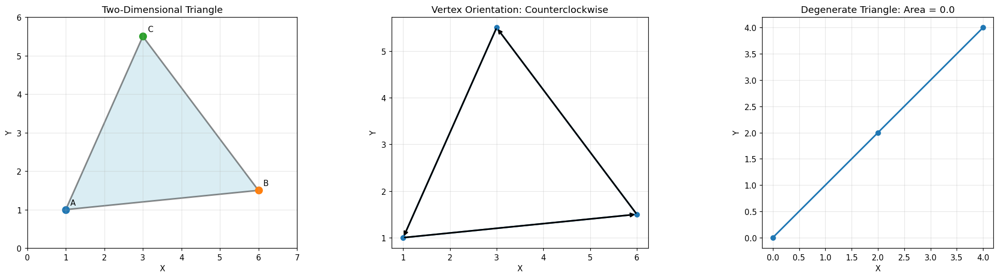

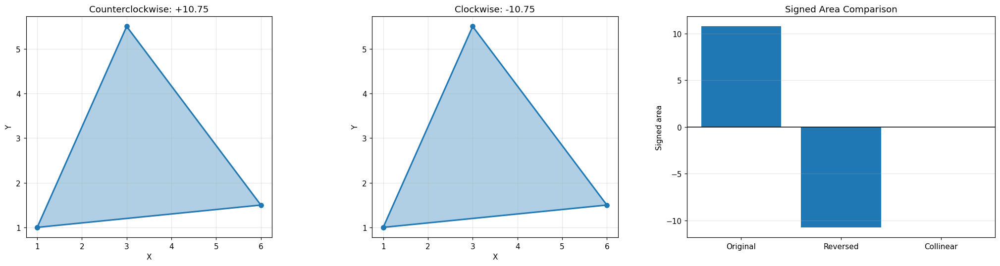

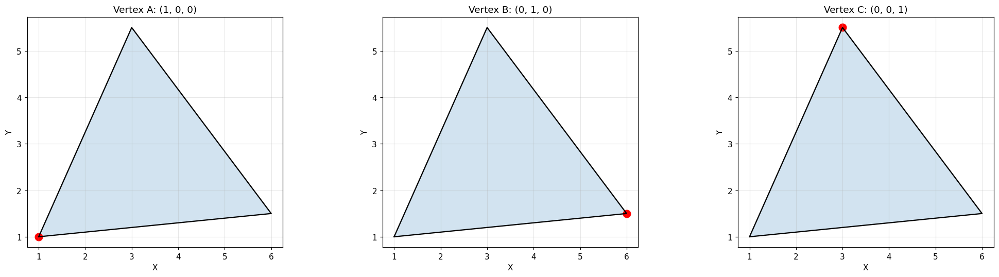

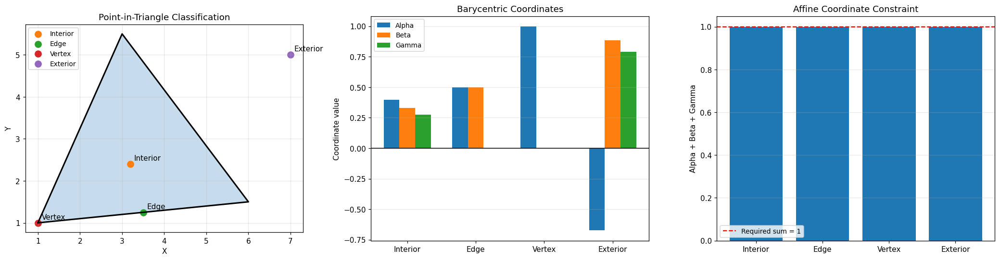

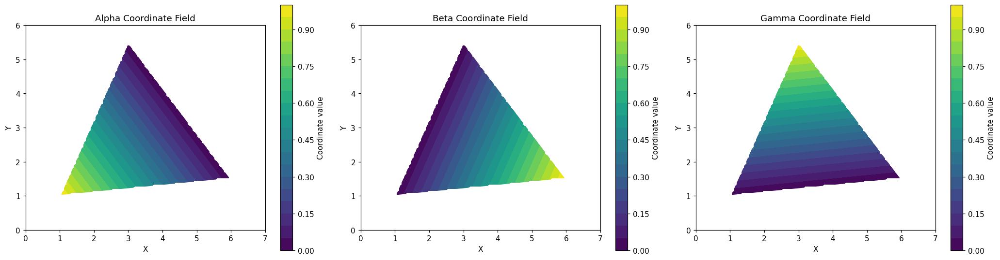

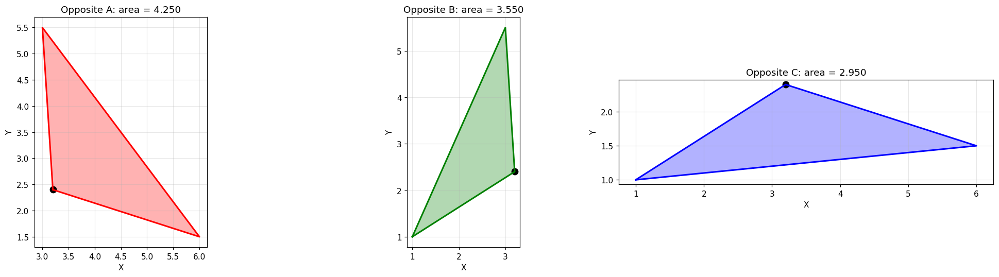

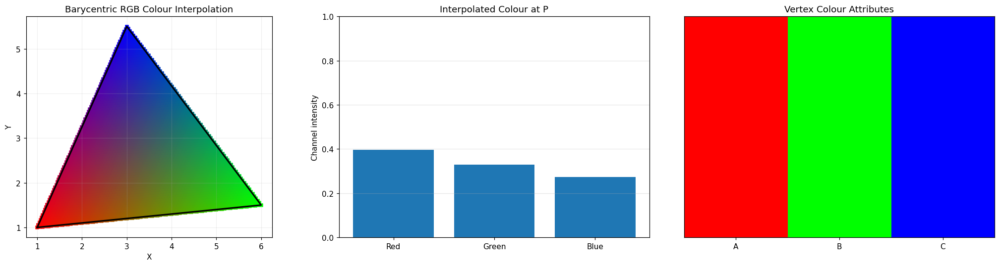

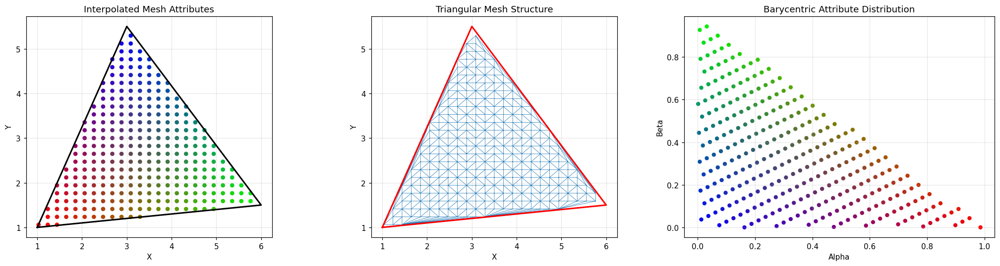

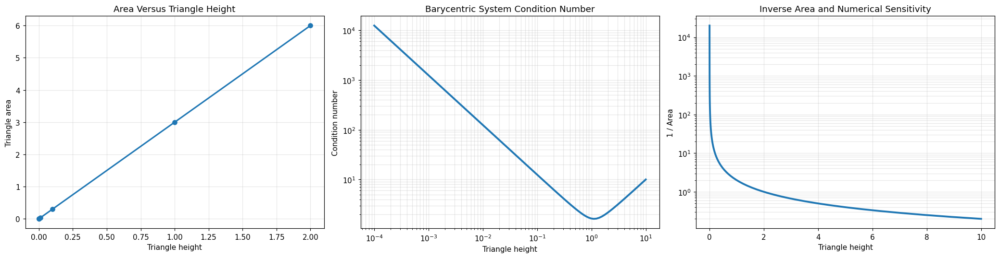

,Measurement,Result
0,Signed area,10.75
1,Absolute area,10.75
2,Reversed signed area,-10.75
3,Collinear area,0.0
4,Orientation,Counterclockwise


,Coordinate,Linear system,Subtriangle area
0,Alpha,0.395349,0.395349
1,Beta,0.330233,0.330233
2,Gamma,0.274419,0.274419
3,Sum,1.000000,1.000000


,Point,X,Y,Alpha,Beta,Gamma,Classification
0,Interior,3.2,2.40,0.395349,0.330233,0.274419,Interior
1,Edge,3.5,1.25,0.500000,0.500000,0.000000,Edge
2,Vertex,1.0,1.00,1.000000,0.000000,0.000000,Vertex
3,Exterior,7.0,5.00,-0.674419,0.883721,0.790698,Exterior


,Alpha,Beta,Gamma
A,1.0,0.0,0.0
B,0.0,1.0,0.0
C,0.0,0.0,1.0


,Alpha,Beta,Gamma
AB midpoint,0.5,0.5,0.0
BC midpoint,0.0,0.5,0.5
CA midpoint,0.5,0.0,0.5


,Channel,Interpolated intensity
0,Red,0.395349
1,Green,0.330233
2,Blue,0.274419


In [46]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Polygon
from matplotlib.tri import Triangulation
from IPython.display import display

# ==============================================================
# 1. CONFIGURATION
# ==============================================================

EPS = 1e-10
COLOUR_TOL = 1e-12

plt.rcParams.update({
    "figure.figsize": (19, 5.5),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})


# ==============================================================
# 2. TRIANGLE VERTICES
# ==============================================================

A = np.array([1.0, 1.0])
B = np.array([6.0, 1.5])
C = np.array([3.0, 5.5])

vertices = np.array([A, B, C])


# ==============================================================
# 3. SIGNED TRIANGLE AREA
# ==============================================================

# A = 1/2 [(xb-xa)(yc-ya) - (xc-xa)(yb-ya)]

def signed_area(A, B, C):
    return 0.5 * (
        (B[0] - A[0]) * (C[1] - A[1])
        -
        (C[0] - A[0]) * (B[1] - A[1])
    )


def triangle_area(A, B, C):
    return abs(signed_area(A, B, C))


area_signed = signed_area(A, B, C)
area_absolute = triangle_area(A, B, C)


# ==============================================================
# 4. TRIANGLE ORIENTATION
# ==============================================================

def triangle_orientation(A, B, C):
    area = signed_area(A, B, C)

    if area > EPS:
        return "Counterclockwise"

    if area < -EPS:
        return "Clockwise"

    return "Degenerate"


orientation = triangle_orientation(A, B, C)

# Reverse vertex order.
area_reversed = signed_area(A, C, B)

# Collinear triangle.
A_collinear = np.array([0.0, 0.0])
B_collinear = np.array([2.0, 2.0])
C_collinear = np.array([4.0, 4.0])

collinear_area = signed_area(
    A_collinear,
    B_collinear,
    C_collinear
)


# ==============================================================
# 5. BARYCENTRIC COORDINATES
# ==============================================================

# P = alpha*A + beta*B + gamma*C
#
# alpha + beta + gamma = 1
#
# [Bx-Ax  Cx-Ax] [beta ] = [Px-Ax]
# [By-Ay  Cy-Ay] [gamma]   [Py-Ay]
#
# alpha = 1 - beta - gamma

def barycentric_coordinates(P, A, B, C):
    M = np.column_stack((B-A, C-A))

    determinant = np.linalg.det(M)

    if abs(determinant) < EPS:
        raise ValueError(
            "Degenerate or numerically unstable triangle."
        )

    beta, gamma = np.linalg.solve(
        M,
        np.asarray(P, dtype=float)-A
    )

    alpha = 1.0-beta-gamma

    return np.array([alpha, beta, gamma])


def reconstruct_point(weights, A, B, C):
    alpha, beta, gamma = weights

    return (
        alpha*A +
        beta*B +
        gamma*C
    )


# ==============================================================
# 6. POINT CLASSIFICATION
# ==============================================================

def classify_point(P, A, B, C, tolerance=1e-9):
    weights = barycentric_coordinates(P, A, B, C)

    if np.any(weights < -tolerance):
        return "Exterior"

    if np.any(np.isclose(weights, 1.0, atol=tolerance)):
        return "Vertex"

    if np.any(np.isclose(weights, 0.0, atol=tolerance)):
        return "Edge"

    return "Interior"


P_interior = np.array([3.2, 2.4])
P_edge = 0.5*(A+B)
P_vertex = A.copy()
P_exterior = np.array([7.0, 5.0])

test_points = {
    "Interior": P_interior,
    "Edge": P_edge,
    "Vertex": P_vertex,
    "Exterior": P_exterior
}

classification_results = {
    name: classify_point(P, A, B, C)
    for name, P in test_points.items()
}


# ==============================================================
# 7. SUBTRIANGLE AREA METHOD
# ==============================================================

# alpha = Aa/A
# beta  = Ab/A
# gamma = Ac/A

def barycentric_area_coordinates(P, A, B, C):
    total = signed_area(A, B, C)

    if abs(total) < EPS:
        raise ValueError("Degenerate triangle.")

    Aa = signed_area(P, B, C)
    Ab = signed_area(A, P, C)
    Ac = signed_area(A, B, P)

    return np.array([
        Aa/total,
        Ab/total,
        Ac/total
    ])


linear_weights = barycentric_coordinates(
    P_interior, A, B, C
)

area_weights = barycentric_area_coordinates(
    P_interior, A, B, C
)


# ==============================================================
# 8. ROBUST VERTEX COLOUR INTERPOLATION
# ==============================================================

# C(P) = alpha*CA + beta*CB + gamma*CC

colour_A = np.array([1.0, 0.0, 0.0])
colour_B = np.array([0.0, 1.0, 0.0])
colour_C = np.array([0.0, 0.0, 1.0])


def interpolate_colour(weights, CA, CB, CC):
    weights = np.asarray(weights, dtype=float)

    # Remove tiny negative rounding errors.
    weights = np.where(
        (weights < 0) & (weights >= -COLOUR_TOL),
        0.0,
        weights
    )

    # Preserve affine interpolation.
    weight_sum = np.sum(weights)

    if abs(weight_sum) < EPS:
        raise ValueError("Invalid barycentric weight sum.")

    weights = weights/weight_sum

    colour = (
        weights[0]*CA +
        weights[1]*CB +
        weights[2]*CC
    )

    # Ensure valid RGB values for Matplotlib.
    return np.clip(colour, 0.0, 1.0)


colour_at_interior = interpolate_colour(
    linear_weights,
    colour_A,
    colour_B,
    colour_C
)


# ==============================================================
# 9. BARYCENTRIC GRID OVER THE TRIANGLE
# ==============================================================

resolution = 80

barycentric_grid = []
grid_points = []
grid_colours = []

for i in range(resolution+1):
    for j in range(resolution+1-i):

        alpha = i/resolution
        beta = j/resolution
        gamma = (resolution-i-j)/resolution

        weights = np.array([
            alpha,
            beta,
            gamma
        ])

        P = reconstruct_point(
            weights, A, B, C
        )

        colour = interpolate_colour(
            weights,
            colour_A,
            colour_B,
            colour_C
        )

        barycentric_grid.append(weights)
        grid_points.append(P)
        grid_colours.append(colour)

barycentric_grid = np.asarray(barycentric_grid)
grid_points = np.asarray(grid_points)
grid_colours = np.clip(
    np.asarray(grid_colours),
    0.0,
    1.0
)


# ==============================================================
# 10. TRIANGULAR MESH
# ==============================================================

mesh_x = np.linspace(0, 7, 35)
mesh_y = np.linspace(0, 6, 35)

XX, YY = np.meshgrid(mesh_x, mesh_y)

mesh_points = np.column_stack((
    XX.ravel(),
    YY.ravel()
))

mesh_weights = np.array([
    barycentric_coordinates(P, A, B, C)
    for P in mesh_points
])

inside_mask = np.all(
    mesh_weights >= -EPS,
    axis=1
)

inside_points = mesh_points[inside_mask]
inside_weights = mesh_weights[inside_mask]

mesh_colours = np.array([
    interpolate_colour(
        weights,
        colour_A,
        colour_B,
        colour_C
    )
    for weights in inside_weights
])

mesh_colours = np.clip(
    mesh_colours,
    0.0,
    1.0
)


# ==============================================================
# 11. BARYCENTRIC COORDINATE FIELDS
# ==============================================================

field_resolution = 100

field_x = np.linspace(0, 7, field_resolution)
field_y = np.linspace(0, 6, field_resolution)

FIELD_X, FIELD_Y = np.meshgrid(field_x, field_y)

alpha_field = np.full_like(FIELD_X, np.nan)
beta_field = np.full_like(FIELD_X, np.nan)
gamma_field = np.full_like(FIELD_X, np.nan)

for row in range(field_resolution):
    for col in range(field_resolution):

        P = np.array([
            FIELD_X[row, col],
            FIELD_Y[row, col]
        ])

        weights = barycentric_coordinates(
            P, A, B, C
        )

        if np.all(weights >= -EPS):
            alpha_field[row, col] = weights[0]
            beta_field[row, col] = weights[1]
            gamma_field[row, col] = weights[2]


# ==============================================================
# 12. VERTEX AND EDGE BARYCENTRIC COORDINATES
# ==============================================================

# A = (1,0,0)
# B = (0,1,0)
# C = (0,0,1)

vertex_weights = np.array([
    barycentric_coordinates(A, A, B, C),
    barycentric_coordinates(B, A, B, C),
    barycentric_coordinates(C, A, B, C)
])

edge_midpoints = [
    0.5*(A+B),
    0.5*(B+C),
    0.5*(C+A)
]

edge_weights = np.array([
    barycentric_coordinates(P, A, B, C)
    for P in edge_midpoints
])


# ==============================================================
# 13. DEGENERATE AND NEAR-DEGENERATE TRIANGLES
# ==============================================================

degenerate_heights = np.array([
    2.0,
    1.0,
    0.1,
    0.01,
    0.001,
    0.0001,
    0.0
])

degenerate_areas = []

for height in degenerate_heights:

    C_test = np.array([3.0, height])

    degenerate_areas.append(
        triangle_area(
            np.array([0.0, 0.0]),
            np.array([6.0, 0.0]),
            C_test
        )
    )

degenerate_areas = np.asarray(degenerate_areas)


# ==============================================================
# 14. CONDITIONING OF BARYCENTRIC SYSTEM
# ==============================================================

heights = np.logspace(-4, 1, 100)

condition_numbers = []

for height in heights:

    A_test = np.array([0.0, 0.0])
    B_test = np.array([1.0, 0.0])
    C_test = np.array([0.5, height])

    M = np.column_stack((
        B_test-A_test,
        C_test-A_test
    ))

    condition_numbers.append(
        np.linalg.cond(M)
    )

condition_numbers = np.asarray(condition_numbers)


# ==============================================================
# 15. VISUALISATION: TRIANGLE GEOMETRY AND ORIENTATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].add_patch(
    Polygon(
        vertices,
        closed=True,
        facecolor="lightblue",
        edgecolor="black",
        alpha=0.45,
        linewidth=2
    )
)

for name, P in zip(["A", "B", "C"], vertices):
    axes[0].scatter(*P, s=80)
    axes[0].annotate(
        name,
        P,
        xytext=(6, 6),
        textcoords="offset points"
    )

axes[0].set_xlim(0, 7)
axes[0].set_ylim(0, 6)
axes[0].set_aspect("equal")
axes[0].set_title("Two-Dimensional Triangle")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    marker="o",
    linewidth=2
)

axes[1].annotate(
    "",
    xy=B,
    xytext=A,
    arrowprops=dict(arrowstyle="->", linewidth=2)
)

axes[1].annotate(
    "",
    xy=C,
    xytext=B,
    arrowprops=dict(arrowstyle="->", linewidth=2)
)

axes[1].annotate(
    "",
    xy=A,
    xytext=C,
    arrowprops=dict(arrowstyle="->", linewidth=2)
)

axes[1].set_title(f"Vertex Orientation: {orientation}")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    [A_collinear[0], B_collinear[0], C_collinear[0]],
    [A_collinear[1], B_collinear[1], C_collinear[1]],
    marker="o",
    linewidth=2
)

axes[2].set_title(
    f"Degenerate Triangle: Area = {collinear_area:.1f}"
)

axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
axes[2].set_aspect("equal")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 16. VISUALISATION: SIGNED AREA AND ORIENTATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].fill(
    vertices[:, 0],
    vertices[:, 1],
    alpha=0.35
)

axes[0].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    marker="o",
    linewidth=2
)

axes[0].set_title(
    f"Counterclockwise: +{area_signed:.2f}"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)

reversed_vertices = np.array([A, C, B])

axes[1].fill(
    reversed_vertices[:, 0],
    reversed_vertices[:, 1],
    alpha=0.35
)

axes[1].plot(
    [A[0], C[0], B[0], A[0]],
    [A[1], C[1], B[1], A[1]],
    marker="o",
    linewidth=2
)

axes[1].set_title(
    f"Clockwise: {area_reversed:.2f}"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)

axes[2].bar(
    ["Original", "Reversed", "Collinear"],
    [
        area_signed,
        area_reversed,
        collinear_area
    ]
)

axes[2].axhline(
    0,
    color="black",
    linewidth=1
)

axes[2].set_title("Signed Area Comparison")
axes[2].set_ylabel("Signed area")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 17. VISUALISATION: BARYCENTRIC VERTEX COORDINATES
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, weights, title in zip(
    axes,
    [
        [1, 0, 0],
        [0, 1, 0],
        [0, 0, 1]
    ],
    ["Vertex A", "Vertex B", "Vertex C"]
):

    P = reconstruct_point(weights, A, B, C)

    ax.fill(
        vertices[:, 0],
        vertices[:, 1],
        alpha=0.2
    )

    ax.plot(
        [A[0], B[0], C[0], A[0]],
        [A[1], B[1], C[1], A[1]],
        color="black"
    )

    ax.scatter(*P, color="red", s=90)

    ax.set_title(
        f"{title}: {tuple(weights)}"
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 18. VISUALISATION: POINT CLASSIFICATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

classification_points = [
    P_interior,
    P_edge,
    P_vertex,
    P_exterior
]

classification_names = [
    "Interior",
    "Edge",
    "Vertex",
    "Exterior"
]

axes[0].fill(
    vertices[:, 0],
    vertices[:, 1],
    alpha=0.25
)

axes[0].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    color="black",
    linewidth=2
)

for P, name in zip(
    classification_points,
    classification_names
):

    axes[0].scatter(*P, s=75, label=name)

    axes[0].annotate(
        name,
        P,
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[0].set_title("Point-in-Triangle Classification")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

point_weights = np.array([
    barycentric_coordinates(P, A, B, C)
    for P in classification_points
])

x_positions = np.arange(4)
width = 0.23

for i, label in enumerate(["Alpha", "Beta", "Gamma"]):
    axes[1].bar(
        x_positions+(i-1)*width,
        point_weights[:, i],
        width,
        label=label
    )

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(classification_names)
axes[1].set_title("Barycentric Coordinates")
axes[1].set_ylabel("Coordinate value")
axes[1].grid(True, axis="y", alpha=0.3)
axes[1].legend()

axes[2].bar(
    classification_names,
    np.sum(point_weights, axis=1)
)

axes[2].axhline(
    1,
    color="red",
    linestyle="--",
    label="Required sum = 1"
)

axes[2].set_title("Affine Coordinate Constraint")
axes[2].set_ylabel("Alpha + Beta + Gamma")
axes[2].grid(True, axis="y", alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 19. VISUALISATION: BARYCENTRIC COORDINATE FIELDS
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, field, title in zip(
    axes,
    [alpha_field, beta_field, gamma_field],
    [
        "Alpha Coordinate Field",
        "Beta Coordinate Field",
        "Gamma Coordinate Field"
    ]
):

    contour = ax.contourf(
        FIELD_X,
        FIELD_Y,
        field,
        levels=20,
        cmap="viridis"
    )

    ax.plot(
        [A[0], B[0], C[0], A[0]],
        [A[1], B[1], C[1], A[1]],
        color="white",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")

    fig.colorbar(
        contour,
        ax=ax,
        label="Coordinate value"
    )

plt.tight_layout()
plt.show()


# ==============================================================
# 20. VISUALISATION: SUBTRIANGLE AREA METHOD
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

P = P_interior

subtriangles = [
    (P, B, C),
    (A, P, C),
    (A, B, P)
]

subtriangle_colours = [
    "red",
    "green",
    "blue"
]

subtriangle_names = [
    "Opposite A",
    "Opposite B",
    "Opposite C"
]

for ax, triangle, colour, name in zip(
    axes,
    subtriangles,
    subtriangle_colours,
    subtriangle_names
):

    triangle_array = np.array(triangle)

    ax.fill(
        triangle_array[:, 0],
        triangle_array[:, 1],
        color=colour,
        alpha=0.3
    )

    ax.plot(
        [
            triangle_array[0, 0],
            triangle_array[1, 0],
            triangle_array[2, 0],
            triangle_array[0, 0]
        ],
        [
            triangle_array[0, 1],
            triangle_array[1, 1],
            triangle_array[2, 1],
            triangle_array[0, 1]
        ],
        color=colour,
        linewidth=2
    )

    ax.scatter(*P, color="black", s=65)

    ax.set_title(
        f"{name}: area = {triangle_area(*triangle):.3f}"
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 21. VISUALISATION: BARYCENTRIC RGB COLOUR INTERPOLATION
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].scatter(
    grid_points[:, 0],
    grid_points[:, 1],
    c=grid_colours,
    s=15,
    marker="s"
)

axes[0].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    color="black",
    linewidth=2
)

axes[0].set_title("Barycentric RGB Colour Interpolation")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.2)

axes[1].bar(
    ["Red", "Green", "Blue"],
    colour_at_interior
)

axes[1].set_title("Interpolated Colour at P")
axes[1].set_ylabel("Channel intensity")
axes[1].set_ylim(0, 1)
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].imshow(
    np.array([[colour_A, colour_B, colour_C]]),
    aspect="auto"
)

axes[2].set_title("Vertex Colour Attributes")
axes[2].set_xticks([0, 1, 2])
axes[2].set_xticklabels(["A", "B", "C"])
axes[2].set_yticks([])

plt.tight_layout()
plt.show()


# ==============================================================
# 22. VISUALISATION: TRIANGULAR MESH
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].scatter(
    inside_points[:, 0],
    inside_points[:, 1],
    c=mesh_colours,
    s=22
)

axes[0].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    color="black",
    linewidth=2
)

axes[0].set_title("Interpolated Mesh Attributes")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)

triangulation = Triangulation(
    inside_points[:, 0],
    inside_points[:, 1]
)

axes[1].triplot(
    triangulation,
    linewidth=0.5
)

axes[1].plot(
    [A[0], B[0], C[0], A[0]],
    [A[1], B[1], C[1], A[1]],
    color="red",
    linewidth=2
)

axes[1].set_title("Triangular Mesh Structure")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)

axes[2].scatter(
    inside_weights[:, 0],
    inside_weights[:, 1],
    c=mesh_colours,
    s=20
)

axes[2].set_title("Barycentric Attribute Distribution")
axes[2].set_xlabel("Alpha")
axes[2].set_ylabel("Beta")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 23. VISUALISATION: DEGENERACY AND NUMERICAL STABILITY
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    degenerate_heights,
    degenerate_areas,
    marker="o",
    linewidth=2
)

axes[0].set_title("Area Versus Triangle Height")
axes[0].set_xlabel("Triangle height")
axes[0].set_ylabel("Triangle area")
axes[0].grid(True, alpha=0.3)

axes[1].loglog(
    heights,
    condition_numbers,
    linewidth=2.5
)

axes[1].set_title("Barycentric System Condition Number")
axes[1].set_xlabel("Triangle height")
axes[1].set_ylabel("Condition number")
axes[1].grid(True, which="both", alpha=0.3)

inverse_areas = np.array([
    1.0 / max(
        triangle_area(
            np.array([0.0, 0.0]),
            np.array([1.0, 0.0]),
            np.array([0.5, h])
        ),
        EPS
    )
    for h in heights
])

axes[2].semilogy(
    heights,
    inverse_areas,
    linewidth=2.5
)

axes[2].set_title("Inverse Area and Numerical Sensitivity")
axes[2].set_xlabel("Triangle height")
axes[2].set_ylabel("1 / Area")
axes[2].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 24. NUMERICAL TABLES
# ==============================================================

area_table = pd.DataFrame({
    "Measurement": [
        "Signed area",
        "Absolute area",
        "Reversed signed area",
        "Collinear area",
        "Orientation"
    ],
    "Result": [
        area_signed,
        area_absolute,
        area_reversed,
        collinear_area,
        orientation
    ]
})

barycentric_table = pd.DataFrame({
    "Coordinate": [
        "Alpha",
        "Beta",
        "Gamma",
        "Sum"
    ],
    "Linear system": [
        *linear_weights,
        np.sum(linear_weights)
    ],
    "Subtriangle area": [
        *area_weights,
        np.sum(area_weights)
    ]
})

classification_table = pd.DataFrame({
    "Point": classification_names,
    "X": [
        P[0] for P in classification_points
    ],
    "Y": [
        P[1] for P in classification_points
    ],
    "Alpha": point_weights[:, 0],
    "Beta": point_weights[:, 1],
    "Gamma": point_weights[:, 2],
    "Classification": [
        classify_point(P, A, B, C)
        for P in classification_points
    ]
})

vertex_table = pd.DataFrame(
    vertex_weights,
    index=["A", "B", "C"],
    columns=["Alpha", "Beta", "Gamma"]
)

edge_table = pd.DataFrame(
    edge_weights,
    index=["AB midpoint", "BC midpoint", "CA midpoint"],
    columns=["Alpha", "Beta", "Gamma"]
)

colour_table = pd.DataFrame({
    "Channel": ["Red", "Green", "Blue"],
    "Interpolated intensity": colour_at_interior
})

display(area_table)
display(barycentric_table)
display(classification_table)
display(vertex_table)
display(edge_table)
display(colour_table)


# ==============================================================
# 25. MATHEMATICAL VERIFICATION
# ==============================================================

# A. Main triangle has nonzero area.

assert abs(area_signed) > EPS

# B. Reversing two vertices reverses signed area.

assert np.isclose(
    area_reversed,
    -area_signed
)

# C. Absolute area remains unchanged.

assert np.isclose(
    abs(area_reversed),
    area_absolute
)

# D. Collinear vertices produce zero area.

assert np.isclose(
    collinear_area,
    0
)

# E. Barycentric coordinates sum to one.

assert np.isclose(
    np.sum(linear_weights),
    1
)

# F. Barycentric coordinates reconstruct the point.

assert np.allclose(
    reconstruct_point(
        linear_weights,
        A, B, C
    ),
    P_interior
)

# G. Linear-system and area-based coordinates agree.

assert np.allclose(
    linear_weights,
    area_weights
)

# H. Vertex coordinates are unit barycentric vectors.

assert np.allclose(
    vertex_weights,
    np.eye(3)
)

# I. Edge midpoints have two coordinates equal to 0.5
# and one coordinate equal to zero.

assert np.allclose(
    np.sort(edge_weights, axis=1),
    np.array([
        [0, 0.5, 0.5],
        [0, 0.5, 0.5],
        [0, 0.5, 0.5]
    ])
)

# J. Interior point has three positive coordinates.

assert np.all(linear_weights > 0)

# K. Edge point has one zero coordinate.

assert np.any(
    np.isclose(
        barycentric_coordinates(P_edge, A, B, C),
        0
    )
)

# L. Vertex point has one coordinate equal to one.

assert np.any(
    np.isclose(
        barycentric_coordinates(P_vertex, A, B, C),
        1
    )
)

# M. Exterior point has at least one negative coordinate.

assert np.any(
    barycentric_coordinates(
        P_exterior, A, B, C
    ) < 0
)

# N. Point classifications.

assert classification_results["Interior"] == "Interior"
assert classification_results["Edge"] == "Edge"
assert classification_results["Vertex"] == "Vertex"
assert classification_results["Exterior"] == "Exterior"

# O. RGB values are within the valid range.

assert np.all(colour_at_interior >= 0)
assert np.all(colour_at_interior <= 1)
assert np.all(grid_colours >= 0)
assert np.all(grid_colours <= 1)
assert np.all(mesh_colours >= 0)
assert np.all(mesh_colours <= 1)

# P. Mesh barycentric coordinates sum to one.

assert np.allclose(
    np.sum(inside_weights, axis=1),
    1
)

# Q. All retained mesh points are inside the triangle.

assert np.all(
    inside_weights >= -EPS
)

# R. Barycentric grid points are reconstructed correctly.

assert np.allclose(
    grid_points,
    (
        barycentric_grid[:, 0, None]*A +
        barycentric_grid[:, 1, None]*B +
        barycentric_grid[:, 2, None]*C
    )
)

# S. Determinant and signed-area calculations agree.

matrix_area = 0.5*np.linalg.det(
    np.column_stack((B-A, C-A))
)

assert np.isclose(
    area_signed,
    matrix_area
)

# T. All generated barycentric grid coordinates are valid.

assert np.all(barycentric_grid >= -EPS)
assert np.allclose(
    np.sum(barycentric_grid, axis=1),
    1
)


### 2.7.2 Three-Dimensional Triangles

Barycentric coordinates extend to triangles embedded in three-dimensional space. Given non-collinear vertices $a,b,c\in\mathbb R^3$, a point $p$ in their plane is represented by:

$$
p=(1-\beta-\gamma)a+\beta b+\gamma c,
$$

where $\alpha=1-\beta-\gamma$, and:

$$
\alpha+\beta+\gamma=1.
$$

For an interior point, $\alpha,\beta,\gamma\geq0$. These coefficients express the point as a weighted combination of the triangle's vertices.

**1. Triangle Normal Vector**

The normal vector is calculated using two edges:

$$
\boxed{\mathbf n=(b-a)\times(c-a)}.
$$

The cross product produces a vector perpendicular to the triangle's plane. Its orientation follows the right-hand rule and depends on vertex ordering. The corresponding unit normal is:

$$
\hat{\mathbf n}=\frac{\mathbf n}{\|\mathbf n\|}.
$$

It has unit magnitude and establishes surface orientation for lighting and shading.

**2. Triangle Area**

The cross-product magnitude equals the parallelogram area; therefore, the triangle occupies half that area:

$$
\boxed{A=\frac12\|(b-a)\times(c-a)\|}.
$$

**3. Barycentric Coordinates**

Define the subtriangle normal vectors:

$$
\begin{aligned}
\mathbf n_a&=(c-b)\times(p-b),\\
\mathbf n_b&=(a-c)\times(p-c),\\
\mathbf n_c&=(b-a)\times(p-a).
\end{aligned}
$$

The coordinates are:

$$
\alpha=\frac{\mathbf n\cdot\mathbf n_a}{\|\mathbf n\|^2},\quad
\beta=\frac{\mathbf n\cdot\mathbf n_b}{\|\mathbf n\|^2},\quad
\gamma=\frac{\mathbf n\cdot\mathbf n_c}{\|\mathbf n\|^2}.
$$

These dot-product ratios measure signed subtriangle areas relative to the original triangle, preserving orientation.

**Applications:** Three-dimensional barycentric coordinates enable mesh interpolation, surface reconstruction, texture mapping, collision detection and geometric modelling.

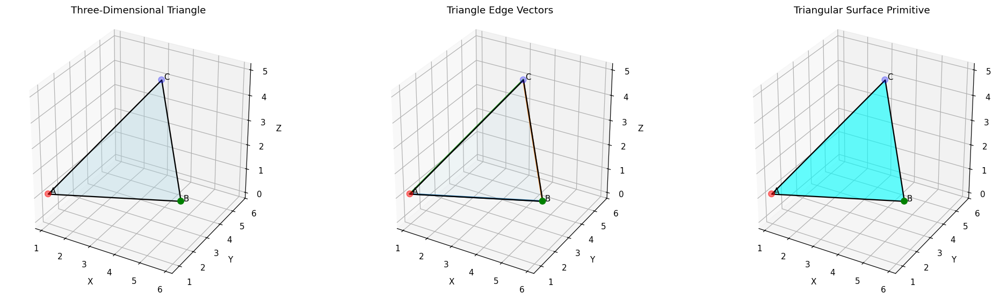

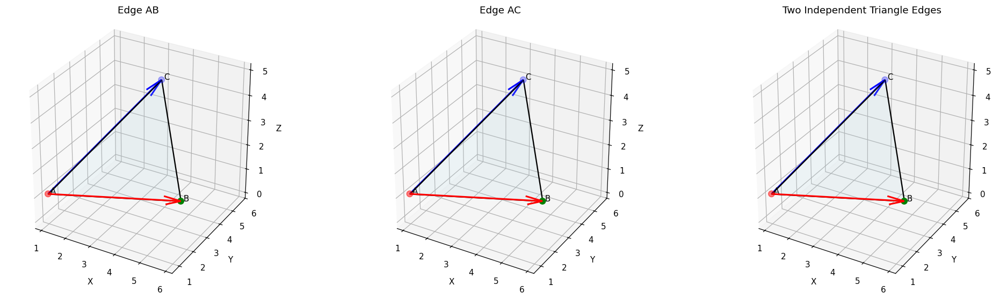

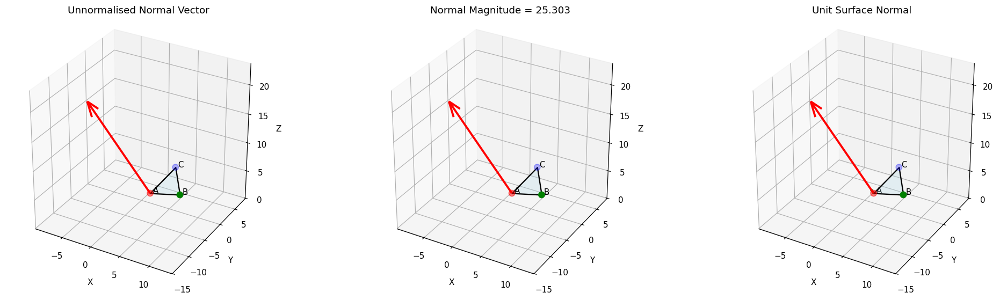

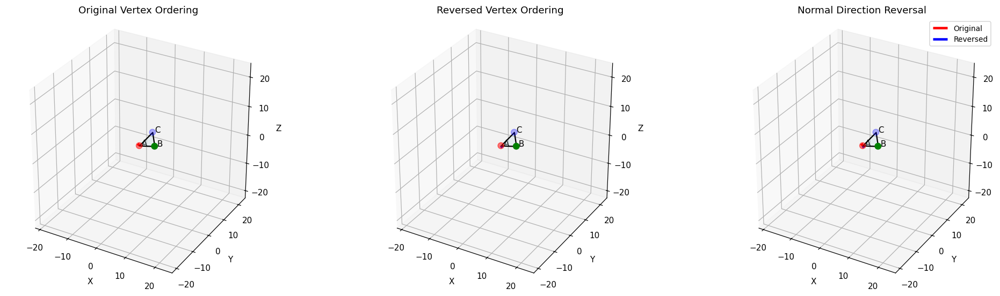

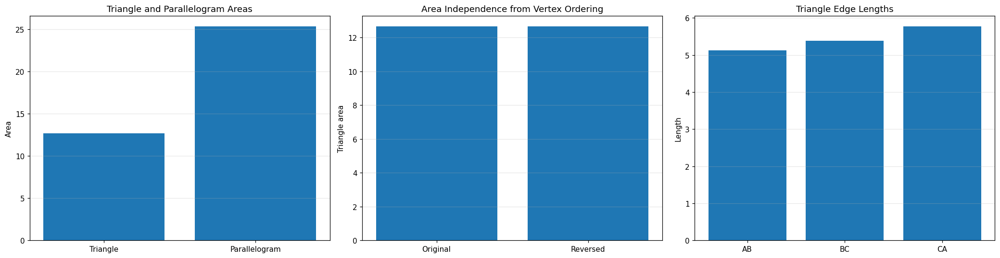

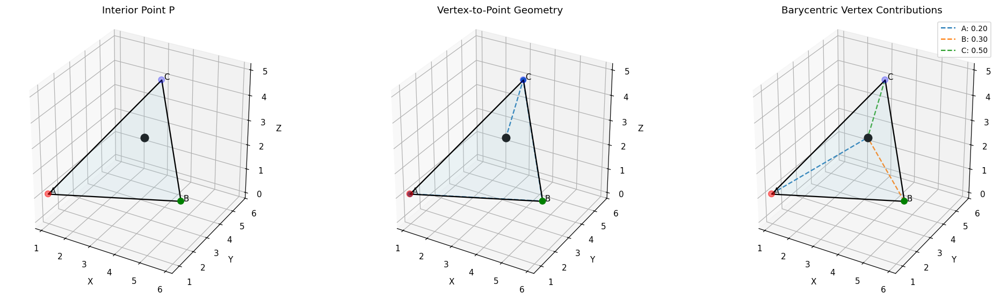

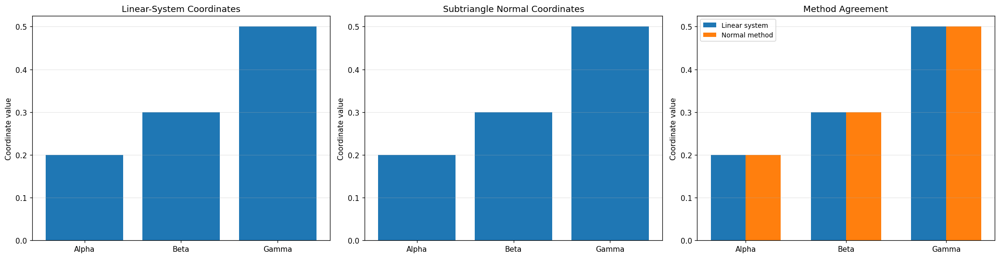

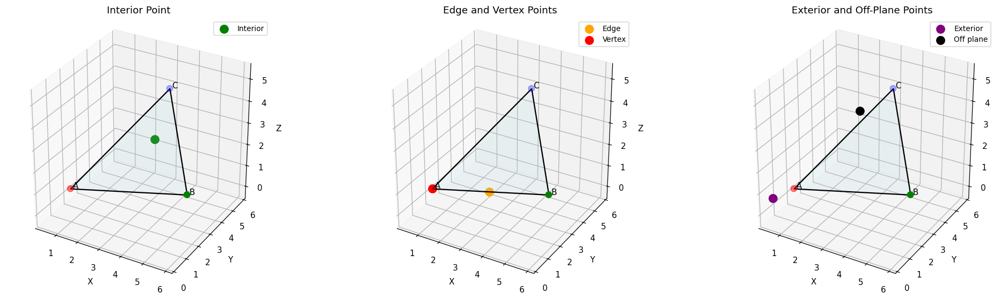

/tmp/ipykernel_494/1117514872.py:1154: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


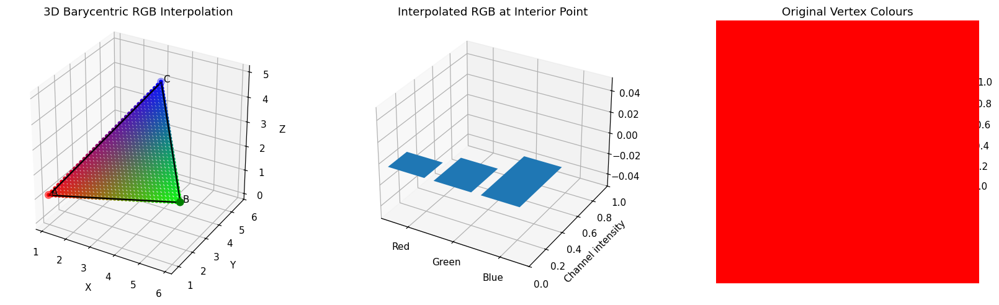

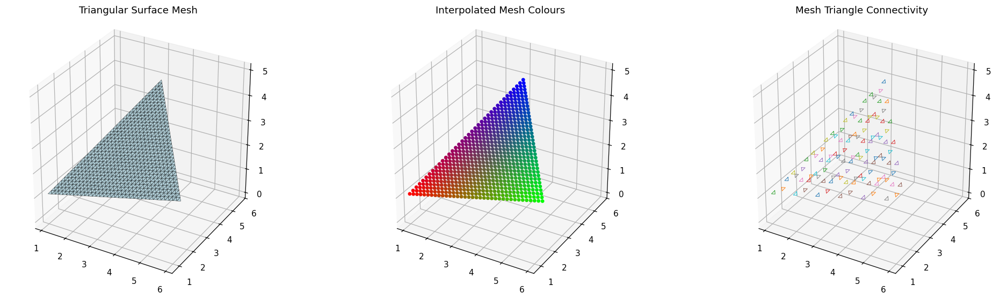

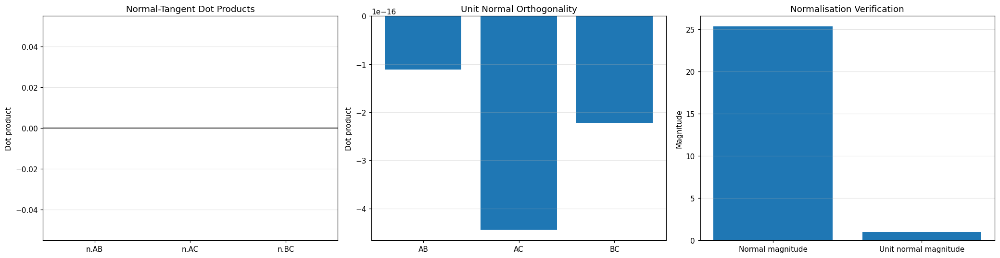

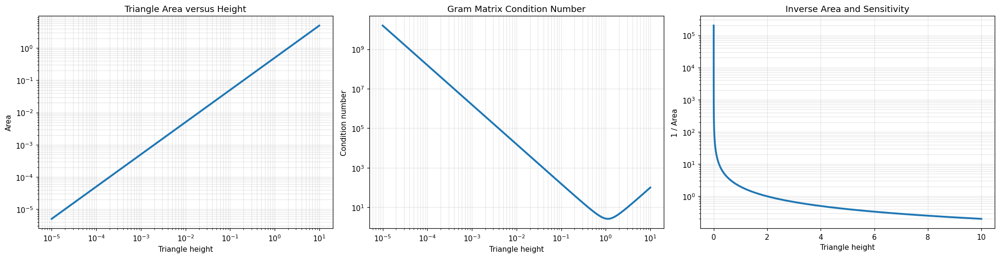

,Quantity,Value
0,AB length,5.123475
1,BC length,5.385165
2,CA length,5.766281
3,Normal X,-3.000000
4,Normal Y,-13.000000
5,Normal Z,21.500000
6,Normal magnitude,25.303162
7,Unit normal magnitude,1.000000
8,Triangle area,12.651581
9,Parallelogram area,25.303162


,Coordinate,Linear system,Subtriangle normal
0,Alpha,0.2,0.2
1,Beta,0.3,0.3
2,Gamma,0.5,0.5
3,Sum,1.0,1.0


,Point,X,Y,Z,Alpha,Beta,Gamma,Classification
0,Interior,3.500000,3.40000,2.800000,0.2,0.3,5.000000e-01,Interior
1,Edge,3.500000,1.25000,1.500000,0.5,0.5,-3.641497e-17,Edge
2,Vertex,1.000000,1.00000,1.000000,1.0,0.0,0.000000e+00,Vertex
3,Exterior,0.300000,0.50000,0.600000,1.2,-0.1,-1.000000e-01,Exterior
4,Off plane,3.262875,2.37246,4.499392,NaN,NaN,NaN,Outside triangle plane


,Colour channel,Interpolated value
0,Red,0.2
1,Green,0.3
2,Blue,0.5


In [47]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ==============================================================
# 1. CONFIGURATION
# ==============================================================

EPS = 1e-10
COLOUR_TOL = 1e-12

plt.rcParams.update({
    "figure.figsize": (19, 5.5),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})


# ==============================================================
# 2. THREE-DIMENSIONAL TRIANGLE VERTICES
# ==============================================================

A = np.array([1.0, 1.0, 1.0])
B = np.array([6.0, 1.5, 2.0])
C = np.array([3.0, 5.5, 4.0])

vertices = np.array([A, B, C])


# ==============================================================
# 3. TRIANGLE EDGE VECTORS
# ==============================================================

AB = B - A
AC = C - A
BC = C - B

edge_lengths = np.array([
    np.linalg.norm(AB),
    np.linalg.norm(BC),
    np.linalg.norm(C-A)
])


# ==============================================================
# 4. TRIANGLE NORMAL VECTOR
# ==============================================================

# n = (b-a) x (c-a)

def triangle_normal(A, B, C):
    return np.cross(B-A, C-A)


normal = triangle_normal(A, B, C)
normal_magnitude = np.linalg.norm(normal)


def unit_vector(v):
    magnitude = np.linalg.norm(v)

    if magnitude < EPS:
        raise ValueError("Cannot normalize a zero-length vector.")

    return v/magnitude


unit_normal = unit_vector(normal)


# ==============================================================
# 5. TRIANGLE AREA
# ==============================================================

# Area = 1/2 ||(B-A) x (C-A)||

def triangle_area_3d(A, B, C):
    return 0.5*np.linalg.norm(
        np.cross(B-A, C-A)
    )


area = triangle_area_3d(A, B, C)

parallelogram_area = normal_magnitude


# ==============================================================
# 6. REVERSED VERTEX ORDERING
# ==============================================================

reversed_normal = triangle_normal(A, C, B)

reversed_unit_normal = unit_vector(
    reversed_normal
)

reversed_area = triangle_area_3d(A, C, B)


# ==============================================================
# 7. BARYCENTRIC COORDINATES USING A LINEAR SYSTEM
# ==============================================================

# P = alpha*A + beta*B + gamma*C
#
# alpha + beta + gamma = 1
#
# P-A = beta(B-A) + gamma(C-A)
#
# Solve using the Gram matrix:
#
# [AB.AB  AB.AC] [beta ] = [AB.(P-A)]
# [AB.AC  AC.AC] [gamma]   [AC.(P-A)]
#
# alpha = 1-beta-gamma

def barycentric_coordinates_3d(P, A, B, C):

    AB = B-A
    AC = C-A
    AP = P-A

    gram_matrix = np.array([
        [np.dot(AB, AB), np.dot(AB, AC)],
        [np.dot(AB, AC), np.dot(AC, AC)]
    ])

    rhs = np.array([
        np.dot(AB, AP),
        np.dot(AC, AP)
    ])

    determinant = np.linalg.det(gram_matrix)

    if determinant < EPS:
        raise ValueError(
            "Degenerate or numerically unstable triangle."
        )

    beta, gamma = np.linalg.solve(
        gram_matrix,
        rhs
    )

    alpha = 1-beta-gamma

    return np.array([
        alpha,
        beta,
        gamma
    ])


def reconstruct_point_3d(weights, A, B, C):

    alpha, beta, gamma = weights

    return (
        alpha*A +
        beta*B +
        gamma*C
    )


# ==============================================================
# 8. BARYCENTRIC COORDINATES USING SUBTRIANGLE NORMALS
# ==============================================================

# n  = (B-A) x (C-A)
#
# na = (C-B) x (P-B)
# nb = (A-C) x (P-C)
# nc = (B-A) x (P-A)
#
# alpha = n.na / ||n||²
# beta  = n.nb / ||n||²
# gamma = n.nc / ||n||²

def barycentric_normal_coordinates(P, A, B, C):

    n = np.cross(B-A, C-A)

    denominator = np.dot(n, n)

    if denominator < EPS**2:
        raise ValueError("Degenerate triangle.")

    na = np.cross(C-B, P-B)
    nb = np.cross(A-C, P-C)
    nc = np.cross(B-A, P-A)

    alpha = np.dot(n, na)/denominator
    beta = np.dot(n, nb)/denominator
    gamma = np.dot(n, nc)/denominator

    return np.array([
        alpha,
        beta,
        gamma
    ])


# ==============================================================
# 9. POINT RECONSTRUCTION AND PLANE DISTANCE
# ==============================================================

def point_plane_distance(P, A, unit_normal):

    return np.dot(
        P-A,
        unit_normal
    )


def project_onto_triangle_plane(P, A, unit_normal):

    distance = point_plane_distance(
        P, A, unit_normal
    )

    return P-distance*unit_normal


# ==============================================================
# 10. POINT CLASSIFICATION
# ==============================================================

def classify_point_3d(P, A, B, C, tolerance=1e-8):

    n = np.cross(B-A, C-A)

    if np.linalg.norm(n) < EPS:
        raise ValueError("Cannot classify against a degenerate triangle.")

    distance = abs(
        point_plane_distance(
            P,
            A,
            unit_vector(n)
        )
    )

    if distance > tolerance:
        return "Outside triangle plane"

    weights = barycentric_coordinates_3d(
        P, A, B, C
    )

    if np.any(weights < -tolerance):
        return "Exterior"

    if np.any(np.isclose(weights, 1, atol=tolerance)):
        return "Vertex"

    if np.any(np.isclose(weights, 0, atol=tolerance)):
        return "Edge"

    return "Interior"


# ==============================================================
# 11. REPRESENTATIVE TEST POINTS
# ==============================================================

P_interior = (
    0.2*A +
    0.3*B +
    0.5*C
)

P_edge = 0.5*(A+B)

P_vertex = A.copy()

P_exterior = (
    1.2*A -
    0.1*B -
    0.1*C
)

P_off_plane = P_interior + 2.0*unit_normal

test_points = {
    "Interior": P_interior,
    "Edge": P_edge,
    "Vertex": P_vertex,
    "Exterior": P_exterior,
    "Off plane": P_off_plane
}


# ==============================================================
# 12. CALCULATE BARYCENTRIC COORDINATES
# ==============================================================

point_weights = {}

for name, P in test_points.items():

    if name == "Off plane":
        continue

    point_weights[name] = barycentric_coordinates_3d(
        P, A, B, C
    )


# ==============================================================
# 13. VERTEX ATTRIBUTE INTERPOLATION
# ==============================================================

# F(P) = alpha*FA + beta*FB + gamma*FC

def interpolate_attribute(weights, FA, FB, FC):

    weights = np.asarray(weights, dtype=float)

    total = np.sum(weights)

    if abs(total) < EPS:
        raise ValueError("Invalid barycentric coordinates.")

    weights = weights/total

    return (
        weights[0]*FA +
        weights[1]*FB +
        weights[2]*FC
    )


# Vertex RGB values.
colour_A = np.array([1.0, 0.0, 0.0])
colour_B = np.array([0.0, 1.0, 0.0])
colour_C = np.array([0.0, 0.0, 1.0])


def interpolate_rgb(weights):

    colour = interpolate_attribute(
        weights,
        colour_A,
        colour_B,
        colour_C
    )

    return np.clip(
        colour,
        0.0,
        1.0
    )


colour_at_interior = interpolate_rgb(
    barycentric_coordinates_3d(
        P_interior, A, B, C
    )
)


# ==============================================================
# 14. TRIANGULAR BARYCENTRIC GRID
# ==============================================================

resolution = 35

grid_points = []
grid_weights = []
grid_colours = []

for i in range(resolution+1):

    for j in range(resolution+1-i):

        alpha = i/resolution
        beta = j/resolution
        gamma = 1-alpha-beta

        weights = np.array([
            alpha,
            beta,
            gamma
        ])

        P = reconstruct_point_3d(
            weights,
            A, B, C
        )

        colour = interpolate_rgb(weights)

        grid_points.append(P)
        grid_weights.append(weights)
        grid_colours.append(colour)

grid_points = np.asarray(grid_points)
grid_weights = np.asarray(grid_weights)
grid_colours = np.asarray(grid_colours)

grid_colours = np.clip(
    grid_colours,
    0.0,
    1.0
)


# ==============================================================
# 15. TRIANGULAR MESH CONNECTIVITY
# ==============================================================

# Build triangular connectivity for the barycentric grid.

index_map = {}
index = 0

for i in range(resolution+1):

    for j in range(resolution+1-i):

        index_map[(i, j)] = index
        index += 1

mesh_triangles = []

for i in range(resolution):

    for j in range(resolution-i):

        v0 = index_map[(i, j)]
        v1 = index_map[(i+1, j)]
        v2 = index_map[(i, j+1)]

        mesh_triangles.append([
            v0, v1, v2
        ])

        if j < resolution-i-1:

            v3 = index_map[(i+1, j+1)]

            mesh_triangles.append([
                v1, v3, v2
            ])

mesh_triangles = np.asarray(mesh_triangles)


# ==============================================================
# 16. NORMALS AT DIFFERENT TRIANGLE LOCATIONS
# ==============================================================

sample_weights = np.array([
    [1/3, 1/3, 1/3],
    [0.2, 0.3, 0.5],
    [0.6, 0.2, 0.2]
])

sample_points = np.array([
    reconstruct_point_3d(w, A, B, C)
    for w in sample_weights
])

sample_normals = np.tile(
    unit_normal,
    (len(sample_points), 1)
)


# ==============================================================
# 17. TRIANGLE EDGE AND NORMAL DATA
# ==============================================================

edge_midpoints = np.array([
    0.5*(A+B),
    0.5*(B+C),
    0.5*(C+A)
])

edge_names = [
    "AB",
    "BC",
    "CA"
]

edge_vectors = np.array([
    B-A,
    C-B,
    A-C
])


# ==============================================================
# 18. NORMAL AND TANGENT ORTHOGONALITY
# ==============================================================

dot_products = np.array([
    np.dot(normal, AB),
    np.dot(normal, AC),
    np.dot(normal, BC)
])


# ==============================================================
# 19. DEGENERATE TRIANGLE TEST
# ==============================================================

A_deg = np.array([0.0, 0.0, 0.0])
B_deg = np.array([2.0, 0.0, 0.0])
C_deg = np.array([4.0, 0.0, 0.0])

degenerate_normal = triangle_normal(
    A_deg, B_deg, C_deg
)

degenerate_area = triangle_area_3d(
    A_deg, B_deg, C_deg
)


# ==============================================================
# 20. NEAR-DEGENERATE TRIANGLE STABILITY
# ==============================================================

heights = np.logspace(-5, 1, 100)

condition_numbers = []
areas = []

for height in heights:

    A_test = np.array([0.0, 0.0, 0.0])
    B_test = np.array([1.0, 0.0, 0.0])
    C_test = np.array([0.5, height, 0.0])

    AB_test = B_test-A_test
    AC_test = C_test-A_test

    gram = np.array([
        [np.dot(AB_test, AB_test),
         np.dot(AB_test, AC_test)],
        [np.dot(AB_test, AC_test),
         np.dot(AC_test, AC_test)]
    ])

    condition_numbers.append(
        np.linalg.cond(gram)
    )

    areas.append(
        triangle_area_3d(
            A_test, B_test, C_test
        )
    )

condition_numbers = np.asarray(condition_numbers)
areas = np.asarray(areas)


# ==============================================================
# 21. 3D PLOTTING HELPER
# ==============================================================

def draw_triangle(ax, A, B, C, colour="lightblue", alpha=0.35):

    polygon = Poly3DCollection(
        [[A, B, C]],
        facecolors=colour,
        edgecolors="black",
        alpha=alpha,
        linewidths=1.5
    )

    ax.add_collection3d(polygon)

    ax.scatter(
        [A[0], B[0], C[0]],
        [A[1], B[1], C[1]],
        [A[2], B[2], C[2]],
        s=55,
        color=["red", "green", "blue"]
    )

    for name, P in zip(["A", "B", "C"], [A, B, C]):

        ax.text(
            P[0], P[1], P[2],
            f" {name}",
            fontsize=10
        )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")


def set_equal_3d(ax, points):

    points = np.asarray(points)

    minimum = points.min(axis=0)
    maximum = points.max(axis=0)

    center = 0.5*(minimum+maximum)

    radius = 0.55*np.max(maximum-minimum)

    radius = max(radius, 1.0)

    ax.set_xlim(center[0]-radius, center[0]+radius)
    ax.set_ylim(center[1]-radius, center[1]+radius)
    ax.set_zlim(center[2]-radius, center[2]+radius)

    ax.set_box_aspect((1, 1, 1))


# ==============================================================
# 22. VISUALISATION: 3D TRIANGLE GEOMETRY
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

draw_triangle(
    axes[0], A, B, C
)

set_equal_3d(
    axes[0], vertices
)

axes[0].set_title("Three-Dimensional Triangle")

# Triangle edges.
for start, end in [(A, B), (B, C), (C, A)]:

    axes[1].plot(
        [start[0], end[0]],
        [start[1], end[1]],
        [start[2], end[2]],
        linewidth=2
    )

draw_triangle(
    axes[1], A, B, C,
    alpha=0.12
)

set_equal_3d(
    axes[1], vertices
)

axes[1].set_title("Triangle Edge Vectors")

# Filled triangle.
draw_triangle(
    axes[2], A, B, C,
    colour="cyan",
    alpha=0.6
)

set_equal_3d(
    axes[2], vertices
)

axes[2].set_title("Triangular Surface Primitive")

plt.tight_layout()
plt.show()


# ==============================================================
# 23. VISUALISATION: EDGE VECTORS AND NORMAL VECTOR
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

for ax in axes:

    draw_triangle(
        ax, A, B, C,
        alpha=0.15
    )

    origin = A

    ax.quiver(
        *origin,
        *AB,
        color="red",
        linewidth=2,
        arrow_length_ratio=0.12
    )

    ax.quiver(
        *origin,
        *AC,
        color="blue",
        linewidth=2,
        arrow_length_ratio=0.12
    )

    set_equal_3d(
        ax, vertices
    )

axes[0].set_title("Edge AB")
axes[1].set_title("Edge AC")
axes[2].set_title("Two Independent Triangle Edges")

plt.tight_layout()
plt.show()


# ==============================================================
# 24. VISUALISATION: CROSS-PRODUCT NORMAL
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

for ax in axes:

    draw_triangle(
        ax, A, B, C,
        alpha=0.25
    )

    ax.quiver(
        *A,
        *normal,
        color="red",
        linewidth=2.5,
        arrow_length_ratio=0.12
    )

    set_equal_3d(
        ax,
        np.vstack([vertices, A+normal])
    )

axes[0].set_title("Unnormalised Normal Vector")
axes[1].set_title(
    f"Normal Magnitude = {normal_magnitude:.3f}"
)

axes[2].quiver(
    *A,
    *unit_normal,
    color="green",
    linewidth=3,
    arrow_length_ratio=0.2
)

axes[2].set_title("Unit Surface Normal")

plt.tight_layout()
plt.show()


# ==============================================================
# 25. VISUALISATION: VERTEX ORDER AND NORMAL DIRECTION
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

for ax in axes:

    draw_triangle(
        ax, A, B, C,
        alpha=0.2
    )

    set_equal_3d(
        ax,
        np.vstack([
            vertices,
            A+normal,
            A+reversed_normal
        ])
    )

axes[0].quiver(
    *A,
    *unit_normal,
    color="red",
    linewidth=3
)

axes[0].set_title("Original Vertex Ordering")

axes[1].quiver(
    *A,
    *reversed_unit_normal,
    color="blue",
    linewidth=3
)

axes[1].set_title("Reversed Vertex Ordering")

axes[2].quiver(
    *A,
    *unit_normal,
    color="red",
    linewidth=3,
    label="Original"
)

axes[2].quiver(
    *A,
    *reversed_unit_normal,
    color="blue",
    linewidth=3,
    label="Reversed"
)

axes[2].set_title("Normal Direction Reversal")
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 26. VISUALISATION: TRIANGLE AREA
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].bar(
    ["Triangle", "Parallelogram"],
    [area, parallelogram_area]
)

axes[0].set_title("Triangle and Parallelogram Areas")
axes[0].set_ylabel("Area")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    ["Original", "Reversed"],
    [area, reversed_area]
)

axes[1].set_title("Area Independence from Vertex Ordering")
axes[1].set_ylabel("Triangle area")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(
    ["AB", "BC", "CA"],
    edge_lengths
)

axes[2].set_title("Triangle Edge Lengths")
axes[2].set_ylabel("Length")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 27. VISUALISATION: BARYCENTRIC POINT RECONSTRUCTION
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

for ax in axes:

    draw_triangle(
        ax, A, B, C,
        alpha=0.18
    )

    set_equal_3d(
        ax,
        np.vstack([vertices, P_interior])
    )

axes[0].scatter(
    *P_interior,
    color="black",
    s=90
)

axes[0].set_title("Interior Point P")

axes[1].plot(
    [A[0], B[0], C[0], P_interior[0]],
    [A[1], B[1], C[1], P_interior[1]],
    [A[2], B[2], C[2], P_interior[2]],
    linestyle="--",
    marker="o"
)

axes[1].scatter(
    *P_interior,
    color="black",
    s=90
)

axes[1].set_title("Vertex-to-Point Geometry")

axes[2].scatter(
    *P_interior,
    color="black",
    s=90
)

for name, vertex, weight in zip(
    ["A", "B", "C"],
    vertices,
    barycentric_coordinates_3d(
        P_interior, A, B, C
    )
):

    axes[2].plot(
        [vertex[0], P_interior[0]],
        [vertex[1], P_interior[1]],
        [vertex[2], P_interior[2]],
        linestyle="--",
        label=f"{name}: {weight:.2f}"
    )

axes[2].set_title("Barycentric Vertex Contributions")
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 28. VISUALISATION: BARYCENTRIC COORDINATE COMPARISON
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

weights_linear = barycentric_coordinates_3d(
    P_interior, A, B, C
)

weights_normal = barycentric_normal_coordinates(
    P_interior, A, B, C
)

labels = ["Alpha", "Beta", "Gamma"]

axes[0].bar(
    labels,
    weights_linear
)

axes[0].set_title("Linear-System Coordinates")
axes[0].set_ylabel("Coordinate value")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    labels,
    weights_normal
)

axes[1].set_title("Subtriangle Normal Coordinates")
axes[1].set_ylabel("Coordinate value")
axes[1].grid(True, axis="y", alpha=0.3)

width = 0.35
x = np.arange(3)

axes[2].bar(
    x-width/2,
    weights_linear,
    width,
    label="Linear system"
)

axes[2].bar(
    x+width/2,
    weights_normal,
    width,
    label="Normal method"
)

axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_title("Method Agreement")
axes[2].set_ylabel("Coordinate value")
axes[2].grid(True, axis="y", alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 29. VISUALISATION: BARYCENTRIC POINT CLASSIFICATION
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

for ax in axes:

    draw_triangle(
        ax, A, B, C,
        alpha=0.15
    )

    set_equal_3d(
        ax,
        np.vstack([
            vertices,
            P_interior,
            P_edge,
            P_vertex,
            P_exterior,
            P_off_plane
        ])
    )

# Interior point.
axes[0].scatter(
    *P_interior,
    color="green",
    s=100,
    label="Interior"
)

axes[0].set_title("Interior Point")
axes[0].legend()

# Edge and vertex points.
axes[1].scatter(
    *P_edge,
    color="orange",
    s=100,
    label="Edge"
)

axes[1].scatter(
    *P_vertex,
    color="red",
    s=100,
    label="Vertex"
)

axes[1].set_title("Edge and Vertex Points")
axes[1].legend()

# Exterior and off-plane points.
axes[2].scatter(
    *P_exterior,
    color="purple",
    s=100,
    label="Exterior"
)

axes[2].scatter(
    *P_off_plane,
    color="black",
    s=100,
    label="Off plane"
)

axes[2].set_title("Exterior and Off-Plane Points")
axes[2].legend()

plt.tight_layout()
plt.show()


# ==============================================================
# 30. VISUALISATION: BARYCENTRIC RGB INTERPOLATION
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

axes[0].scatter(
    grid_points[:, 0],
    grid_points[:, 1],
    grid_points[:, 2],
    c=grid_colours,
    s=12,
    depthshade=False
)

draw_triangle(
    axes[0], A, B, C,
    alpha=0.08
)

set_equal_3d(
    axes[0], vertices
)

axes[0].set_title("3D Barycentric RGB Interpolation")

axes[1].bar(
    ["Red", "Green", "Blue"],
    colour_at_interior
)

axes[1].set_ylim(0, 1)
axes[1].set_title("Interpolated RGB at Interior Point")
axes[1].set_ylabel("Channel intensity")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].imshow(
    np.array([[colour_A, colour_B, colour_C]]),
    aspect="auto"
)

axes[2].set_title("Original Vertex Colours")
axes[2].set_xticks([0, 1, 2])
axes[2].set_xticklabels(["A", "B", "C"])
axes[2].set_yticks([])

plt.tight_layout()
plt.show()


# ==============================================================
# 31. VISUALISATION: TRIANGULAR MESH
# ==============================================================

fig = plt.figure(figsize=(19, 5))

axes = [
    fig.add_subplot(1, 3, i+1, projection="3d")
    for i in range(3)
]

# Surface mesh.
axes[0].plot_trisurf(
    grid_points[:, 0],
    grid_points[:, 1],
    grid_points[:, 2],
    triangles=mesh_triangles,
    color="lightblue",
    edgecolor="black",
    linewidth=0.25,
    alpha=0.75
)

set_equal_3d(
    axes[0], vertices
)

axes[0].set_title("Triangular Surface Mesh")

# Coloured mesh.
axes[1].scatter(
    grid_points[:, 0],
    grid_points[:, 1],
    grid_points[:, 2],
    c=grid_colours,
    s=12,
    depthshade=False
)

set_equal_3d(
    axes[1], vertices
)

axes[1].set_title("Interpolated Mesh Colours")

# Mesh connectivity.
for triangle_indices in mesh_triangles[::max(1, len(mesh_triangles)//100)]:

    triangle = grid_points[triangle_indices]

    closed = np.vstack([
        triangle,
        triangle[0]
    ])

    axes[2].plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        linewidth=0.6
    )

set_equal_3d(
    axes[2], vertices
)

axes[2].set_title("Mesh Triangle Connectivity")

plt.tight_layout()
plt.show()


# ==============================================================
# 32. VISUALISATION: NORMAL ORTHOGONALITY
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].bar(
    ["n.AB", "n.AC", "n.BC"],
    dot_products
)

axes[0].axhline(
    0,
    color="black",
    linewidth=1
)

axes[0].set_title("Normal-Tangent Dot Products")
axes[0].set_ylabel("Dot product")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    ["AB", "AC", "BC"],
    [
        np.dot(unit_normal, AB),
        np.dot(unit_normal, AC),
        np.dot(unit_normal, BC)
    ]
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title("Unit Normal Orthogonality")
axes[1].set_ylabel("Dot product")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(
    ["Normal magnitude", "Unit normal magnitude"],
    [
        np.linalg.norm(normal),
        np.linalg.norm(unit_normal)
    ]
)

axes[2].set_title("Normalisation Verification")
axes[2].set_ylabel("Magnitude")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 33. VISUALISATION: NUMERICAL STABILITY
# ==============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].loglog(
    heights,
    areas,
    linewidth=2.5
)

axes[0].set_title("Triangle Area versus Height")
axes[0].set_xlabel("Triangle height")
axes[0].set_ylabel("Area")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].loglog(
    heights,
    condition_numbers,
    linewidth=2.5
)

axes[1].set_title("Gram Matrix Condition Number")
axes[1].set_xlabel("Triangle height")
axes[1].set_ylabel("Condition number")
axes[1].grid(True, which="both", alpha=0.3)

axes[2].semilogy(
    heights,
    1/np.maximum(areas, EPS),
    linewidth=2.5
)

axes[2].set_title("Inverse Area and Sensitivity")
axes[2].set_xlabel("Triangle height")
axes[2].set_ylabel("1 / Area")
axes[2].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================
# 34. NUMERICAL TABLES
# ==============================================================

geometry_table = pd.DataFrame({
    "Quantity": [
        "AB length",
        "BC length",
        "CA length",
        "Normal X",
        "Normal Y",
        "Normal Z",
        "Normal magnitude",
        "Unit normal magnitude",
        "Triangle area",
        "Parallelogram area"
    ],
    "Value": [
        *edge_lengths,
        *normal,
        normal_magnitude,
        np.linalg.norm(unit_normal),
        area,
        parallelogram_area
    ]
})

barycentric_table = pd.DataFrame({
    "Coordinate": ["Alpha", "Beta", "Gamma", "Sum"],
    "Linear system": [
        *weights_linear,
        np.sum(weights_linear)
    ],
    "Subtriangle normal": [
        *weights_normal,
        np.sum(weights_normal)
    ]
})

classification_table = pd.DataFrame([
    {
        "Point": name,
        "X": P[0],
        "Y": P[1],
        "Z": P[2],
        "Alpha": (
            barycentric_coordinates_3d(P, A, B, C)[0]
            if name != "Off plane" else np.nan
        ),
        "Beta": (
            barycentric_coordinates_3d(P, A, B, C)[1]
            if name != "Off plane" else np.nan
        ),
        "Gamma": (
            barycentric_coordinates_3d(P, A, B, C)[2]
            if name != "Off plane" else np.nan
        ),
        "Classification": classify_point_3d(P, A, B, C)
    }
    for name, P in test_points.items()
])

colour_table = pd.DataFrame({
    "Colour channel": ["Red", "Green", "Blue"],
    "Interpolated value": colour_at_interior
})

display(geometry_table)
display(barycentric_table)
display(classification_table)
display(colour_table)


# ==============================================================
# 35. MATHEMATICAL VERIFICATION
# ==============================================================

# A. Normal vector is perpendicular to both triangle edges.

assert np.isclose(
    np.dot(normal, AB),
    0,
    atol=1e-9
)

assert np.isclose(
    np.dot(normal, AC),
    0,
    atol=1e-9
)

# B. Unit normal has magnitude one.

assert np.isclose(
    np.linalg.norm(unit_normal),
    1
)

# C. Triangle area is half the parallelogram area.

assert np.isclose(
    area,
    0.5*parallelogram_area
)

# D. Reversing vertex order reverses the normal.

assert np.allclose(
    reversed_normal,
    -normal
)

assert np.allclose(
    reversed_unit_normal,
    -unit_normal
)

# E. Reversing vertex order preserves triangle area.

assert np.isclose(
    reversed_area,
    area
)

# F. Both barycentric methods produce equivalent coordinates.

assert np.allclose(
    weights_linear,
    weights_normal,
    atol=1e-9
)

# G. Barycentric coordinates sum to one.

assert np.isclose(
    np.sum(weights_linear),
    1
)

# H. Barycentric reconstruction recovers P.

assert np.allclose(
    reconstruct_point_3d(
        weights_linear,
        A, B, C
    ),
    P_interior
)

# I. The interior point has three positive weights.

assert np.all(
    barycentric_coordinates_3d(
        P_interior, A, B, C
    ) > 0
)

# J. Edge point has one zero coordinate.

assert np.any(
    np.isclose(
        barycentric_coordinates_3d(
            P_edge, A, B, C
        ),
        0
    )
)

# K. Vertex point has one coordinate equal to one.

assert np.any(
    np.isclose(
        barycentric_coordinates_3d(
            P_vertex, A, B, C
        ),
        1
    )
)

# L. Exterior point has at least one negative weight.

assert np.any(
    barycentric_coordinates_3d(
        P_exterior, A, B, C
    ) < 0
)

# M. Point classifications.

assert classify_point_3d(
    P_interior, A, B, C
) == "Interior"

assert classify_point_3d(
    P_edge, A, B, C
) == "Edge"

assert classify_point_3d(
    P_vertex, A, B, C
) == "Vertex"

assert classify_point_3d(
    P_exterior, A, B, C
) == "Exterior"

assert classify_point_3d(
    P_off_plane, A, B, C
) == "Outside triangle plane"

# N. Barycentric grid weights sum to one.

assert np.allclose(
    np.sum(grid_weights, axis=1),
    1
)

# O. Every grid point is reconstructed correctly.

reconstructed_grid = (
    grid_weights[:, 0, None]*A +
    grid_weights[:, 1, None]*B +
    grid_weights[:, 2, None]*C
)

assert np.allclose(
    grid_points,
    reconstructed_grid
)

# P. RGB values remain in the valid interval.

assert np.all(grid_colours >= 0)
assert np.all(grid_colours <= 1)

assert np.all(
    (colour_at_interior >= 0) &
    (colour_at_interior <= 1)
)

# Q. Mesh triangles have valid indices.

assert np.all(mesh_triangles >= 0)
assert np.all(mesh_triangles < len(grid_points))

# R. Every mesh triangle has nonzero area.

mesh_areas = np.array([
    triangle_area_3d(
        *grid_points[indices]
    )
    for indices in mesh_triangles
])

assert np.all(mesh_areas > 0)

# S. Degenerate triangle has zero area and zero normal.

assert np.isclose(
    degenerate_area,
    0
)

assert np.allclose(
    degenerate_normal,
    np.zeros(3)
)

# T. Unit normal remains perpendicular to the triangle plane.

assert np.isclose(
    np.dot(unit_normal, AB),
    0,
    atol=1e-9
)

assert np.isclose(
    np.dot(unit_normal, AC),
    0,
    atol=1e-9
)
